# Notebook elaborado por Kymie Saito — SINAN/NR-1: qualidade da base e seleção de variáveis preditoras

Este notebook mantém a lógica do notebook anterior, mas reduz a poluição analítica. O foco é:

1. carregar a base;
2. verificar duplicatas;
3. avaliar valores ausentes;
4. construir o desfecho binário;
5. escolher variáveis preditoras defensáveis;
6. gerar uma base tratada pronta para modelagem.



In [2]:

%pip install -U pandas pyarrow

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install pandas numpy matplotlib scikit-learn lightgbm 

Note: you may need to restart the kernel to use updated packages.


In [4]:

# ============================================================
# BLOCO 1 — Instalação das bibliotecas necessárias
# ============================================================

import sys
import subprocess
import importlib.util
import sys

import pyarrow as pa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, accuracy_score, recall_score, precision_score, f1_score,
    confusion_matrix, classification_report, RocCurveDisplay, PrecisionRecallDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings("ignore")


def instalar_se_necessario(pacote):
    if importlib.util.find_spec(pacote) is None:
        print(f"Instalando {pacote}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pacote])
    else:
        print(f"{pacote} já está instalado.")

instalar_se_necessario("lightgbm")
instalar_se_necessario("shap")


print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("PyArrow:", pa.__version__)
print("Ambiente:", sys.executable)

lightgbm já está instalado.
shap já está instalado.
Python: 3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]
Pandas: 3.0.5
PyArrow: 25.0.1
Ambiente: c:\Users\kymie\OneDrive\Desktop\projeto_TCC_Kymie_Saito\.venv\Scripts\python.exe


In [5]:
# ============================================================
# BLOCO 2 — Carregar a base
# ============================================================

import os
import pandas as pd

# Nome do arquivo (faça upload dele para o Colab antes)
CAMINHO_BASE = "sinan_transtornos_mentais_2017_2026.parquet"

if not os.path.exists(CAMINHO_BASE):
    raise FileNotFoundError(
        f"O arquivo '{CAMINHO_BASE}' não foi encontrado.\n\n"
        "Faça upload do arquivo .parquet para o Colab "
        "ou altere o caminho corretamente."
    )

# Ler o arquivo Parquet
df = pd.read_parquet(CAMINHO_BASE)

print("Dimensão da base:", df.shape)
display(df.head())


Dimensão da base: (24356, 65)


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_DIAG,...,ANO_NASC,NU_LOTE_I,DT_TRANSUS,DT_TRANSDM,DT_TRANSSM,DT_TRANSRM,DT_TRANSRS,DT_TRANSSE,NU_LOTE_V,NU_LOTE_H
0,2,F99,20140102,201401,2014,25,2507507,1377,5326672,20131227,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,F99,20140102,201401,2014,17,1705557,,2370808,20131214,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,F99,20140102,201401,2014,41,4113700,1371,2579324,20140102,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,F99,20140102,201401,2014,29,2910800,1381,3291022,20130730,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2,F99,20140103,201401,2014,35,3548708,1332,2025582,20131029,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [55]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.6/11.3 MB 14.0 MB/s eta 0:00:01
   ------------------------ --------------- 6.8/11.3 MB 20.9 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.3 MB 23.4 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 19.6 MB/s  0:00:00

   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------

In [6]:
# ============================================================
# BLOCO 3 — Auditoria estrutural inicial
# ============================================================

print('=' * 70)
print('AUDITORIA ESTRUTURAL INICIAL')
print('=' * 70)

# ------------------------------------------------------------
# 1. Dimensão
# ------------------------------------------------------------

print(f'\nNúmero de registros: {df.shape[0]:,}')
print(f'Número de variáveis: {df.shape[1]:,}')

# ------------------------------------------------------------
# 2. Colunas disponíveis
# ------------------------------------------------------------

print('\nCOLUNAS DISPONÍVEIS:')
print('-' * 70)

for i, coluna in enumerate(df.columns, start=1):
    print(f'{i:02d}. {coluna}')

# ------------------------------------------------------------
# 3. Tipos das variáveis
# ------------------------------------------------------------

tipos = (
    df.dtypes
    .astype(str)
    .rename('TIPO')
    .reset_index()
    .rename(columns={'index': 'VARIAVEL'})
)

print('\nTIPOS DAS VARIÁVEIS:')
display(tipos)

# ------------------------------------------------------------
# 4. Valores ausentes
# ------------------------------------------------------------

ausencia = pd.DataFrame({
    'VARIAVEL': df.columns,
    'N_AUSENTES': df.isna().sum().values,
    'PCT_AUSENTES': (
        df.isna().mean().values * 100
    )
})

ausencia = (
    ausencia
    .sort_values(
        'PCT_AUSENTES',
        ascending=False
    )
    .reset_index(drop=True)
)

print('\nVALORES AUSENTES:')
display(
    ausencia.style
    .format({
        'N_AUSENTES': '{:,.0f}',
        'PCT_AUSENTES': '{:.2f}%'
    })
    .hide(axis='index')
)

# ------------------------------------------------------------
# 5. Duplicidades exatas
# ------------------------------------------------------------

n_duplicados = df.duplicated().sum()

print('\nDUPLICIDADES EXATAS:')
print(f'Registros duplicados: {n_duplicados:,}')

print('\nAuditoria concluída.')

AUDITORIA ESTRUTURAL INICIAL

Número de registros: 24,356
Número de variáveis: 65

COLUNAS DISPONÍVEIS:
----------------------------------------------------------------------
01. TP_NOT
02. ID_AGRAVO
03. DT_NOTIFIC
04. SEM_NOT
05. NU_ANO
06. SG_UF_NOT
07. ID_MUNICIP
08. ID_REGIONA
09. ID_UNIDADE
10. DT_DIAG
11. SEM_DIAG
12. NU_IDADE_N
13. CS_SEXO
14. CS_GESTANT
15. CS_RACA
16. CS_ESCOL_N
17. SG_UF
18. ID_MN_RESI
19. ID_RG_RESI
20. ID_PAIS
21. ID_OCUPA_N
22. SIT_TRAB
23. NUTEMPO
24. TPTEMPO
25. CNAE
26. UF_EMP
27. MUN_EMP
28. TERCEIRIZA
29. NUTEMPORIS
30. TPTEMPORIS
31. REGIME
32. DIAG_ESP
33. ALCOOL
34. PSICO_FARM
35. DROGAS
36. FUMA
37. TEMPO_FUMA
38. TP_TEMP_FU
39. AFAST_DESG
40. INDIVIDUAL
41. MUDA_TRAB
42. NENHUM
43. COLETIVA
44. AFAST_TRAB
45. CONDUTA
46. TRAB_DOE
47. CAPES
48. DT_OBITO
49. CAT
50. EVOLUCAO
51. CONDUT_DES
52. DT_DIGITA
53. agravo_codigo
54. agravo_nome
55. ano_base
56. ANO_NASC
57. NU_LOTE_I
58. DT_TRANSUS
59. DT_TRANSDM
60. DT_TRANSSM
61. DT_TRANSRM
62. DT_TRANSR

,VARIAVEL,TIPO
0,TP_NOT,str
1,ID_AGRAVO,str
2,DT_NOTIFIC,str
3,SEM_NOT,str
4,NU_ANO,str
...,...,...
60,DT_TRANSRM,str
61,DT_TRANSRS,str
62,DT_TRANSSE,str
63,NU_LOTE_V,str



VALORES AUSENTES:


VARIAVEL,N_AUSENTES,PCT_AUSENTES
NU_LOTE_V,"5,457",22.41%
DT_TRANSDM,"5,457",22.41%
NU_LOTE_H,"5,457",22.41%
DT_TRANSSE,"5,457",22.41%
DT_TRANSRS,"5,457",22.41%
DT_TRANSRM,"5,457",22.41%
DT_TRANSSM,"5,457",22.41%
ANO_NASC,"5,457",22.41%
NU_LOTE_I,"5,457",22.41%
DT_TRANSUS,"5,457",22.41%



DUPLICIDADES EXATAS:
Registros duplicados: 5

Auditoria concluída.


In [7]:
# ============================================================
# BLOCO 4 — Limpeza estrutural da base
# ============================================================

print('=' * 70)
print('LIMPEZA ESTRUTURAL DA BASE')
print('=' * 70)

# Cópia de trabalho
df_limpo = df.copy()

n_inicial = len(df_limpo)

# ------------------------------------------------------------
# 1. Padronizar colunas textuais
# ------------------------------------------------------------

colunas_texto = df_limpo.select_dtypes(
    include=['object', 'string', 'str']
).columns

for coluna in colunas_texto:

    df_limpo[coluna] = (
        df_limpo[coluna]
        .astype('string')
        .str.strip()
    )

    # Apenas representações textuais explícitas de ausência
    mascara_ausente = (
        df_limpo[coluna]
        .str.lower()
        .isin([
            '',
            'nan',
            'none',
            '<na>',
            'null'
        ])
    )

    df_limpo.loc[
        mascara_ausente,
        coluna
    ] = pd.NA

# ------------------------------------------------------------
# 2. Auditoria das duplicatas antes da remoção
# ------------------------------------------------------------

n_duplicados = int(
    df_limpo.duplicated().sum()
)

# ------------------------------------------------------------
# 3. Remover somente duplicatas exatas
# ------------------------------------------------------------

df_limpo = (
    df_limpo
    .drop_duplicates(keep='first')
    .reset_index(drop=True)
)

n_final = len(df_limpo)

# ------------------------------------------------------------
# 4. Resultado
# ------------------------------------------------------------

print(f'\nRegistros antes da limpeza : {n_inicial:,}')
print(f'Duplicatas exatas removidas: {n_duplicados:,}')
print(f'Registros após a limpeza   : {n_final:,}')
print(f'Número de variáveis        : {df_limpo.shape[1]:,}')

# Verificação de consistência
assert n_inicial - n_final == n_duplicados

print('\n✓ Limpeza estrutural concluída.')
print('✓ Nenhuma variável epidemiológica foi recodificada.')

LIMPEZA ESTRUTURAL DA BASE

Registros antes da limpeza : 24,356
Duplicatas exatas removidas: 5
Registros após a limpeza   : 24,351
Número de variáveis        : 65

✓ Limpeza estrutural concluída.
✓ Nenhuma variável epidemiológica foi recodificada.


In [8]:
# ------------------------------------------------------------
# Definir a base de trabalho
# ------------------------------------------------------------

df = df_limpo.copy()

print('\nBase de trabalho definida:')
print(f'{df.shape[0]:,} registros × {df.shape[1]} variáveis')


Base de trabalho definida:
24,351 registros × 65 variáveis


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24351 entries, 0 to 24350
Data columns (total 65 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   TP_NOT         24351 non-null  string
 1   ID_AGRAVO      24351 non-null  string
 2   DT_NOTIFIC     24351 non-null  string
 3   SEM_NOT        24351 non-null  string
 4   NU_ANO         24351 non-null  string
 5   SG_UF_NOT      24351 non-null  string
 6   ID_MUNICIP     24351 non-null  string
 7   ID_REGIONA     23004 non-null  string
 8   ID_UNIDADE     24351 non-null  string
 9   DT_DIAG        24351 non-null  string
 10  SEM_DIAG       0 non-null      string
 11  NU_IDADE_N     24351 non-null  string
 12  CS_SEXO        24351 non-null  string
 13  CS_GESTANT     24351 non-null  string
 14  CS_RACA        23683 non-null  string
 15  CS_ESCOL_N     23091 non-null  string
 16  SG_UF          24351 non-null  string
 17  ID_MN_RESI     24351 non-null  string
 18  ID_RG_RESI     23005 non-null  string

In [10]:
# ============================================================
# BLOCO 6 — Auditoria de valores ausentes
# ============================================================

print('=' * 70)
print('AUDITORIA DE VALORES AUSENTES')
print('=' * 70)

# ------------------------------------------------------------
# 1. Ausentes reconhecidos pelo pandas
# ------------------------------------------------------------

nulos = df.isna().sum()

tabela_nulos = pd.DataFrame({
    'VARIAVEL': df.columns,
    'N_AUSENTES': nulos.values,
    'PCT_AUSENTES': (nulos.values / len(df)) * 100
})

tabela_nulos = (
    tabela_nulos
    .sort_values('PCT_AUSENTES', ascending=False)
    .reset_index(drop=True)
)

print('\nAUSENTES RECONHECIDOS PELO PANDAS:')

display(
    tabela_nulos.style
    .format({
        'N_AUSENTES': '{:,.0f}',
        'PCT_AUSENTES': '{:.2f}%'
    })
    .hide(axis='index')
)

# ------------------------------------------------------------
# 2. Procurar representações textuais de ausência
# ------------------------------------------------------------

representacoes_ausentes = [
    '',
    'nan',
    'none',
    '<na>',
    'null',
    'nat'
]

resultado_textual = []

for coluna in df.columns:

    serie = df[coluna]

    # Analisa somente valores que ainda não são nulos
    texto = (
        serie[serie.notna()]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    mascara = texto.isin(representacoes_ausentes)

    n = int(mascara.sum())

    if n > 0:
        resultado_textual.append({
            'VARIAVEL': coluna,
            'N_REPRESENTACOES_TEXTUAIS': n
        })

# ------------------------------------------------------------
# 3. Resultado da auditoria textual
# ------------------------------------------------------------

print('\nREPRESENTAÇÕES TEXTUAIS DE AUSÊNCIA:')

if resultado_textual:

    tabela_textual = pd.DataFrame(resultado_textual)

    tabela_textual = (
        tabela_textual
        .sort_values(
            'N_REPRESENTACOES_TEXTUAIS',
            ascending=False
        )
        .reset_index(drop=True)
    )

    display(tabela_textual)

else:

    print(
        '✓ Nenhuma representação textual adicional '
        'de ausência foi encontrada.'
    )

# ------------------------------------------------------------
# 4. Resumo geral
# ------------------------------------------------------------

print('\n' + '-' * 70)
print('RESUMO')
print('-' * 70)

print(f'Registros na base : {len(df):,}')
print(f'Variáveis         : {df.shape[1]}')

print(
    'Variáveis com pelo menos um ausente: '
    f'{(nulos > 0).sum()}'
)

print(
    'Total de células ausentes: '
    f'{int(nulos.sum()):,}'
)

print('\n✓ Auditoria concluída.')
print('Nenhum registro foi removido.')

AUDITORIA DE VALORES AUSENTES

AUSENTES RECONHECIDOS PELO PANDAS:


VARIAVEL,N_AUSENTES,PCT_AUSENTES
SEM_DIAG,"24,351",100.00%
NU_LOTE_I,"24,351",100.00%
NU_LOTE_V,"24,351",100.00%
NU_LOTE_H,"24,351",100.00%
DT_TRANSRM,"24,351",100.00%
DT_OBITO,"24,336",99.94%
DT_TRANSDM,"24,322",99.88%
DT_TRANSSE,"24,174",99.27%
DT_TRANSRS,"24,037",98.71%
DT_TRANSUS,"23,875",98.05%



REPRESENTAÇÕES TEXTUAIS DE AUSÊNCIA:
✓ Nenhuma representação textual adicional de ausência foi encontrada.

----------------------------------------------------------------------
RESUMO
----------------------------------------------------------------------
Registros na base : 24,351
Variáveis         : 65
Variáveis com pelo menos um ausente: 43
Total de células ausentes: 432,932

✓ Auditoria concluída.
Nenhum registro foi removido.


In [11]:
# ============================================================
# BLOCO 7 — Remoção de variáveis administrativas
# ============================================================

print('=' * 70)
print('SELEÇÃO INICIAL DAS VARIÁVEIS')
print('=' * 70)

n_colunas_antes = df.shape[1]

# ------------------------------------------------------------
# Variáveis administrativas / operacionais
# ------------------------------------------------------------

colunas_remover = [
    'SEM_DIAG',
    'NU_LOTE_I',
    'NU_LOTE_V',
    'NU_LOTE_H',
    'DT_TRANSRM',
    'DT_TRANSDM',
    'DT_TRANSSE',
    'DT_TRANSRS',
    'DT_TRANSUS',
    'DT_TRANSSM',
    'TP_TEMP_FU'
]

# Mantém apenas nomes que realmente existem na base
colunas_remover = [
    coluna
    for coluna in colunas_remover
    if coluna in df.columns
]

print('\nVariáveis que serão removidas:')

for coluna in colunas_remover:
    print(f'  - {coluna}')

# ------------------------------------------------------------
# Remoção
# ------------------------------------------------------------

df = df.drop(
    columns=colunas_remover
).copy()

# ------------------------------------------------------------
# Resultado
# ------------------------------------------------------------

print('\n' + '-' * 70)

print(f'Variáveis antes : {n_colunas_antes}')
print(f'Variáveis removidas: {len(colunas_remover)}')
print(f'Variáveis depois: {df.shape[1]}')

print(f'Registros       : {df.shape[0]:,}')

print('\n✓ Primeira seleção concluída.')

SELEÇÃO INICIAL DAS VARIÁVEIS

Variáveis que serão removidas:
  - SEM_DIAG
  - NU_LOTE_I
  - NU_LOTE_V
  - NU_LOTE_H
  - DT_TRANSRM
  - DT_TRANSDM
  - DT_TRANSSE
  - DT_TRANSRS
  - DT_TRANSUS
  - DT_TRANSSM
  - TP_TEMP_FU

----------------------------------------------------------------------
Variáveis antes : 65
Variáveis removidas: 11
Variáveis depois: 54
Registros       : 24,351

✓ Primeira seleção concluída.


In [12]:
# ============================================================
# BLOCO 8 — Construção da base analítica intermediária
# ============================================================

print('=' * 70)
print('CONSTRUÇÃO DA BASE ANALÍTICA INTERMEDIÁRIA')
print('=' * 70)

# ------------------------------------------------------------
# 1. Variáveis potencialmente relevantes para o estudo
# ------------------------------------------------------------

variaveis_interesse = [

    # Temporal
    'NU_ANO',
    'DT_NOTIFIC',

    # Sociodemográficas
    'CS_SEXO',
    'NU_IDADE_N',
    'CS_RACA',
    'CS_ESCOL_N',
    'SG_UF',

    # Ocupacionais
    'ID_OCUPA_N',
    'CNAE',
    'SIT_TRAB',
    'TERCEIRIZA',

    # Diagnóstico
    'DIAG_ESP',

    # Características registradas
    'ALCOOL',
    'DROGAS',
    'PSICO_FARM',
    'FUMA',
    'TRAB_DOE',
    'CAPES',
    'AFAST_TRAB',
    'CAT',

    # Variáveis que serão avaliadas quanto a leakage
    'REGIME',

    # Desfecho
    'EVOLUCAO'
]

# ------------------------------------------------------------
# 2. Verificar quais realmente existem
# ------------------------------------------------------------

variaveis_existentes = [
    coluna
    for coluna in variaveis_interesse
    if coluna in df.columns
]

variaveis_ausentes = [
    coluna
    for coluna in variaveis_interesse
    if coluna not in df.columns
]

# ------------------------------------------------------------
# 3. Criar base analítica
# ------------------------------------------------------------

df_analitico = df[
    variaveis_existentes
].copy()

# ------------------------------------------------------------
# 4. Resultado
# ------------------------------------------------------------

print(f'\nBase anterior : {df.shape[0]:,} × {df.shape[1]}')
print(
    f'Base analítica: '
    f'{df_analitico.shape[0]:,} × {df_analitico.shape[1]}'
)

print('\nVARIÁVEIS MANTIDAS:')
print('-' * 70)

for i, coluna in enumerate(
    df_analitico.columns,
    start=1
):
    print(f'{i:02d}. {coluna}')

if variaveis_ausentes:

    print('\nVARIÁVEIS DA LISTA NÃO ENCONTRADAS:')
    print('-' * 70)

    for coluna in variaveis_ausentes:
        print(f'- {coluna}')

print('\n✓ Base analítica intermediária criada.')

CONSTRUÇÃO DA BASE ANALÍTICA INTERMEDIÁRIA

Base anterior : 24,351 × 54
Base analítica: 24,351 × 22

VARIÁVEIS MANTIDAS:
----------------------------------------------------------------------
01. NU_ANO
02. DT_NOTIFIC
03. CS_SEXO
04. NU_IDADE_N
05. CS_RACA
06. CS_ESCOL_N
07. SG_UF
08. ID_OCUPA_N
09. CNAE
10. SIT_TRAB
11. TERCEIRIZA
12. DIAG_ESP
13. ALCOOL
14. DROGAS
15. PSICO_FARM
16. FUMA
17. TRAB_DOE
18. CAPES
19. AFAST_TRAB
20. CAT
21. REGIME
22. EVOLUCAO

✓ Base analítica intermediária criada.


## BLOCO — Padronização e auditoria dos diagnósticos CID-10

A variável `DIAG_ESP` contém o diagnóstico informado nos registros do SINAN.
Antes da definição da população epidemiológica do estudo, os códigos serão
padronizados para permitir sua classificação consistente segundo a CID-10.

A padronização consiste exclusivamente em procedimentos de formatação:
remoção de espaços, conversão para letras maiúsculas e retirada de pontos
eventualmente presentes nos códigos. O conteúdo diagnóstico original não será
recodificado.

A partir do código padronizado será criada a variável `CID_CHAVE`, utilizada
como referência nas etapas subsequentes.

Também serão derivadas duas classificações auxiliares:

- `GRUPO_CID`: dois primeiros caracteres do código, permitindo identificar
  grandes agrupamentos, como F3 e F4;
- `CATEGORIA_CID`: três primeiros caracteres, correspondente ao nível de
  categoria diagnóstica, como F32, F41 e F43.

Nesta etapa ainda não serão excluídos registros com diagnósticos pertencentes
a outros capítulos da CID-10. Inicialmente será realizada uma auditoria da
distribuição dos códigos existentes na base.

Essa separação entre padronização, auditoria e filtragem permite documentar
quantos registros possuem diagnóstico informado, quais capítulos estão
presentes e quantos registros serão posteriormente elegíveis para compor a
coorte de transtornos mentais e comportamentais.

In [13]:
# ============================================================
# BLOCO 9 — Padronização e auditoria dos diagnósticos CID-10
# ============================================================

print('=' * 70)
print('AUDITORIA DOS DIAGNÓSTICOS CID-10')
print('=' * 70)

# ------------------------------------------------------------
# 1. Criar variável CID padronizada
# ------------------------------------------------------------

df_analitico['CID_CHAVE'] = (
    df_analitico['DIAG_ESP']
    .astype('string')
    .str.strip()
    .str.upper()
    .str.replace('.', '', regex=False)
    .str.replace(' ', '', regex=False)
)

# Representações textuais inválidas
valores_invalidos = [
    '',
    'NAN',
    'NONE',
    '<NA>',
    'NULL'
]

df_analitico.loc[
    df_analitico['CID_CHAVE'].isin(valores_invalidos),
    'CID_CHAVE'
] = pd.NA

# ------------------------------------------------------------
# 2. Criar níveis auxiliares do CID
# ------------------------------------------------------------

df_analitico['GRUPO_CID'] = (
    df_analitico['CID_CHAVE']
    .str[:2]
)

df_analitico['CATEGORIA_CID'] = (
    df_analitico['CID_CHAVE']
    .str[:3]
)

# ------------------------------------------------------------
# 3. Quantidade de diagnósticos informados
# ------------------------------------------------------------

n_total = len(df_analitico)

n_com_cid = (
    df_analitico['CID_CHAVE']
    .notna()
    .sum()
)

n_sem_cid = (
    df_analitico['CID_CHAVE']
    .isna()
    .sum()
)

print(f'\nTotal de registros       : {n_total:,}')
print(f'Com diagnóstico informado: {n_com_cid:,}')
print(f'Sem diagnóstico informado: {n_sem_cid:,}')

print(
    f'Percentual com diagnóstico: '
    f'{100 * n_com_cid / n_total:.2f}%'
)

# ------------------------------------------------------------
# 4. Diagnósticos específicos mais frequentes
# ------------------------------------------------------------

print('\n20 CIDs MAIS FREQUENTES:')
print('-' * 70)

display(
    df_analitico['CID_CHAVE']
    .value_counts()
    .head(20)
    .rename_axis('CID')
    .reset_index(name='N_REGISTROS')
)

# ------------------------------------------------------------
# 5. Distribuição pelos grupos CID
# ------------------------------------------------------------

print('\nGRUPOS CID MAIS FREQUENTES:')
print('-' * 70)

tabela_grupos = (
    df_analitico['GRUPO_CID']
    .value_counts()
    .rename_axis('GRUPO_CID')
    .reset_index(name='N_REGISTROS')
)

tabela_grupos['PERCENTUAL'] = (
    100 *
    tabela_grupos['N_REGISTROS'] /
    n_com_cid
)

display(
    tabela_grupos.head(20).style
    .format({
        'N_REGISTROS': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
    .hide(axis='index')
)

print('\n✓ Auditoria dos diagnósticos concluída.')
print('Nenhum registro foi excluído neste bloco.')

AUDITORIA DOS DIAGNÓSTICOS CID-10

Total de registros       : 24,351
Com diagnóstico informado: 21,941
Sem diagnóstico informado: 2,410
Percentual com diagnóstico: 90.10%

20 CIDs MAIS FREQUENTES:
----------------------------------------------------------------------


,CID,N_REGISTROS
0,F431,2079
1,F41,1878
2,F411,1772
3,F412,1613
4,Z730,1586
5,F32,1117
6,F432,1115
7,F43,1047
8,F430,1003
9,F322,903



GRUPOS CID MAIS FREQUENTES:
----------------------------------------------------------------------


GRUPO_CID,N_REGISTROS,PERCENTUAL
F4,"12,265",55.90%
F3,"4,723",21.53%
Z7,"2,064",9.41%
F9,764,3.48%
Z5,634,2.89%
R4,370,1.69%
F2,179,0.82%
Y9,148,0.67%
F1,111,0.51%
F0,108,0.49%



✓ Auditoria dos diagnósticos concluída.
Nenhum registro foi excluído neste bloco.


## BLOCO 10 — Definição da coorte epidemiológica de transtornos mentais e comportamentais

Após a padronização dos diagnósticos, será definida a população epidemiológica
principal do estudo.

A Classificação Internacional de Doenças (CID-10) organiza os transtornos
mentais e comportamentais no Capítulo V, correspondente aos códigos
`F00–F99`. Assim, serão considerados elegíveis para a coorte principal os
registros cujo diagnóstico informado pertença a esse capítulo.

A seleção será realizada a partir da variável padronizada `CID_CHAVE`,
preservando a base analítica anterior para fins de rastreabilidade.

Registros sem diagnóstico informado ou contendo códigos pertencentes a outros
capítulos da CID-10 não serão interpretados como ausência de transtorno mental;
eles apenas não satisfazem o critério diagnóstico definido para esta coorte.

Após a seleção, serão documentados:

- número total de registros antes da aplicação do critério;
- número de registros pertencentes ao capítulo F00–F99;
- número de registros não incluídos;
- percentual de elegibilidade;
- distribuição dos principais grupos e categorias diagnósticas.

A base resultante será denominada `df_epi` e constituirá a coorte
epidemiológica utilizada nas análises subsequentes.

In [14]:
# ============================================================
# BLOCO 10 — Definição da coorte epidemiológica F00–F99
# ============================================================

print('=' * 70)
print('DEFINIÇÃO DA COORTE EPIDEMIOLÓGICA — F00–F99')
print('=' * 70)

# ------------------------------------------------------------
# 1. Base antes da seleção
# ------------------------------------------------------------

n_total = len(df_analitico)

# ------------------------------------------------------------
# 2. Identificar registros do capítulo F
# ------------------------------------------------------------

mascara_f = (
    df_analitico['CID_CHAVE']
    .str.startswith('F', na=False)
)

n_f = int(mascara_f.sum())
n_fora = n_total - n_f

# ------------------------------------------------------------
# 3. Criar a coorte epidemiológica
# ------------------------------------------------------------

df_epi = (
    df_analitico
    .loc[mascara_f]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Resumo da seleção
# ------------------------------------------------------------

print(f'\nBase antes da seleção : {n_total:,}')
print(f'Registros F00–F99     : {n_f:,}')
print(f'Registros não incluídos: {n_fora:,}')
print(f'Elegibilidade          : {100 * n_f / n_total:.2f}%')

print(
    f'\nDimensão de df_epi: '
    f'{df_epi.shape[0]:,} × {df_epi.shape[1]}'
)

# ------------------------------------------------------------
# 5. Verificação de consistência
# ------------------------------------------------------------

assert df_epi['CID_CHAVE'].notna().all()

assert (
    df_epi['CID_CHAVE']
    .str.startswith('F')
    .all()
)

# ------------------------------------------------------------
# 6. Distribuição dos grupos diagnósticos
# ------------------------------------------------------------

print('\nGRUPOS DIAGNÓSTICOS:')
print('-' * 70)

tabela_grupos_f = (
    df_epi['GRUPO_CID']
    .value_counts()
    .rename_axis('GRUPO_CID')
    .reset_index(name='N_REGISTROS')
)

tabela_grupos_f['PERCENTUAL'] = (
    100 *
    tabela_grupos_f['N_REGISTROS'] /
    len(df_epi)
)

display(
    tabela_grupos_f.style
    .format({
        'N_REGISTROS': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
    .hide(axis='index')
)

# ------------------------------------------------------------
# 7. Principais categorias CID-10
# ------------------------------------------------------------

print('\n15 CATEGORIAS CID-10 MAIS FREQUENTES:')
print('-' * 70)

tabela_categorias_f = (
    df_epi['CATEGORIA_CID']
    .value_counts()
    .head(15)
    .rename_axis('CATEGORIA_CID')
    .reset_index(name='N_REGISTROS')
)

tabela_categorias_f['PERCENTUAL'] = (
    100 *
    tabela_categorias_f['N_REGISTROS'] /
    len(df_epi)
)

display(
    tabela_categorias_f.style
    .format({
        'N_REGISTROS': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
    .hide(axis='index')
)

print('\n✓ Coorte epidemiológica construída.')

DEFINIÇÃO DA COORTE EPIDEMIOLÓGICA — F00–F99

Base antes da seleção : 24,351
Registros F00–F99     : 18,292
Registros não incluídos: 6,059
Elegibilidade          : 75.12%

Dimensão de df_epi: 18,292 × 25

GRUPOS DIAGNÓSTICOS:
----------------------------------------------------------------------


GRUPO_CID,N_REGISTROS,PERCENTUAL
F4,"12,265",67.05%
F3,"4,723",25.82%
F9,764,4.18%
F2,179,0.98%
F1,111,0.61%
F0,108,0.59%
F6,65,0.36%
F5,61,0.33%
F8,9,0.05%
F7,7,0.04%



15 CATEGORIAS CID-10 MAIS FREQUENTES:
----------------------------------------------------------------------


CATEGORIA_CID,N_REGISTROS,PERCENTUAL
F41,"6,351",34.72%
F43,"5,574",30.47%
F32,"3,225",17.63%
F33,"1,167",6.38%
F99,743,4.06%
F31,271,1.48%
F40,129,0.71%
F48,82,0.45%
F06,76,0.42%
F42,72,0.39%



✓ Coorte epidemiológica construída.


## BLOCO 11 — Auditoria temporal da coorte epidemiológica

Após a definição da coorte de transtornos mentais e comportamentais, será
avaliada a distribuição temporal dos registros.

Essa etapa é necessária para identificar:

- quais anos estão efetivamente presentes na base;
- número de registros por ano;
- possíveis lacunas na série temporal;
- presença de anos incompletos.

A ausência de registros em determinado ano não será automaticamente interpretada
como ocorrência igual a zero. Caso um ano não esteja representado na base,
ele será tratado como ausência de observações disponíveis.

A análise temporal será baseada inicialmente na variável `NU_ANO`. A variável
`DT_NOTIFIC` será utilizada posteriormente para verificar a completude do último
ano disponível e a distribuição mensal dos registros.

Nenhuma tendência será estimada neste bloco. O objetivo é apenas documentar a
estrutura temporal da coorte antes das análises descritivas e preditivas.

In [15]:
# ============================================================
# BLOCO 11 — Auditoria temporal da coorte
# ============================================================

print('=' * 70)
print('AUDITORIA TEMPORAL DA COORTE')
print('=' * 70)

# ------------------------------------------------------------
# 1. Padronizar ano
# ------------------------------------------------------------

df_epi['NU_ANO'] = pd.to_numeric(
    df_epi['NU_ANO'],
    errors='coerce'
).astype('Int64')

# ------------------------------------------------------------
# 2. Distribuição anual
# ------------------------------------------------------------

tabela_ano = (
    df_epi['NU_ANO']
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis('ANO')
    .reset_index(name='N_REGISTROS')
)

print('\nDISTRIBUIÇÃO ANUAL:')
display(tabela_ano)

# ------------------------------------------------------------
# 3. Anos presentes
# ------------------------------------------------------------

anos_presentes = sorted(
    df_epi['NU_ANO']
    .dropna()
    .unique()
    .tolist()
)

print('\nANOS PRESENTES NA BASE:')
print(anos_presentes)

# ------------------------------------------------------------
# 4. Verificar lacunas entre menor e maior ano
# ------------------------------------------------------------

if anos_presentes:

    ano_min = min(anos_presentes)
    ano_max = max(anos_presentes)

    anos_esperados = set(
        range(ano_min, ano_max + 1)
    )

    anos_ausentes = sorted(
        anos_esperados - set(anos_presentes)
    )

    print(f'\nPrimeiro ano disponível: {ano_min}')
    print(f'Último ano disponível  : {ano_max}')

    if anos_ausentes:
        print(
            'Anos sem observações disponíveis: '
            f'{anos_ausentes}'
        )
    else:
        print('Não há lacunas anuais na série.')

# ------------------------------------------------------------
# 5. Registros sem ano
# ------------------------------------------------------------

n_sem_ano = int(
    df_epi['NU_ANO']
    .isna()
    .sum()
)

print(f'\nRegistros sem ano informado: {n_sem_ano:,}')

print('\n✓ Auditoria temporal concluída.')

AUDITORIA TEMPORAL DA COORTE

DISTRIBUIÇÃO ANUAL:


,ANO,N_REGISTROS
0,2014,798
1,2015,1063
2,2016,1290
3,2017,1640
4,2018,1310
5,2019,1660
6,2022,1938
7,2023,2788
8,2024,3476
9,2025,2329



ANOS PRESENTES NA BASE:
[2014, 2015, 2016, 2017, 2018, 2019, 2022, 2023, 2024, 2025]

Primeiro ano disponível: 2014
Último ano disponível  : 2025
Anos sem observações disponíveis: [2020, 2021]

Registros sem ano informado: 0

✓ Auditoria temporal concluída.


## BLOCO 12 — Verificação da completude temporal de 2025

A auditoria anual identificou registros entre 2014 e 2025, com ausência de
observações disponíveis para os anos de 2020 e 2021. Esses dois anos serão
tratados como lacunas da série temporal e não como anos com contagem igual a
zero.

O último ano presente na base é 2025. Entretanto, a simples presença desse ano
não garante que ele represente um período anual completo. Comparar diretamente
um ano parcial com anos completos poderia produzir uma interpretação inadequada
da evolução temporal das notificações.

Por esse motivo, será utilizada a variável `DT_NOTIFIC` para verificar:

- a primeira data de notificação disponível em 2025;
- a última data de notificação disponível em 2025;
- a distribuição mensal dos registros;
- o número de registros com data de notificação inválida ou ausente.

Essa etapa permitirá decidir se 2025 poderá ser utilizado nas análises
descritivas anuais ou se deverá ser explicitamente tratado como período parcial.

A quantidade de registros será interpretada como número de notificações
disponíveis na base, não como incidência ou prevalência da doença.

In [16]:
# ============================================================
# BLOCO 12 — Verificação da completude temporal de 2025
# ============================================================

print('=' * 70)
print('COMPLETUDE TEMPORAL — 2025')
print('=' * 70)

# ------------------------------------------------------------
# 1. Converter a data de notificação
# ------------------------------------------------------------

data_notificacao = pd.to_datetime(
    df_epi['DT_NOTIFIC'],
    errors='coerce',
    dayfirst=True
)

# Não alteramos DT_NOTIFIC original
df_epi['DATA_NOTIFICACAO'] = data_notificacao

# ------------------------------------------------------------
# 2. Selecionar 2025
# ------------------------------------------------------------

df_2025 = df_epi.loc[
    df_epi['NU_ANO'].eq(2025)
].copy()

n_2025 = len(df_2025)

print(f'\nRegistros em 2025: {n_2025:,}')

# ------------------------------------------------------------
# 3. Qualidade da data
# ------------------------------------------------------------

n_data_valida = int(
    df_2025['DATA_NOTIFICACAO']
    .notna()
    .sum()
)

n_data_ausente = int(
    df_2025['DATA_NOTIFICACAO']
    .isna()
    .sum()
)

print(f'Datas válidas : {n_data_valida:,}')
print(f'Datas ausentes/inválidas: {n_data_ausente:,}')

# ------------------------------------------------------------
# 4. Primeira e última data disponível
# ------------------------------------------------------------

if n_data_valida > 0:

    primeira_data = (
        df_2025['DATA_NOTIFICACAO']
        .min()
    )

    ultima_data = (
        df_2025['DATA_NOTIFICACAO']
        .max()
    )

    print(
        '\nPrimeira data de notificação: '
        f'{primeira_data:%d/%m/%Y}'
    )

    print(
        'Última data de notificação  : '
        f'{ultima_data:%d/%m/%Y}'
    )

# ------------------------------------------------------------
# 5. Distribuição mensal
# ------------------------------------------------------------

df_2025['MES'] = (
    df_2025['DATA_NOTIFICACAO']
    .dt.month
)

tabela_mensal_2025 = (
    df_2025['MES']
    .value_counts()
    .sort_index()
    .rename_axis('MES')
    .reset_index(name='N_REGISTROS')
)

mapa_meses = {
    1: 'Jan',
    2: 'Fev',
    3: 'Mar',
    4: 'Abr',
    5: 'Mai',
    6: 'Jun',
    7: 'Jul',
    8: 'Ago',
    9: 'Set',
    10: 'Out',
    11: 'Nov',
    12: 'Dez'
}

tabela_mensal_2025['MES_NOME'] = (
    tabela_mensal_2025['MES']
    .map(mapa_meses)
)

tabela_mensal_2025 = tabela_mensal_2025[
    ['MES', 'MES_NOME', 'N_REGISTROS']
]

print('\nDISTRIBUIÇÃO MENSAL — 2025:')
display(
    tabela_mensal_2025.style
    .format({
        'N_REGISTROS': '{:,.0f}'
    })
    .hide(axis='index')
)

print('\n✓ Auditoria de 2025 concluída.')

COMPLETUDE TEMPORAL — 2025

Registros em 2025: 2,329
Datas válidas : 2,329
Datas ausentes/inválidas: 0

Primeira data de notificação: 02/01/2025
Última data de notificação  : 08/12/2025

DISTRIBUIÇÃO MENSAL — 2025:


MES,MES_NOME,N_REGISTROS
1,Jan,218
2,Fev,277
3,Mar,280
4,Abr,249
5,Mai,323
6,Jun,220
7,Jul,293
8,Ago,149
9,Set,87
10,Out,90



✓ Auditoria de 2025 concluída.


In [17]:
# ============================================================
# BLOCO 12B — Verificação das datas extremas de 2025
# ============================================================

print('=' * 70)
print('DATAS EXTREMAS — 2025')
print('=' * 70)

print(
    'Primeira notificação:',
    df_2025['DATA_NOTIFICACAO'].min()
)

print(
    'Última notificação:',
    df_2025['DATA_NOTIFICACAO'].max()
)

print('\nÚltimas 15 datas registradas:')

display(
    df_2025['DATA_NOTIFICACAO']
    .dropna()
    .sort_values(ascending=False)
    .head(15)
    .to_frame('DATA_NOTIFICACAO')
)

DATAS EXTREMAS — 2025
Primeira notificação: 2025-01-02 00:00:00
Última notificação: 2025-12-08 00:00:00

Últimas 15 datas registradas:


,DATA_NOTIFICACAO
18227,2025-12-08
18225,2025-12-08
18231,2025-12-08
18230,2025-12-08
18229,2025-12-08
18228,2025-12-08
18226,2025-12-08
17952,2025-12-07
17675,2025-12-06
17669,2025-12-06


## BLOCO 13 — Auditoria da evolução dos casos

Após a definição da coorte epidemiológica, será examinada a variável
`EVOLUCAO`, que registra o desfecho informado para o caso.

De acordo com a codificação utilizada na ficha de Transtornos Mentais
Relacionados ao Trabalho, as categorias de evolução são:

- 1 — Cura;
- 2 — Cura não confirmada;
- 3 — Incapacidade temporária;
- 4 — Incapacidade permanente parcial;
- 5 — Incapacidade permanente total;
- 6 — Óbito por doença relacionada ao trabalho;
- 7 — Óbito por outra causa;
- 8 — Outro;
- 9 — Ignorado.

A distribuição dessas categorias será inicialmente examinada sem qualquer
agrupamento ou exclusão.

Essa auditoria é necessária porque o desfecho utilizado posteriormente na
modelagem será derivado da variável `EVOLUCAO`. A construção do desfecho
binário somente será realizada após a quantificação das categorias originais.

Para a análise preditiva, pretende-se posteriormente comparar registros com
evolução para incapacidade temporária ou permanente (categorias 3, 4 e 5)
com registros classificados como cura ou cura não confirmada (categorias
1 e 2).

Óbitos, outros desfechos, registros ignorados e valores não informados não
serão automaticamente incorporados a nenhuma dessas duas classes. Sua
frequência será primeiro documentada e sua elegibilidade será definida
explicitamente em etapa posterior.

In [18]:
# ============================================================
# BLOCO 13 — Auditoria da variável EVOLUCAO
# ============================================================

print('=' * 70)
print('AUDITORIA DA EVOLUÇÃO DOS CASOS')
print('=' * 70)

# ------------------------------------------------------------
# 1. Dicionário da variável
# ------------------------------------------------------------

mapa_evolucao = {
    '1': 'Cura',
    '2': 'Cura não confirmada',
    '3': 'Incapacidade temporária',
    '4': 'Incapacidade permanente parcial',
    '5': 'Incapacidade permanente total',
    '6': 'Óbito por doença relacionada ao trabalho',
    '7': 'Óbito por outra causa',
    '8': 'Outro',
    '9': 'Ignorado'
}

# ------------------------------------------------------------
# 2. Padronização auxiliar
# ------------------------------------------------------------

evolucao = (
    df_epi['EVOLUCAO']
    .astype('string')
    .str.strip()
)

# Aceita, por exemplo, "01" e "1"
evolucao = evolucao.str.lstrip('0')

# ------------------------------------------------------------
# 3. Frequências
# ------------------------------------------------------------

contagem = (
    evolucao
    .value_counts(dropna=False)
)

tabela_evolucao = (
    contagem
    .rename_axis('CODIGO')
    .reset_index(name='N_REGISTROS')
)

# ------------------------------------------------------------
# 4. Rótulos
# ------------------------------------------------------------

tabela_evolucao['EVOLUCAO'] = (
    tabela_evolucao['CODIGO']
    .astype('string')
    .map(mapa_evolucao)
)

tabela_evolucao['EVOLUCAO'] = (
    tabela_evolucao['EVOLUCAO']
    .fillna('Não informado')
)

# ------------------------------------------------------------
# 5. Percentuais
# ------------------------------------------------------------

tabela_evolucao['PERCENTUAL'] = (
    100 *
    tabela_evolucao['N_REGISTROS'] /
    len(df_epi)
)

# ------------------------------------------------------------
# 6. Ordem das categorias
# ------------------------------------------------------------

ordem = {
    '1': 1,
    '2': 2,
    '3': 3,
    '4': 4,
    '5': 5,
    '6': 6,
    '7': 7,
    '8': 8,
    '9': 9
}

tabela_evolucao['_ORDEM'] = (
    tabela_evolucao['CODIGO']
    .astype('string')
    .map(ordem)
    .fillna(10)
)

tabela_evolucao = (
    tabela_evolucao
    .sort_values('_ORDEM')
    .drop(columns='_ORDEM')
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 7. Exibir resultado
# ------------------------------------------------------------

display(
    tabela_evolucao.style
    .format({
        'N_REGISTROS': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
    .hide(axis='index')
)

print('\nTotal da coorte:', f'{len(df_epi):,}')

print(
    'Soma da tabela:',
    f"{tabela_evolucao['N_REGISTROS'].sum():,}"
)

print('\n✓ Auditoria da evolução concluída.')

AUDITORIA DA EVOLUÇÃO DOS CASOS


CODIGO,N_REGISTROS,EVOLUCAO,PERCENTUAL
1,576,Cura,3.15%
2,"1,995",Cura não confirmada,10.91%
3,"10,553",Incapacidade temporária,57.69%
4,394,Incapacidade permanente parcial,2.15%
5,73,Incapacidade permanente total,0.40%
6,7,Óbito por doença relacionada ao trabalho,0.04%
7,4,Óbito por outra causa,0.02%
8,"1,710",Outro,9.35%
9,"1,969",Ignorado,10.76%
,"1,011",Não informado,5.53%



Total da coorte: 18,292
Soma da tabela: 18,292

✓ Auditoria da evolução concluída.


In [19]:
# ============================================================
# BLOCO 13 — Rótulos para análise epidemiológica
# ============================================================

import numpy as np
import pandas as pd

print('=' * 70)
print('CONSTRUÇÃO DAS VARIÁVEIS ROTULADAS')
print('=' * 70)

# ------------------------------------------------------------
# Função auxiliar
# ------------------------------------------------------------

def rotular(serie, mapa):
    s = serie.astype('string').str.strip()
    return s.map(mapa).fillna('Não informado')


# ============================================================
# 1. SEXO
# ============================================================

mapa_sexo = {
    'M': 'Masculino',
    'F': 'Feminino',
    'I': 'Ignorado'
}

df_epi['SEXO_LABEL'] = rotular(
    df_epi['CS_SEXO'],
    mapa_sexo
)


# ============================================================
# 2. IDADE
# ============================================================

idade_codigo = pd.to_numeric(
    df_epi['NU_IDADE_N'],
    errors='coerce'
)

unidade_idade = idade_codigo // 1000
valor_idade = idade_codigo % 1000

# Unidade 4 = idade expressa em anos
df_epi['IDADE_ANOS'] = np.where(
    unidade_idade.eq(4),
    valor_idade,
    np.nan
)

df_epi['IDADE_ANOS'] = pd.to_numeric(
    df_epi['IDADE_ANOS'],
    errors='coerce'
)

# Valores biologicamente implausíveis ficam ausentes
df_epi.loc[
    ~df_epi['IDADE_ANOS'].between(14, 100),
    'IDADE_ANOS'
] = np.nan


# Faixa etária apenas para descrição
df_epi['FAIXA_ETARIA'] = pd.cut(
    df_epi['IDADE_ANOS'],
    bins=[14, 24, 34, 44, 54, 64, np.inf],
    right=True,
    include_lowest=True,
    labels=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+'
    ]
)


# ============================================================
# 3. RAÇA/COR
# ============================================================

mapa_raca = {
    '1': 'Branca',
    '2': 'Preta',
    '3': 'Amarela',
    '4': 'Parda',
    '5': 'Indígena',
    '9': 'Ignorado'
}

df_epi['RACA_LABEL'] = rotular(
    df_epi['CS_RACA'],
    mapa_raca
)


# ============================================================
# 4. ESCOLARIDADE
# ============================================================

mapa_escolaridade = {
    '00': 'Analfabeto',
    '0': 'Analfabeto',
    '01': '1ª a 4ª série incompleta do EF',
    '1': '1ª a 4ª série incompleta do EF',
    '02': '4ª série completa do EF',
    '2': '4ª série completa do EF',
    '03': '5ª a 8ª série incompleta do EF',
    '3': '5ª a 8ª série incompleta do EF',
    '04': 'Ensino fundamental completo',
    '4': 'Ensino fundamental completo',
    '05': 'Ensino médio incompleto',
    '5': 'Ensino médio incompleto',
    '06': 'Ensino médio completo',
    '6': 'Ensino médio completo',
    '07': 'Educação superior incompleta',
    '7': 'Educação superior incompleta',
    '08': 'Educação superior completa',
    '8': 'Educação superior completa',
    '09': 'Ignorado',
    '9': 'Ignorado',
    '10': 'Não se aplica'
}

df_epi['ESCOLARIDADE_LABEL'] = rotular(
    df_epi['CS_ESCOL_N'],
    mapa_escolaridade
)


# ============================================================
# 5. SITUAÇÃO NO MERCADO DE TRABALHO
# ============================================================

mapa_situacao_trabalho = {
    '01': 'Empregado registrado',
    '1': 'Empregado registrado',
    '02': 'Empregado não registrado',
    '2': 'Empregado não registrado',
    '03': 'Autônomo/conta própria',
    '3': 'Autônomo/conta própria',
    '04': 'Servidor público estatutário',
    '4': 'Servidor público estatutário',
    '05': 'Servidor público celetista',
    '5': 'Servidor público celetista',
    '06': 'Aposentado',
    '6': 'Aposentado',
    '07': 'Desempregado',
    '7': 'Desempregado',
    '08': 'Trabalho temporário',
    '8': 'Trabalho temporário',
    '09': 'Cooperativado',
    '9': 'Cooperativado',
    '10': 'Trabalhador avulso',
    '11': 'Empregador',
    '12': 'Outros',
    '99': 'Ignorado'
}

df_epi['SIT_TRAB_LABEL'] = rotular(
    df_epi['SIT_TRAB'],
    mapa_situacao_trabalho
)


# ============================================================
# 6. TERCEIRIZAÇÃO
# ============================================================

mapa_terceirizacao = {
    '01': 'Sim',
    '1': 'Sim',
    '02': 'Não',
    '2': 'Não',
    '03': 'Não se aplica',
    '3': 'Não se aplica',
    '09': 'Ignorado',
    '9': 'Ignorado'
}

df_epi['TERCEIRIZA_LABEL'] = rotular(
    df_epi['TERCEIRIZA'],
    mapa_terceirizacao
)


# ============================================================
# 7. VARIÁVEIS SIM / NÃO / IGNORADO
# ============================================================

mapa_sim_nao = {
    '1': 'Sim',
    '2': 'Não',
    '9': 'Ignorado',
    '01': 'Sim',
    '02': 'Não',
    '09': 'Ignorado'
}

for original, nova in {
    'ALCOOL': 'ALCOOL_LABEL',
    'DROGAS': 'DROGAS_LABEL',
    'PSICO_FARM': 'PSICO_FARM_LABEL',
    'TRAB_DOE': 'TRAB_DOE_LABEL',
    'CAPES': 'CAPES_LABEL'
}.items():

    if original in df_epi.columns:
        df_epi[nova] = rotular(
            df_epi[original],
            mapa_sim_nao
        )


# ============================================================
# 8. TABAGISMO
# ============================================================

mapa_fuma = {
    '1': 'Sim',
    '2': 'Não',
    '3': 'Ex-fumante',
    '9': 'Ignorado',
    '01': 'Sim',
    '02': 'Não',
    '03': 'Ex-fumante',
    '09': 'Ignorado'
}

df_epi['FUMA_LABEL'] = rotular(
    df_epi['FUMA'],
    mapa_fuma
)


# ============================================================
# 9. CAT
# ============================================================

mapa_cat = {
    '1': 'Sim',
    '2': 'Não',
    '3': 'Não se aplica',
    '9': 'Ignorado',
    '01': 'Sim',
    '02': 'Não',
    '03': 'Não se aplica',
    '09': 'Ignorado'
}

df_epi['CAT_LABEL'] = rotular(
    df_epi['CAT'],
    mapa_cat
)


# ============================================================
# 10. EVOLUÇÃO
# ============================================================

mapa_evolucao = {
    '1': 'Cura',
    '2': 'Cura não confirmada',
    '3': 'Incapacidade temporária',
    '4': 'Incapacidade permanente parcial',
    '5': 'Incapacidade permanente total',
    '6': 'Óbito por doença relacionada ao trabalho',
    '7': 'Óbito por outra causa',
    '8': 'Outro',
    '9': 'Ignorado'
}

df_epi['EVOLUCAO_LABEL'] = rotular(
    df_epi['EVOLUCAO'],
    mapa_evolucao
)


# ============================================================
# 11. RESUMO
# ============================================================

print(f'\nRegistros: {len(df_epi):,}')

print(
    'Idade válida em anos:',
    f"{df_epi['IDADE_ANOS'].notna().sum():,}"
)

print('\nVariáveis rotuladas criadas:')

variaveis_label = [
    c for c in df_epi.columns
    if c.endswith('_LABEL')
]

for coluna in variaveis_label:
    print(f'  ✓ {coluna}')

print('\n✓ Preparação para análise descritiva concluída.')

CONSTRUÇÃO DAS VARIÁVEIS ROTULADAS

Registros: 18,292
Idade válida em anos: 18,201

Variáveis rotuladas criadas:
  ✓ SEXO_LABEL
  ✓ RACA_LABEL
  ✓ ESCOLARIDADE_LABEL
  ✓ SIT_TRAB_LABEL
  ✓ TERCEIRIZA_LABEL
  ✓ ALCOOL_LABEL
  ✓ DROGAS_LABEL
  ✓ PSICO_FARM_LABEL
  ✓ TRAB_DOE_LABEL
  ✓ CAPES_LABEL
  ✓ FUMA_LABEL
  ✓ CAT_LABEL
  ✓ EVOLUCAO_LABEL

✓ Preparação para análise descritiva concluída.


In [20]:
# ============================================================
# BLOCO 14 — Validação das variáveis rotuladas
# ============================================================

print('=' * 70)
print('VALIDAÇÃO DAS VARIÁVEIS ROTULADAS')
print('=' * 70)

variaveis_validacao = {
    'SEXO_LABEL': 'Sexo',
    'RACA_LABEL': 'Raça/cor',
    'ESCOLARIDADE_LABEL': 'Escolaridade',
    'SIT_TRAB_LABEL': 'Situação no mercado de trabalho',
    'TERCEIRIZA_LABEL': 'Terceirização',
    'ALCOOL_LABEL': 'Consumo de álcool',
    'DROGAS_LABEL': 'Uso de drogas',
    'PSICO_FARM_LABEL': 'Uso de psicofármacos',
    'FUMA_LABEL': 'Tabagismo',
    'TRAB_DOE_LABEL': 'Relação trabalho-doença',
    'CAPES_LABEL': 'CAPS',
    'CAT_LABEL': 'Comunicação de Acidente de Trabalho',
    'EVOLUCAO_LABEL': 'Evolução do caso'
}

resumo_validacao = []

for coluna, nome in variaveis_validacao.items():

    if coluna not in df_epi.columns:
        continue

    contagem = (
        df_epi[coluna]
        .value_counts(dropna=False)
    )

    tabela = (
        contagem
        .rename_axis('CATEGORIA')
        .reset_index(name='N')
    )

    tabela['PERCENTUAL'] = (
        tabela['N'] /
        len(df_epi) * 100
    )

    print('\n' + '=' * 70)
    print(nome.upper())
    print('=' * 70)

    display(
        tabela.style
        .format({
            'N': '{:,.0f}',
            'PERCENTUAL': '{:.2f}%'
        })
        .hide(axis='index')
    )

    # Controle específico de categorias não mapeadas
    n_nao_informado = int(
        (df_epi[coluna] == 'Não informado').sum()
    )

    resumo_validacao.append({
        'VARIAVEL': nome,
        'N_NAO_INFORMADO': n_nao_informado,
        'PCT_NAO_INFORMADO':
            100 * n_nao_informado / len(df_epi)
    })


# ------------------------------------------------------------
# Resumo de controle
# ------------------------------------------------------------

resumo_validacao = pd.DataFrame(
    resumo_validacao
)

print('\n' + '=' * 70)
print('RESUMO — CATEGORIA "NÃO INFORMADO"')
print('=' * 70)

display(
    resumo_validacao.style
    .format({
        'N_NAO_INFORMADO': '{:,.0f}',
        'PCT_NAO_INFORMADO': '{:.2f}%'
    })
    .hide(axis='index')
)

print('\n✓ Validação concluída.')
print('Nenhum dado foi modificado.')

VALIDAÇÃO DAS VARIÁVEIS ROTULADAS

SEXO


CATEGORIA,N,PERCENTUAL
Feminino,"12,234",66.88%
Masculino,"6,056",33.11%
Ignorado,2,0.01%



RAÇA/COR


CATEGORIA,N,PERCENTUAL
Branca,"7,940",43.41%
Parda,"5,648",30.88%
Ignorado,"2,582",14.12%
Preta,"1,335",7.30%
Não informado,512,2.80%
Amarela,229,1.25%
Indígena,46,0.25%



ESCOLARIDADE


...


EVOLUÇÃO DO CASO


CATEGORIA,N,PERCENTUAL
Incapacidade temporária,"10,553",57.69%
Cura não confirmada,"1,995",10.91%
Ignorado,"1,969",10.76%
Outro,"1,710",9.35%
Não informado,"1,011",5.53%
Cura,576,3.15%
Incapacidade permanente parcial,394,2.15%
Incapacidade permanente total,73,0.40%
Óbito por doença relacionada ao trabalho,7,0.04%
Óbito por outra causa,4,0.02%



RESUMO — CATEGORIA "NÃO INFORMADO"


VARIAVEL,N_NAO_INFORMADO,PCT_NAO_INFORMADO
Sexo,0,0.00%
Raça/cor,512,2.80%
Escolaridade,882,4.82%
Situação no mercado de trabalho,265,1.45%
Terceirização,"1,532",8.38%
Consumo de álcool,"1,716",9.38%
Uso de drogas,"1,817",9.93%
Uso de psicofármacos,"1,600",8.75%
Tabagismo,"1,405",7.68%
Relação trabalho-doença,"1,076",5.88%



✓ Validação concluída.
Nenhum dado foi modificado.


DASHBOARD EPIDEMIOLÓGICO PREMIUM
Coorte: 18,292 registros


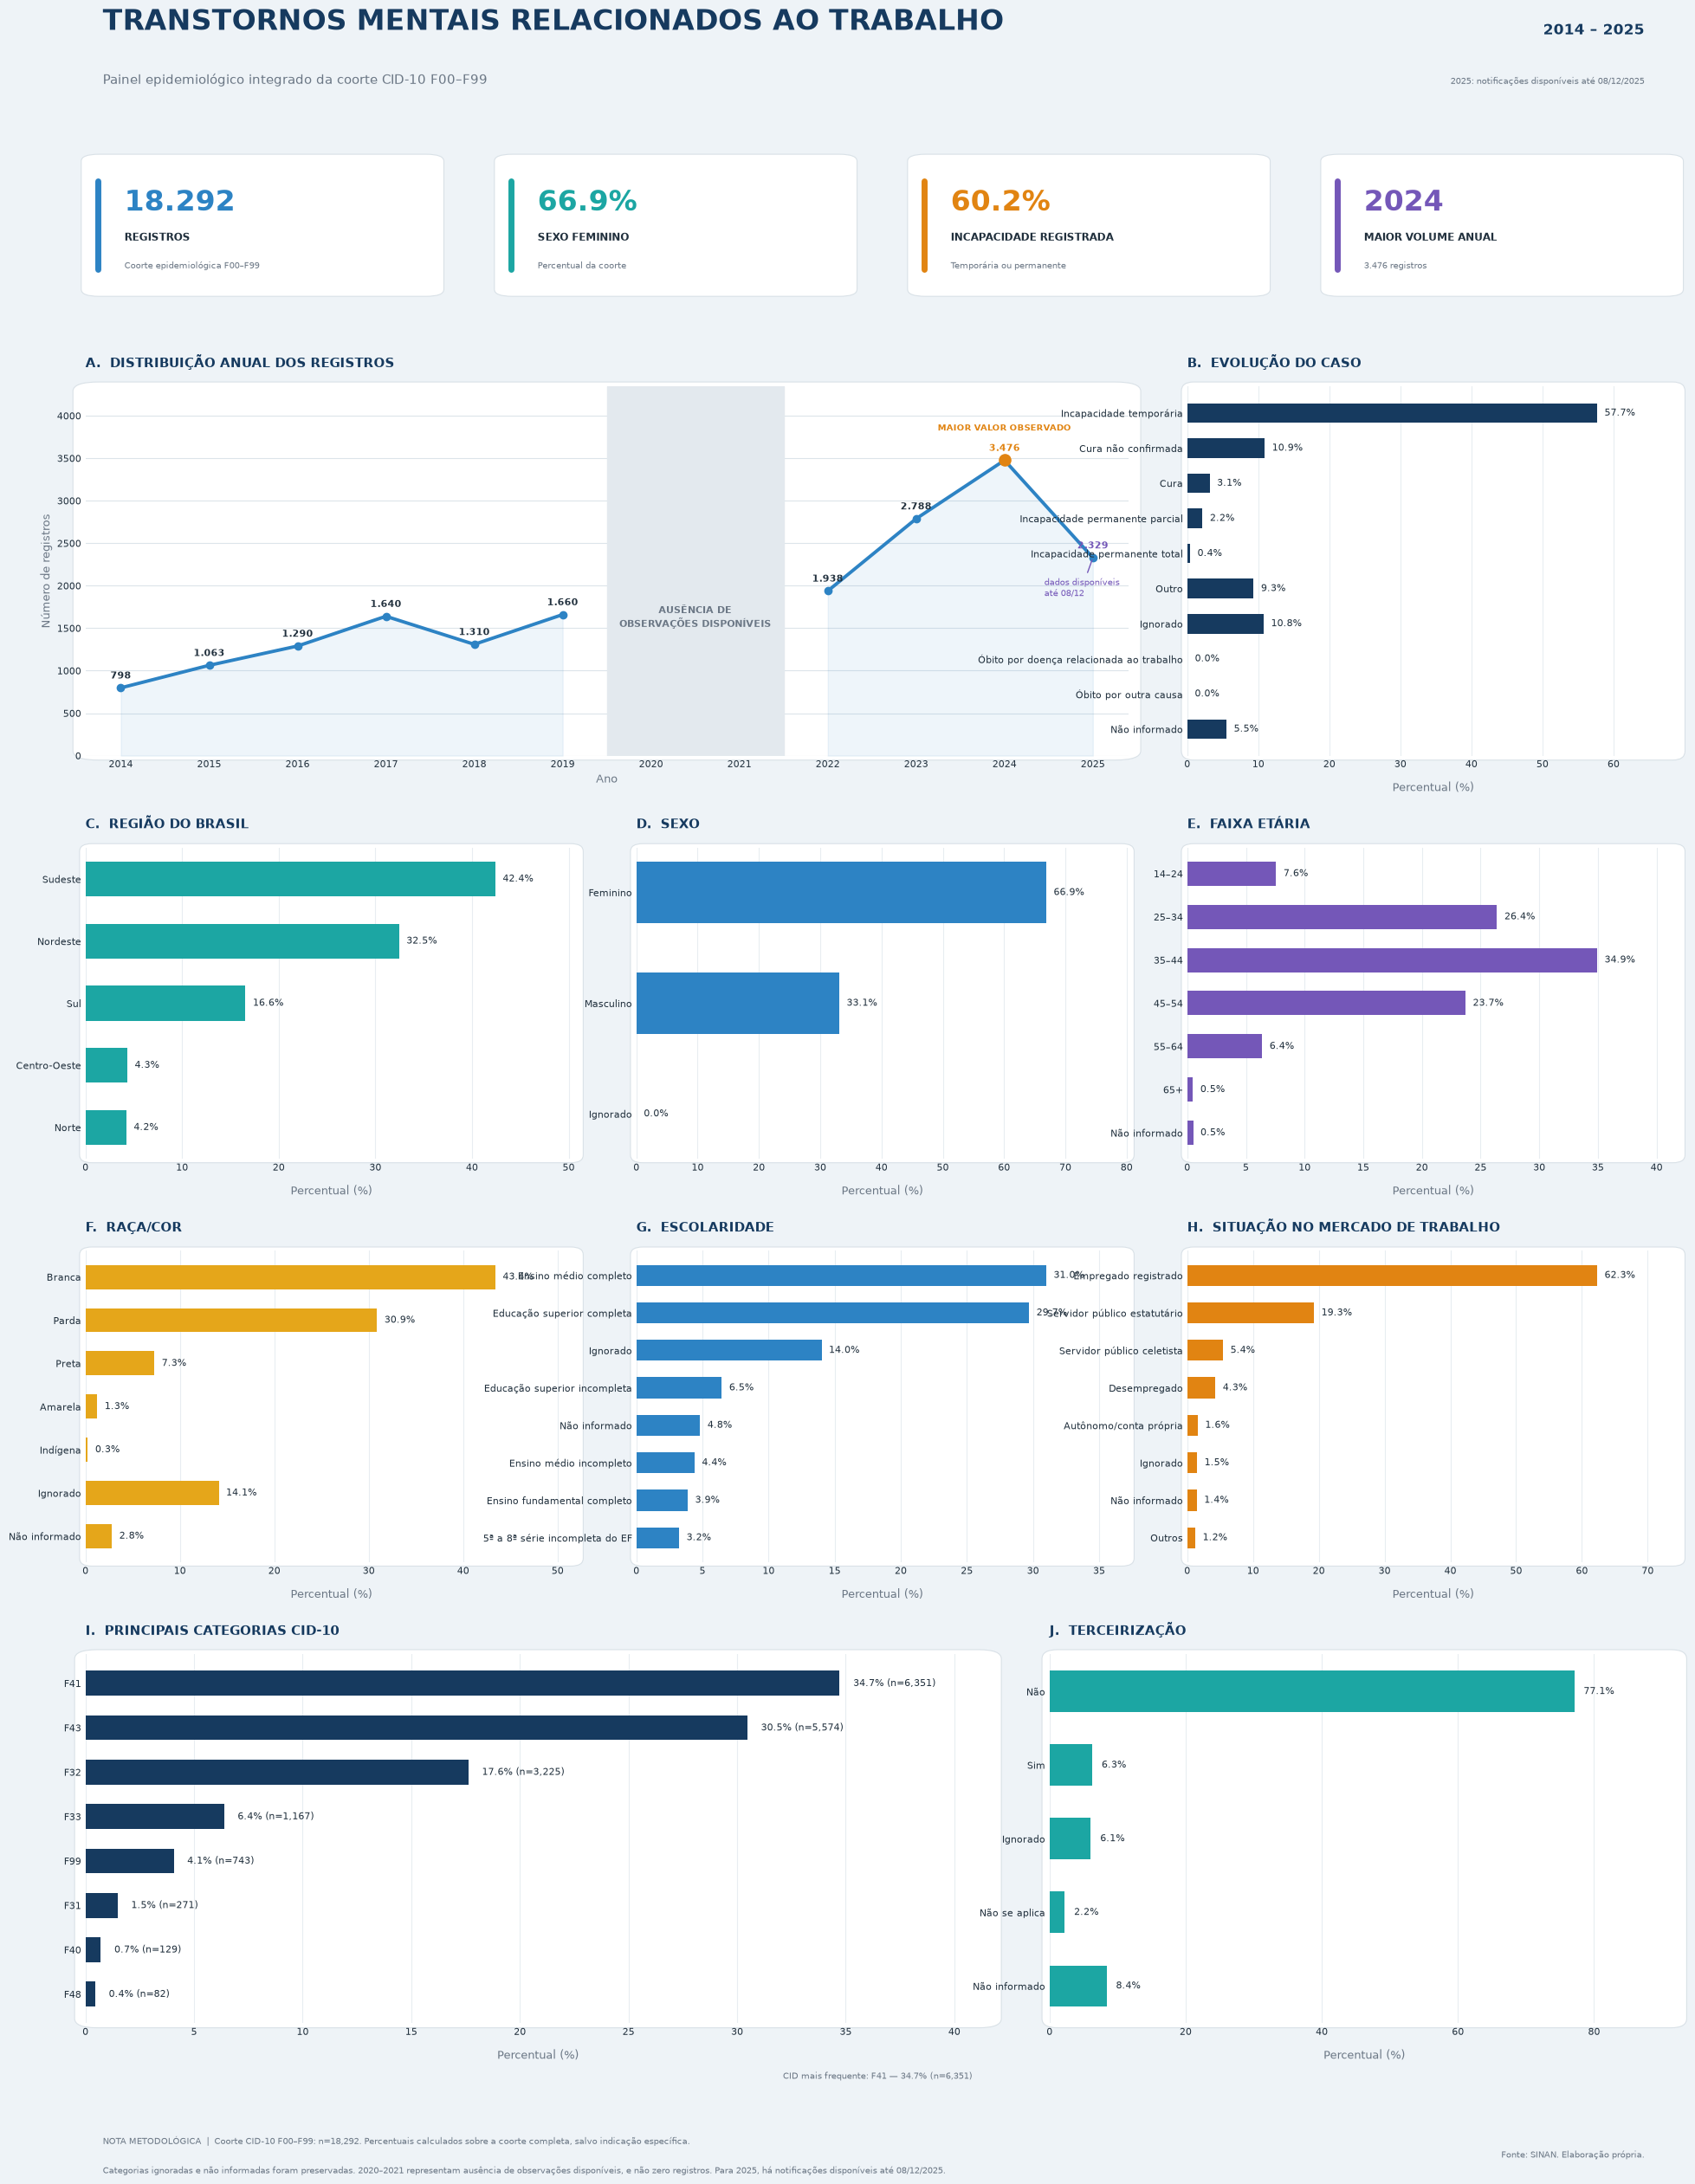


Dashboard salvo como:
dashboard_epidemiologico_premium.png


In [21]:
# ============================================================
# BLOCO 15 — DASHBOARD EPIDEMIOLÓGICO PREMIUM
# Transtornos mentais relacionados ao trabalho — SINAN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch

# ============================================================
# 0. BASE
# ============================================================

if 'df_epi' not in globals():
    raise NameError(
        "df_epi não foi encontrado. "
        "Execute primeiro os blocos de construção da coorte."
    )

base = df_epi.copy()
N_TOTAL = len(base)

print('=' * 70)
print('DASHBOARD EPIDEMIOLÓGICO PREMIUM')
print('=' * 70)
print(f'Coorte: {N_TOTAL:,} registros')


# ============================================================
# 1. PALETA VISUAL
# ============================================================

NAVY = '#163A5F'
BLUE = '#2D83C4'
TEAL = '#1CA6A3'
ORANGE = '#E18412'
PURPLE = '#7457B8'
GOLD = '#E5A61A'

BACKGROUND = '#EEF3F7'
CARD = '#FFFFFF'
PANEL = '#FFFFFF'

TEXT = '#21303D'
MUTED = '#6B7785'
GRID = '#DCE4EA'
BORDER = '#D9E1E7'

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8
})


# ============================================================
# 2. FUNÇÕES VISUAIS
# ============================================================

def add_card_background(ax, radius=0.025):
    """
    Cria painel branco com borda arredondada.
    """
    ax.set_facecolor('none')

    box = FancyBboxPatch(
        (0, 0),
        1,
        1,
        transform=ax.transAxes,
        boxstyle=f"round,pad=0.012,rounding_size={radius}",
        linewidth=0.8,
        edgecolor=BORDER,
        facecolor=CARD,
        zorder=-10,
        clip_on=False
    )

    ax.add_patch(box)


def clean_axis(ax):
    """
    Aparência limpa.
    """
    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(
        axis='both',
        length=0,
        colors=TEXT
    )

    ax.set_axisbelow(True)


def painel(ax, titulo, letra=None):
    """
    Cabeçalho de painel.
    """
    add_card_background(ax)
    clean_axis(ax)

    titulo_final = (
        f'{letra}.  {titulo}'
        if letra is not None
        else titulo
    )

    ax.set_title(
        titulo_final.upper(),
        loc='left',
        fontsize=11,
        fontweight='bold',
        color=NAVY,
        pad=16
    )


def tabela_pct(serie, ordem=None, top=None):

    s = (
        serie.astype('string')
        .fillna('Não informado')
    )

    tab = (
        s.value_counts(dropna=False)
        .rename_axis('categoria')
        .reset_index(name='N')
    )

    tab['PCT'] = (
        100 * tab['N'] / N_TOTAL
    )

    if ordem is not None:

        ordem_dict = {
            categoria: i
            for i, categoria in enumerate(ordem)
        }

        tab['_ordem'] = (
            tab['categoria']
            .map(ordem_dict)
            .fillna(999)
        )

        tab = (
            tab.sort_values('_ordem')
            .drop(columns='_ordem')
        )

    if top is not None:
        tab = tab.head(top)

    return tab.reset_index(drop=True)


def horizontal_bars(
    ax,
    tab,
    titulo,
    letra,
    cor,
    mostrar_n=False,
    xlabel='Percentual (%)'
):

    painel(ax, titulo, letra)

    dados = tab.copy()

    barras = ax.barh(
        dados['categoria'],
        dados['PCT'],
        color=cor,
        height=0.56
    )

    ax.invert_yaxis()

    ax.grid(
        axis='x',
        color=GRID,
        linewidth=0.8,
        alpha=0.65
    )

    ax.set_xlabel(
        xlabel,
        color=MUTED,
        labelpad=10
    )

    xmax = max(dados['PCT'].max(), 1) * 1.20
    ax.set_xlim(0, xmax)

    for barra, (_, row) in zip(
        barras,
        dados.iterrows()
    ):

        if mostrar_n:
            label = (
                f"{row['PCT']:.1f}% "
                f"(n={int(row['N']):,})"
            )
        else:
            label = f"{row['PCT']:.1f}%"

        ax.text(
            barra.get_width() + xmax * 0.015,
            barra.get_y() + barra.get_height() / 2,
            label,
            va='center',
            fontsize=8,
            color=TEXT
        )


def kpi_card(
    ax,
    valor,
    titulo,
    subtitulo,
    cor
):

    ax.axis('off')
    add_card_background(ax, radius=0.05)

    ax.plot(
        [0.035, 0.035],
        [0.18, 0.82],
        transform=ax.transAxes,
        color=cor,
        linewidth=5,
        solid_capstyle='round'
    )

    ax.text(
        0.11,
        0.66,
        valor,
        transform=ax.transAxes,
        fontsize=24,
        fontweight='bold',
        color=cor,
        va='center'
    )

    ax.text(
        0.11,
        0.39,
        titulo.upper(),
        transform=ax.transAxes,
        fontsize=8.5,
        fontweight='bold',
        color=TEXT
    )

    ax.text(
        0.11,
        0.19,
        subtitulo,
        transform=ax.transAxes,
        fontsize=7.3,
        color=MUTED
    )


# ============================================================
# 3. TABELAS PARA O DASHBOARD
# ============================================================

tab_sexo = tabela_pct(
    base['SEXO_LABEL'],
    ordem=[
        'Feminino',
        'Masculino',
        'Ignorado',
        'Não informado'
    ]
)

tab_raca = tabela_pct(
    base['RACA_LABEL'],
    ordem=[
        'Branca',
        'Parda',
        'Preta',
        'Amarela',
        'Indígena',
        'Ignorado',
        'Não informado'
    ]
)

tab_idade = tabela_pct(
    base['FAIXA_ETARIA']
    .astype('string')
    .fillna('Não informado'),
    ordem=[
        '14–24',
        '25–34',
        '35–44',
        '45–54',
        '55–64',
        '65+',
        'Não informado'
    ]
)

tab_escolaridade = (
    tabela_pct(
        base['ESCOLARIDADE_LABEL']
    )
    .sort_values(
        'N',
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

tab_sit = (
    tabela_pct(
        base['SIT_TRAB_LABEL']
    )
    .sort_values(
        'N',
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)

tab_terc = tabela_pct(
    base['TERCEIRIZA_LABEL'],
    ordem=[
        'Não',
        'Sim',
        'Ignorado',
        'Não se aplica',
        'Não informado'
    ]
)

ordem_evolucao = [
    'Incapacidade temporária',
    'Cura não confirmada',
    'Cura',
    'Incapacidade permanente parcial',
    'Incapacidade permanente total',
    'Outro',
    'Ignorado',
    'Óbito por doença relacionada ao trabalho',
    'Óbito por outra causa',
    'Não informado'
]

tab_evolucao = tabela_pct(
    base['EVOLUCAO_LABEL'],
    ordem=ordem_evolucao
)


# ============================================================
# 4. REGIÃO
# ============================================================

uf_raw = (
    base['SG_UF']
    .astype('string')
    .str.strip()
    .str.upper()
)

codigo_uf = {
    '11': 'RO',
    '12': 'AC',
    '13': 'AM',
    '14': 'RR',
    '15': 'PA',
    '16': 'AP',
    '17': 'TO',
    '21': 'MA',
    '22': 'PI',
    '23': 'CE',
    '24': 'RN',
    '25': 'PB',
    '26': 'PE',
    '27': 'AL',
    '28': 'SE',
    '29': 'BA',
    '31': 'MG',
    '32': 'ES',
    '33': 'RJ',
    '35': 'SP',
    '41': 'PR',
    '42': 'SC',
    '43': 'RS',
    '50': 'MS',
    '51': 'MT',
    '52': 'GO',
    '53': 'DF'
}

uf = uf_raw.map(
    lambda x: codigo_uf.get(x, x)
    if pd.notna(x)
    else pd.NA
)

mapa_regiao = {
    'AC': 'Norte',
    'AP': 'Norte',
    'AM': 'Norte',
    'PA': 'Norte',
    'RO': 'Norte',
    'RR': 'Norte',
    'TO': 'Norte',

    'AL': 'Nordeste',
    'BA': 'Nordeste',
    'CE': 'Nordeste',
    'MA': 'Nordeste',
    'PB': 'Nordeste',
    'PE': 'Nordeste',
    'PI': 'Nordeste',
    'RN': 'Nordeste',
    'SE': 'Nordeste',

    'DF': 'Centro-Oeste',
    'GO': 'Centro-Oeste',
    'MT': 'Centro-Oeste',
    'MS': 'Centro-Oeste',

    'ES': 'Sudeste',
    'MG': 'Sudeste',
    'RJ': 'Sudeste',
    'SP': 'Sudeste',

    'PR': 'Sul',
    'RS': 'Sul',
    'SC': 'Sul'
}

regiao = (
    uf
    .map(mapa_regiao)
    .fillna('Não informado')
)

tab_regiao = tabela_pct(
    regiao,
    ordem=[
        'Sudeste',
        'Nordeste',
        'Sul',
        'Centro-Oeste',
        'Norte',
        'Não informado'
    ]
)


# ============================================================
# 5. CID
# ============================================================

cid = (
    base['CATEGORIA_CID']
    .astype('string')
    .fillna('Não informado')
)

tab_cid = (
    cid.value_counts()
    .head(8)
    .rename_axis('categoria')
    .reset_index(name='N')
)

tab_cid['PCT'] = (
    100 * tab_cid['N'] / N_TOTAL
)

cid_principal = tab_cid.loc[0, 'categoria']
cid_principal_n = int(tab_cid.loc[0, 'N'])
cid_principal_pct = tab_cid.loc[0, 'PCT']


# ============================================================
# 6. SÉRIE TEMPORAL
# ============================================================

ano_num = pd.to_numeric(
    base['NU_ANO'],
    errors='coerce'
)

anos = list(range(2014, 2026))

serie = (
    base.assign(_ANO=ano_num)
    .groupby('_ANO')
    .size()
    .reindex(anos)
    .astype(float)
)

serie.loc[2020] = np.nan
serie.loc[2021] = np.nan

serie_pre = (
    serie.loc[2014:2019]
    .dropna()
)

serie_pos = (
    serie.loc[2022:2025]
    .dropna()
)


# ============================================================
# 7. KPIs
# ============================================================

pct_feminino = (
    100 *
    base['SEXO_LABEL'].eq('Feminino').sum()
    / N_TOTAL
)

incapacidade_mask = (
    base['EVOLUCAO_LABEL']
    .isin([
        'Incapacidade temporária',
        'Incapacidade permanente parcial',
        'Incapacidade permanente total'
    ])
)

n_incap = int(
    incapacidade_mask.sum()
)

pct_incap = (
    100 * n_incap / N_TOTAL
)

serie_hist = (
    serie.loc[:2024]
    .dropna()
)

ano_pico = int(
    serie_hist.idxmax()
)

n_pico = int(
    serie_hist.max()
)


# ============================================================
# 8. FIGURA
# ============================================================

fig = plt.figure(
    figsize=(20, 26),
    facecolor=BACKGROUND
)

gs = GridSpec(
    34,
    12,
    figure=fig,
    left=0.045,
    right=0.965,
    top=0.91,
    bottom=0.055,
    hspace=1.45,
    wspace=0.75
)


# ============================================================
# 9. CABEÇALHO
# ============================================================

fig.text(
    0.055,
    0.966,
    'TRANSTORNOS MENTAIS RELACIONADOS AO TRABALHO',
    fontsize=24,
    fontweight='bold',
    color=NAVY,
    ha='left'
)

fig.text(
    0.055,
    0.942,
    'Painel epidemiológico integrado da coorte CID-10 F00–F99',
    fontsize=11,
    color=MUTED,
    ha='left'
)

fig.text(
    0.945,
    0.964,
    '2014 – 2025',
    fontsize=12,
    fontweight='bold',
    color=NAVY,
    ha='right'
)

fig.text(
    0.945,
    0.942,
    '2025: notificações disponíveis até 08/12/2025',
    fontsize=7.5,
    color=MUTED,
    ha='right'
)


# ============================================================
# 10. KPI CARDS
# ============================================================

k1 = fig.add_subplot(gs[0:3, 0:3])
k2 = fig.add_subplot(gs[0:3, 3:6])
k3 = fig.add_subplot(gs[0:3, 6:9])
k4 = fig.add_subplot(gs[0:3, 9:12])

kpi_card(
    k1,
    f'{N_TOTAL:,}'.replace(',', '.'),
    'Registros',
    'Coorte epidemiológica F00–F99',
    BLUE
)

kpi_card(
    k2,
    f'{pct_feminino:.1f}%',
    'Sexo feminino',
    'Percentual da coorte',
    TEAL
)

kpi_card(
    k3,
    f'{pct_incap:.1f}%',
    'Incapacidade registrada',
    'Temporária ou permanente',
    ORANGE
)

kpi_card(
    k4,
    f'{ano_pico}',
    'Maior volume anual',
    f'{n_pico:,} registros'.replace(',', '.'),
    PURPLE
)


# ============================================================
# 11. PAINEL A — SÉRIE TEMPORAL
# ============================================================

ax1 = fig.add_subplot(
    gs[4:11, 0:8]
)

painel(
    ax1,
    'Distribuição anual dos registros',
    'A'
)

ax1.fill_between(
    serie_pre.index,
    serie_pre.values,
    0,
    color=BLUE,
    alpha=0.08
)

ax1.fill_between(
    serie_pos.index,
    serie_pos.values,
    0,
    color=BLUE,
    alpha=0.08
)

ax1.plot(
    serie_pre.index,
    serie_pre.values,
    color=BLUE,
    linewidth=2.8,
    marker='o',
    markersize=6
)

ax1.plot(
    serie_pos.index,
    serie_pos.values,
    color=BLUE,
    linewidth=2.8,
    marker='o',
    markersize=6
)

ax1.axvspan(
    2019.5,
    2021.5,
    color='#E3E9EE',
    alpha=1
)

ax1.text(
    2020.5,
    np.nanmax(serie.values) * 0.47,
    'AUSÊNCIA DE\nOBSERVAÇÕES DISPONÍVEIS',
    ha='center',
    va='center',
    fontsize=8,
    color=MUTED,
    fontweight='bold'
)

for ano, valor in serie.items():

    if pd.isna(valor):
        continue

    color = TEXT

    if ano == 2024:
        color = ORANGE

    elif ano == 2025:
        color = PURPLE

    ax1.text(
        ano,
        valor + 110,
        f'{int(valor):,}'.replace(',', '.'),
        ha='center',
        fontsize=8,
        fontweight='bold',
        color=color
    )

ax1.scatter(
    2024,
    serie.loc[2024],
    s=90,
    color=ORANGE,
    zorder=5
)

ax1.text(
    2024,
    serie.loc[2024] + 350,
    'MAIOR VALOR OBSERVADO',
    ha='center',
    fontsize=7.5,
    fontweight='bold',
    color=ORANGE
)

ax1.annotate(
    'dados disponíveis\naté 08/12',
    xy=(2025, serie.loc[2025]),
    xytext=(2024.45, serie.loc[2025] - 450),
    fontsize=7.5,
    color=PURPLE,
    arrowprops=dict(
        arrowstyle='-',
        linewidth=1,
        color=PURPLE
    )
)

ax1.set_xlim(
    2013.6,
    2025.4
)

ax1.set_ylim(
    0,
    np.nanmax(serie.values) * 1.25
)

ax1.set_xticks(
    range(2014, 2026)
)

ax1.set_xlabel(
    'Ano',
    color=MUTED
)

ax1.set_ylabel(
    'Número de registros',
    color=MUTED
)

ax1.grid(
    axis='y',
    color=GRID,
    linewidth=0.8
)


# ============================================================
# 12. PAINEL B — EVOLUÇÃO
# ============================================================

ax2 = fig.add_subplot(
    gs[4:11, 8:12]
)

horizontal_bars(
    ax2,
    tab_evolucao,
    'Evolução do caso',
    'B',
    NAVY
)


# ============================================================
# 13. LINHA 2
# ============================================================

ax3 = fig.add_subplot(
    gs[12:18, 0:4]
)

horizontal_bars(
    ax3,
    tab_regiao,
    'Região do Brasil',
    'C',
    TEAL
)


ax4 = fig.add_subplot(
    gs[12:18, 4:8]
)

horizontal_bars(
    ax4,
    tab_sexo,
    'Sexo',
    'D',
    BLUE
)


ax5 = fig.add_subplot(
    gs[12:18, 8:12]
)

horizontal_bars(
    ax5,
    tab_idade,
    'Faixa etária',
    'E',
    PURPLE
)


# ============================================================
# 14. LINHA 3
# ============================================================

ax6 = fig.add_subplot(
    gs[19:25, 0:4]
)

horizontal_bars(
    ax6,
    tab_raca,
    'Raça/cor',
    'F',
    GOLD
)


ax7 = fig.add_subplot(
    gs[19:25, 4:8]
)

horizontal_bars(
    ax7,
    tab_escolaridade,
    'Escolaridade',
    'G',
    BLUE
)


ax8 = fig.add_subplot(
    gs[19:25, 8:12]
)

horizontal_bars(
    ax8,
    tab_sit,
    'Situação no mercado de trabalho',
    'H',
    ORANGE
)


# ============================================================
# 15. LINHA 4
# ============================================================

ax9 = fig.add_subplot(
    gs[26:33, 0:7]
)

horizontal_bars(
    ax9,
    tab_cid,
    'Principais categorias CID-10',
    'I',
    NAVY,
    mostrar_n=True
)

ax9.text(
    0.98,
    -0.15,
    (
        f'CID mais frequente: {cid_principal} — '
        f'{cid_principal_pct:.1f}% '
        f'(n={cid_principal_n:,})'
    ),
    transform=ax9.transAxes,
    ha='right',
    fontsize=7.5,
    color=MUTED
)


ax10 = fig.add_subplot(
    gs[26:33, 7:12]
)

horizontal_bars(
    ax10,
    tab_terc,
    'Terceirização',
    'J',
    TEAL
)


# ============================================================
# 16. RODAPÉ
# ============================================================

fig.text(
    0.055,
    0.027,
    (
        'NOTA METODOLÓGICA  |  '
        f'Coorte CID-10 F00–F99: n={N_TOTAL:,}. '
        'Percentuais calculados sobre a coorte completa, '
        'salvo indicação específica.'
    ),
    fontsize=7.5,
    color=MUTED,
    ha='left'
)

fig.text(
    0.055,
    0.014,
    (
        'Categorias ignoradas e não informadas foram preservadas. '
        '2020–2021 representam ausência de observações disponíveis, '
        'e não zero registros. Para 2025, há notificações disponíveis '
        'até 08/12/2025.'
    ),
    fontsize=7.1,
    color=MUTED,
    ha='left'
)

fig.text(
    0.945,
    0.021,
    'Fonte: SINAN. Elaboração própria.',
    fontsize=7.2,
    color=MUTED,
    ha='right'
)


# ============================================================
# 17. SALVAR
# ============================================================

nome_arquivo = (
    'dashboard_epidemiologico_premium.png'
)

plt.savefig(
    nome_arquivo,
    dpi=350,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)

plt.show()

print('\nDashboard salvo como:')
print(nome_arquivo)

## BLOCO 16 — Construção do desfecho desfavorável

Após a caracterização epidemiológica da coorte, será construída a base
destinada à modelagem do desfecho clínico desfavorável.

O desfecho principal será definido a partir da variável `EVOLUCAO` do SINAN,
considerando como evolução favorável os registros de cura ou cura não
confirmada e como evolução desfavorável os registros de incapacidade
temporária, incapacidade permanente parcial, incapacidade permanente total
ou óbito por doença relacionada ao trabalho.

A variável resposta será definida da seguinte forma:

- **0 — Evolução favorável:** cura ou cura não confirmada;
- **1 — Evolução desfavorável:** incapacidade temporária, incapacidade
  permanente parcial, incapacidade permanente total ou óbito por doença
  relacionada ao trabalho.

Registros classificados como óbito por outra causa, outro, ignorado ou sem
informação de evolução serão excluídos da modelagem binária, por não
representarem diretamente nenhum dos dois grupos comparados.

A coorte epidemiológica original (`df_epi`) será preservada. A nova base,
denominada `df_modelo`, conterá somente os registros elegíveis para a análise
do desfecho.

In [22]:
# ============================================================
# BLOCO 16 — Construção do desfecho desfavorável
# ============================================================

print('=' * 70)
print('CONSTRUÇÃO DO DESFECHO DESFAVORÁVEL')
print('=' * 70)

# ------------------------------------------------------------
# 1. Preservar a coorte epidemiológica original
# ------------------------------------------------------------

df_modelo = df_epi.copy()


# ------------------------------------------------------------
# 2. Padronizar a variável EVOLUCAO
# ------------------------------------------------------------

evolucao_chave = (
    df_modelo['EVOLUCAO']
    .astype('string')
    .str.strip()
    .str.replace(r'\.0$', '', regex=True)
    .str.lstrip('0')
)


# ------------------------------------------------------------
# 3. Categorias elegíveis para o desfecho
#
# 1 = Cura
# 2 = Cura não confirmada
# 3 = Incapacidade temporária
# 4 = Incapacidade permanente parcial
# 5 = Incapacidade permanente total
# 6 = Óbito por doença relacionada ao trabalho
#
# Excluídos:
# 7 = Óbito por outra causa
# 8 = Outro
# 9 = Ignorado
# ausentes
# ------------------------------------------------------------

categorias_elegiveis = [
    '1', '2', '3', '4', '5', '6'
]

mascara_elegivel = (
    evolucao_chave
    .isin(categorias_elegiveis)
)

n_total = len(df_modelo)
n_elegiveis = int(mascara_elegivel.sum())
n_excluidos = n_total - n_elegiveis


# ------------------------------------------------------------
# 4. Criar base específica para modelagem
# ------------------------------------------------------------

df_modelo = (
    df_modelo
    .loc[mascara_elegivel]
    .copy()
)

evolucao_modelo = (
    evolucao_chave
    .loc[mascara_elegivel]
)


# ------------------------------------------------------------
# 5. Criar variável resposta
#
# 0 = Evolução favorável
#     1 Cura
#     2 Cura não confirmada
#
# 1 = Evolução desfavorável
#     3 Incapacidade temporária
#     4 Incapacidade permanente parcial
#     5 Incapacidade permanente total
#     6 Óbito por doença relacionada ao trabalho
# ------------------------------------------------------------

mapa_target = {
    '1': 0,
    '2': 0,
    '3': 1,
    '4': 1,
    '5': 1,
    '6': 1
}

df_modelo['TARGET_DESFECHO_DESFAVORAVEL'] = (
    evolucao_modelo
    .map(mapa_target)
    .astype('int8')
)


# ------------------------------------------------------------
# 6. Criar rótulo interpretável
# ------------------------------------------------------------

df_modelo['DESFECHO_LABEL'] = (
    df_modelo['TARGET_DESFECHO_DESFAVORAVEL']
    .map({
        0: 'Evolução favorável',
        1: 'Evolução desfavorável'
    })
)


# ------------------------------------------------------------
# 7. Detalhamento das categorias originais
# ------------------------------------------------------------

mapa_detalhado = {
    '1': 'Cura',
    '2': 'Cura não confirmada',
    '3': 'Incapacidade temporária',
    '4': 'Incapacidade permanente parcial',
    '5': 'Incapacidade permanente total',
    '6': 'Óbito por doença relacionada ao trabalho'
}

df_modelo['EVOLUCAO_MODELO_LABEL'] = (
    evolucao_modelo
    .map(mapa_detalhado)
)


# ------------------------------------------------------------
# 8. Validações
# ------------------------------------------------------------

assert (
    df_modelo['TARGET_DESFECHO_DESFAVORAVEL']
    .isin([0, 1])
    .all()
)

assert (
    df_modelo['TARGET_DESFECHO_DESFAVORAVEL']
    .isna()
    .sum()
    == 0
)

assert (
    df_modelo['EVOLUCAO_MODELO_LABEL']
    .notna()
    .all()
)


# ------------------------------------------------------------
# 9. Distribuição do desfecho binário
# ------------------------------------------------------------

distribuicao_target = (
    df_modelo['DESFECHO_LABEL']
    .value_counts()
    .rename_axis('DESFECHO')
    .reset_index(name='N')
)

distribuicao_target['PERCENTUAL'] = (
    100 *
    distribuicao_target['N'] /
    len(df_modelo)
)


# ------------------------------------------------------------
# 10. Distribuição detalhada das evoluções elegíveis
# ------------------------------------------------------------

distribuicao_evolucao = (
    df_modelo['EVOLUCAO_MODELO_LABEL']
    .value_counts()
    .rename_axis('EVOLUCAO')
    .reset_index(name='N')
)

distribuicao_evolucao['PERCENTUAL'] = (
    100 *
    distribuicao_evolucao['N'] /
    len(df_modelo)
)


# ------------------------------------------------------------
# 11. Contagem específica de óbito relacionado ao trabalho
# ------------------------------------------------------------

n_obitos_trabalho = int(
    (
        evolucao_modelo == '6'
    ).sum()
)

pct_obitos_trabalho = (
    100 *
    n_obitos_trabalho /
    len(df_modelo)
)


# ------------------------------------------------------------
# 12. Resultado
# ------------------------------------------------------------

print(f'\nCoorte epidemiológica original: {n_total:,}')
print(f'Registros elegíveis para modelagem: {n_elegiveis:,}')
print(f'Registros excluídos: {n_excluidos:,}')

print('\nDistribuição do desfecho binário:')

display(
    distribuicao_target.style
    .format({
        'N': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
    .hide(axis='index')
)

print('\nDistribuição detalhada das evoluções elegíveis:')

display(
    distribuicao_evolucao.style
    .format({
        'N': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
    .hide(axis='index')
)

print('\nÓbitos por doença relacionada ao trabalho:')
print(
    f'n = {n_obitos_trabalho:,} '
    f'({pct_obitos_trabalho:.4f}% da base de modelagem)'
)

print('\n✓ df_epi preservado.')
print('✓ df_modelo criada.')
print('✓ TARGET_DESFECHO_DESFAVORAVEL criada.')

CONSTRUÇÃO DO DESFECHO DESFAVORÁVEL

Coorte epidemiológica original: 18,292
Registros elegíveis para modelagem: 13,598
Registros excluídos: 4,694

Distribuição do desfecho binário:


DESFECHO,N,PERCENTUAL
Evolução desfavorável,"11,027",81.09%
Evolução favorável,"2,571",18.91%



Distribuição detalhada das evoluções elegíveis:


EVOLUCAO,N,PERCENTUAL
Incapacidade temporária,"10,553",77.61%
Cura não confirmada,"1,995",14.67%
Cura,576,4.24%
Incapacidade permanente parcial,394,2.90%
Incapacidade permanente total,73,0.54%
Óbito por doença relacionada ao trabalho,7,0.05%



Óbitos por doença relacionada ao trabalho:
n = 7 (0.0515% da base de modelagem)

✓ df_epi preservado.
✓ df_modelo criada.
✓ TARGET_DESFECHO_DESFAVORAVEL criada.


Dos 13.598 registros com evolução classificável, temos 11.027 (81,09%) de evolução desfavorável e 2.571 (18,91%) favorável. E dentro do grupo desfavorável há forte predominância de incapacidade temporária: 10.553 casos; os óbitos relacionados ao trabalho são apenas 7.

Isso significa duas coisas: o desfecho composto pode ser mantido, mas não faz sentido modelar mortalidade isoladamente com apenas sete eventos; além disso, temos um target desbalanceado (81% × 19%), então mais adiante acurácia sozinha será uma métrica ruim. Vamos precisar olhar AUC-ROC, sensibilidade, especificidade, precisão, F1 e matriz de confusão, e provavelmente PR-AUC também;

## BLOCO 17 — Auditoria das variáveis candidatas à modelagem

Antes do treinamento dos modelos preditivos, será realizada uma auditoria das
variáveis disponíveis na base analítica.

O objetivo é distinguir características potencialmente disponíveis para
explicar ou predizer a evolução do caso de informações que representam o
próprio desfecho, consequências posteriores ao adoecimento ou etapas do
atendimento e encerramento da notificação.

Essa distinção é necessária para reduzir o risco de **vazamento de informação
(data leakage)**, situação em que o modelo utiliza informações que não estariam
disponíveis no momento em que a predição deveria ser realizada. A presença
dessas variáveis pode produzir métricas artificialmente elevadas e reduzir a
validade do modelo.

Nesta etapa não será realizado treinamento. Para cada variável candidata serão
avaliados:

- disponibilidade na base de modelagem;
- tipo de informação;
- percentual de dados ausentes;
- número de categorias ou valores distintos;
- relação temporal ou conceitual com o desfecho;
- potencial risco de vazamento de informação.

A variável `EVOLUCAO` e suas derivações serão excluídas dos preditores por
definirem diretamente a variável resposta.

Variáveis administrativas, identificadores e datas relacionadas ao fluxo de
notificação também não serão utilizadas como preditores.

A seleção definitiva será realizada antes da construção da matriz de
modelagem, preservando apenas características epidemiologicamente
interpretáveis e metodologicamente compatíveis com o objetivo preditivo.

In [23]:
# ============================================================
# BLOCO 17 — Auditoria das variáveis candidatas à modelagem
# ============================================================

import pandas as pd
import numpy as np

print('=' * 78)
print('AUDITORIA DAS VARIÁVEIS CANDIDATAS À MODELAGEM')
print('=' * 78)

# ------------------------------------------------------------
# 1. Verificação da base
# ------------------------------------------------------------

if 'df_modelo' not in globals():
    raise NameError(
        "df_modelo não foi encontrada. "
        "Execute primeiro o Bloco 16."
    )

TARGET = 'TARGET_DESFECHO_DESFAVORAVEL'

if TARGET not in df_modelo.columns:
    raise KeyError(
        f'A variável {TARGET} não foi encontrada.'
    )

print(f'\nRegistros da base de modelagem: {len(df_modelo):,}')
print(f'Variáveis disponíveis: {df_modelo.shape[1]:,}')


# ============================================================
# 2. CLASSIFICAÇÃO CONCEITUAL DAS VARIÁVEIS
# ============================================================

# ------------------------------------------------------------
# A — Variáveis candidatas principais
# ------------------------------------------------------------

candidatas_principais = {

    'IDADE_ANOS':
        'Característica sociodemográfica',

    'CS_SEXO':
        'Característica sociodemográfica',

    'CS_RACA':
        'Característica sociodemográfica',

    'CS_ESCOL_N':
        'Característica sociodemográfica',

    'SG_UF':
        'Localização geográfica',

    'ID_OCUPA_N':
        'Característica ocupacional',

    'CNAE':
        'Atividade econômica',

    'SIT_TRAB':
        'Situação no mercado de trabalho',

    'TERCEIRIZA':
        'Vínculo/organização do trabalho',

    'DIAG_ESP':
        'Diagnóstico CID-10',

    'ALCOOL':
        'Característica individual',

    'DROGAS':
        'Característica individual',

    'PSICO_FARM':
        'Característica clínica',

    'FUMA':
        'Característica individual'
}


# ------------------------------------------------------------
# B — Variáveis que exigem cautela temporal/conceitual
# ------------------------------------------------------------

candidatas_cautela = {

    'TRAB_DOE':
        'Relação atribuída entre trabalho e doença',

    'CAPES':
        'Informação assistencial',

    'AFAST_TRAB':
        'Possível consequência do agravo',

    'CAT':
        'Informação ocupacional potencialmente posterior',

    'REGIME':
        'Regime de tratamento — possível informação pós-desfecho'
}


# ------------------------------------------------------------
# C — Variáveis excluídas por definição do target/leakage
# ------------------------------------------------------------

excluir_target = {

    'EVOLUCAO':
        'Variável original utilizada para definir o desfecho',

    'EVOLUCAO_LABEL':
        'Rótulo derivado da variável de evolução',

    'EVOLUCAO_MODELO_LABEL':
        'Rótulo derivado da evolução',

    'DESFECHO_LABEL':
        'Rótulo derivado do target',

    'TARGET_DESFECHO_DESFAVORAVEL':
        'Variável resposta'
}


# ------------------------------------------------------------
# D — Variáveis temporais
# ------------------------------------------------------------

variaveis_temporais = {

    'NU_ANO':
        'Ano da notificação — manter para avaliação temporal',

    'DT_NOTIFIC':
        'Data da notificação — não usar diretamente como preditor'
}


# ============================================================
# 3. FUNÇÃO DE AUDITORIA
# ============================================================

def auditar_variavel(
    coluna,
    grupo,
    justificativa,
    decisao
):

    if coluna not in df_modelo.columns:

        return {
            'VARIAVEL': coluna,
            'GRUPO': grupo,
            'DISPONIVEL': 'Não',
            'N_AUSENTES': np.nan,
            'PCT_AUSENTES': np.nan,
            'N_UNICOS': np.nan,
            'DECISAO_PRELIMINAR': decisao,
            'JUSTIFICATIVA': justificativa
        }

    serie = df_modelo[coluna]

    n_ausentes = int(
        serie.isna().sum()
    )

    pct_ausentes = (
        100 *
        n_ausentes /
        len(df_modelo)
    )

    n_unicos = int(
        serie.nunique(dropna=True)
    )

    return {
        'VARIAVEL': coluna,
        'GRUPO': grupo,
        'DISPONIVEL': 'Sim',
        'N_AUSENTES': n_ausentes,
        'PCT_AUSENTES': pct_ausentes,
        'N_UNICOS': n_unicos,
        'DECISAO_PRELIMINAR': decisao,
        'JUSTIFICATIVA': justificativa
    }


# ============================================================
# 4. CONSTRUIR TABELA DE AUDITORIA
# ============================================================

resultado = []


# ------------------------------------------------------------
# Candidatas principais
# ------------------------------------------------------------

for coluna, justificativa in candidatas_principais.items():

    resultado.append(
        auditar_variavel(
            coluna=coluna,
            grupo='Candidata principal',
            justificativa=justificativa,
            decisao='Candidata'
        )
    )


# ------------------------------------------------------------
# Candidatas com cautela
# ------------------------------------------------------------

for coluna, justificativa in candidatas_cautela.items():

    resultado.append(
        auditar_variavel(
            coluna=coluna,
            grupo='Avaliar leakage',
            justificativa=justificativa,
            decisao='Revisar'
        )
    )


# ------------------------------------------------------------
# Target e derivações
# ------------------------------------------------------------

for coluna, justificativa in excluir_target.items():

    resultado.append(
        auditar_variavel(
            coluna=coluna,
            grupo='Target / derivação',
            justificativa=justificativa,
            decisao='Excluir'
        )
    )


# ------------------------------------------------------------
# Variáveis temporais
# ------------------------------------------------------------

for coluna, justificativa in variaveis_temporais.items():

    decisao = (
        'Estratificação temporal'
        if coluna == 'NU_ANO'
        else 'Excluir como preditor'
    )

    resultado.append(
        auditar_variavel(
            coluna=coluna,
            grupo='Temporal',
            justificativa=justificativa,
            decisao=decisao
        )
    )


auditoria_modelo = pd.DataFrame(resultado)


# ============================================================
# 5. ORDENAÇÃO
# ============================================================

ordem_grupos = {
    'Candidata principal': 1,
    'Avaliar leakage': 2,
    'Temporal': 3,
    'Target / derivação': 4
}

auditoria_modelo['_ORDEM'] = (
    auditoria_modelo['GRUPO']
    .map(ordem_grupos)
)

auditoria_modelo = (
    auditoria_modelo
    .sort_values(
        ['_ORDEM', 'PCT_AUSENTES'],
        ascending=[True, True],
        na_position='last'
    )
    .drop(columns='_ORDEM')
    .reset_index(drop=True)
)


# ============================================================
# 6. EXIBIR AUDITORIA
# ============================================================

display(
    auditoria_modelo.style
    .format({
        'N_AUSENTES': lambda x:
            '' if pd.isna(x)
            else f'{x:,.0f}',

        'PCT_AUSENTES': lambda x:
            '' if pd.isna(x)
            else f'{x:.2f}%',

        'N_UNICOS': lambda x:
            '' if pd.isna(x)
            else f'{x:,.0f}'
    })
    .hide(axis='index')
)


# ============================================================
# 7. RESUMO
# ============================================================

print('\n' + '=' * 78)
print('RESUMO DA AUDITORIA')
print('=' * 78)

print(
    '\nCandidatas principais:',
    sum(
        auditoria_modelo[
            'DECISAO_PRELIMINAR'
        ].eq('Candidata')
    )
)

print(
    'Variáveis para revisão de leakage:',
    sum(
        auditoria_modelo[
            'DECISAO_PRELIMINAR'
        ].eq('Revisar')
    )
)

print(
    'Variáveis diretamente excluídas:',
    sum(
        auditoria_modelo[
            'DECISAO_PRELIMINAR'
        ].eq('Excluir')
    )
)

print(
    '\n✓ Nenhuma variável foi removida neste bloco.'
)

print(
    '✓ Nenhum modelo foi treinado.'
)

print(
    '✓ auditoria_modelo criada para orientar '
    'a seleção final dos preditores.'
)

AUDITORIA DAS VARIÁVEIS CANDIDATAS À MODELAGEM

Registros da base de modelagem: 13,598
Variáveis disponíveis: 44


VARIAVEL,GRUPO,DISPONIVEL,N_AUSENTES,PCT_AUSENTES,N_UNICOS,DECISAO_PRELIMINAR,JUSTIFICATIVA
CS_SEXO,Candidata principal,Sim,0,0.00%,3,Candidata,Característica sociodemográfica
SG_UF,Candidata principal,Sim,0,0.00%,26,Candidata,Localização geográfica
DIAG_ESP,Candidata principal,Sim,0,0.00%,178,Candidata,Diagnóstico CID-10
ID_OCUPA_N,Candidata principal,Sim,48,0.35%,923,Candidata,Característica ocupacional
IDADE_ANOS,Candidata principal,Sim,64,0.47%,63,Candidata,Característica sociodemográfica
SIT_TRAB,Candidata principal,Sim,146,1.07%,13,Candidata,Situação no mercado de trabalho
CS_RACA,Candidata principal,Sim,374,2.75%,6,Candidata,Característica sociodemográfica
CS_ESCOL_N,Candidata principal,Sim,563,4.14%,11,Candidata,Característica sociodemográfica
FUMA,Candidata principal,Sim,887,6.52%,4,Candidata,Característica individual
TERCEIRIZA,Candidata principal,Sim,954,7.02%,4,Candidata,Vínculo/organização do trabalho



RESUMO DA AUDITORIA

Candidatas principais: 14
Variáveis para revisão de leakage: 5
Variáveis diretamente excluídas: 5

✓ Nenhuma variável foi removida neste bloco.
✓ Nenhum modelo foi treinado.
✓ auditoria_modelo criada para orientar a seleção final dos preditores.


### Conclusão preliminar da auditoria das variáveis preditoras

A auditoria das variáveis disponíveis na base de modelagem mostrou que a seleção
dos preditores não deve ser realizada exclusivamente com base na disponibilidade
dos campos ou no percentual de dados ausentes. Também é necessário considerar
a natureza da informação, sua relação temporal com a evolução do caso, o risco
de vazamento de informação (*data leakage*) e a dimensionalidade das variáveis
categóricas.

As características sociodemográficas apresentaram condições favoráveis para
utilização no modelo principal. Sexo e unidade federativa não apresentaram
valores ausentes, enquanto idade, raça/cor e escolaridade apresentaram proporções
relativamente pequenas de ausência. Dessa forma, idade, sexo, raça/cor,
escolaridade e localização geográfica serão inicialmente mantidos como
preditores.

Entre as características ocupacionais, a situação no mercado de trabalho e a
terceirização também foram consideradas candidatas ao modelo principal. Por
outro lado, ocupação (`ID_OCUPA_N`) e atividade econômica (`CNAE`) exigem
tratamento adicional antes da modelagem. A variável de ocupação apresentou
elevado número de categorias distintas, enquanto o CNAE combinou alta
cardinalidade com proporção expressiva de dados ausentes. A utilização direta
desses códigos poderia produzir uma matriz excessivamente esparsa, categorias
com baixa frequência e maior risco de sobreajuste. Portanto, essas informações
serão agrupadas em categorias analiticamente mais estáveis antes de sua eventual
incorporação ao modelo.

O diagnóstico (`DIAG_ESP`) também não será utilizado diretamente em sua forma
original, devido ao elevado número de categorias. Como alternativa, serão
utilizadas representações agregadas da CID-10, preservando informação clínica
relevante com menor dimensionalidade.

As variáveis relacionadas ao consumo de álcool, uso de drogas e tabagismo
apresentaram níveis de ausência considerados administráveis para esta etapa e
permanecerão como candidatas. A informação sobre uso de psicofármacos será
avaliada com maior cautela, devido à possibilidade de refletir características
clínicas ou terapêuticas já relacionadas à gravidade do quadro.

Cinco variáveis foram identificadas como particularmente sensíveis ao risco de
vazamento de informação: relação trabalho-doença (`TRAB_DOE`), atendimento em
CAPS (`CAPES`), afastamento do trabalho (`AFAST_TRAB`), Comunicação de Acidente
de Trabalho (`CAT`) e regime de tratamento (`REGIME`). Essas informações podem
representar decisões assistenciais, administrativas ou consequências ocorridas
durante ou após o desenvolvimento do agravo. Por esse motivo, não serão
utilizadas no modelo preditivo principal. Sua eventual utilização deverá ser
restrita a análises complementares ou de sensibilidade, caso exista justificativa
temporal e epidemiológica adequada.

A data de notificação (`DT_NOTIFIC`) também não será utilizada diretamente como
preditor. O ano da notificação (`NU_ANO`) será preservado principalmente para
controle e avaliação temporal dos modelos, permitindo investigar possíveis
mudanças no padrão dos registros ao longo do período estudado.

Por definição, `EVOLUCAO`, seus rótulos derivados e
`TARGET_DESFECHO_DESFAVORAVEL` serão completamente excluídos da matriz de
preditores, uma vez que constituem a própria informação utilizada na definição
da variável resposta.

Assim, a estratégia preliminar para o modelo principal será baseada em um
conjunto parcimonioso de características sociodemográficas, ocupacionais,
clínicas e comportamentais potencialmente disponíveis independentemente do
desfecho. Variáveis de alta cardinalidade serão previamente agrupadas e
informações com potencial de *data leakage* serão excluídas do modelo principal.

Essa estratégia busca evitar desempenho artificialmente elevado e favorecer
modelos com maior interpretabilidade, validade epidemiológica e capacidade de
generalização. A próxima etapa consistirá na preparação definitiva dos
preditores, incluindo o agrupamento das categorias CID-10, ocupação e atividade
econômica, antes da separação das amostras de treinamento e teste.

In [24]:
# ============================================================
# BLOCO 18 — Diagnóstico dos preditores de alta cardinalidade
# ============================================================

import pandas as pd

print('=' * 78)
print('DIAGNÓSTICO DOS PREDITORES DE ALTA CARDINALIDADE')
print('=' * 78)

if 'df_modelo' not in globals():
    raise NameError(
        "df_modelo não foi encontrada. Execute primeiro o Bloco 16."
    )


# ------------------------------------------------------------
# Função para auditoria da distribuição
# ------------------------------------------------------------

def diagnosticar_categorica(df, coluna, top_n=20):

    if coluna not in df.columns:
        print(f'\n⚠ {coluna} não encontrada.')
        return None

    serie = (
        df[coluna]
        .astype('string')
        .str.strip()
    )

    n_total = len(serie)
    n_ausentes = int(serie.isna().sum())
    n_unicos = int(serie.nunique(dropna=True))

    freq = (
        serie
        .value_counts(dropna=False)
        .rename_axis(coluna)
        .reset_index(name='N')
    )

    freq['PERCENTUAL'] = (
        100 * freq['N'] / n_total
    )

    # Categorias muito raras
    n_menor_10 = int(
        (freq.loc[freq[coluna].notna(), 'N'] < 10).sum()
    )

    n_menor_30 = int(
        (freq.loc[freq[coluna].notna(), 'N'] < 30).sum()
    )

    print('\n' + '-' * 78)
    print(coluna)
    print('-' * 78)

    print(f'Registros: {n_total:,}')
    print(f'Valores distintos: {n_unicos:,}')
    print(
        f'Ausentes: {n_ausentes:,} '
        f'({100*n_ausentes/n_total:.2f}%)'
    )
    print(f'Categorias com menos de 10 registros: {n_menor_10:,}')
    print(f'Categorias com menos de 30 registros: {n_menor_30:,}')

    print(f'\nTop {top_n} categorias:')

    display(
        freq.head(top_n).style
        .format({
            'N': '{:,.0f}',
            'PERCENTUAL': '{:.2f}%'
        })
        .hide(axis='index')
    )

    return freq


# ============================================================
# 1. CID-10
# ============================================================

freq_cid = diagnosticar_categorica(
    df_modelo,
    'DIAG_ESP',
    top_n=20
)


# ============================================================
# 2. OCUPAÇÃO
# ============================================================

freq_ocupacao = diagnosticar_categorica(
    df_modelo,
    'ID_OCUPA_N',
    top_n=20
)


# ============================================================
# 3. CNAE
# ============================================================

freq_cnae = diagnosticar_categorica(
    df_modelo,
    'CNAE',
    top_n=20
)


# ============================================================
# 4. CID já agregado
# ============================================================

if 'GRUPO_CID' in df_modelo.columns:

    print('\n' + '=' * 78)
    print('DISTRIBUIÇÃO POR GRUPO CID-10')
    print('=' * 78)

    grupo_cid_modelo = (
        df_modelo['GRUPO_CID']
        .value_counts(dropna=False)
        .rename_axis('GRUPO_CID')
        .reset_index(name='N')
    )

    grupo_cid_modelo['PERCENTUAL'] = (
        100 *
        grupo_cid_modelo['N'] /
        len(df_modelo)
    )

    display(
        grupo_cid_modelo.style
        .format({
            'N': '{:,.0f}',
            'PERCENTUAL': '{:.2f}%'
        })
        .hide(axis='index')
    )


# ============================================================
# 5. Categoria CID de três caracteres
# ============================================================

if 'CATEGORIA_CID' in df_modelo.columns:

    print('\n' + '=' * 78)
    print('DISTRIBUIÇÃO POR CATEGORIA CID-10')
    print('=' * 78)

    categoria_cid_modelo = (
        df_modelo['CATEGORIA_CID']
        .value_counts(dropna=False)
        .rename_axis('CATEGORIA_CID')
        .reset_index(name='N')
    )

    categoria_cid_modelo['PERCENTUAL'] = (
        100 *
        categoria_cid_modelo['N'] /
        len(df_modelo)
    )

    display(
        categoria_cid_modelo.head(30).style
        .format({
            'N': '{:,.0f}',
            'PERCENTUAL': '{:.2f}%'
        })
        .hide(axis='index')
    )


print('\n✓ Nenhum agrupamento foi realizado neste bloco.')
print('✓ df_modelo permanece inalterada.')
print('✓ Distribuições preparadas para definição dos agrupamentos.')

DIAGNÓSTICO DOS PREDITORES DE ALTA CARDINALIDADE

------------------------------------------------------------------------------
DIAG_ESP
------------------------------------------------------------------------------
Registros: 13,598
Valores distintos: 178
Ausentes: 0 (0.00%)
Categorias com menos de 10 registros: 125
Categorias com menos de 30 registros: 151

Top 20 categorias:


DIAG_ESP,N,PERCENTUAL
F431,"1,578",11.60%
F41,"1,321",9.71%
F411,"1,290",9.49%
F412,"1,278",9.40%
F432,831,6.11%
F32,781,5.74%
F43,741,5.45%
F430,735,5.41%
F322,719,5.29%
F410,657,4.83%



------------------------------------------------------------------------------
ID_OCUPA_N
------------------------------------------------------------------------------
Registros: 13,598
Valores distintos: 923
Ausentes: 48 (0.35%)
Categorias com menos de 10 registros: 729
Categorias com menos de 30 registros: 846

Top 20 categorias:


ID_OCUPA_N,N,PERCENTUAL
322205,546,4.02%
253215,456,3.35%
411010,423,3.11%
782410,410,3.02%
231205,410,3.02%
223505,369,2.71%
515105,366,2.69%
514210,337,2.48%
141710,336,2.47%
421125,326,2.40%



------------------------------------------------------------------------------
CNAE
------------------------------------------------------------------------------
Registros: 13,598
Valores distintos: 645
Ausentes: 5,468 (40.21%)
Categorias com menos de 10 registros: 508
Categorias com menos de 30 registros: 602

Top 20 categorias:


...


DISTRIBUIÇÃO POR GRUPO CID-10


GRUPO_CID,N,PERCENTUAL
F4,"9,145",67.25%
F3,"3,609",26.54%
F9,465,3.42%
F2,151,1.11%
F0,86,0.63%
F1,65,0.48%
F6,44,0.32%
F5,20,0.15%
F7,7,0.05%
F8,6,0.04%



DISTRIBUIÇÃO POR CATEGORIA CID-10


CATEGORIA_CID,N,PERCENTUAL
F41,"4,749",34.92%
F43,"4,155",30.56%
F32,"2,429",17.86%
F33,939,6.91%
F99,450,3.31%
F31,196,1.44%
F40,96,0.71%
F06,62,0.46%
F42,55,0.40%
F20,55,0.40%



✓ Nenhum agrupamento foi realizado neste bloco.
✓ df_modelo permanece inalterada.
✓ Distribuições preparadas para definição dos agrupamentos.


## BLOCO 19 — Agrupamento analítico do diagnóstico e da ocupação

A análise de cardinalidade demonstrou elevada fragmentação das variáveis
diagnóstica e ocupacional quando consideradas em seus códigos originais.

Para o diagnóstico, embora tenham sido identificadas numerosas categorias
CID-10 específicas, a distribuição mostrou forte concentração nos capítulos
relacionados aos transtornos neuróticos, relacionados ao estresse e
somatoformes (grupo F4) e aos transtornos do humor (grupo F3). Na base
elegível para modelagem, esses dois grupos correspondem conjuntamente à
maior parte dos registros.

Dessa forma, o diagnóstico será representado inicialmente pelo agrupamento
CID-10 em nível de grupo (`F0` a `F9`). Essa estratégia reduz a
dimensionalidade sem utilizar critérios definidos a partir da associação
entre diagnóstico e desfecho.

A ocupação também apresentou elevada cardinalidade, com centenas de códigos
distintos e baixa concentração em ocupações individuais. Em vez da utilização
direta dos códigos específicos, as ocupações serão agregadas segundo os
grandes grupos da Classificação Brasileira de Ocupações (CBO), representados
pelo primeiro dígito do código ocupacional.

Essa transformação preserva uma interpretação ocupacional ampla e reduz
substancialmente a quantidade de categorias necessárias para a modelagem.

A variável CNAE não será incluída no modelo principal nesta etapa. Além de
apresentar elevada cardinalidade, aproximadamente 40% dos registros elegíveis
não possuem essa informação. Sua incorporação será considerada posteriormente,
após compatibilização da codificação de atividade econômica utilizada na base,
podendo constituir uma análise complementar ou de sensibilidade.

Os códigos originais serão preservados em `df_modelo`. As transformações
realizadas neste bloco criarão novas variáveis analíticas, sem substituir as
informações originais.

In [25]:
# ============================================================
# BLOCO 19 — Agrupamento analítico de CID e ocupação
# ============================================================

import pandas as pd

print('=' * 78)
print('AGRUPAMENTO ANALÍTICO DE CID E OCUPAÇÃO')
print('=' * 78)

if 'df_modelo' not in globals():
    raise NameError(
        "df_modelo não foi encontrada. Execute primeiro o Bloco 16."
    )


# ============================================================
# 1. GRUPO DIAGNÓSTICO CID-10
# ============================================================

# O GRUPO_CID já foi construído anteriormente a partir do CID.
# Criamos agora um rótulo interpretável para modelagem.

mapa_grupo_cid = {

    'F0': 'F0 — Transtornos mentais orgânicos',

    'F1': 'F1 — Transtornos por substâncias psicoativas',

    'F2': 'F2 — Esquizofrenia e transtornos psicóticos',

    'F3': 'F3 — Transtornos do humor',

    'F4': 'F4 — Transtornos neuróticos, estresse e somatoformes',

    'F5': 'F5 — Síndromes comportamentais associadas a fatores físicos',

    'F6': 'F6 — Transtornos da personalidade e comportamento',

    'F7': 'F7 — Deficiência intelectual',

    'F8': 'F8 — Transtornos do desenvolvimento psicológico',

    'F9': 'F9 — Transtornos comportamentais/emocionais com início na infância'
}


df_modelo['CID_GRUPO_MODELO'] = (
    df_modelo['GRUPO_CID']
    .astype('string')
    .str.strip()
    .map(mapa_grupo_cid)
    .fillna('Não informado')
)


# ============================================================
# 2. GRANDES GRUPOS DA CBO
# ============================================================

# Padronização do código ocupacional.
# zfill(6) é importante para preservar códigos iniciados em zero,
# como 021210.

cbo_codigo = (
    df_modelo['ID_OCUPA_N']
    .astype('string')
    .str.strip()
    .str.replace(r'\.0$', '', regex=True)
    .str.replace(r'\D', '', regex=True)
    .str.zfill(6)
)

# Valores originalmente ausentes permanecem ausentes.
cbo_codigo = cbo_codigo.where(
    df_modelo['ID_OCUPA_N'].notna()
)


# Primeiro dígito = grande grupo ocupacional

cbo_grande_grupo = (
    cbo_codigo
    .str[0]
)


mapa_cbo_grupo = {

    '0': '0 — Forças Armadas, policiais e bombeiros militares',

    '1': '1 — Dirigentes e gerentes',

    '2': '2 — Profissionais das ciências e das artes',

    '3': '3 — Técnicos de nível médio',

    '4': '4 — Trabalhadores de serviços administrativos',

    '5': '5 — Trabalhadores dos serviços, comércio e mercados',

    '6': '6 — Trabalhadores agropecuários, florestais e da pesca',

    '7': '7 — Trabalhadores da produção de bens e serviços industriais',

    '8': '8 — Trabalhadores da produção industrial, operadores e montadores',

    '9': '9 — Trabalhadores de manutenção e reparação'
}


df_modelo['CBO_GRUPO_MODELO'] = (
    cbo_grande_grupo
    .map(mapa_cbo_grupo)
    .fillna('Não informado')
)


# ============================================================
# 3. VALIDAÇÃO — CID
# ============================================================

dist_cid_modelo = (
    df_modelo['CID_GRUPO_MODELO']
    .value_counts(dropna=False)
    .rename_axis('GRUPO_CID')
    .reset_index(name='N')
)

dist_cid_modelo['PERCENTUAL'] = (
    100 *
    dist_cid_modelo['N'] /
    len(df_modelo)
)


print('\n' + '=' * 78)
print('DISTRIBUIÇÃO — GRUPO CID-10')
print('=' * 78)

display(
    dist_cid_modelo.style
    .format({
        'N': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
    .hide(axis='index')
)


# ============================================================
# 4. VALIDAÇÃO — CBO
# ============================================================

dist_cbo_modelo = (
    df_modelo['CBO_GRUPO_MODELO']
    .value_counts(dropna=False)
    .rename_axis('GRUPO_CBO')
    .reset_index(name='N')
)

dist_cbo_modelo['PERCENTUAL'] = (
    100 *
    dist_cbo_modelo['N'] /
    len(df_modelo)
)


print('\n' + '=' * 78)
print('DISTRIBUIÇÃO — GRANDES GRUPOS CBO')
print('=' * 78)

display(
    dist_cbo_modelo.style
    .format({
        'N': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
    .hide(axis='index')
)


# ============================================================
# 5. VALIDAÇÕES DE CONSISTÊNCIA
# ============================================================

assert len(df_modelo) == 13598, (
    'O número de registros da base de modelagem foi alterado.'
)

assert (
    df_modelo['CID_GRUPO_MODELO']
    .isna()
    .sum()
    == 0
)

assert (
    df_modelo['CBO_GRUPO_MODELO']
    .isna()
    .sum()
    == 0
)


# ============================================================
# 6. RESUMO
# ============================================================

print('\n' + '=' * 78)
print('RESUMO')
print('=' * 78)

print(
    f'Categorias CID no modelo: '
    f'{df_modelo["CID_GRUPO_MODELO"].nunique()}'
)

print(
    f'Categorias CBO no modelo: '
    f'{df_modelo["CBO_GRUPO_MODELO"].nunique()}'
)

print('\n✓ Códigos originais preservados.')
print('✓ CID agrupado para modelagem.')
print('✓ CBO agrupada para modelagem.')
print('✓ CNAE ainda não incorporado ao modelo principal.')
print('✓ Número de registros preservado.')

AGRUPAMENTO ANALÍTICO DE CID E OCUPAÇÃO

DISTRIBUIÇÃO — GRUPO CID-10


GRUPO_CID,N,PERCENTUAL
"F4 — Transtornos neuróticos, estresse e somatoformes","9,145",67.25%
F3 — Transtornos do humor,"3,609",26.54%
F9 — Transtornos comportamentais/emocionais com início na infância,465,3.42%
F2 — Esquizofrenia e transtornos psicóticos,151,1.11%
F0 — Transtornos mentais orgânicos,86,0.63%
F1 — Transtornos por substâncias psicoativas,65,0.48%
F6 — Transtornos da personalidade e comportamento,44,0.32%
F5 — Síndromes comportamentais associadas a fatores físicos,20,0.15%
F7 — Deficiência intelectual,7,0.05%
F8 — Transtornos do desenvolvimento psicológico,6,0.04%



DISTRIBUIÇÃO — GRANDES GRUPOS CBO


GRUPO_CBO,N,PERCENTUAL
"5 — Trabalhadores dos serviços, comércio e mercados","3,055",22.47%
2 — Profissionais das ciências e das artes,"2,641",19.42%
4 — Trabalhadores de serviços administrativos,"2,541",18.69%
7 — Trabalhadores da produção de bens e serviços industriais,"1,651",12.14%
3 — Técnicos de nível médio,"1,630",11.99%
1 — Dirigentes e gerentes,"1,025",7.54%
9 — Trabalhadores de manutenção e reparação,333,2.45%
"8 — Trabalhadores da produção industrial, operadores e montadores",300,2.21%
"0 — Forças Armadas, policiais e bombeiros militares",284,2.09%
"6 — Trabalhadores agropecuários, florestais e da pesca",90,0.66%



RESUMO
Categorias CID no modelo: 10
Categorias CBO no modelo: 11

✓ Códigos originais preservados.
✓ CID agrupado para modelagem.
✓ CBO agrupada para modelagem.
✓ CNAE ainda não incorporado ao modelo principal.
✓ Número de registros preservado.


## BLOCO 20 — Seleção final dos preditores para o modelo principal

Após a auditoria das variáveis e o tratamento dos preditores de alta
cardinalidade, será construída a base final destinada à modelagem do
desfecho desfavorável.

A seleção dos preditores prioriza características sociodemográficas,
ocupacionais, diagnósticas e comportamentais potencialmente disponíveis
independentemente da evolução final do caso.

As variáveis `DIAG_ESP` e `ID_OCUPA_N` não serão utilizadas diretamente.
Em seu lugar serão empregadas as representações agregadas
`CID_GRUPO_MODELO` e `CBO_GRUPO_MODELO`, construídas anteriormente segundo
estruturas classificatórias predefinidas.

A variável `CNAE` permanecerá fora do modelo principal devido à elevada
cardinalidade e à proporção expressiva de registros sem informação. Sua
incorporação poderá ser avaliada posteriormente em análise complementar.

Também permanecerão fora do modelo principal as variáveis `TRAB_DOE`,
`CAPES`, `AFAST_TRAB`, `CAT` e `REGIME`, devido ao potencial de representarem
informações assistenciais, administrativas ou consequências posteriores ao
agravo, com risco de vazamento de informação (*data leakage*).

A data de notificação não será utilizada diretamente como preditor. O ano da
notificação será preservado na base final como variável auxiliar para permitir
a posterior separação e avaliação temporal dos dados, mas não será
automaticamente incorporado ao conjunto de preditores do modelo principal.

Valores classificados como "Ignorado" ou "Não informado" serão preservados
como categorias explícitas nas variáveis categóricas. Essa estratégia evita
a exclusão automática de registros e reconhece que a ausência de informação
também constitui uma característica do sistema de vigilância. Posteriormente,
a influência dessas categorias poderá ser examinada em análises de
sensibilidade.

A idade será mantida como variável numérica contínua. Registros em que não
foi possível obter idade válida permanecerão ausentes nesta etapa. Qualquer
imputação necessária será estimada exclusivamente a partir dos dados de
treinamento, após a separação entre treino e teste.

Nenhuma transformação dependente da distribuição dos dados, incluindo
imputação, padronização ou codificação *one-hot*, será realizada neste bloco.
Esses procedimentos serão incorporados posteriormente em um pipeline ajustado
somente sobre a amostra de treinamento, reduzindo o risco de vazamento de
informação.

A variável resposta permanecerá definida como
`TARGET_DESFECHO_DESFAVORAVEL`, em que 0 representa cura ou cura não
confirmada e 1 representa incapacidade temporária, incapacidade permanente
ou óbito por doença relacionada ao trabalho.

In [26]:
# ============================================================
# BLOCO 20 — Seleção final dos preditores
# ============================================================

import pandas as pd
import numpy as np

print('=' * 78)
print('SELEÇÃO FINAL DOS PREDITORES — MODELO PRINCIPAL')
print('=' * 78)


# ============================================================
# 1. Verificações iniciais
# ============================================================

if 'df_modelo' not in globals():
    raise NameError(
        'df_modelo não foi encontrada. Execute primeiro o Bloco 16.'
    )

TARGET = 'TARGET_DESFECHO_DESFAVORAVEL'

if TARGET not in df_modelo.columns:
    raise KeyError(
        f'A variável resposta {TARGET} não foi encontrada.'
    )


# ============================================================
# 2. Definição dos preditores do modelo principal
# ============================================================

# Variável numérica
preditores_numericos = [
    'IDADE_ANOS'
]


# Variáveis categóricas
preditores_categoricos = [

    # Sociodemográficas
    'CS_SEXO',
    'CS_RACA',
    'CS_ESCOL_N',
    'SG_UF',

    # Ocupacionais
    'SIT_TRAB',
    'TERCEIRIZA',
    'CBO_GRUPO_MODELO',

    # Diagnóstico
    'CID_GRUPO_MODELO',

    # Comportamentais / individuais
    'ALCOOL',
    'DROGAS',
    'FUMA'
]


# ------------------------------------------------------------
# Variável clínica mantida separadamente para avaliação
# ------------------------------------------------------------

# PSICO_FARM não entra no modelo principal neste momento,
# devido à possibilidade de representar tratamento associado
# à gravidade do quadro.

preditores_sensibilidade = [
    'PSICO_FARM'
]


# ------------------------------------------------------------
# Variáveis auxiliares
# ------------------------------------------------------------

# NU_ANO será preservado para permitir avaliação temporal,
# mas não entra automaticamente em X.

variaveis_auxiliares = [
    'NU_ANO'
]


# ============================================================
# 3. Variáveis explicitamente excluídas
# ============================================================

variaveis_excluidas_principal = [

    # Alta cardinalidade / substituídas
    'DIAG_ESP',
    'ID_OCUPA_N',
    'CNAE',

    # Potencial leakage
    'TRAB_DOE',
    'CAPES',
    'AFAST_TRAB',
    'CAT',
    'REGIME',

    # Temporal direta
    'DT_NOTIFIC',

    # Target e derivações
    'EVOLUCAO',
    'EVOLUCAO_LABEL',
    'EVOLUCAO_MODELO_LABEL',
    'DESFECHO_LABEL'
]


# ============================================================
# 4. Verificar disponibilidade
# ============================================================

variaveis_necessarias = (
    preditores_numericos
    + preditores_categoricos
    + variaveis_auxiliares
    + [TARGET]
)

variaveis_ausentes = [
    coluna
    for coluna in variaveis_necessarias
    if coluna not in df_modelo.columns
]

if variaveis_ausentes:
    raise KeyError(
        'As seguintes variáveis necessárias não foram encontradas: '
        f'{variaveis_ausentes}'
    )


# ============================================================
# 5. Criar base final sem modificar df_modelo
# ============================================================

df_modelagem_final = (
    df_modelo[
        variaveis_necessarias
    ]
    .copy()
)


# ============================================================
# 6. Padronizar categorias textuais ausentes
# ============================================================

# Aqui apenas transformamos NA das variáveis categóricas
# em uma categoria explícita.
#
# NÃO estamos imputando valores clínicos ou estatísticos.

for coluna in preditores_categoricos:

    df_modelagem_final[coluna] = (
        df_modelagem_final[coluna]
        .astype('string')
        .str.strip()
        .fillna('Não informado')
    )


# ============================================================
# 7. Garantir idade numérica
# ============================================================

df_modelagem_final['IDADE_ANOS'] = pd.to_numeric(
    df_modelagem_final['IDADE_ANOS'],
    errors='coerce'
)


# ============================================================
# 8. Garantir target binário
# ============================================================

df_modelagem_final[TARGET] = pd.to_numeric(
    df_modelagem_final[TARGET],
    errors='raise'
).astype('int8')

assert (
    df_modelagem_final[TARGET]
    .isin([0, 1])
    .all()
)


# ============================================================
# 9. Auditoria da base final
# ============================================================

auditoria_final = []

for coluna in (
    preditores_numericos
    + preditores_categoricos
):

    serie = df_modelagem_final[coluna]

    auditoria_final.append({

        'VARIAVEL': coluna,

        'TIPO_MODELO': (
            'Numérica'
            if coluna in preditores_numericos
            else 'Categórica'
        ),

        'N_AUSENTES': int(
            serie.isna().sum()
        ),

        'PCT_AUSENTES': (
            100 *
            serie.isna().sum() /
            len(df_modelagem_final)
        ),

        'N_UNICOS': int(
            serie.nunique(dropna=True)
        )
    })


auditoria_final = pd.DataFrame(
    auditoria_final
)


# ============================================================
# 10. Distribuição do target
# ============================================================

distribuicao_target_final = (
    df_modelagem_final[TARGET]
    .value_counts()
    .sort_index()
    .rename_axis('TARGET')
    .reset_index(name='N')
)

distribuicao_target_final['DESFECHO'] = (
    distribuicao_target_final['TARGET']
    .map({
        0: 'Evolução favorável',
        1: 'Evolução desfavorável'
    })
)

distribuicao_target_final['PERCENTUAL'] = (
    100 *
    distribuicao_target_final['N'] /
    len(df_modelagem_final)
)


# ============================================================
# 11. Resultados
# ============================================================

print(f'\nRegistros: {len(df_modelagem_final):,}')

print(
    f'Preditores do modelo principal: '
    f'{len(preditores_numericos) + len(preditores_categoricos)}'
)

print(
    f'  Numéricos: {len(preditores_numericos)}'
)

print(
    f'  Categóricos: {len(preditores_categoricos)}'
)


print('\nPreditores selecionados:')

for coluna in (
    preditores_numericos
    + preditores_categoricos
):
    print(f'  ✓ {coluna}')


print('\nVariável reservada para análise de sensibilidade:')

for coluna in preditores_sensibilidade:
    print(f'  → {coluna}')


print('\nVariável auxiliar temporal:')
print('  → NU_ANO')


print('\n' + '=' * 78)
print('AUDITORIA DA BASE FINAL')
print('=' * 78)

display(
    auditoria_final.style
    .format({
        'N_AUSENTES': '{:,.0f}',
        'PCT_AUSENTES': '{:.2f}%',
        'N_UNICOS': '{:,.0f}'
    })
    .hide(axis='index')
)


print('\n' + '=' * 78)
print('DISTRIBUIÇÃO DO DESFECHO')
print('=' * 78)

display(
    distribuicao_target_final[
        [
            'TARGET',
            'DESFECHO',
            'N',
            'PERCENTUAL'
        ]
    ]
    .style
    .format({
        'N': '{:,.0f}',
        'PERCENTUAL': '{:.2f}%'
    })
    .hide(axis='index')
)


# ============================================================
# 12. Validações finais
# ============================================================

assert len(df_modelagem_final) == len(df_modelo), (
    'O número de registros foi alterado.'
)

assert df_modelagem_final[TARGET].isna().sum() == 0

assert not any(
    coluna in df_modelagem_final.columns
    for coluna in [
        'EVOLUCAO',
        'EVOLUCAO_LABEL',
        'EVOLUCAO_MODELO_LABEL',
        'DESFECHO_LABEL'
    ]
)


print('\n' + '=' * 78)
print('VALIDAÇÃO')
print('=' * 78)

print('✓ df_modelo preservada.')
print('✓ df_modelagem_final criada.')
print('✓ Nenhum registro removido.')
print('✓ Variáveis de leakage fora da base final.')
print('✓ Target e preditores separados conceitualmente.')
print('✓ Nenhum One-Hot Encoding realizado.')
print('✓ Nenhuma padronização realizada.')
print('✓ Nenhuma imputação estatística realizada.')

SELEÇÃO FINAL DOS PREDITORES — MODELO PRINCIPAL



Registros: 13,598
Preditores do modelo principal: 12
  Numéricos: 1
  Categóricos: 11

Preditores selecionados:
  ✓ IDADE_ANOS
  ✓ CS_SEXO
  ✓ CS_RACA
  ✓ CS_ESCOL_N
  ✓ SG_UF
  ✓ SIT_TRAB
  ✓ TERCEIRIZA
  ✓ CBO_GRUPO_MODELO
  ✓ CID_GRUPO_MODELO
  ✓ ALCOOL
  ✓ DROGAS
  ✓ FUMA

Variável reservada para análise de sensibilidade:
  → PSICO_FARM

Variável auxiliar temporal:
  → NU_ANO

AUDITORIA DA BASE FINAL


VARIAVEL,TIPO_MODELO,N_AUSENTES,PCT_AUSENTES,N_UNICOS
IDADE_ANOS,Numérica,64,0.47%,63
CS_SEXO,Categórica,0,0.00%,3
CS_RACA,Categórica,0,0.00%,7
CS_ESCOL_N,Categórica,0,0.00%,12
SG_UF,Categórica,0,0.00%,26
SIT_TRAB,Categórica,0,0.00%,14
TERCEIRIZA,Categórica,0,0.00%,5
CBO_GRUPO_MODELO,Categórica,0,0.00%,11
CID_GRUPO_MODELO,Categórica,0,0.00%,10
ALCOOL,Categórica,0,0.00%,4



DISTRIBUIÇÃO DO DESFECHO


TARGET,DESFECHO,N,PERCENTUAL
0,Evolução favorável,"2,571",18.91%
1,Evolução desfavorável,"11,027",81.09%



VALIDAÇÃO
✓ df_modelo preservada.
✓ df_modelagem_final criada.
✓ Nenhum registro removido.
✓ Variáveis de leakage fora da base final.
✓ Target e preditores separados conceitualmente.
✓ Nenhum One-Hot Encoding realizado.
✓ Nenhuma padronização realizada.
✓ Nenhuma imputação estatística realizada.


## BLOCO 21 — Definição da estratégia de separação entre treinamento e teste

A avaliação de modelos preditivos requer que seu desempenho seja mensurado em
observações que não tenham sido utilizadas durante o treinamento. Em bases
longitudinais de vigilância epidemiológica, uma divisão exclusivamente aleatória
pode produzir uma estimativa excessivamente otimista da capacidade de
generalização, pois registros de diferentes períodos são misturados entre os
conjuntos de treinamento e teste.

Neste estudo, os registros estão distribuídos entre 2014 e 2025, com ausência
de observações disponíveis para 2020 e 2021. Essa lacuna não será interpretada
como ausência de notificações, mas como ausência de dados disponíveis na base
utilizada.

Além disso, 2025 apresenta registros ao longo dos doze meses, porém a série
possui menor volume nos meses finais e a data máxima de notificação disponível
é 08/12/2025. Dessa forma, o ano de 2025 não deve ser automaticamente tratado
como um período completamente consolidado.

Antes de definir a amostra de teste, será examinada a distribuição anual do
desfecho favorável e desfavorável. O objetivo é verificar o número de registros
e a proporção do desfecho em cada ano e avaliar a viabilidade de uma validação
temporal.

A estratégia preferencial será utilizar observações de períodos anteriores
para treinamento e um período posterior para teste, reproduzindo de forma mais
realista o cenário em que um modelo construído com dados históricos é aplicado
a registros futuros.

Nenhuma separação será realizada neste bloco. A decisão será tomada somente
após a inspeção da distribuição temporal do desfecho.

In [27]:
# ============================================================
# BLOCO 21 — Diagnóstico temporal para definição treino/teste
# ============================================================

import pandas as pd

print('=' * 78)
print('DIAGNÓSTICO TEMPORAL PARA DEFINIÇÃO DA ESTRATÉGIA DE VALIDAÇÃO')
print('=' * 78)

TARGET = 'TARGET_DESFECHO_DESFAVORAVEL'

# ------------------------------------------------------------
# 1. Garantir ano numérico
# ------------------------------------------------------------

df_modelagem_final['NU_ANO'] = pd.to_numeric(
    df_modelagem_final['NU_ANO'],
    errors='coerce'
).astype('Int64')


# ------------------------------------------------------------
# 2. Distribuição anual do target
# ------------------------------------------------------------

tabela_temporal = (
    df_modelagem_final
    .groupby(
        ['NU_ANO', TARGET],
        observed=True
    )
    .size()
    .unstack(fill_value=0)
    .rename(
        columns={
            0: 'FAVORAVEL',
            1: 'DESFAVORAVEL'
        }
    )
)


# Garante as duas colunas mesmo se algum ano
# eventualmente não possuir uma das classes

for coluna in ['FAVORAVEL', 'DESFAVORAVEL']:
    if coluna not in tabela_temporal.columns:
        tabela_temporal[coluna] = 0


tabela_temporal['TOTAL'] = (
    tabela_temporal['FAVORAVEL']
    + tabela_temporal['DESFAVORAVEL']
)


tabela_temporal['PCT_FAVORAVEL'] = (
    100
    * tabela_temporal['FAVORAVEL']
    / tabela_temporal['TOTAL']
)


tabela_temporal['PCT_DESFAVORAVEL'] = (
    100
    * tabela_temporal['DESFAVORAVEL']
    / tabela_temporal['TOTAL']
)


tabela_temporal = (
    tabela_temporal
    .reset_index()
    [
        [
            'NU_ANO',
            'TOTAL',
            'FAVORAVEL',
            'DESFAVORAVEL',
            'PCT_FAVORAVEL',
            'PCT_DESFAVORAVEL'
        ]
    ]
)


# ------------------------------------------------------------
# 3. Exibir
# ------------------------------------------------------------

print('\nDistribuição do desfecho por ano:\n')

display(
    tabela_temporal.style
    .format({
        'NU_ANO': '{:.0f}',
        'TOTAL': '{:,.0f}',
        'FAVORAVEL': '{:,.0f}',
        'DESFAVORAVEL': '{:,.0f}',
        'PCT_FAVORAVEL': '{:.2f}%',
        'PCT_DESFAVORAVEL': '{:.2f}%'
    })
    .hide(axis='index')
)


# ------------------------------------------------------------
# 4. Verificar anos disponíveis
# ------------------------------------------------------------

anos_disponiveis = sorted(
    df_modelagem_final['NU_ANO']
    .dropna()
    .unique()
    .tolist()
)

ano_min = min(anos_disponiveis)
ano_max = max(anos_disponiveis)

anos_intervalo = set(
    range(ano_min, ano_max + 1)
)

anos_ausentes = sorted(
    anos_intervalo - set(anos_disponiveis)
)


print('\n' + '=' * 78)
print('COBERTURA TEMPORAL')
print('=' * 78)

print(f'Primeiro ano disponível: {ano_min}')
print(f'Último ano disponível:    {ano_max}')

print(
    'Anos disponíveis:        '
    + ', '.join(map(str, anos_disponiveis))
)

print(
    'Anos sem observações disponíveis: '
    + (
        ', '.join(map(str, anos_ausentes))
        if anos_ausentes
        else 'Nenhum'
    )
)


# ------------------------------------------------------------
# 5. Cenários candidatos de teste temporal
# ------------------------------------------------------------

print('\n' + '=' * 78)
print('CENÁRIOS CANDIDATOS PARA TESTE TEMPORAL')
print('=' * 78)


for anos_teste in [
    [2025],
    [2024],
    [2024, 2025]
]:

    mascara = (
        df_modelagem_final['NU_ANO']
        .isin(anos_teste)
    )

    n = int(mascara.sum())

    if n == 0:
        continue

    n_desfavoravel = int(
        df_modelagem_final
        .loc[mascara, TARGET]
        .sum()
    )

    n_favoravel = n - n_desfavoravel

    pct_desfavoravel = (
        100 * n_desfavoravel / n
    )

    print(
        f'\nTeste = {anos_teste}'
        f'\n  N = {n:,}'
        f'\n  Favoráveis = {n_favoravel:,}'
        f'\n  Desfavoráveis = {n_desfavoravel:,}'
        f'\n  % desfavorável = {pct_desfavoravel:.2f}%'
    )


print('\n' + '=' * 78)
print('IMPORTANTE')
print('=' * 78)

print('✓ Nenhuma divisão treino/teste foi realizada.')
print('✓ Nenhum modelo foi treinado.')
print('✓ Nenhum pré-processamento foi ajustado.')
print('✓ O objetivo deste bloco é apenas escolher a estratégia de validação.')

DIAGNÓSTICO TEMPORAL PARA DEFINIÇÃO DA ESTRATÉGIA DE VALIDAÇÃO

Distribuição do desfecho por ano:



NU_ANO,TOTAL,FAVORAVEL,DESFAVORAVEL,PCT_FAVORAVEL,PCT_DESFAVORAVEL
2014,640,79,561,12.34%,87.66%
2015,838,72,766,8.59%,91.41%
2016,861,63,798,7.32%,92.68%
2017,"1,273",125,"1,148",9.82%,90.18%
2018,998,108,890,10.82%,89.18%
2019,"1,097",169,928,15.41%,84.59%
2022,"1,347",269,"1,078",19.97%,80.03%
2023,"2,076",496,"1,580",23.89%,76.11%
2024,"2,710",723,"1,987",26.68%,73.32%
2025,"1,758",467,"1,291",26.56%,73.44%



COBERTURA TEMPORAL
Primeiro ano disponível: 2014
Último ano disponível:    2025
Anos disponíveis:        2014, 2015, 2016, 2017, 2018, 2019, 2022, 2023, 2024, 2025
Anos sem observações disponíveis: 2020, 2021

CENÁRIOS CANDIDATOS PARA TESTE TEMPORAL

Teste = [2025]
  N = 1,758
  Favoráveis = 467
  Desfavoráveis = 1,291
  % desfavorável = 73.44%

Teste = [2024]
  N = 2,710
  Favoráveis = 723
  Desfavoráveis = 1,987
  % desfavorável = 73.32%

Teste = [2024, 2025]
  N = 4,468
  Favoráveis = 1,190
  Desfavoráveis = 3,278
  % desfavorável = 73.37%

IMPORTANTE
✓ Nenhuma divisão treino/teste foi realizada.
✓ Nenhum modelo foi treinado.
✓ Nenhum pré-processamento foi ajustado.
✓ O objetivo deste bloco é apenas escolher a estratégia de validação.


### Interpretação do diagnóstico temporal e definição da estratégia de validação

A análise temporal evidenciou que a base elegível para modelagem apresenta
observações entre 2014 e 2025, com ausência de registros disponíveis para
2020 e 2021. Essa lacuna deve ser interpretada como ausência de observações
na fonte utilizada neste estudo, e não como ocorrência de zero notificações
nesses anos.

A distribuição do desfecho também apresentou variação ao longo do período.
Considerando todos os 13.598 registros elegíveis, 81,09% apresentaram evolução
classificada como desfavorável. Nos anos mais recentes, entretanto, essa
proporção foi menor: 73,32% em 2024 e 73,44% em 2025. Portanto, a distribuição
do desfecho nos períodos mais recentes difere daquela observada na base
completa.

Essa diferença temporal é particularmente relevante para a estratégia de
avaliação preditiva. Uma divisão exclusivamente aleatória poderia distribuir
registros de diferentes anos simultaneamente entre treinamento e teste,
permitindo que o desempenho fosse estimado em observações temporalmente
semelhantes às utilizadas no desenvolvimento do modelo. Embora essa abordagem
seja útil para avaliar discriminação interna, ela não reproduz integralmente
o cenário em que um modelo desenvolvido com informações históricas é aplicado
a registros futuros.

Por esse motivo, será adotada como estratégia principal uma validação
temporal. Os registros disponíveis entre 2014 e 2023 serão destinados ao
desenvolvimento do modelo, enquanto 2024 será utilizado como conjunto de
teste temporal. Dessa maneira, nenhuma observação posterior ao período de
teste será utilizada durante o treinamento.

O ano de 2025 será mantido separadamente para uma avaliação temporal
complementar. Essa decisão decorre do fato de existirem registros nos doze
meses de 2025, porém a última data de notificação disponível na base é
08/12/2025 e os meses finais apresentam volumes inferiores aos observados
no início do ano. Assim, não é adequado assumir que esse período possua o
mesmo grau de consolidação dos anos anteriores.

A estratégia analítica será, portanto, organizada em três conjuntos:

- **Desenvolvimento/treinamento:** registros disponíveis de 2014 a 2023;
- **Teste temporal principal:** registros de 2024;
- **Avaliação temporal complementar:** registros de 2025.

Os anos de 2020 e 2021 permanecem apenas como uma lacuna na série disponível,
sem preenchimento artificial ou atribuição de contagens iguais a zero.

A semelhança entre as proporções de desfecho desfavorável observadas em 2024
(73,32%) e 2025 (73,44%) também sugere que os períodos recentes apresentam
uma distribuição diferente daquela observada no conjunto histórico completo.
Esse comportamento não será corrigido artificialmente antes da avaliação,
pois constitui justamente uma característica relevante para verificar a
capacidade de generalização temporal do modelo.

Da mesma forma, os conjuntos de teste não serão balanceados artificialmente.
A distribuição observada do desfecho será preservada para que as métricas
reflitam o comportamento do modelo diante da prevalência existente nos dados
de cada período.

Com base nesses resultados, a próxima etapa consiste em realizar efetivamente
a separação cronológica das amostras, preservando 2024 e 2025 completamente
fora do processo de ajuste do modelo.

______________________________________________________________________________

## BLOCO 22 — Separação temporal das amostras

Com base no diagnóstico temporal realizado anteriormente, os dados serão
separados cronologicamente antes de qualquer procedimento de pré-processamento
ou ajuste dos modelos.

O conjunto de desenvolvimento será composto pelos registros disponíveis entre
2014 e 2023. O ano de 2024 constituirá o conjunto de teste temporal principal,
enquanto 2025 será preservado como conjunto de avaliação temporal
complementar.

Essa separação será realizada antes da imputação de valores ausentes,
codificação das variáveis categóricas, padronização ou qualquer procedimento
que utilize informações derivadas da distribuição dos dados. Posteriormente,
tais transformações serão ajustadas exclusivamente utilizando o conjunto de
desenvolvimento e então aplicadas, sem reajuste, aos conjuntos temporais de
2024 e 2025.

Essa estratégia reduz o risco de vazamento de informação (*data leakage*) e
permite avaliar de forma mais rigorosa a capacidade de generalização do modelo
para períodos posteriores aos utilizados em seu desenvolvimento.

Neste bloco serão criados os conjuntos de preditores e desfechos
correspondentes aos três períodos, sem treinamento de modelos e sem realização
de qualquer transformação estatística.

In [28]:
# ============================================================
# BLOCO 22 — Separação temporal das amostras
# ============================================================

import pandas as pd

print('=' * 78)
print('SEPARAÇÃO TEMPORAL — DESENVOLVIMENTO, TESTE E AVALIAÇÃO COMPLEMENTAR')
print('=' * 78)

TARGET = 'TARGET_DESFECHO_DESFAVORAVEL'

preditores_modelo = (
    preditores_numericos
    + preditores_categoricos
)


# ============================================================
# 1. Definição dos períodos
# ============================================================

# Desenvolvimento:
# todos os anos disponíveis até 2023
mascara_desenvolvimento = (
    df_modelagem_final['NU_ANO'] <= 2023
)

# Teste temporal principal:
# somente 2024
mascara_teste = (
    df_modelagem_final['NU_ANO'] == 2024
)

# Avaliação temporal complementar:
# somente 2025
mascara_2025 = (
    df_modelagem_final['NU_ANO'] == 2025
)


# ============================================================
# 2. Construção dos conjuntos X e y
# ============================================================

X_dev = (
    df_modelagem_final
    .loc[mascara_desenvolvimento, preditores_modelo]
    .copy()
)

y_dev = (
    df_modelagem_final
    .loc[mascara_desenvolvimento, TARGET]
    .copy()
)


X_test = (
    df_modelagem_final
    .loc[mascara_teste, preditores_modelo]
    .copy()
)

y_test = (
    df_modelagem_final
    .loc[mascara_teste, TARGET]
    .copy()
)


X_2025 = (
    df_modelagem_final
    .loc[mascara_2025, preditores_modelo]
    .copy()
)

y_2025 = (
    df_modelagem_final
    .loc[mascara_2025, TARGET]
    .copy()
)


# ============================================================
# 3. Função de resumo das amostras
# ============================================================

def resumo_amostra(nome, X, y):

    n = len(y)

    favoravel = int((y == 0).sum())
    desfavoravel = int((y == 1).sum())

    pct_favoravel = (
        100 * favoravel / n
        if n > 0 else 0
    )

    pct_desfavoravel = (
        100 * desfavoravel / n
        if n > 0 else 0
    )

    return {
        'AMOSTRA': nome,
        'N': n,
        'FAVORAVEL': favoravel,
        'DESFAVORAVEL': desfavoravel,
        'PCT_FAVORAVEL': pct_favoravel,
        'PCT_DESFAVORAVEL': pct_desfavoravel
    }


resumo_split = pd.DataFrame([
    resumo_amostra(
        'Desenvolvimento (2014–2023 disponíveis)',
        X_dev,
        y_dev
    ),

    resumo_amostra(
        'Teste temporal (2024)',
        X_test,
        y_test
    ),

    resumo_amostra(
        'Avaliação complementar (2025)',
        X_2025,
        y_2025
    )
])


# ============================================================
# 4. Exibição do resumo
# ============================================================

print('\nDistribuição das amostras:\n')

display(
    resumo_split.style
    .format({
        'N': '{:,.0f}',
        'FAVORAVEL': '{:,.0f}',
        'DESFAVORAVEL': '{:,.0f}',
        'PCT_FAVORAVEL': '{:.2f}%',
        'PCT_DESFAVORAVEL': '{:.2f}%'
    })
    .hide(axis='index')
)


# ============================================================
# 5. Verificação dos anos em cada conjunto
# ============================================================

anos_dev = sorted(
    df_modelagem_final
    .loc[mascara_desenvolvimento, 'NU_ANO']
    .dropna()
    .unique()
    .tolist()
)

anos_teste = sorted(
    df_modelagem_final
    .loc[mascara_teste, 'NU_ANO']
    .dropna()
    .unique()
    .tolist()
)

anos_2025 = sorted(
    df_modelagem_final
    .loc[mascara_2025, 'NU_ANO']
    .dropna()
    .unique()
    .tolist()
)


print('\n' + '=' * 78)
print('ANOS EM CADA CONJUNTO')
print('=' * 78)

print('Desenvolvimento:', anos_dev)
print('Teste temporal: ', anos_teste)
print('Complementar:   ', anos_2025)


# ============================================================
# 6. Idade ausente por conjunto
# ============================================================

print('\n' + '=' * 78)
print('IDADE AUSENTE')
print('=' * 78)

print(
    f'Desenvolvimento: {X_dev["IDADE_ANOS"].isna().sum():,}'
)

print(
    f'Teste 2024:      {X_test["IDADE_ANOS"].isna().sum():,}'
)

print(
    f'2025:            {X_2025["IDADE_ANOS"].isna().sum():,}'
)


# ============================================================
# 7. Validações
# ============================================================

assert set(anos_dev).isdisjoint(set(anos_teste))
assert set(anos_dev).isdisjoint(set(anos_2025))
assert set(anos_teste).isdisjoint(set(anos_2025))

assert anos_teste == [2024]
assert anos_2025 == [2025]

assert (
    len(X_dev)
    + len(X_test)
    + len(X_2025)
    == len(df_modelagem_final)
)

assert X_dev.columns.tolist() == X_test.columns.tolist()
assert X_dev.columns.tolist() == X_2025.columns.tolist()

assert y_dev.isna().sum() == 0
assert y_test.isna().sum() == 0
assert y_2025.isna().sum() == 0


print('\n' + '=' * 78)
print('VALIDAÇÃO')
print('=' * 78)

print('✓ Separação temporal concluída.')
print('✓ Desenvolvimento contém apenas anos anteriores a 2024.')
print('✓ 2024 reservado para teste temporal principal.')
print('✓ 2025 reservado para avaliação complementar.')
print('✓ Nenhuma observação aparece em mais de um conjunto.')
print('✓ Nenhum pré-processamento foi ajustado.')
print('✓ Nenhum modelo foi treinado.')

SEPARAÇÃO TEMPORAL — DESENVOLVIMENTO, TESTE E AVALIAÇÃO COMPLEMENTAR



Distribuição das amostras:



AMOSTRA,N,FAVORAVEL,DESFAVORAVEL,PCT_FAVORAVEL,PCT_DESFAVORAVEL
Desenvolvimento (2014–2023 disponíveis),"9,130","1,381","7,749",15.13%,84.87%
Teste temporal (2024),"2,710",723,"1,987",26.68%,73.32%
Avaliação complementar (2025),"1,758",467,"1,291",26.56%,73.44%



ANOS EM CADA CONJUNTO
Desenvolvimento: [2014, 2015, 2016, 2017, 2018, 2019, 2022, 2023]
Teste temporal:  [2024]
Complementar:    [2025]

IDADE AUSENTE
Desenvolvimento: 36
Teste 2024:      15
2025:            13

VALIDAÇÃO
✓ Separação temporal concluída.
✓ Desenvolvimento contém apenas anos anteriores a 2024.
✓ 2024 reservado para teste temporal principal.
✓ 2025 reservado para avaliação complementar.
✓ Nenhuma observação aparece em mais de um conjunto.
✓ Nenhum pré-processamento foi ajustado.
✓ Nenhum modelo foi treinado.


### Interpretação da separação temporal das amostras

A separação cronológica resultou em 9.130 registros no conjunto de
desenvolvimento, correspondentes aos anos disponíveis entre 2014 e 2023.
Desse total, 7.749 (84,87%) apresentaram evolução desfavorável e 1.381
(15,13%) evolução favorável.

O conjunto de teste temporal, constituído exclusivamente pelos registros de
2024, contém 2.710 observações. Nesse período, 1.987 registros (73,32%)
apresentaram evolução desfavorável e 723 (26,68%) evolução favorável.

O conjunto temporal complementar de 2025 contém 1.758 registros, dos quais
1.291 (73,44%) apresentaram evolução desfavorável e 467 (26,56%) evolução
favorável.

Observa-se, portanto, uma diferença relevante na distribuição do desfecho
entre o período utilizado para desenvolvimento e os períodos posteriores.
A proporção de evolução desfavorável diminuiu de 84,87% no conjunto histórico
para 73,32% em 2024. Em 2025, a proporção permaneceu muito semelhante à
observada em 2024 (73,44%).

Esse resultado indica uma mudança temporal na prevalência observada do
desfecho entre o período de desenvolvimento e os conjuntos posteriores.
Entretanto, essa diferença, isoladamente, não permite determinar sua causa.
Ela pode estar relacionada a mudanças no perfil dos registros, no processo
de notificação, no preenchimento das variáveis, na composição dos casos
registrados ou em outros fatores temporais. Por esse motivo, será tratada
como uma característica empírica da base, sem atribuição causal.

A presença dessa diferença também reforça a utilidade da validação temporal.
Caso os registros fossem distribuídos aleatoriamente entre treinamento e
teste, observações dos mesmos períodos poderiam estar presentes nos dois
conjuntos e parte dessa mudança temporal seria diluída. Ao utilizar 2024 como
teste, será possível avaliar se um modelo desenvolvido exclusivamente com
informações anteriores mantém capacidade discriminativa diante de uma
distribuição posterior diferente daquela observada durante seu
desenvolvimento.

O ano de 2025 permanecerá completamente separado durante o desenvolvimento
e a avaliação principal. Posteriormente, será utilizado como avaliação
temporal complementar. A proximidade entre as prevalências observadas em
2024 (73,32%) e 2025 (73,44%) também permitirá verificar se o comportamento
do modelo se mantém em um segundo período recente, considerando as limitações
de consolidação previamente identificadas para 2025.

Os anos de 2020 e 2021 não foram incorporados artificialmente à série, pois
não existem observações disponíveis para esses períodos na base utilizada.

Em relação aos dados ausentes, apenas a variável idade permanece com valores
faltantes: 36 registros no conjunto de desenvolvimento, 15 no teste de 2024
e 13 no conjunto complementar de 2025. Como essa ausência é pequena, nenhuma
observação será excluída neste momento. O tratamento da idade será realizado
no pipeline de pré-processamento, com os parâmetros de imputação estimados
exclusivamente a partir do conjunto de desenvolvimento.

A separação temporal foi, portanto, concluída sem perda de registros, sem
sobreposição entre os períodos e antes de qualquer transformação estatística.
Essa estrutura será preservada nas etapas subsequentes para reduzir o risco
de vazamento de informação (*data leakage*).

________________________________________

## BLOCO 23 — Construção do pipeline de pré-processamento

Após a separação temporal das amostras, será definido o pipeline responsável
pela preparação das variáveis para os algoritmos de aprendizado de máquina.

A variável idade será tratada como numérica. Os valores ausentes serão
imputados pela mediana, escolhida por ser uma medida menos sensível a valores
extremos do que a média. O valor utilizado para imputação não será calculado
sobre a base completa: será estimado exclusivamente a partir dos dados
utilizados durante o treinamento.

Após a imputação, a idade será padronizada utilizando `StandardScaler`. Essa
transformação é particularmente relevante para modelos sensíveis à escala das
variáveis, como a regressão logística, e será incorporada ao pipeline para que
seus parâmetros também sejam estimados somente nos dados de treinamento.

As onze variáveis categóricas serão transformadas por codificação
*one-hot*. Cada categoria será convertida em uma variável indicadora binária,
permitindo sua utilização pelos modelos sem impor uma relação numérica
artificial entre categorias nominais.

Será utilizado `handle_unknown="ignore"` no codificador. Dessa forma, caso
uma categoria esteja presente em 2024 ou 2025, mas não tenha ocorrido nos
dados utilizados para ajustar o pré-processamento, a aplicação do modelo não
será interrompida.

Categorias anteriormente identificadas como "Ignorado" ou "Não informado"
serão preservadas como categorias próprias. Não serão interpretadas como
equivalentes às demais respostas e não serão preenchidas com a categoria mais
frequente.

O pré-processamento será implementado por meio de `ColumnTransformer`,
mantendo procedimentos específicos para variáveis numéricas e categóricas.
Neste bloco será construída a arquitetura do transformador, mas ele ainda não
será ajustado aos dados. O ajuste efetivo ocorrerá dentro do pipeline de
modelagem, preservando a separação entre desenvolvimento e avaliação temporal.

Essa estratégia garante que informações provenientes de 2024 ou 2025 não
sejam utilizadas para determinar medianas, parâmetros de padronização ou
categorias durante o desenvolvimento do modelo.

In [29]:
# ============================================================
# BLOCO 23 — Pipeline de pré-processamento
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print('=' * 78)
print('CONSTRUÇÃO DO PIPELINE DE PRÉ-PROCESSAMENTO')
print('=' * 78)


# ============================================================
# 1. Variáveis numéricas
# ============================================================

pipeline_numerico = Pipeline(
    steps=[
        (
            'imputacao_mediana',
            SimpleImputer(strategy='median')
        ),
        (
            'padronizacao',
            StandardScaler()
        )
    ]
)


# ============================================================
# 2. Variáveis categóricas
# ============================================================

pipeline_categorico = Pipeline(
    steps=[
        (
            'one_hot',
            OneHotEncoder(
                handle_unknown='ignore',
                drop=None
            )
        )
    ]
)


# ============================================================
# 3. ColumnTransformer
# ============================================================

preprocessador = ColumnTransformer(
    transformers=[
        (
            'numerico',
            pipeline_numerico,
            preditores_numericos
        ),
        (
            'categorico',
            pipeline_categorico,
            preditores_categoricos
        )
    ],
    remainder='drop'
)


# ============================================================
# 4. Verificações
# ============================================================

print('\nVariáveis numéricas:')
for coluna in preditores_numericos:
    print(f'  ✓ {coluna}')


print('\nVariáveis categóricas:')
for coluna in preditores_categoricos:
    print(f'  ✓ {coluna}')


print('\nEstratégia numérica:')
print('  → Imputação pela mediana')
print('  → StandardScaler')


print('\nEstratégia categórica:')
print('  → One-Hot Encoding')
print('  → Categorias desconhecidas serão ignoradas')


# ============================================================
# 5. Confirmar que o transformador ainda NÃO foi ajustado
# ============================================================

print('\n' + '=' * 78)
print('VALIDAÇÃO')
print('=' * 78)

print('✓ Pipeline numérico definido.')
print('✓ Pipeline categórico definido.')
print('✓ ColumnTransformer construído.')
print('✓ preprocessador ainda NÃO foi ajustado aos dados.')
print('✓ X_test (2024) permanece intocado.')
print('✓ X_2025 permanece intocado.')
print('✓ Nenhum modelo foi treinado.')

CONSTRUÇÃO DO PIPELINE DE PRÉ-PROCESSAMENTO

Variáveis numéricas:
  ✓ IDADE_ANOS

Variáveis categóricas:
  ✓ CS_SEXO
  ✓ CS_RACA
  ✓ CS_ESCOL_N
  ✓ SG_UF
  ✓ SIT_TRAB
  ✓ TERCEIRIZA
  ✓ CBO_GRUPO_MODELO
  ✓ CID_GRUPO_MODELO
  ✓ ALCOOL
  ✓ DROGAS
  ✓ FUMA

Estratégia numérica:
  → Imputação pela mediana
  → StandardScaler

Estratégia categórica:
  → One-Hot Encoding
  → Categorias desconhecidas serão ignoradas

VALIDAÇÃO
✓ Pipeline numérico definido.
✓ Pipeline categórico definido.
✓ ColumnTransformer construído.
✓ preprocessador ainda NÃO foi ajustado aos dados.
✓ X_test (2024) permanece intocado.
✓ X_2025 permanece intocado.
✓ Nenhum modelo foi treinado.


### Interpretação da etapa de pré-processamento

O pipeline de pré-processamento foi construído com estratégias distintas para
as variáveis numéricas e categóricas, respeitando a natureza de cada
preditor.

A idade foi definida como a única variável numérica do modelo principal. Para
os valores ausentes, será utilizada imputação pela mediana, seguida de
padronização por `StandardScaler`. Como o transformador ainda não foi ajustado,
nem a mediana nem os parâmetros de padronização foram calculados nesta etapa.

As demais onze variáveis foram tratadas como categóricas e serão convertidas
por codificação *one-hot*. Essa abordagem evita atribuir relação ordinal ou
distâncias artificiais entre categorias originalmente nominais.

O codificador foi configurado com `handle_unknown="ignore"`, permitindo que
categorias observadas nos conjuntos temporais de 2024 ou 2025, mas ausentes
nos dados utilizados para treinamento, sejam processadas sem interromper a
aplicação do modelo.

Categorias correspondentes a situações como "Ignorado" ou "Não informado"
permanecem representadas como categorias próprias e não serão substituídas
automaticamente por valores mais frequentes.

Até esta etapa, nenhum parâmetro foi estimado a partir dos dados e nenhum
modelo foi treinado. Os conjuntos temporais de 2024 e 2025 permanecem,
portanto, completamente externos ao processo de desenvolvimento.

A etapa seguinte consiste em incorporar esse pré-processamento a um modelo de
regressão logística, formando um único pipeline. Dessa forma, tanto as
transformações quanto o modelo serão ajustados conjuntamente e exclusivamente
a partir dos dados de desenvolvimento.

_____________________________________

### Interpretação da etapa de pré-processamento

O pipeline de pré-processamento foi construído com estratégias distintas para
as variáveis numéricas e categóricas, respeitando a natureza de cada
preditor.

A idade foi definida como a única variável numérica do modelo principal. Para
os valores ausentes, será utilizada imputação pela mediana, seguida de
padronização por `StandardScaler`. Como o transformador ainda não foi ajustado,
nem a mediana nem os parâmetros de padronização foram calculados nesta etapa.

As demais onze variáveis foram tratadas como categóricas e serão convertidas
por codificação *one-hot*. Essa abordagem evita atribuir relação ordinal ou
distâncias artificiais entre categorias originalmente nominais.

O codificador foi configurado com `handle_unknown="ignore"`, permitindo que
categorias observadas nos conjuntos temporais de 2024 ou 2025, mas ausentes
nos dados utilizados para treinamento, sejam processadas sem interromper a
aplicação do modelo.

Categorias correspondentes a situações como "Ignorado" ou "Não informado"
permanecem representadas como categorias próprias e não serão substituídas
automaticamente por valores mais frequentes.

Até esta etapa, nenhum parâmetro foi estimado a partir dos dados e nenhum
modelo foi treinado. Os conjuntos temporais de 2024 e 2025 permanecem,
portanto, completamente externos ao processo de desenvolvimento.

A etapa seguinte consiste em incorporar esse pré-processamento a um modelo de
regressão logística, formando um único pipeline. Dessa forma, tanto as
transformações quanto o modelo serão ajustados conjuntamente e exclusivamente
a partir dos dados de desenvolvimento.

-------------------------------------------------------------

## BLOCO 24 — Regressão logística como modelo de referência

A regressão logística será utilizada como primeiro modelo preditivo do estudo.
Além de constituir uma referência para comparação com algoritmos mais
complexos, esse método apresenta vantagem de interpretabilidade em um problema
cujo objetivo também envolve investigar características associadas à evolução
desfavorável.

O desfecho binário foi definido como:

- **0:** evolução favorável;
- **1:** evolução desfavorável.

O modelo será integrado diretamente ao pipeline de pré-processamento construído
na etapa anterior. Dessa maneira, imputação, padronização, codificação
categórica e ajuste do classificador ocorrerão dentro de uma única estrutura.

O pipeline será ajustado exclusivamente utilizando o conjunto de
desenvolvimento, composto pelos registros disponíveis entre 2014 e 2023.

O conjunto de 2024 permanecerá completamente externo ao treinamento e será
utilizado apenas posteriormente para avaliação temporal.

Nesta primeira modelagem não será aplicado balanceamento artificial das
classes nem técnicas de sobreamostragem. A distribuição original do desfecho
será preservada, permitindo estabelecer um modelo de referência sem alterações
na prevalência observada.

Considerando que 84,87% dos registros do conjunto de desenvolvimento
apresentam evolução desfavorável, a acurácia isoladamente não será utilizada
como principal medida de desempenho. A avaliação posterior deverá considerar
métricas capazes de distinguir o desempenho entre as duas classes.

In [30]:
# ============================================================
# BLOCO 24 — Regressão logística baseline
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

print('=' * 78)
print('REGRESSÃO LOGÍSTICA — MODELO DE REFERÊNCIA')
print('=' * 78)


# ============================================================
# 1. Construção do pipeline completo
# ============================================================

modelo_logistico = Pipeline(
    steps=[
        (
            'preprocessamento',
            preprocessador
        ),
        (
            'modelo',
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)


# ============================================================
# 2. Ajuste exclusivamente no desenvolvimento
# ============================================================

modelo_logistico.fit(
    X_dev,
    y_dev
)


# ============================================================
# 3. Verificações
# ============================================================

print('\nModelo ajustado com sucesso.')

print(
    f'\nRegistros utilizados no desenvolvimento: '
    f'{len(X_dev):,}'
)

print(
    f'Preditores originais: '
    f'{X_dev.shape[1]}'
)

print(
    f'Desfechos favoráveis no desenvolvimento: '
    f'{(y_dev == 0).sum():,}'
)

print(
    f'Desfechos desfavoráveis no desenvolvimento: '
    f'{(y_dev == 1).sum():,}'
)


print('\n' + '=' * 78)
print('VALIDAÇÃO')
print('=' * 78)

print('✓ Pré-processamento ajustado somente com X_dev.')
print('✓ Regressão logística ajustada somente com y_dev.')
print('✓ X_test (2024) não foi utilizado no treinamento.')
print('✓ X_2025 não foi utilizado no treinamento.')
print('✓ Nenhum balanceamento artificial foi aplicado.')
print('✓ Modelo baseline pronto para avaliação.')

REGRESSÃO LOGÍSTICA — MODELO DE REFERÊNCIA

Modelo ajustado com sucesso.

Registros utilizados no desenvolvimento: 9,130
Preditores originais: 12
Desfechos favoráveis no desenvolvimento: 1,381
Desfechos desfavoráveis no desenvolvimento: 7,749

VALIDAÇÃO
✓ Pré-processamento ajustado somente com X_dev.
✓ Regressão logística ajustada somente com y_dev.
✓ X_test (2024) não foi utilizado no treinamento.
✓ X_2025 não foi utilizado no treinamento.
✓ Nenhum balanceamento artificial foi aplicado.
✓ Modelo baseline pronto para avaliação.


### Interpretação do treinamento do modelo de referência

A regressão logística foi ajustada com sucesso utilizando exclusivamente o
conjunto de desenvolvimento, composto por 9.130 registros dos anos disponíveis
entre 2014 e 2023.

Nesse conjunto, 7.749 registros apresentaram evolução desfavorável e 1.381
evolução favorável, correspondendo, respectivamente, a 84,87% e 15,13% das
observações utilizadas no desenvolvimento.

O modelo recebeu os 12 preditores previamente selecionados. O
pré-processamento foi incorporado ao mesmo pipeline da regressão logística,
de modo que a imputação da idade, a padronização da variável numérica e a
codificação das variáveis categóricas foram ajustadas exclusivamente a partir
do conjunto de desenvolvimento.

Os registros de 2024, reservados para o teste temporal principal, e os
registros de 2025, destinados à avaliação temporal complementar, não
participaram de nenhuma etapa de ajuste do modelo ou de seus procedimentos de
pré-processamento.

Também não foram aplicadas técnicas de balanceamento artificial,
sobreamostragem ou subamostragem. Dessa forma, a regressão logística constitui
o modelo de referência (*baseline*) treinado sobre a distribuição originalmente
observada nos dados de desenvolvimento.

Nesta etapa ainda não é possível concluir se o modelo apresenta bom desempenho
preditivo, pois nenhuma observação do conjunto de teste foi utilizada para
avaliação. O treinamento bem-sucedido demonstra apenas que o pipeline foi
corretamente ajustado e está pronto para produzir probabilidades e
classificações em dados não utilizados durante seu desenvolvimento.

A regressão logística também desempenhará um papel adicional na análise por
oferecer maior interpretabilidade em relação aos modelos de aprendizado de
máquina baseados em árvores. Posteriormente, seus resultados poderão ser
utilizados para investigar a direção e a magnitude das associações entre os
preditores e a ocorrência de evolução desfavorável.

Para a comparação preditiva, serão considerados quatro algoritmos:
**Regressão Logística, Random Forest, XGBoost e LightGBM**. Essa seleção
permite comparar um modelo linear e interpretável com métodos de *ensemble*
baseados em árvores, capazes de representar relações não lineares e interações
mais complexas entre os preditores.

-----------------------------------------------

In [31]:
# ============================================================
# BLOCO 25 — Treinamento dos modelos adicionais
# Random Forest, XGBoost e LightGBM
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

print('=' * 78)
print('TREINAMENTO — RANDOM FOREST, XGBOOST E LIGHTGBM')
print('=' * 78)


# ============================================================
# 1. Importações dos modelos de boosting
# ============================================================

try:
    from xgboost import XGBClassifier
    xgboost_disponivel = True
except ImportError:
    xgboost_disponivel = False


try:
    from lightgbm import LGBMClassifier
    lightgbm_disponivel = True
except ImportError:
    lightgbm_disponivel = False


# ============================================================
# 2. Random Forest
# ============================================================

modelo_random_forest = Pipeline(
    steps=[
        (
            'preprocessamento',
            preprocessador
        ),
        (
            'modelo',
            RandomForestClassifier(
                n_estimators=500,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print('\nTreinando Random Forest...')

modelo_random_forest.fit(
    X_dev,
    y_dev
)

print('✓ Random Forest treinado com sucesso.')


# ============================================================
# 3. XGBoost
# ============================================================

if xgboost_disponivel:

    modelo_xgboost = Pipeline(
        steps=[
            (
                'preprocessamento',
                preprocessador
            ),
            (
                'modelo',
                XGBClassifier(
                    n_estimators=300,
                    learning_rate=0.05,
                    max_depth=6,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    eval_metric='logloss',
                    random_state=42,
                    n_jobs=-1
                )
            )
        ]
    )

    print('\nTreinando XGBoost...')

    modelo_xgboost.fit(
        X_dev,
        y_dev
    )

    print('✓ XGBoost treinado com sucesso.')

else:

    modelo_xgboost = None

    print(
        '\n⚠ XGBoost não está instalado no ambiente.'
    )


# ============================================================
# 4. LightGBM
# ============================================================

if lightgbm_disponivel:

    modelo_lightgbm = Pipeline(
        steps=[
            (
                'preprocessamento',
                preprocessador
            ),
            (
                'modelo',
                LGBMClassifier(
                    n_estimators=300,
                    learning_rate=0.05,
                    num_leaves=31,
                    random_state=42,
                    n_jobs=-1,
                    verbosity=-1
                )
            )
        ]
    )

    print('\nTreinando LightGBM...')

    modelo_lightgbm.fit(
        X_dev,
        y_dev
    )

    print('✓ LightGBM treinado com sucesso.')

else:

    modelo_lightgbm = None

    print(
        '\n⚠ LightGBM não está instalado no ambiente.'
    )


# ============================================================
# 5. Organização dos modelos treinados
# ============================================================

modelos_treinados = {
    'Regressão Logística': modelo_logistico,
    'Random Forest': modelo_random_forest
}

if modelo_xgboost is not None:
    modelos_treinados['XGBoost'] = modelo_xgboost

if modelo_lightgbm is not None:
    modelos_treinados['LightGBM'] = modelo_lightgbm


# ============================================================
# 6. Resumo
# ============================================================

print('\n' + '=' * 78)
print('MODELOS DISPONÍVEIS')
print('=' * 78)

for nome in modelos_treinados.keys():
    print(f'✓ {nome}')


print('\n' + '=' * 78)
print('VALIDAÇÃO')
print('=' * 78)

print(
    f'✓ Registros utilizados no desenvolvimento: '
    f'{len(X_dev):,}'
)

print(
    f'✓ Preditores originais utilizados: '
    f'{X_dev.shape[1]}'
)

print(
    f'✓ Número de modelos treinados/disponíveis: '
    f'{len(modelos_treinados)}'
)

print('✓ X_test (2024) não foi utilizado no treinamento.')
print('✓ X_2025 não foi utilizado no treinamento.')
print('✓ Nenhum balanceamento artificial foi aplicado.')
print('✓ Nenhuma métrica de teste foi calculada.')

TREINAMENTO — RANDOM FOREST, XGBOOST E LIGHTGBM

Treinando Random Forest...
✓ Random Forest treinado com sucesso.

Treinando XGBoost...
✓ XGBoost treinado com sucesso.

Treinando LightGBM...
✓ LightGBM treinado com sucesso.

MODELOS DISPONÍVEIS
✓ Regressão Logística
✓ Random Forest
✓ XGBoost
✓ LightGBM

VALIDAÇÃO
✓ Registros utilizados no desenvolvimento: 9,130
✓ Preditores originais utilizados: 12
✓ Número de modelos treinados/disponíveis: 4
✓ X_test (2024) não foi utilizado no treinamento.
✓ X_2025 não foi utilizado no treinamento.
✓ Nenhum balanceamento artificial foi aplicado.
✓ Nenhuma métrica de teste foi calculada.


### Interpretação do treinamento dos modelos de aprendizado de máquina

Os três modelos adicionais foram ajustados com sucesso, completando o conjunto
de quatro algoritmos definidos para a análise comparativa: Regressão Logística,
Random Forest, XGBoost e LightGBM.

Todos os modelos foram desenvolvidos utilizando os mesmos 9.130 registros do
conjunto de desenvolvimento, correspondentes aos anos disponíveis entre 2014
e 2023, e os mesmos 12 preditores previamente selecionados. Essa padronização
é importante para garantir que diferenças posteriores de desempenho sejam
atribuídas principalmente às características dos algoritmos, e não ao uso de
amostras ou conjuntos de variáveis diferentes.

A Regressão Logística representa o modelo de referência linear e de maior
interpretabilidade. O Random Forest introduz uma abordagem de *ensemble*
baseada na agregação de múltiplas árvores de decisão, permitindo representar
relações não lineares e interações entre os preditores. XGBoost e LightGBM,
por sua vez, utilizam estratégias de *gradient boosting*, nas quais árvores
são construídas sequencialmente com o objetivo de melhorar progressivamente
o desempenho preditivo.

O pré-processamento permaneceu incorporado aos respectivos pipelines. Dessa
forma, os parâmetros necessários à preparação dos dados foram estimados a
partir do conjunto de desenvolvimento, sem utilização das observações
reservadas para avaliação temporal.

Nenhum dos quatro modelos utilizou os registros de 2024 durante o treinamento.
Esse ano permanece reservado como conjunto de teste temporal principal. Da
mesma forma, os registros de 2025 continuam separados para avaliação temporal
complementar.

Também não foram utilizadas técnicas de sobreamostragem, subamostragem ou
balanceamento artificial das classes nesta primeira etapa. Assim, os quatro
algoritmos constituem modelos de referência treinados sob a distribuição
original do desfecho observada no período de desenvolvimento.

É importante destacar que o treinamento bem-sucedido dos algoritmos ainda não
permite estabelecer qual modelo apresenta melhor desempenho. Até esta etapa,
nenhuma métrica foi calculada utilizando o conjunto temporal de teste. A
comparação deverá ser realizada aplicando os quatro modelos exatamente às
mesmas observações de 2024.

Essa avaliação será particularmente importante devido ao desbalanceamento do
desfecho. No conjunto de desenvolvimento, 84,87% dos registros apresentaram
evolução desfavorável, enquanto essa proporção foi de 73,32% em 2024. Portanto,
a acurácia isoladamente não será suficiente para avaliar a qualidade dos
classificadores.

Na etapa seguinte, os modelos serão comparados no conjunto temporal de 2024
por métricas complementares de discriminação e classificação, incluindo
ROC-AUC, PR-AUC, sensibilidade, especificidade, precisão, F1-score, acurácia
balanceada e matriz de confusão.

In [32]:
# ============================================================
# BLOCO 26 — Avaliação temporal dos modelos em 2024
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print('=' * 78)
print('AVALIAÇÃO TEMPORAL DOS MODELOS — 2024')
print('=' * 78)

# ------------------------------------------------------------
# 1. Estruturas para armazenar os resultados
# ------------------------------------------------------------

resultados_2024 = []
matrizes_confusao_2024 = {}
predicoes_2024 = {}


# ------------------------------------------------------------
# 2. Função de avaliação
# ------------------------------------------------------------

def avaliar_modelo_2024(nome, modelo, X, y):

    # Probabilidade da classe 1:
    # evolução desfavorável
    prob = modelo.predict_proba(X)[:, 1]

    # Classificação com limiar padrão de 0,50
    pred = (prob >= 0.50).astype(int)

    # Matriz de confusão:
    # TN, FP, FN, TP
    cm = confusion_matrix(
        y,
        pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    # Métricas
    acuracia = accuracy_score(y, pred)

    acuracia_balanceada = balanced_accuracy_score(
        y,
        pred
    )

    sensibilidade = recall_score(
        y,
        pred,
        pos_label=1,
        zero_division=0
    )

    especificidade = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    precisao = precision_score(
        y,
        pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y,
        pred,
        pos_label=1,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y,
        prob
    )

    pr_auc = average_precision_score(
        y,
        prob
    )

    # Armazenamento
    matrizes_confusao_2024[nome] = cm

    predicoes_2024[nome] = {
        'probabilidade': prob,
        'predicao': pred
    }

    return {
        'MODELO': nome,
        'ROC_AUC': roc_auc,
        'PR_AUC': pr_auc,
        'ACURACIA': acuracia,
        'BALANCED_ACCURACY': acuracia_balanceada,
        'SENSIBILIDADE': sensibilidade,
        'ESPECIFICIDADE': especificidade,
        'PRECISAO': precisao,
        'F1_SCORE': f1,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp
    }


# ------------------------------------------------------------
# 3. Avaliação dos quatro modelos
# ------------------------------------------------------------

for nome, modelo in modelos_treinados.items():

    print(f'\nAvaliando {nome}...')

    resultado = avaliar_modelo_2024(
        nome,
        modelo,
        X_test,
        y_test
    )

    resultados_2024.append(resultado)

    print('✓ concluído')


# ------------------------------------------------------------
# 4. Baseline ingênuo
# ------------------------------------------------------------

# Todos os registros são classificados como desfavoráveis.

pred_baseline = np.ones(
    len(y_test),
    dtype=int
)

tn_b, fp_b, fn_b, tp_b = confusion_matrix(
    y_test,
    pred_baseline,
    labels=[0, 1]
).ravel()

baseline = {
    'MODELO': 'Baseline — todos desfavoráveis',

    # Não atribuímos ROC-AUC/PR-AUC de probabilidades
    # a um baseline que não produz escore probabilístico.
    'ROC_AUC': np.nan,
    'PR_AUC': np.nan,

    'ACURACIA': accuracy_score(
        y_test,
        pred_baseline
    ),

    'BALANCED_ACCURACY': balanced_accuracy_score(
        y_test,
        pred_baseline
    ),

    'SENSIBILIDADE': recall_score(
        y_test,
        pred_baseline,
        pos_label=1
    ),

    'ESPECIFICIDADE': (
        tn_b / (tn_b + fp_b)
        if (tn_b + fp_b) > 0
        else np.nan
    ),

    'PRECISAO': precision_score(
        y_test,
        pred_baseline,
        pos_label=1
    ),

    'F1_SCORE': f1_score(
        y_test,
        pred_baseline,
        pos_label=1
    ),

    'TN': tn_b,
    'FP': fp_b,
    'FN': fn_b,
    'TP': tp_b
}

resultados_2024.append(baseline)

matrizes_confusao_2024[
    'Baseline — todos desfavoráveis'
] = np.array([
    [tn_b, fp_b],
    [fn_b, tp_b]
])


# ------------------------------------------------------------
# 5. Tabela final
# ------------------------------------------------------------

tabela_resultados_2024 = pd.DataFrame(
    resultados_2024
)


# Modelos reais primeiro; baseline no final
ordem_modelos = [
    'Regressão Logística',
    'Random Forest',
    'XGBoost',
    'LightGBM',
    'Baseline — todos desfavoráveis'
]

tabela_resultados_2024['ORDEM'] = (
    tabela_resultados_2024['MODELO']
    .map({
        nome: i
        for i, nome in enumerate(ordem_modelos)
    })
)

tabela_resultados_2024 = (
    tabela_resultados_2024
    .sort_values('ORDEM')
    .drop(columns='ORDEM')
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Exibição das principais métricas
# ------------------------------------------------------------

colunas_metricas = [
    'MODELO',
    'ROC_AUC',
    'PR_AUC',
    'ACURACIA',
    'BALANCED_ACCURACY',
    'SENSIBILIDADE',
    'ESPECIFICIDADE',
    'PRECISAO',
    'F1_SCORE'
]

print('\n' + '=' * 78)
print('COMPARAÇÃO DE DESEMPENHO')
print('=' * 78)

display(
    tabela_resultados_2024[
        colunas_metricas
    ]
    .style
    .format({
        'ROC_AUC': '{:.3f}',
        'PR_AUC': '{:.3f}',
        'ACURACIA': '{:.3f}',
        'BALANCED_ACCURACY': '{:.3f}',
        'SENSIBILIDADE': '{:.3f}',
        'ESPECIFICIDADE': '{:.3f}',
        'PRECISAO': '{:.3f}',
        'F1_SCORE': '{:.3f}'
    }, na_rep='—')
    .hide(axis='index')
)


# ------------------------------------------------------------
# 7. Contagens das matrizes de confusão
# ------------------------------------------------------------

print('\n' + '=' * 78)
print('MATRIZES DE CONFUSÃO — CONTAGENS')
print('=' * 78)

display(
    tabela_resultados_2024[
        [
            'MODELO',
            'TN',
            'FP',
            'FN',
            'TP'
        ]
    ]
    .style
    .format({
        'TN': '{:,.0f}',
        'FP': '{:,.0f}',
        'FN': '{:,.0f}',
        'TP': '{:,.0f}'
    })
    .hide(axis='index')
)


# ------------------------------------------------------------
# 8. Validação
# ------------------------------------------------------------

assert len(y_test) == 2710

assert (
    tabela_resultados_2024[
        tabela_resultados_2024['MODELO']
        != 'Baseline — todos desfavoráveis'
    ].shape[0]
    == 4
)

for nome in modelos_treinados:

    cm = matrizes_confusao_2024[nome]

    assert cm.sum() == len(y_test)


print('\n' + '=' * 78)
print('VALIDAÇÃO')
print('=' * 78)

print('✓ Os quatro modelos foram avaliados nas mesmas 2.710 observações.')
print('✓ O teste temporal corresponde exclusivamente a 2024.')
print('✓ O limiar utilizado foi 0,50.')
print('✓ O baseline ingênuo foi incluído como referência.')
print('✓ Nenhum modelo foi reajustado utilizando 2024.')
print('✓ 2025 permanece completamente intocado.')

AVALIAÇÃO TEMPORAL DOS MODELOS — 2024

Avaliando Regressão Logística...
✓ concluído

Avaliando Random Forest...
✓ concluído

Avaliando XGBoost...
✓ concluído

Avaliando LightGBM...
✓ concluído

COMPARAÇÃO DE DESEMPENHO


MODELO,ROC_AUC,PR_AUC,ACURACIA,BALANCED_ACCURACY,SENSIBILIDADE,ESPECIFICIDADE,PRECISAO,F1_SCORE
Regressão Logística,0.778,0.882,0.803,0.654,0.973,0.336,0.801,0.879
Random Forest,0.763,0.878,0.793,0.646,0.960,0.332,0.798,0.872
XGBoost,0.786,0.896,0.811,0.670,0.972,0.368,0.809,0.883
LightGBM,0.777,0.887,0.806,0.669,0.963,0.376,0.809,0.879
Baseline — todos desfavoráveis,—,—,0.733,0.500,1.000,0.000,0.733,0.846



MATRIZES DE CONFUSÃO — CONTAGENS


MODELO,TN,FP,FN,TP
Regressão Logística,243,480,54,"1,933"
Random Forest,240,483,79,"1,908"
XGBoost,266,457,56,"1,931"
LightGBM,272,451,74,"1,913"
Baseline — todos desfavoráveis,0,723,0,"1,987"



VALIDAÇÃO
✓ Os quatro modelos foram avaliados nas mesmas 2.710 observações.
✓ O teste temporal corresponde exclusivamente a 2024.
✓ O limiar utilizado foi 0,50.
✓ O baseline ingênuo foi incluído como referência.
✓ Nenhum modelo foi reajustado utilizando 2024.
✓ 2025 permanece completamente intocado.


In [33]:
# ============================================================
# VISUALIZAÇÃO INTERATIVA — CLASSIFICATION THRESHOLD
# ============================================================
#
# Objetivo:
# Explorar visualmente como a alteração do limiar de decisão
# modifica:
#
#   - Verdadeiros positivos  (TP)
#   - Falsos positivos       (FP)
#   - Verdadeiros negativos  (TN)
#   - Falsos negativos       (FN)
#   - Sensibilidade
#   - Especificidade
#   - Precisão
#   - F1-score
#   - Balanced Accuracy
#
# IMPORTANTE:
# Esta célula utiliza o conjunto de DESENVOLVIMENTO para fins
# didáticos. O conjunto temporal de teste de 2024 permanece
# fora desta exploração.
# ============================================================


# ------------------------------------------------------------
# 1. Bibliotecas
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ipywidgets as widgets

from IPython.display import display, clear_output

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# ------------------------------------------------------------
# 2. Probabilidades previstas pelo XGBoost
# ------------------------------------------------------------

# Classe positiva:
# 1 = evolução desfavorável

prob_dev_xgb = modelo_xgboost.predict_proba(
    X_dev
)[:, 1]


# Valores reais
y_dev_array = np.asarray(y_dev).astype(int)


# ------------------------------------------------------------
# 3. Validação inicial
# ------------------------------------------------------------

assert len(prob_dev_xgb) == len(y_dev_array)

assert np.all(
    (prob_dev_xgb >= 0) &
    (prob_dev_xgb <= 1)
)

assert set(np.unique(y_dev_array)).issubset({0, 1})


print('=' * 76)
print('VISUALIZAÇÃO INTERATIVA DO LIMIAR DE CLASSIFICAÇÃO')
print('=' * 76)

print(
    f'\nRegistros utilizados: {len(y_dev_array):,}'
)

print(
    'Classe positiva: '
    '1 = evolução desfavorável'
)

print(
    'Base utilizada: conjunto de desenvolvimento'
)

print(
    '2024 NÃO é utilizado nesta visualização.'
)


# ============================================================
# 4. Função principal
# ============================================================

def visualizar_threshold(threshold=0.50):

    # --------------------------------------------------------
    # Transformação de probabilidade em classe
    # --------------------------------------------------------

    y_pred = (
        prob_dev_xgb >= threshold
    ).astype(int)


    # --------------------------------------------------------
    # Matriz de confusão
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_dev_array,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()


    # --------------------------------------------------------
    # Métricas
    # --------------------------------------------------------

    sensibilidade = recall_score(
        y_dev_array,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    especificidade = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    precisao = precision_score(
        y_dev_array,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_dev_array,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    acuracia = accuracy_score(
        y_dev_array,
        y_pred
    )

    balanced_acc = balanced_accuracy_score(
        y_dev_array,
        y_pred
    )


    # --------------------------------------------------------
    # 5. Criação da figura
    # --------------------------------------------------------

    fig = plt.figure(
        figsize=(13, 8)
    )

    grid = fig.add_gridspec(
        2,
        2,
        height_ratios=[1.2, 1],
        hspace=0.42,
        wspace=0.32
    )


    # ========================================================
    # GRÁFICO 1
    # DISTRIBUIÇÃO DAS PROBABILIDADES
    # ========================================================

    ax1 = fig.add_subplot(
        grid[0, :]
    )


    # Probabilidades dos favoráveis
    prob_favoravel = prob_dev_xgb[
        y_dev_array == 0
    ]

    # Probabilidades dos desfavoráveis
    prob_desfavoravel = prob_dev_xgb[
        y_dev_array == 1
    ]


    ax1.hist(
        prob_favoravel,
        bins=40,
        alpha=0.60,
        label='Real: Favorável (0)'
    )

    ax1.hist(
        prob_desfavoravel,
        bins=40,
        alpha=0.60,
        label='Real: Desfavorável (1)'
    )


    # Linha vertical do threshold
    ax1.axvline(
        threshold,
        linestyle='--',
        linewidth=2.5,
        label=f'Threshold = {threshold:.2f}'
    )


    ax1.set_xlim(
        0,
        1
    )

    ax1.set_xlabel(
        'Probabilidade prevista de evolução desfavorável'
    )

    ax1.set_ylabel(
        'Número de registros'
    )

    ax1.set_title(
        'Distribuição das probabilidades previstas pelo XGBoost'
    )

    ax1.legend()


    # ========================================================
    # GRÁFICO 2
    # MATRIZ DE CONFUSÃO
    # ========================================================

    ax2 = fig.add_subplot(
        grid[1, 0]
    )


    ax2.imshow(
        cm,
        aspect='auto'
    )


    # Valores dentro das células
    for i in range(2):
        for j in range(2):

            ax2.text(
                j,
                i,
                f'{cm[i, j]:,}',
                ha='center',
                va='center',
                fontsize=16
            )


    ax2.set_xticks(
        [0, 1]
    )

    ax2.set_xticklabels(
        [
            'Favorável',
            'Desfavorável'
        ]
    )

    ax2.set_yticks(
        [0, 1]
    )

    ax2.set_yticklabels(
        [
            'Favorável',
            'Desfavorável'
        ]
    )

    ax2.set_xlabel(
        'Classe prevista'
    )

    ax2.set_ylabel(
        'Classe real'
    )

    ax2.set_title(
        'Matriz de confusão'
    )


    # ========================================================
    # GRÁFICO 3
    # MÉTRICAS
    # ========================================================

    ax3 = fig.add_subplot(
        grid[1, 1]
    )


    nomes_metricas = [
        'Sensibilidade',
        'Especificidade',
        'Precisão',
        'F1',
        'Balanced Acc.'
    ]

    valores_metricas = [
        sensibilidade,
        especificidade,
        precisao,
        f1,
        balanced_acc
    ]


    barras = ax3.barh(
        nomes_metricas,
        valores_metricas
    )


    ax3.set_xlim(
        0,
        1
    )

    ax3.set_xlabel(
        'Valor da métrica'
    )

    ax3.set_title(
        'Desempenho no threshold selecionado'
    )


    # Mostrar valores nas barras
    for barra, valor in zip(
        barras,
        valores_metricas
    ):

        ax3.text(
            min(valor + 0.02, 0.95),
            barra.get_y() +
            barra.get_height() / 2,
            f'{valor:.3f}',
            va='center'
        )


    # ========================================================
    # Título geral
    # ========================================================

    fig.suptitle(
        (
            'XGBoost — Efeito do limiar de classificação\n'
            f'Threshold = {threshold:.2f}'
        ),
        fontsize=16
    )


    plt.show()


    # ========================================================
    # 6. Resumo numérico
    # ========================================================

    total_previsto_desfavoravel = (
        y_pred == 1
    ).sum()

    total_previsto_favoravel = (
        y_pred == 0
    ).sum()


    pct_desfavoravel = (
        total_previsto_desfavoravel
        / len(y_pred)
    )

    pct_favoravel = (
        total_previsto_favoravel
        / len(y_pred)
    )


    print('=' * 76)

    print(
        f'THRESHOLD = {threshold:.2f}'
    )

    print('=' * 76)


    print('\nMATRIZ DE CONFUSÃO')

    print(
        f'TN — Favoráveis corretamente identificados: '
        f'{tn:,}'
    )

    print(
        f'FP — Favoráveis classificados como desfavoráveis: '
        f'{fp:,}'
    )

    print(
        f'FN — Desfavoráveis classificados como favoráveis: '
        f'{fn:,}'
    )

    print(
        f'TP — Desfavoráveis corretamente identificados: '
        f'{tp:,}'
    )


    print('\nMÉTRICAS')

    print(
        f'Sensibilidade ............. '
        f'{sensibilidade:.3f}'
    )

    print(
        f'Especificidade ............. '
        f'{especificidade:.3f}'
    )

    print(
        f'Precisão ................... '
        f'{precisao:.3f}'
    )

    print(
        f'F1-score ................... '
        f'{f1:.3f}'
    )

    print(
        f'Acurácia ................... '
        f'{acuracia:.3f}'
    )

    print(
        f'Balanced Accuracy .......... '
        f'{balanced_acc:.3f}'
    )


    print('\nDISTRIBUIÇÃO DAS PREDIÇÕES')

    print(
        f'Previstos como desfavoráveis: '
        f'{total_previsto_desfavoravel:,} '
        f'({pct_desfavoravel:.2%})'
    )

    print(
        f'Previstos como favoráveis:   '
        f'{total_previsto_favoravel:,} '
        f'({pct_favoravel:.2%})'
    )


    # --------------------------------------------------------
    # 7. Explicação automática
    # --------------------------------------------------------

    print('\nINTERPRETAÇÃO DO MOVIMENTO DO LIMIAR')

    if threshold < 0.50:

        print(
            '↓ O limiar está abaixo de 0,50.'
        )

        print(
            'O modelo exige menor probabilidade para '
            'classificar um registro como desfavorável.'
        )

        print(
            'Em geral, isso aumenta a sensibilidade, '
            'mas tende a reduzir a especificidade.'
        )

    elif threshold > 0.50:

        print(
            '↑ O limiar está acima de 0,50.'
        )

        print(
            'O modelo exige maior probabilidade para '
            'classificar um registro como desfavorável.'
        )

        print(
            'Em geral, isso aumenta a especificidade, '
            'mas tende a reduzir a sensibilidade.'
        )

    else:

        print(
            'O limiar está no valor convencional de 0,50.'
        )

        print(
            'Probabilidades iguais ou superiores a 0,50 '
            'são classificadas como evolução desfavorável.'
        )


# ============================================================
# 8. Slider interativo
# ============================================================

slider_threshold = widgets.FloatSlider(
    value=0.50,
    min=0.05,
    max=0.95,
    step=0.01,
    description='Threshold:',
    continuous_update=False,
    readout=True,
    readout_format='.2f',
    layout=widgets.Layout(
        width='750px'
    ),
    style={
        'description_width': '100px'
    }
)


# ============================================================
# 9. Área de saída
# ============================================================

saida_threshold = widgets.Output()


# ============================================================
# 10. Função de atualização
# ============================================================

def atualizar_visualizacao(change=None):

    with saida_threshold:

        clear_output(
            wait=True
        )

        visualizar_threshold(
            slider_threshold.value
        )


# Atualizar quando o slider mudar
slider_threshold.observe(
    atualizar_visualizacao,
    names='value'
)


# ============================================================
# 11. Exibição
# ============================================================

display(
    widgets.HTML(
        """
        <h3>
        Exploração interativa do limiar de classificação
        </h3>

        <p>
        Arraste o controle abaixo para observar como a alteração
        do <b>threshold</b> modifica as classificações e as
        métricas do modelo.
        </p>

        <p>
        <b>Classe positiva:</b>
        evolução desfavorável (1)
        </p>
        """
    )
)

display(
    slider_threshold
)

display(
    saida_threshold
)


# Primeira execução
atualizar_visualizacao()

VISUALIZAÇÃO INTERATIVA DO LIMIAR DE CLASSIFICAÇÃO

Registros utilizados: 9,130
Classe positiva: 1 = evolução desfavorável
Base utilizada: conjunto de desenvolvimento
2024 NÃO é utilizado nesta visualização.


HTML(value='\n        <h3>\n        Exploração interativa do limiar de classificação\n        </h3>\n\n       …

FloatSlider(value=0.5, continuous_update=False, description='Threshold:', layout=Layout(width='750px'), max=0.…

Output()

## Interpretação do limiar de classificação e do trade-off entre sensibilidade e especificidade

Em modelos de classificação binária, o algoritmo não produz inicialmente uma
classe final, mas uma **probabilidade estimada** de pertencimento à classe
positiva.

Neste estudo, a classe positiva foi definida como:

$$
Y = 1
$$

para registros com **evolução desfavorável**, enquanto:

$$
Y = 0
$$

representa registros com **evolução favorável**.

O XGBoost, assim como os demais classificadores probabilísticos utilizados,
produz para cada registro uma probabilidade estimada:

$$
\hat{p}_i = P(Y_i = 1 \mid X_i)
$$

em que $\hat{p}_i$ representa a probabilidade estimada de o registro $i$
apresentar evolução desfavorável, condicionada ao conjunto de características
$X_i$.

Em outras palavras, o modelo produz inicialmente um valor contínuo entre
0 e 1:

$$
0 \leq \hat{p}_i \leq 1
$$

Quanto maior $\hat{p}_i$, maior a probabilidade estimada pelo modelo de
ocorrência de evolução desfavorável.

Portanto, o fluxo básico de uma classificação probabilística pode ser
representado como:

$$
X_i
\rightarrow
\hat{p}_i
\rightarrow
\text{threshold}
\rightarrow
\hat{Y}_i
$$

Ou seja:

**características do registro → probabilidade prevista → limiar de decisão →
classe prevista.**

---

## 1. O que é o classification threshold?

Para transformar uma probabilidade em uma decisão binária, é necessário
estabelecer um **limiar de classificação**, também denominado
*classification threshold*.

Esse limiar será representado por $t$.

A regra de decisão é:

$$
\hat{Y}_i =
\begin{cases}
1, & \text{se } \hat{p}_i \geq t \\
0, & \text{se } \hat{p}_i < t
\end{cases}
$$

Neste estudo:

- $\hat{Y}_i = 1$ significa **evolução desfavorável prevista**;
- $\hat{Y}_i = 0$ significa **evolução favorável prevista**.

O valor convencional utilizado inicialmente em problemas de classificação
binária é:

$$
t = 0{,}50
$$

Isso significa que, quando:

$$
\hat{p}_i \geq 0{,}50
$$

o registro é classificado como desfavorável.

Quando:

$$
\hat{p}_i < 0{,}50
$$

o registro é classificado como favorável.

Entretanto, **0,50 não é um valor obrigatório ou necessariamente ótimo**.
Ele representa apenas uma regra inicial de decisão.

Modificar o threshold não altera as probabilidades originalmente produzidas
pelo modelo. O que se modifica é a regra utilizada para transformar essas
probabilidades em classes.

---

## 2. Matriz de confusão

Depois que as probabilidades são convertidas em classes, o desempenho
classificatório pode ser resumido por uma **matriz de confusão**.

Para este estudo:

| Situação | Significado |
|---|---|
| **TP — Verdadeiro Positivo** | evolução realmente desfavorável e prevista como desfavorável |
| **TN — Verdadeiro Negativo** | evolução realmente favorável e prevista como favorável |
| **FP — Falso Positivo** | evolução realmente favorável, mas prevista como desfavorável |
| **FN — Falso Negativo** | evolução realmente desfavorável, mas prevista como favorável |

A estrutura conceitual da matriz é:

| Classe real | Previsto Favorável (0) | Previsto Desfavorável (1) |
|---|---:|---:|
| **Favorável (0)** | TN | FP |
| **Desfavorável (1)** | FN | TP |

Essas quatro quantidades constituem a base para o cálculo de diversas métricas
de classificação.

---

# 3. Efeito de um threshold muito baixo

Na exploração interativa realizada com o XGBoost, foi inicialmente analisado
um threshold muito baixo:

$$
t = 0{,}05
$$

Nesse caso, basta o modelo estimar uma probabilidade de 5% ou mais para que o
registro seja classificado como desfavorável:

$$
\hat{p}_i \geq 0{,}05
\Rightarrow
\hat{Y}_i = 1
$$

Consequentemente, torna-se muito fácil receber a classificação
**desfavorável**.

Foram observados:

$$
TN = 17
$$

$$
FP = 1364
$$

$$
FN = 0
$$

$$
TP = 7749
$$

A matriz de confusão pode ser representada como:

| Classe real | Previsto Favorável | Previsto Desfavorável |
|---|---:|---:|
| **Favorável** | 17 | 1.364 |
| **Desfavorável** | 0 | 7.749 |

O comportamento do modelo torna-se evidente: praticamente todos os registros
foram classificados como desfavoráveis.

---

## 4. Sensibilidade

A **sensibilidade**, também denominada *recall* da classe positiva ou
*true positive rate*, mede a capacidade de identificar corretamente os
registros que realmente pertencem à classe positiva.

Sua fórmula é:

$$
\text{Sensibilidade}
=
\frac{TP}{TP+FN}
$$

Neste estudo, ela responde:

> Entre todos os registros que realmente apresentaram evolução desfavorável,
> qual proporção foi corretamente identificada como desfavorável?

Para $t=0{,}05$:

$$
\text{Sensibilidade}
=
\frac{7749}{7749+0}
$$

portanto:

$$
\text{Sensibilidade}=1{,}000
$$

ou:

$$
100\%
$$

Isso significa que **nenhum registro desfavorável foi perdido pelo modelo**
nesse threshold.

Entretanto, essa sensibilidade perfeita não significa que o modelo esteja
classificando adequadamente as duas classes.

---

## 5. Especificidade

A **especificidade**, ou *true negative rate*, mede a capacidade de identificar
corretamente os registros pertencentes à classe negativa.

Sua fórmula é:

$$
\text{Especificidade}
=
\frac{TN}{TN+FP}
$$

Neste estudo, ela responde:

> Entre todos os registros que realmente apresentaram evolução favorável,
> qual proporção foi corretamente identificada como favorável?

Para $t=0{,}05$:

$$
\text{Especificidade}
=
\frac{17}{17+1364}
$$

resultando aproximadamente em:

$$
\text{Especificidade}
=
0{,}012
$$

ou aproximadamente:

$$
1{,}2\%
$$

Portanto, embora o modelo tenha identificado 100% dos desfavoráveis, conseguiu
reconhecer corretamente apenas aproximadamente 1,2% dos favoráveis.

Isso demonstra que uma métrica isoladamente elevada não garante um bom
classificador.

---

# 6. O que acontece quando o threshold é reduzido?

Quando diminuímos $t$, fica mais fácil uma observação ultrapassar o ponto de
corte.

Consequentemente:

$$
t \downarrow
\Rightarrow
\text{mais registros classificados como positivos}
$$

Em geral:

$$
t \downarrow
\Rightarrow
TP \uparrow
$$

e:

$$
t \downarrow
\Rightarrow
FN \downarrow
$$

Isso tende a produzir:

$$
\text{Sensibilidade} \uparrow
$$

Por outro lado, mais registros verdadeiramente negativos também podem ser
classificados como positivos:

$$
FP \uparrow
$$

e:

$$
TN \downarrow
$$

levando, em geral, a:

$$
\text{Especificidade} \downarrow
$$

Portanto:

$$
\boxed{
t \downarrow
\Rightarrow
\text{Sensibilidade} \uparrow
\quad\text{e}\quad
\text{Especificidade} \downarrow
}
$$

---

# 7. Efeito de um threshold muito alto

Também foi analisado o extremo oposto:

$$
t = 0{,}95
$$

Agora, um registro somente será classificado como desfavorável quando:

$$
\hat{p}_i \geq 0{,}95
$$

Ou seja, o modelo precisa atribuir pelo menos 95% de probabilidade de evolução
desfavorável antes de classificá-lo como positivo.

Foram observados:

$$
TN = 1368
$$

$$
FP = 13
$$

$$
FN = 5063
$$

$$
TP = 2686
$$

A matriz correspondente foi:

| Classe real | Previsto Favorável | Previsto Desfavorável |
|---|---:|---:|
| **Favorável** | 1.368 | 13 |
| **Desfavorável** | 5.063 | 2.686 |

Nesse caso, ocorreu praticamente o comportamento inverso ao observado com
$t=0{,}05$.

---

## 8. Especificidade com threshold = 0,95

A especificidade foi:

$$
\text{Especificidade}
=
\frac{1368}{1368+13}
$$

resultando aproximadamente em:

$$
\text{Especificidade}
=
0{,}991
$$

ou:

$$
99{,}1\%
$$

Assim, praticamente todos os registros realmente favoráveis foram corretamente
reconhecidos.

---

## 9. Sensibilidade com threshold = 0,95

Entretanto:

$$
\text{Sensibilidade}
=
\frac{2686}{2686+5063}
$$

resultando aproximadamente em:

$$
\text{Sensibilidade}
=
0{,}347
$$

ou:

$$
34{,}7\%
$$

Isso significa que aproximadamente dois terços dos registros realmente
desfavoráveis deixaram de ser identificados como desfavoráveis nesse ponto de
corte.

O número de falsos negativos tornou-se muito elevado:

$$
FN = 5063
$$

---

# 10. O que acontece quando o threshold aumenta?

Quando aumentamos o threshold, fica mais difícil uma observação ser
classificada como positiva.

Assim:

$$
t \uparrow
\Rightarrow
\text{menos registros classificados como positivos}
$$

Em geral:

$$
FP \downarrow
$$

e:

$$
TN \uparrow
$$

portanto:

$$
\text{Especificidade} \uparrow
$$

Entretanto:

$$
TP \downarrow
$$

e:

$$
FN \uparrow
$$

produzindo:

$$
\text{Sensibilidade} \downarrow
$$

Consequentemente:

$$
\boxed{
t \uparrow
\Rightarrow
\text{Especificidade} \uparrow
\quad\text{e}\quad
\text{Sensibilidade} \downarrow
}
$$

---

# 11. Trade-off entre sensibilidade e especificidade

Os resultados ilustram um conceito fundamental em classificação:

**o trade-off entre sensibilidade e especificidade.**

De forma simplificada:

$$
\boxed{
\text{threshold baixo}
\Rightarrow
\text{alta sensibilidade}
+
\text{baixa especificidade}
}
$$

enquanto:

$$
\boxed{
\text{threshold alto}
\Rightarrow
\text{baixa sensibilidade}
+
\text{alta especificidade}
}
$$

Portanto, o objetivo não é simplesmente aumentar ou diminuir o threshold.

É necessário determinar um ponto de decisão compatível com o objetivo do
problema.

---

# 12. Falso positivo e falso negativo

Os dois principais tipos de erro possuem significados diferentes.

### Falso positivo — FP

Um falso positivo ocorre quando:

$$
Y_i=0
$$

mas:

$$
\hat{Y}_i=1
$$

Neste estudo:

> O registro apresentou evolução favorável, mas o modelo o classificou como
> desfavorável.

### Falso negativo — FN

Um falso negativo ocorre quando:

$$
Y_i=1
$$

mas:

$$
\hat{Y}_i=0
$$

Neste estudo:

> O registro apresentou evolução desfavorável, mas o modelo o classificou como
> favorável.

Essa distinção é fundamental porque **FP e FN não necessariamente possuem o
mesmo custo**.

Em um contexto de identificação de maior risco de evolução desfavorável, um
falso negativo representa um registro com evolução desfavorável que não foi
identificado pelo modelo.

Por isso, dependendo do objetivo da aplicação, pode ser justificável aceitar
alguma redução da especificidade para preservar uma sensibilidade elevada.

Essa decisão, entretanto, deve ser justificada pelo objetivo analítico e não
apenas pela busca da maior métrica possível.

---

# 13. Precisão

A **precisão** responde a uma pergunta diferente da sensibilidade.

Sua fórmula é:

$$
\text{Precisão}
=
\frac{TP}{TP+FP}
$$

Ela responde:

> Entre todos os registros classificados como desfavoráveis, qual proporção
> realmente apresentou evolução desfavorável?

A diferença conceitual é importante.

A sensibilidade utiliza como denominador todos os positivos reais:

$$
\text{Sensibilidade}
=
\frac{TP}{TP+FN}
$$

Já a precisão utiliza todos os positivos previstos:

$$
\text{Precisão}
=
\frac{TP}{TP+FP}
$$

Portanto:

$$
\boxed{
\text{Sensibilidade}
\neq
\text{Precisão}
}
$$

---

# 14. F1-score

O **F1-score** combina precisão e sensibilidade por meio da média harmônica:

$$
F1
=
2
\times
\frac{
\text{Precisão}\times\text{Sensibilidade}
}{
\text{Precisão}+\text{Sensibilidade}
}
$$

O F1-score tende a ser elevado quando precisão e sensibilidade apresentam
simultaneamente valores elevados.

Entretanto, existe uma limitação importante:

**o F1-score não incorpora diretamente a especificidade.**

Por isso, em um problema no qual o desempenho sobre a classe favorável também
é relevante, ele não deve ser interpretado isoladamente.

---

# 15. Acurácia

A acurácia mede a proporção total de classificações corretas:

$$
\text{Acurácia}
=
\frac{TP+TN}{TP+TN+FP+FN}
$$

Embora seja intuitiva, a acurácia pode ser enganosa em bases com classes
desbalanceadas.

No conjunto de desenvolvimento deste estudo:

$$
N=9130
$$

sendo:

$$
N_{desfavorável}=7749
$$

e:

$$
N_{favorável}=1381
$$

Portanto:

$$
P(Y=1)
=
\frac{7749}{9130}
\approx
0{,}8487
$$

ou:

$$
84{,}87\%
$$

Enquanto:

$$
P(Y=0)
=
\frac{1381}{9130}
\approx
0{,}1513
$$

ou:

$$
15{,}13\%
$$

Isso significa que um classificador extremamente simples que previsse:

$$
\hat{Y}=1
$$

para todas as observações já teria acurácia de aproximadamente:

$$
84{,}87\%
$$

no conjunto de desenvolvimento.

Esse exemplo demonstra por que:

$$
\boxed{
\text{alta acurácia}
\not\Rightarrow
\text{bom desempenho nas duas classes}
}
$$

---

# 16. Balanced Accuracy

Uma métrica especialmente útil nesse contexto é a
**Balanced Accuracy**, ou acurácia balanceada.

Ela é definida por:

$$
\text{Balanced Accuracy}
=
\frac{
\text{Sensibilidade}+\text{Especificidade}
}{2}
$$

Essa métrica atribui peso equivalente à capacidade de reconhecer a classe
positiva e à capacidade de reconhecer a classe negativa.

### Threshold = 0,05

Para $t=0{,}05$:

$$
\text{Sensibilidade}=1{,}000
$$

e:

$$
\text{Especificidade}=0{,}012
$$

portanto:

$$
\text{Balanced Accuracy}
=
\frac{1{,}000+0{,}012}{2}
$$

resultando aproximadamente em:

$$
\text{Balanced Accuracy}=0{,}506
$$

Apesar da sensibilidade perfeita, o desempenho balanceado fica praticamente
em 0,50 porque o modelo quase não consegue reconhecer os favoráveis.

### Threshold = 0,95

Para $t=0{,}95$:

$$
\text{Sensibilidade}=0{,}347
$$

e:

$$
\text{Especificidade}=0{,}991
$$

logo:

$$
\text{Balanced Accuracy}
=
\frac{0{,}347+0{,}991}{2}
$$

resultando em:

$$
\text{Balanced Accuracy}=0{,}669
$$

Portanto, entre esses dois extremos, o threshold de 0,95 produz desempenho
mais equilibrado.

Isso **não significa que 0,95 seja o threshold ótimo**.

Significa apenas que:

$$
BA_{0,95} > BA_{0,05}
$$

---

# 17. Índice de Youden

Outro critério utilizado para avaliar pontos de corte é o
**Índice de Youden**, representado por $J$.

Sua fórmula é:

$$
J
=
\text{Sensibilidade}
+
\text{Especificidade}
-
1
$$

Quando o objetivo é atribuir a mesma importância à sensibilidade e à
especificidade, valores maiores de $J$ indicam melhor equilíbrio entre as duas
capacidades classificatórias.

Existe uma relação direta entre o Índice de Youden e a Balanced Accuracy.

Como:

$$
BA
=
\frac{
\text{Sensibilidade}
+
\text{Especificidade}
}{2}
$$

então:

$$
2BA
=
\text{Sensibilidade}
+
\text{Especificidade}
$$

e, portanto:

$$
\boxed{
J=2BA-1
}
$$

Consequentemente, quando sensibilidade e especificidade recebem o mesmo peso:

$$
\boxed{
\arg\max_t J(t)
=
\arg\max_t BA(t)
}
$$

Ou seja, maximizar o Índice de Youden e maximizar a Balanced Accuracy leva ao
mesmo threshold quando calculados sobre os mesmos dados.

---

# 18. Por que o threshold de 0,50 pode não ser o melhor?

O valor:

$$
t=0{,}50
$$

é uma convenção inicial, e não uma propriedade matemática obrigatória do
modelo.

No teste temporal de 2024, o XGBoost apresentou:

$$
\text{Sensibilidade}=0{,}972
$$

e:

$$
\text{Especificidade}=0{,}368
$$

com threshold de 0,50.

Esse resultado indica que o modelo identifica grande parte dos registros
desfavoráveis, mas possui maior dificuldade em reconhecer corretamente os
favoráveis nesse ponto de corte.

Entretanto, o XGBoost apresentou:

$$
ROC\text{-}AUC=0{,}786
$$

Isso é importante porque sugere que devemos distinguir dois conceitos:

**capacidade de discriminação** e **decisão classificatória em um threshold
específico**.

---

# 19. Discriminação versus classificação

A **discriminação** representa a capacidade do modelo de atribuir escores
maiores aos registros desfavoráveis do que aos favoráveis.

A ROC-AUC avalia essa capacidade considerando o comportamento do modelo ao
longo dos diferentes thresholds.

Uma interpretação probabilística útil da ROC-AUC é:

$$
ROC\text{-}AUC
\approx
P(
\hat{p}_{1}
>
\hat{p}_{0}
)
$$

onde $\hat{p}_{1}$ representa o escore de um registro positivo e
$\hat{p}_{0}$ o escore de um registro negativo selecionados aleatoriamente.

Assim, uma ROC-AUC de:

$$
0{,}786
$$

pode ser interpretada, de forma aproximada, como uma probabilidade de 78,6%
de o modelo atribuir um escore maior a um registro desfavorável escolhido
aleatoriamente do que a um registro favorável escolhido aleatoriamente.

Já a **classificação** depende da aplicação de um threshold:

$$
\hat{p}
\rightarrow
t
\rightarrow
\hat{Y}
$$

Portanto, alterar o threshold modifica:

- TP;
- TN;
- FP;
- FN;
- sensibilidade;
- especificidade;
- precisão;
- F1;
- acurácia;
- Balanced Accuracy.

Entretanto, se as probabilidades produzidas pelo modelo permanecerem as mesmas,
alterar apenas o threshold **não modifica a ROC-AUC**.

Isso ocorre porque a capacidade de ordenação dos escores permanece inalterada.

---

# 20. Relação com o desbalanceamento das classes

O conjunto de desenvolvimento apresenta predominância da classe desfavorável:

$$
P(Y=1)\approx0{,}8487
$$

contra:

$$
P(Y=0)\approx0{,}1513
$$

Assim, aproximadamente 85% das observações utilizadas no desenvolvimento
pertencem à classe positiva.

Essa distribuição ajuda a explicar por que os modelos podem apresentar forte
tendência à classificação como desfavorável quando utilizado o threshold
convencional.

Entretanto, a existência de desbalanceamento **não implica automaticamente**
que seja necessário aplicar SMOTE ou outra técnica de reamostragem.

Primeiro é necessário compreender:

1. a capacidade discriminativa do modelo;
2. a distribuição das probabilidades previstas;
3. o comportamento da sensibilidade e especificidade em diferentes thresholds;
4. o custo relativo de falsos positivos e falsos negativos.

---

# 21. Threshold, ponderação de classes e reamostragem são conceitos diferentes

Existem pelo menos três estratégias distintas que podem ser consideradas diante
de desempenho desigual entre as classes.

### Alteração do threshold

A alteração do threshold atua **depois que o modelo já produziu as
probabilidades**.

O modelo continua produzindo o mesmo $\hat{p}$.

Apenas modificamos:

$$
\hat{p}
\rightarrow
\hat{Y}
$$

Portanto, o threshold modifica a **regra de decisão**.

---

### Ponderação das classes

A ponderação das classes, como `class_weight`, atua durante o treinamento.

Podemos representar conceitualmente uma função de perda ponderada como:

$$
L
=
\sum_{i=1}^{n}
w_{y_i}
\ell(y_i,\hat{p}_i)
$$

em que $w_{y_i}$ representa o peso atribuído à classe da observação.

Assim, erros cometidos em uma classe podem receber penalidade maior do que
erros cometidos na outra.

A ponderação modifica, portanto, o **processo de aprendizagem do modelo**.

---

### Reamostragem

Métodos de reamostragem modificam a composição do conjunto de treinamento.

Entre eles estão:

- *oversampling*;
- *undersampling*;
- SMOTE.

Nesse caso, modifica-se a distribuição dos exemplos apresentados ao algoritmo
durante o treinamento.

Portanto:

$$
\boxed{
\text{Threshold}
\neq
\text{Class Weight}
\neq
\text{Reamostragem}
}
$$

Essas estratégias podem produzir efeitos relacionados, mas atuam em etapas
diferentes do processo de modelagem.

---

# 22. Por que não escolher o threshold olhando para 2024?

O conjunto de 2024 foi previamente reservado como **teste temporal
independente**.

Se vários thresholds forem experimentados em 2024 e, posteriormente, for
selecionado aquele que apresenta o melhor desempenho, informações do conjunto
de teste terão sido utilizadas para tomar uma decisão de modelagem.

Isso produz uma forma de adaptação ao teste.

Em termos metodológicos, queremos preservar:

$$
D_{teste}
\notin
\text{processo de ajuste}
$$

A escolha do threshold deve ocorrer utilizando apenas o conjunto de
desenvolvimento:

$$
D_{dev}=2014\text{--}2023
$$

A sequência metodológica adequada é:

$$
D_{dev}
\rightarrow
\text{treinamento}
\rightarrow
\text{seleção do threshold}
$$

depois:

$$
\boxed{\text{threshold congelado}}
$$

e somente então:

$$
D_{2024}
\rightarrow
\text{avaliação temporal}
$$

O conjunto de 2025 permanece reservado para avaliação temporal complementar.

---

# 23. O que significa procurar o threshold ótimo?

A exploração interativa permitiu observar manualmente alguns pontos de corte,
como:

$$
t=0{,}05
$$

$$
t=0{,}50
$$

e:

$$
t=0{,}95
$$

Entretanto, a escolha metodológica não deve ser feita simplesmente observando
qual valor parece visualmente mais interessante.

Podemos definir uma função de desempenho dependente do threshold.

Por exemplo:

$$
BA(t)
=
\frac{
Sens(t)+Esp(t)
}{2}
$$

e procurar:

$$
t^{*}
=
\arg\max_t BA(t)
$$

Ou utilizar o Índice de Youden:

$$
J(t)
=
Sens(t)+Esp(t)-1
$$

e determinar:

$$
t^{*}
=
\arg\max_t J(t)
$$

Como demonstrado anteriormente:

$$
J(t)=2BA(t)-1
$$

portanto, quando ambas as classes recebem o mesmo peso, os dois critérios
selecionam o mesmo ponto.

---

# 24. O melhor threshold depende do objetivo

Mesmo um threshold matematicamente ótimo segundo Balanced Accuracy ou Youden
não é necessariamente o único threshold clinicamente, epidemiologicamente ou
operacionalmente aceitável.

Suponha que o custo de um falso negativo seja muito maior do que o custo de um
falso positivo.

Podemos representar conceitualmente um custo de classificação por:

$$
C(t)
=
C_{FN}\times FN(t)
+
C_{FP}\times FP(t)
$$

Se:

$$
C_{FN} > C_{FP}
$$

pode ser justificável utilizar um threshold que preserve maior sensibilidade,
mesmo que isso reduza a especificidade.

No contexto deste estudo, um falso negativo corresponde a:

> um registro que apresentou evolução desfavorável, mas foi classificado pelo
> modelo como favorável.

Por isso, uma eventual escolha operacional do threshold deve considerar não
apenas métricas estatísticas, mas também a finalidade para a qual o modelo
seria utilizado.

---

# 25. Síntese conceitual

O processo completo pode ser resumido por:

$$
\boxed{
X
\rightarrow
\hat{p}
\rightarrow
t
\rightarrow
\hat{Y}
\rightarrow
(TP,TN,FP,FN)
\rightarrow
\text{métricas}
}
$$

O modelo recebe as características $X$ e produz probabilidades $\hat{p}$.

O threshold $t$ transforma essas probabilidades em classes $\hat{Y}$.

A comparação entre $\hat{Y}$ e o desfecho real $Y$ produz:

$$
TP,\ TN,\ FP,\ FN
$$

e esses valores originam as métricas de classificação.

A exploração realizada mostrou empiricamente que:

$$
\boxed{
t \downarrow
\Rightarrow
Sensibilidade \uparrow
\quad
Especificidade \downarrow
}
$$

e:

$$
\boxed{
t \uparrow
\Rightarrow
Sensibilidade \downarrow
\quad
Especificidade \uparrow
}
$$

Esse comportamento constitui o **trade-off entre sensibilidade e
especificidade**.

Os resultados também demonstram por que a acurácia isoladamente é insuficiente
em uma base desbalanceada e por que métricas como sensibilidade,
especificidade e Balanced Accuracy são necessárias para avaliar adequadamente
o desempenho nas duas classes.

Por fim, a análise do threshold deve ser diferenciada de técnicas de
ponderação das classes ou reamostragem. Antes de alterar artificialmente a
distribuição dos dados, é necessário investigar sistematicamente se um ponto
de corte diferente permite obter melhor equilíbrio entre as classes mantendo
a capacidade discriminativa do modelo.

A próxima etapa consiste, portanto, em avaliar sistematicamente diferentes
thresholds **exclusivamente no conjunto de desenvolvimento**, identificando o
comportamento de sensibilidade, especificidade, Balanced Accuracy e Índice de
Youden ao longo dos diferentes pontos de corte, antes de qualquer nova
avaliação no conjunto temporal de teste.

-----------------------------

SELEÇÃO OBJETIVA DO THRESHOLD — CONJUNTO DE DESENVOLVIMENTO

THRESHOLD ÓTIMO — BALANCED ACCURACY
Threshold ............... 0.82
Balanced Accuracy ....... 0.828
Sensibilidade ........... 0.836
Especificidade .......... 0.820
Precisão ................. 0.963
F1-score ................. 0.895
Índice de Youden ........ 0.656

THRESHOLD ÓTIMO — ÍNDICE DE YOUDEN
Threshold ............... 0.82
Índice de Youden ........ 0.656

COMPARAÇÃO DOS PRINCIPAIS THRESHOLDS


CRITERIO,THRESHOLD,SENSIBILIDADE,ESPECIFICIDADE,PRECISAO,F1_SCORE,ACURACIA,BALANCED_ACCURACY,YOUDEN_J
Threshold convencional,0.50,0.994,0.324,0.892,0.940,0.893,0.659,0.318
Threshold explorado,0.67,0.972,0.558,0.925,0.948,0.909,0.765,0.529
Máxima Balanced Accuracy,0.82,0.836,0.820,0.963,0.895,0.833,0.828,0.656
Máximo Índice de Youden,0.82,0.836,0.820,0.963,0.895,0.833,0.828,0.656


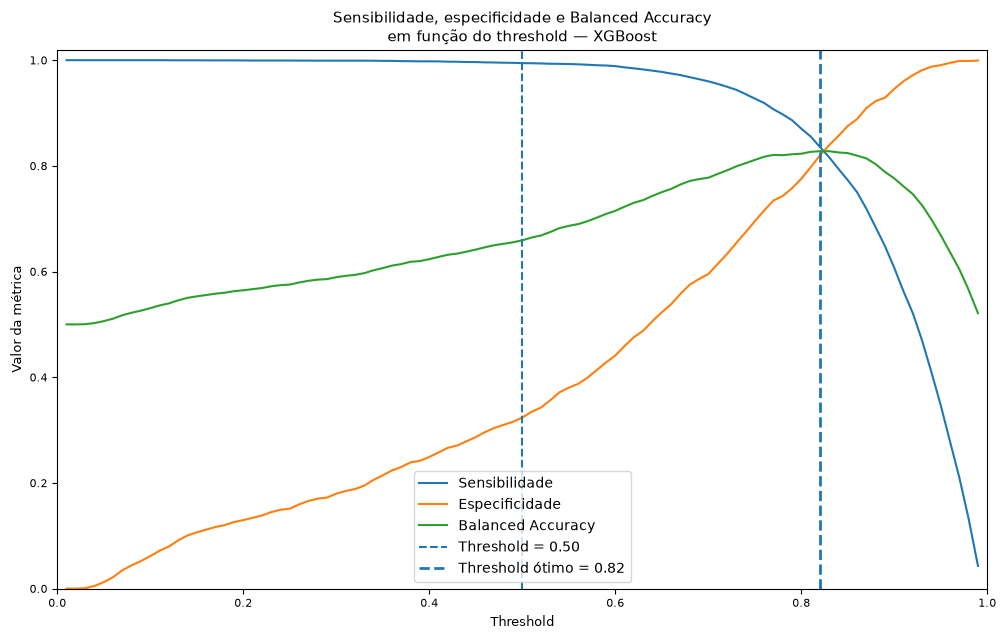

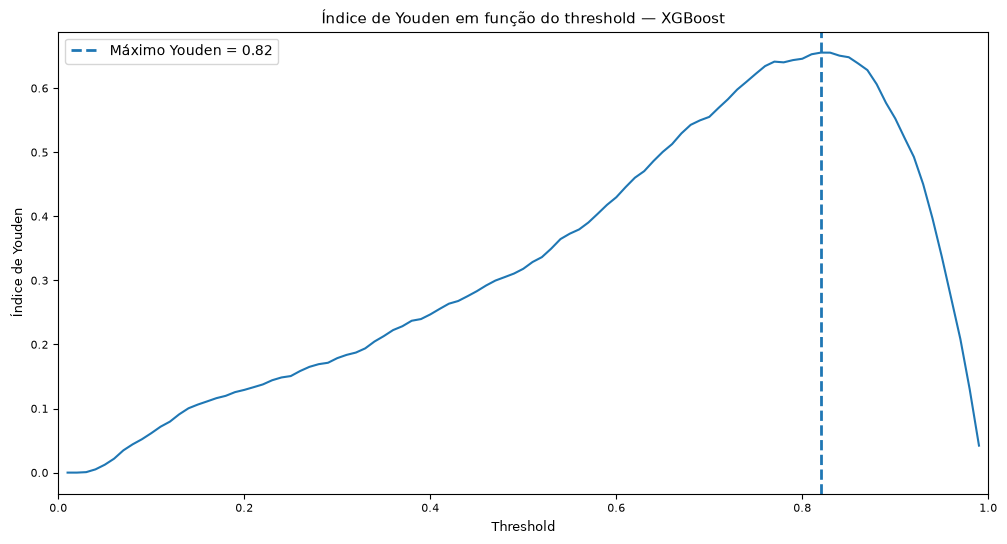


VALIDAÇÃO
✓ Thresholds avaliados exclusivamente no conjunto de desenvolvimento.
✓ 2024 não foi utilizado na escolha do threshold.
✓ Balanced Accuracy e Youden foram avaliados sistematicamente.
✓ Threshold selecionado e armazenado: 0.82
✓ O threshold ainda NÃO foi aplicado ao conjunto de teste de 2024.


In [34]:
# ============================================================
# BLOCO 27 — Seleção objetiva do threshold
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


print('=' * 78)
print('SELEÇÃO OBJETIVA DO THRESHOLD — CONJUNTO DE DESENVOLVIMENTO')
print('=' * 78)


# ============================================================
# 1. Probabilidades do XGBoost no desenvolvimento
# ============================================================

prob_dev_xgb = modelo_xgboost.predict_proba(
    X_dev
)[:, 1]

y_dev_array = np.asarray(
    y_dev
).astype(int)


# ============================================================
# 2. Grade de thresholds
# ============================================================

thresholds = np.arange(
    0.01,
    1.00,
    0.01
)


# ============================================================
# 3. Avaliação de cada threshold
# ============================================================

resultados_threshold = []


for threshold in thresholds:

    y_pred = (
        prob_dev_xgb >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_dev_array,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    sensibilidade = recall_score(
        y_dev_array,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    especificidade = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    precisao = precision_score(
        y_dev_array,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_dev_array,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    acuracia = accuracy_score(
        y_dev_array,
        y_pred
    )

    balanced_acc = balanced_accuracy_score(
        y_dev_array,
        y_pred
    )

    youden = (
        sensibilidade
        +
        especificidade
        -
        1
    )

    resultados_threshold.append(
        {
            'THRESHOLD': threshold,
            'SENSIBILIDADE': sensibilidade,
            'ESPECIFICIDADE': especificidade,
            'PRECISAO': precisao,
            'F1_SCORE': f1,
            'ACURACIA': acuracia,
            'BALANCED_ACCURACY': balanced_acc,
            'YOUDEN_J': youden,
            'TN': tn,
            'FP': fp,
            'FN': fn,
            'TP': tp
        }
    )


# ============================================================
# 4. DataFrame de resultados
# ============================================================

df_thresholds = pd.DataFrame(
    resultados_threshold
)


# ============================================================
# 5. Threshold ótimo por Balanced Accuracy
# ============================================================

idx_ba = (
    df_thresholds[
        'BALANCED_ACCURACY'
    ]
    .idxmax()
)

melhor_ba = (
    df_thresholds
    .loc[idx_ba]
)


# ============================================================
# 6. Threshold ótimo por Índice de Youden
# ============================================================

idx_youden = (
    df_thresholds[
        'YOUDEN_J'
    ]
    .idxmax()
)

melhor_youden = (
    df_thresholds
    .loc[idx_youden]
)


# ============================================================
# 7. Verificação de equivalência
# ============================================================

threshold_ba = float(
    melhor_ba[
        'THRESHOLD'
    ]
)

threshold_youden = float(
    melhor_youden[
        'THRESHOLD'
    ]
)


# ============================================================
# 8. Threshold convencional
# ============================================================

linha_050 = (
    df_thresholds[
        np.isclose(
            df_thresholds[
                'THRESHOLD'
            ],
            0.50
        )
    ]
    .iloc[0]
)


# ============================================================
# 9. Threshold mais próximo de 0.67
# ============================================================

linha_067 = (
    df_thresholds[
        np.isclose(
            df_thresholds[
                'THRESHOLD'
            ],
            0.67
        )
    ]
    .iloc[0]
)


# ============================================================
# 10. Exibição dos principais resultados
# ============================================================

print('\nTHRESHOLD ÓTIMO — BALANCED ACCURACY')

print(
    f'Threshold ............... '
    f'{threshold_ba:.2f}'
)

print(
    f'Balanced Accuracy ....... '
    f'{melhor_ba["BALANCED_ACCURACY"]:.3f}'
)

print(
    f'Sensibilidade ........... '
    f'{melhor_ba["SENSIBILIDADE"]:.3f}'
)

print(
    f'Especificidade .......... '
    f'{melhor_ba["ESPECIFICIDADE"]:.3f}'
)

print(
    f'Precisão ................. '
    f'{melhor_ba["PRECISAO"]:.3f}'
)

print(
    f'F1-score ................. '
    f'{melhor_ba["F1_SCORE"]:.3f}'
)

print(
    f'Índice de Youden ........ '
    f'{melhor_ba["YOUDEN_J"]:.3f}'
)


print('\nTHRESHOLD ÓTIMO — ÍNDICE DE YOUDEN')

print(
    f'Threshold ............... '
    f'{threshold_youden:.2f}'
)

print(
    f'Índice de Youden ........ '
    f'{melhor_youden["YOUDEN_J"]:.3f}'
)


# ============================================================
# 11. Tabela comparativa
# ============================================================

comparacao_thresholds = pd.DataFrame(
    [
        {
            'CRITERIO': 'Threshold convencional',
            **linha_050.to_dict()
        },
        {
            'CRITERIO': 'Threshold explorado',
            **linha_067.to_dict()
        },
        {
            'CRITERIO': 'Máxima Balanced Accuracy',
            **melhor_ba.to_dict()
        },
        {
            'CRITERIO': 'Máximo Índice de Youden',
            **melhor_youden.to_dict()
        }
    ]
)


colunas_exibir = [
    'CRITERIO',
    'THRESHOLD',
    'SENSIBILIDADE',
    'ESPECIFICIDADE',
    'PRECISAO',
    'F1_SCORE',
    'ACURACIA',
    'BALANCED_ACCURACY',
    'YOUDEN_J'
]


print('\n' + '=' * 78)
print('COMPARAÇÃO DOS PRINCIPAIS THRESHOLDS')
print('=' * 78)


display(
    comparacao_thresholds[
        colunas_exibir
    ]
    .style
    .format({
        'THRESHOLD': '{:.2f}',
        'SENSIBILIDADE': '{:.3f}',
        'ESPECIFICIDADE': '{:.3f}',
        'PRECISAO': '{:.3f}',
        'F1_SCORE': '{:.3f}',
        'ACURACIA': '{:.3f}',
        'BALANCED_ACCURACY': '{:.3f}',
        'YOUDEN_J': '{:.3f}'
    })
    .hide(axis='index')
)


# ============================================================
# 12. Curvas das métricas por threshold
# ============================================================

plt.figure(
    figsize=(12, 7)
)

plt.plot(
    df_thresholds['THRESHOLD'],
    df_thresholds['SENSIBILIDADE'],
    label='Sensibilidade'
)

plt.plot(
    df_thresholds['THRESHOLD'],
    df_thresholds['ESPECIFICIDADE'],
    label='Especificidade'
)

plt.plot(
    df_thresholds['THRESHOLD'],
    df_thresholds['BALANCED_ACCURACY'],
    label='Balanced Accuracy'
)

plt.axvline(
    0.50,
    linestyle='--',
    linewidth=1.5,
    label='Threshold = 0.50'
)

plt.axvline(
    threshold_ba,
    linestyle='--',
    linewidth=2,
    label=(
        f'Threshold ótimo = '
        f'{threshold_ba:.2f}'
    )
)

plt.xlabel(
    'Threshold'
)

plt.ylabel(
    'Valor da métrica'
)

plt.title(
    'Sensibilidade, especificidade e Balanced Accuracy\n'
    'em função do threshold — XGBoost'
)

plt.ylim(
    0,
    1.02
)

plt.xlim(
    0,
    1
)

plt.legend()

plt.show()


# ============================================================
# 13. Curva do Índice de Youden
# ============================================================

plt.figure(
    figsize=(12, 6)
)

plt.plot(
    df_thresholds['THRESHOLD'],
    df_thresholds['YOUDEN_J']
)

plt.axvline(
    threshold_youden,
    linestyle='--',
    linewidth=2,
    label=(
        f'Máximo Youden = '
        f'{threshold_youden:.2f}'
    )
)

plt.xlabel(
    'Threshold'
)

plt.ylabel(
    'Índice de Youden'
)

plt.title(
    'Índice de Youden em função do threshold — XGBoost'
)

plt.xlim(
    0,
    1
)

plt.legend()

plt.show()


# ============================================================
# 14. Armazenamento do threshold escolhido
# ============================================================

threshold_otimo_xgb = threshold_ba


# ============================================================
# 15. Validação final
# ============================================================

assert (
    0
    <
    threshold_otimo_xgb
    <
    1
)

assert np.isclose(
    melhor_ba[
        'BALANCED_ACCURACY'
    ],
    df_thresholds[
        'BALANCED_ACCURACY'
    ].max()
)

assert np.isclose(
    melhor_youden[
        'YOUDEN_J'
    ],
    df_thresholds[
        'YOUDEN_J'
    ].max()
)


print('\n' + '=' * 78)
print('VALIDAÇÃO')
print('=' * 78)

print(
    '✓ Thresholds avaliados exclusivamente '
    'no conjunto de desenvolvimento.'
)

print(
    '✓ 2024 não foi utilizado na escolha '
    'do threshold.'
)

print(
    '✓ Balanced Accuracy e Youden foram '
    'avaliados sistematicamente.'
)

print(
    f'✓ Threshold selecionado e armazenado: '
    f'{threshold_otimo_xgb:.2f}'
)

print(
    '✓ O threshold ainda NÃO foi aplicado '
    'ao conjunto de teste de 2024.'
)

## Interpretação dos resultados do Bloco 27 — Seleção preliminar do threshold

A avaliação sistemática dos diferentes limiares de classificação mostrou que o
desempenho do XGBoost varia substancialmente conforme o threshold utilizado
para transformar as probabilidades previstas em classes.

O threshold convencional de 0,50 apresentou:

| Threshold | Sensibilidade | Especificidade | Balanced Accuracy | Índice de Youden |
|---:|---:|---:|---:|---:|
| 0,50 | 0,994 | 0,324 | 0,659 | 0,318 |
| 0,67 | 0,972 | 0,558 | 0,765 | 0,529 |
| **0,82** | **0,836** | **0,820** | **0,828** | **0,656** |

Os resultados demonstram que o threshold convencional de 0,50 produz
comportamento fortemente direcionado à identificação da classe desfavorável.

Nesse ponto:

$$
\text{Sensibilidade}=0{,}994
$$

enquanto:

$$
\text{Especificidade}=0{,}324
$$

Portanto, aproximadamente 99,4% dos registros com evolução desfavorável são
identificados pelo modelo, mas apenas 32,4% dos registros com evolução
favorável são corretamente reconhecidos como favoráveis.

Esse comportamento confirma que uma sensibilidade muito elevada não implica,
isoladamente, uma classificação equilibrada entre as duas classes.

---

### Efeito do aumento do threshold

Ao elevar o threshold de 0,50 para 0,67, observou-se redução relativamente
pequena da sensibilidade:

$$
0{,}994 \rightarrow 0{,}972
$$

acompanhada de aumento importante da especificidade:

$$
0{,}324 \rightarrow 0{,}558
$$

A Balanced Accuracy aumentou de:

$$
0{,}659 \rightarrow 0{,}765
$$

Esse resultado demonstra que parte do desequilíbrio observado com o threshold
convencional pode ser modificada pela própria regra utilizada para converter
probabilidades em classes, sem alterar o modelo treinado ou a distribuição
original dos dados.

---

## Threshold que maximiza a Balanced Accuracy

A avaliação sistemática dos thresholds entre 0,01 e 0,99 identificou:

$$
t=0{,}82
$$

como o ponto que apresentou a maior Balanced Accuracy no conjunto de
desenvolvimento utilizado nesta análise.

Nesse threshold:

$$
\text{Sensibilidade}=0{,}836
$$

$$
\text{Especificidade}=0{,}820
$$

$$
\text{Precisão}=0{,}963
$$

$$
F1=0{,}895
$$

e:

$$
\text{Balanced Accuracy}=0{,}828
$$

A Balanced Accuracy é definida por:

$$
BA=
\frac{
\text{Sensibilidade}
+
\text{Especificidade}
}{2}
$$

Portanto:

$$
BA=
\frac{
0{,}836+0{,}820
}{2}
$$

resultando em:

$$
BA=0{,}828
$$

Esse resultado representa um equilíbrio substancialmente maior entre a
capacidade de identificar registros desfavoráveis e a capacidade de reconhecer
registros favoráveis.

Em comparação com o threshold convencional, houve redução da sensibilidade:

$$
0{,}994 \rightarrow 0{,}836
$$

mas aumento expressivo da especificidade:

$$
0{,}324 \rightarrow 0{,}820
$$

Assim, o modelo deixa de classificar uma parcela muito elevada dos registros
como desfavoráveis e passa a apresentar desempenho mais equilibrado entre as
duas classes.

---

## Interpretação gráfica

O gráfico de sensibilidade, especificidade e Balanced Accuracy em função do
threshold demonstra visualmente o trade-off existente entre as duas primeiras
métricas.

À medida que o threshold aumenta, a sensibilidade apresenta tendência
decrescente:

$$
t\uparrow
\Rightarrow
\text{Sensibilidade}\downarrow
$$

enquanto a especificidade apresenta comportamento crescente:

$$
t\uparrow
\Rightarrow
\text{Especificidade}\uparrow
$$

A Balanced Accuracy combina essas duas dimensões:

$$
BA(t)
=
\frac{
Sens(t)+Esp(t)
}{2}
$$

No conjunto analisado, essa função aumenta progressivamente até atingir seu
máximo aproximadamente em:

$$
\boxed{t=0{,}82}
$$

Após esse ponto, a perda de sensibilidade passa a superar o benefício obtido
com o aumento da especificidade, provocando redução da Balanced Accuracy.

Portanto, o máximo da curva representa o ponto no qual foi obtido o melhor
equilíbrio matemático entre sensibilidade e especificidade **nos dados
utilizados nesta etapa**.

---

## Índice de Youden

O Índice de Youden apresentou comportamento equivalente.

Sua definição é:

$$
J(t)
=
Sens(t)+Esp(t)-1
$$

O maior valor observado foi:

$$
J=0{,}656
$$

também no threshold:

$$
t=0{,}82
$$

Esse resultado é esperado porque existe uma relação matemática direta entre
Balanced Accuracy e Índice de Youden:

$$
BA=
\frac{Sens+Esp}{2}
$$

Multiplicando ambos os lados por 2:

$$
2BA=Sens+Esp
$$

e, portanto:

$$
J=2BA-1
$$

Substituindo o resultado encontrado:

$$
J=
2(0{,}828)-1
$$

$$
J=0{,}656
$$

Assim, quando sensibilidade e especificidade recebem o mesmo peso, maximizar a
Balanced Accuracy e maximizar o Índice de Youden são critérios equivalentes:

$$
\boxed{
\arg\max_t BA(t)
=
\arg\max_t J(t)
}
$$

Por essa razão, ambos os critérios identificaram o mesmo threshold de 0,82.

---

# Importante: 0,82 ainda não deve ser considerado o threshold definitivo

Apesar do resultado favorável, existe uma questão metodológica importante.

As probabilidades utilizadas nesta etapa foram produzidas pelo XGBoost no
próprio conjunto de desenvolvimento utilizado anteriormente para ajustar o
modelo.

Em termos simplificados, foi realizado:

$$
D_{dev}
\rightarrow
\text{treinamento do XGBoost}
$$

e posteriormente:

$$
D_{dev}
\rightarrow
\text{avaliação dos thresholds}
$$

Portanto, o modelo foi treinado nos mesmos registros utilizados para avaliar
o comportamento dos diferentes pontos de corte.

Isso significa que:

$$
\boxed{
t_{\text{aparente}}=0{,}82
}
$$

deve ser interpretado, neste momento, como um **threshold ótimo aparente
(in-sample)**.

Da mesma forma:

$$
BA_{\text{aparente}}=0{,}828
$$

não deve ser interpretada como estimativa final do desempenho esperado em
dados temporalmente independentes.

---

## Por que a avaliação in-sample pode ser otimista?

Um algoritmo de aprendizado de máquina busca identificar padrões nos dados
utilizados durante seu treinamento.

Quando o desempenho é posteriormente avaliado nesses mesmos registros, o
modelo pode apresentar resultados superiores aos que obteria em observações
que não participaram do processo de aprendizagem.

Conceitualmente:

$$
D_{treino}=D_{avaliação}
$$

não fornece a mesma evidência de generalização que:

$$
D_{treino}\neq D_{avaliação}
$$

Essa questão é particularmente relevante para modelos flexíveis, como o
XGBoost, capazes de representar relações não lineares e interações entre
variáveis.

Portanto, antes de congelar o threshold em 0,82 e aplicá-lo ao teste temporal
de 2024, será realizada uma etapa adicional de validação interna.

---

# Previsões out-of-fold

Uma estratégia mais rigorosa consiste em produzir **previsões out-of-fold
(OOF)** dentro do conjunto de desenvolvimento.

A ideia fundamental é garantir que a probabilidade atribuída a cada registro
seja produzida por um modelo que **não utilizou aquele próprio registro em seu
treinamento**.

Considere uma divisão do conjunto de desenvolvimento em subconjuntos:

$$
D_{dev}
=
F_1\cup F_2\cup\cdots\cup F_k
$$

Em determinada etapa, um subconjunto $F_k$ é reservado para validação e o
modelo é ajustado nos demais dados:

$$
D_{treino}^{(k)}
=
D_{dev}\setminus F_k
$$

O modelo ajustado em:

$$
D_{treino}^{(k)}
$$

produz probabilidades apenas para:

$$
F_k
$$

Portanto, para cada registro $i$ pertencente ao fold de validação:

$$
i\notin D_{treino}^{(k)}
$$

A probabilidade obtida pode ser representada por:

$$
\hat{p}_i^{OOF}
=
P(
Y_i=1
\mid
X_i,\,
i\notin D_{treino}^{(k)}
)
$$

Ao final do procedimento, cada registro do conjunto de desenvolvimento possui
uma probabilidade estimada por um modelo que não utilizou esse registro em seu
próprio treinamento.

---

# Seleção do threshold com previsões OOF

Após a geração das probabilidades out-of-fold, os thresholds podem ser
novamente avaliados.

Para cada valor de $t$:

$$
\hat{Y}_i^{OOF}(t)
=
\begin{cases}
1, & \text{se } \hat{p}_i^{OOF}\geq t \\
0, & \text{se } \hat{p}_i^{OOF}<t
\end{cases}
$$

Em seguida, calcula-se:

$$
Sens_{OOF}(t)
$$

$$
Esp_{OOF}(t)
$$

e:

$$
BA_{OOF}(t)
=
\frac{
Sens_{OOF}(t)+Esp_{OOF}(t)
}{2}
$$

O threshold poderá então ser selecionado por:

$$
\boxed{
t_{OOF}^{*}
=
\arg\max_t BA_{OOF}(t)
}
$$

ou, de maneira equivalente:

$$
\boxed{
t_{OOF}^{*}
=
\arg\max_t J_{OOF}(t)
}
$$

Esse procedimento reduz o otimismo associado à escolha do threshold utilizando
previsões produzidas sobre os próprios registros de treinamento.

---

# Importância da estrutura temporal dos dados

Neste estudo, a validação possui ainda uma característica importante: os dados
apresentam estrutura temporal.

O conjunto de desenvolvimento contém registros dos anos disponíveis entre
2014 e 2023, enquanto:

$$
D_{teste}=2024
$$

foi reservado como teste temporal principal e:

$$
D_{complementar}=2025
$$

foi reservado para avaliação temporal complementar.

Além disso, não existem observações disponíveis para 2020 e 2021 na base
utilizada.

Como o objetivo é avaliar a capacidade de generalização para períodos
posteriores, uma validação interna puramente aleatória pode não reproduzir
adequadamente o cenário real de aplicação.

A lógica temporal desejada é:

$$
\boxed{
\text{passado}
\rightarrow
\text{futuro}
}
$$

Isto é, utilizar informações disponíveis até determinado momento para avaliar
o desempenho em períodos posteriores.

Deve-se evitar, sempre que possível, uma estrutura de validação que permita:

$$
\text{futuro}
\rightarrow
\text{passado}
$$

pois isso produziria uma situação menos compatível com o uso prospectivo do
modelo.

---

# Situação metodológica após o Bloco 27

Neste momento, os resultados permitem concluir que o threshold convencional
de 0,50 produz elevada sensibilidade, porém baixa especificidade, enquanto o
aumento do ponto de corte melhora substancialmente o equilíbrio entre as duas
classes.

A exploração sistemática identificou:

$$
\boxed{
t_{\text{aparente}}^{*}=0{,}82
}
$$

com:

$$
Sens=0{,}836
$$

$$
Esp=0{,}820
$$

$$
BA=0{,}828
$$

e:

$$
J=0{,}656
$$

Entretanto, esses resultados foram obtidos a partir de previsões realizadas no
próprio conjunto utilizado para treinamento do XGBoost.

Consequentemente, o threshold de 0,82 deve ser tratado como uma **estimativa
preliminar ou aparente**, e não como ponto de corte definitivo.

A sequência metodológica passa a ser:

$$
\boxed{
D_{dev}
\rightarrow
\text{validação interna}
\rightarrow
\text{probabilidades OOF}
\rightarrow
t_{OOF}^{*}
}
$$

Depois:

$$
\boxed{
\text{threshold congelado}
}
$$

e somente então:

$$
\boxed{
D_{2024}
\rightarrow
\text{teste temporal independente}
}
$$

Por fim:

$$
\boxed{
D_{2025}
\rightarrow
\text{avaliação temporal complementar}
}
$$

Essa estratégia permite separar de maneira mais rigorosa as etapas de
**treinamento**, **seleção do limiar de decisão** e **avaliação externa no
tempo**, reduzindo o risco de estimativas excessivamente otimistas.

Portanto, o próximo passo consiste em realizar uma **validação interna com
estrutura temporal e gerar previsões out-of-fold**, a partir das quais o
threshold será novamente estimado antes de qualquer aplicação ao conjunto
temporal de 2024.

------------------------------------------------

## BLOCO 28 — Validação interna temporal e seleção out-of-fold do threshold

O Bloco 27 identificou um threshold aparente de 0,82 para o XGBoost,
correspondente ao ponto de máxima Balanced Accuracy e máximo Índice de Youden
nas probabilidades produzidas sobre o próprio conjunto de desenvolvimento.

Entretanto, como essas probabilidades foram obtidas a partir de registros que
também participaram do treinamento do modelo, essa estimativa pode apresentar
otimismo.

Para reduzir esse problema, nesta etapa será realizada uma **validação interna
temporal**, produzindo previsões **out-of-fold (OOF)**.

### Princípio da validação temporal

Em cada divisão, o modelo será treinado exclusivamente com registros de anos
anteriores e avaliado em um período posterior.

A regra fundamental será:

$$
\boxed{
\max(Ano_{treino}) < \min(Ano_{validação})
}
$$

Dessa forma, informações de períodos posteriores não serão utilizadas para
prever artificialmente registros do passado.

A lógica será:

$$
\text{passado}
\rightarrow
\text{treinamento}
\rightarrow
\text{período futuro}
$$

e nunca:

$$
\text{futuro}
\rightarrow
\text{passado}
$$

### Estrutura dos folds temporais

O conjunto de desenvolvimento contém os anos disponíveis:

$$
2014,\ 2015,\ 2016,\ 2017,\ 2018,\ 2019,\ 2022,\ 2023
$$

Os anos de 2020 e 2021 não possuem observações disponíveis na base e,
portanto, não serão interpretados como anos com zero notificações.

Será utilizada uma estratégia de **janela expansiva** (*expanding window*).

Isso significa que o conjunto de treinamento aumenta progressivamente ao longo
do tempo.

Conceitualmente:

$$
D_{treino}^{(1)}
\subset
D_{treino}^{(2)}
\subset
\cdots
\subset
D_{treino}^{(k)}
$$

Um exemplo da lógica é:

$$
2014\text{--}2016
\rightarrow
2017
$$

depois:

$$
2014\text{--}2017
\rightarrow
2018
$$

e posteriormente:

$$
2014\text{--}2019
\rightarrow
2022
$$

A ausência de 2020 e 2021 não será preenchida artificialmente.

### Por que os primeiros anos não recebem previsão OOF?

Para produzir uma previsão temporal genuína é necessário existir um período
anterior para treinamento.

Assim, os anos iniciais utilizados para formar a primeira janela de
treinamento não recebem probabilidades OOF nesta estratégia.

Isso é esperado e não representa perda acidental de dados.

Esses registros continuam fazendo parte do desenvolvimento dos modelos, mas
não entram na estimação temporal do threshold quando foram utilizados para
formar a janela inicial.

### Probabilidade out-of-fold

Para um registro $i$ pertencente ao período de validação $F_k$, a probabilidade
OOF será produzida por um modelo treinado apenas nos períodos anteriores:

$$
\hat{p}^{OOF}_i
=
P(
Y_i=1
\mid
X_i,\,
i\notin D_{treino}^{(k)}
)
$$

Portanto:

$$
\boxed{
i\notin D_{treino}^{(k)}
}
$$

para toda observação que recebe uma previsão OOF.

Essa propriedade diferencia as probabilidades OOF das probabilidades
in-sample utilizadas no Bloco 27.

### Seleção do threshold

Depois de reunir todas as probabilidades OOF, serão avaliados thresholds entre:

$$
0{,}01 \leq t \leq 0{,}99
$$

Para cada threshold serão calculados:

$$
Sens(t)
$$

$$
Esp(t)
$$

$$
BA(t)
=
\frac{Sens(t)+Esp(t)}{2}
$$

e:

$$
J(t)
=
Sens(t)+Esp(t)-1
$$

O threshold temporal será definido inicialmente por:

$$
\boxed{
t_{OOF}^{*}
=
\arg\max_t BA_{OOF}(t)
}
$$

Como:

$$
J=2BA-1
$$

o máximo do Índice de Youden deverá ocorrer no mesmo ponto quando ambas as
classes recebem o mesmo peso.

### Comparação com o resultado in-sample

O threshold temporal OOF será comparado ao threshold aparente encontrado no
Bloco 27:

$$
t_{in-sample}^{*}=0{,}82
$$

Se:

$$
t_{OOF}^{*}
\approx
t_{in-sample}^{*}
$$

isso indicará estabilidade do ponto de corte.

Caso:

$$
t_{OOF}^{*}
\neq
t_{in-sample}^{*}
$$

a diferença será interpretada como evidência de que a escolha baseada nas
previsões in-sample era otimista ou pouco estável temporalmente.

Não será feita qualquer tentativa de forçar os dois thresholds a coincidir.

### Preservação do teste temporal

O conjunto de 2024 permanecerá completamente fora desta etapa:

$$
D_{2024}
\notin
\{
treinamento,\ validação\ interna,\ seleção\ do\ threshold
\}
$$

Da mesma forma, 2025 continuará reservado para avaliação temporal
complementar.

A sequência metodológica permanece:

$$
\boxed{
2014\text{--}2023
\rightarrow
\text{validação temporal interna}
\rightarrow
t_{OOF}^{*}
}
$$

seguida de:

$$
\boxed{
t_{OOF}^{*}\ \text{congelado}
\rightarrow
2024
}
$$

e posteriormente:

$$
\boxed{
2025
\rightarrow
\text{avaliação complementar}
}
$$

Assim, o Bloco 28 busca obter uma estimativa mais rigorosa do limiar de decisão
antes da avaliação temporal independente.

-------------------------

VALIDAÇÃO INTERNA TEMPORAL — XGBOOST
PREVISÕES OUT-OF-FOLD E SELEÇÃO DO THRESHOLD

Anos disponíveis no desenvolvimento:
[2014, 2015, 2016, 2017, 2018, 2019, 2022, 2023]

Folds temporais planejados:
  Treino 2014–2016 ([2014, 2015, 2016]) -> Validação 2017
  Treino 2014–2017 ([2014, 2015, 2016, 2017]) -> Validação 2018
  Treino 2014–2018 ([2014, 2015, 2016, 2017, 2018]) -> Validação 2019
  Treino 2014–2019 ([2014, 2015, 2016, 2017, 2018, 2019]) -> Validação 2022
  Treino 2014–2022 ([2014, 2015, 2016, 2017, 2018, 2019, 2022]) -> Validação 2023

EXECUÇÃO DOS FOLDS
✓ Fold 1: treino até 2016 -> validação 2017 | N treino = 2,339 | N validação = 1,273
✓ Fold 2: treino até 2017 -> validação 2018 | N treino = 3,612 | N validação = 998
✓ Fold 3: treino até 2018 -> validação 2019 | N treino = 4,610 | N validação = 1,097
✓ Fold 4: treino até 2019 -> validação 2022 | N treino = 5,707 | N validação = 1,347
✓ Fold 5: treino até 2022 -> validação 2023 | N treino = 7,054 | N validação = 2,076

RESUMO D

FOLD,ANOS_TREINO,ANO_VALIDACAO,N_TREINO,N_VALIDACAO,PREVALENCIA_DESFAVORAVEL_VALIDACAO,ROC_AUC,PR_AUC
1,2014–2016,2017,2339,1273,0.902,0.670,0.946
2,2014–2017,2018,3612,998,0.892,0.666,0.930
3,2014–2018,2019,4610,1097,0.846,0.669,0.919
4,2014–2019,2022,5707,1347,0.800,0.716,0.898
5,2014–2022,2023,7054,2076,0.761,0.688,0.873



COBERTURA DAS PREVISÕES OOF
Registros no desenvolvimento: 9,130
Registros com previsão OOF:   6,791
Cobertura OOF:                74.38%
Anos com previsão OOF:        [2017, 2018, 2019, 2022, 2023]
Anos usados apenas na janela inicial: [2014, 2015, 2016]

DISCRIMINAÇÃO GLOBAL — PREVISÕES OOF
ROC-AUC OOF ................. 0.700
PR-AUC OOF .................. 0.912
Prevalência desfavorável .... 0.828

THRESHOLD ÓTIMO — VALIDAÇÃO TEMPORAL OOF
Threshold ................. 0.91
Balanced Accuracy ......... 0.651
Sensibilidade ............. 0.653
Especificidade ............ 0.649
Precisão ................... 0.900
F1-score ................... 0.757
Índice de Youden .......... 0.302

Threshold pelo máximo Youden:
0.91

COMPARAÇÃO DOS THRESHOLDS NAS PREVISÕES OOF


CRITERIO,THRESHOLD,SENSIBILIDADE,ESPECIFICIDADE,PRECISAO,F1_SCORE,ACURACIA,BALANCED_ACCURACY,YOUDEN_J
Convencional — OOF,0.50,0.986,0.100,0.841,0.908,0.834,0.543,0.087
0.82 do Bloco 27 avaliado OOF,0.82,0.845,0.359,0.864,0.854,0.762,0.602,0.204
Ótimo temporal OOF,0.91,0.653,0.649,0.900,0.757,0.652,0.651,0.302


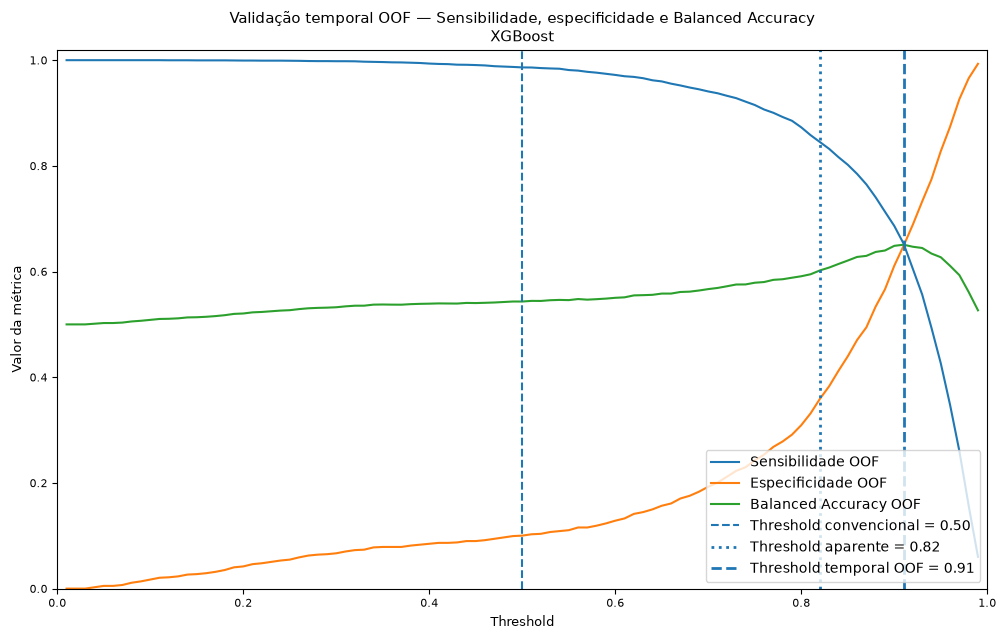

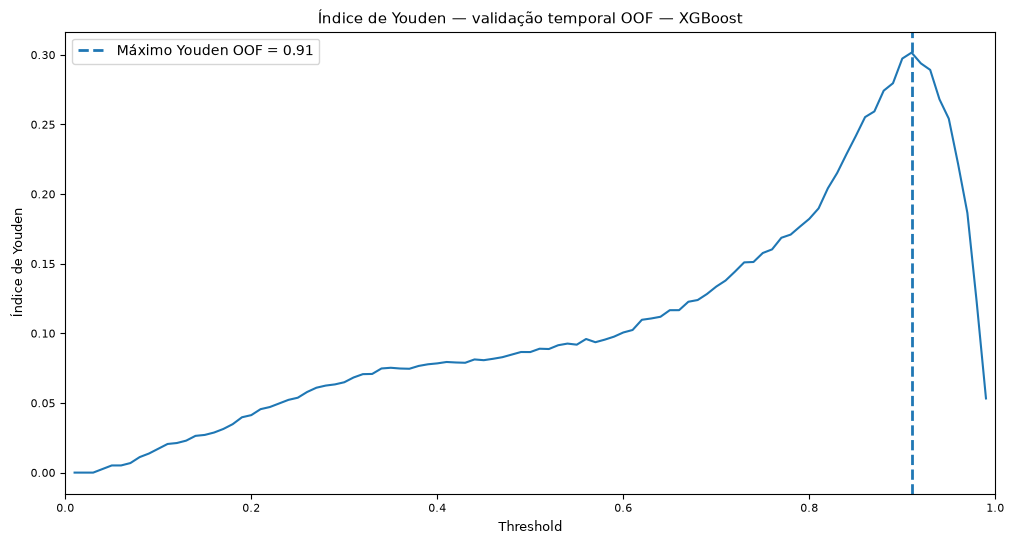


COMPARAÇÃO — BLOCO 27 versus BLOCO 28
Threshold aparente (in-sample) ............... 0.82
Threshold temporal (OOF) ..................... 0.91
Diferença absoluta ........ 0.09

VALIDAÇÃO METODOLÓGICA
✓ Cada ano de validação foi previsto somente com dados de anos anteriores.
✓ O pipeline completo foi reajustado dentro de cada fold.
✓ Cada previsão OOF foi produzida por um modelo que não treinou naquele registro.
✓ 2024 não participou do treinamento, da validação interna ou da escolha do threshold.
✓ 2025 permaneceu completamente fora desta etapa.
✓ Nenhum balanceamento artificial foi aplicado.
✓ O threshold temporal ainda NÃO foi aplicado a 2024.


In [35]:
# ============================================================
# BLOCO 28 — Validação interna temporal e seleção OOF
#             do threshold — XGBoost
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)


print('=' * 80)
print('VALIDAÇÃO INTERNA TEMPORAL — XGBOOST')
print('PREVISÕES OUT-OF-FOLD E SELEÇÃO DO THRESHOLD')
print('=' * 80)


# ============================================================
# 1. Recuperar os anos correspondentes ao X_dev
# ============================================================

# NU_ANO não está entre os preditores do modelo.
# Aqui ele é usado exclusivamente para organizar
# a validação temporal.

anos_dev = (
    df_modelagem_final
    .loc[X_dev.index, 'NU_ANO']
    .astype(int)
)


# Verificação de alinhamento
assert X_dev.index.equals(y_dev.index)
assert X_dev.index.equals(anos_dev.index)


anos_disponiveis = sorted(
    anos_dev.unique().tolist()
)

print('\nAnos disponíveis no desenvolvimento:')
print(anos_disponiveis)


# ============================================================
# 2. Definição explícita dos folds temporais
# ============================================================

# Utilizamos os três primeiros anos disponíveis para formar
# a primeira janela mínima de treinamento.
#
# A partir daí, cada ano posterior é utilizado como
# validação temporal.
#
# Isso gera:
#
# 2014–2016 -> 2017
# 2014–2017 -> 2018
# 2014–2018 -> 2019
# 2014–2019 -> 2022
# 2014–2022 -> 2023

if len(anos_disponiveis) < 4:
    raise ValueError(
        'São necessários pelo menos quatro anos disponíveis '
        'para esta estratégia de validação temporal.'
    )


anos_validacao = anos_disponiveis[3:]


print('\nFolds temporais planejados:')

for ano_val in anos_validacao:

    anos_treino = [
        ano
        for ano in anos_disponiveis
        if ano < ano_val
    ]

    print(
        f'  Treino {anos_treino[0]}–{anos_treino[-1]} '
        f'({anos_treino}) -> Validação {ano_val}'
    )


# ============================================================
# 3. Estruturas para armazenar as previsões OOF
# ============================================================

prob_oof = pd.Series(
    data=np.nan,
    index=X_dev.index,
    dtype=float,
    name='PROB_OOF_XGB'
)

fold_oof = pd.Series(
    data=pd.NA,
    index=X_dev.index,
    dtype='Int64',
    name='FOLD_TEMPORAL'
)

resumo_folds = []


# ============================================================
# 4. Treinamento temporal fold a fold
# ============================================================

print('\n' + '=' * 80)
print('EXECUÇÃO DOS FOLDS')
print('=' * 80)


for numero_fold, ano_val in enumerate(
    anos_validacao,
    start=1
):

    # --------------------------------------------------------
    # Máscaras temporais
    # --------------------------------------------------------

    mask_treino = anos_dev < ano_val
    mask_validacao = anos_dev == ano_val


    X_treino_fold = X_dev.loc[mask_treino]
    y_treino_fold = y_dev.loc[mask_treino]

    X_valid_fold = X_dev.loc[mask_validacao]
    y_valid_fold = y_dev.loc[mask_validacao]


    # --------------------------------------------------------
    # Verificações
    # --------------------------------------------------------

    ano_max_treino = int(
        anos_dev.loc[mask_treino].max()
    )

    ano_min_valid = int(
        anos_dev.loc[mask_validacao].min()
    )

    assert ano_max_treino < ano_min_valid

    assert len(
        X_treino_fold.index.intersection(
            X_valid_fold.index
        )
    ) == 0

    if y_treino_fold.nunique() < 2:
        raise ValueError(
            f'Fold {numero_fold}: o treinamento possui '
            'apenas uma classe.'
        )

    if y_valid_fold.nunique() < 2:
        print(
            f'Atenção: validação de {ano_val} possui '
            'apenas uma classe.'
        )


    # --------------------------------------------------------
    # Clone COMPLETO do pipeline XGBoost
    # --------------------------------------------------------

    modelo_fold = clone(
        modelo_xgboost
    )


    # --------------------------------------------------------
    # Ajuste SOMENTE nos anos anteriores
    # --------------------------------------------------------

    modelo_fold.fit(
        X_treino_fold,
        y_treino_fold
    )


    # --------------------------------------------------------
    # Probabilidades no ano futuro
    # --------------------------------------------------------

    prob_valid_fold = (
        modelo_fold
        .predict_proba(
            X_valid_fold
        )[:, 1]
    )


    # --------------------------------------------------------
    # Armazenamento das probabilidades OOF
    # --------------------------------------------------------

    prob_oof.loc[
        X_valid_fold.index
    ] = prob_valid_fold

    fold_oof.loc[
        X_valid_fold.index
    ] = numero_fold


    # --------------------------------------------------------
    # Métricas independentes de threshold
    # --------------------------------------------------------

    if y_valid_fold.nunique() == 2:

        roc_fold = roc_auc_score(
            y_valid_fold,
            prob_valid_fold
        )

        pr_fold = average_precision_score(
            y_valid_fold,
            prob_valid_fold
        )

    else:

        roc_fold = np.nan
        pr_fold = np.nan


    resumo_folds.append(
        {
            'FOLD': numero_fold,
            'ANOS_TREINO': (
                f'{int(anos_dev.loc[mask_treino].min())}'
                f'–'
                f'{int(anos_dev.loc[mask_treino].max())}'
            ),
            'ANO_VALIDACAO': ano_val,
            'N_TREINO': len(X_treino_fold),
            'N_VALIDACAO': len(X_valid_fold),
            'PREVALENCIA_DESFAVORAVEL_VALIDACAO':
                y_valid_fold.mean(),
            'ROC_AUC': roc_fold,
            'PR_AUC': pr_fold
        }
    )


    print(
        f'✓ Fold {numero_fold}: '
        f'treino até {ano_max_treino} -> '
        f'validação {ano_val} | '
        f'N treino = {len(X_treino_fold):,} | '
        f'N validação = {len(X_valid_fold):,}'
    )


# ============================================================
# 5. Resumo dos folds
# ============================================================

df_folds_temporais = pd.DataFrame(
    resumo_folds
)


print('\n' + '=' * 80)
print('RESUMO DOS FOLDS TEMPORAIS')
print('=' * 80)


display(
    df_folds_temporais
    .style
    .format({
        'PREVALENCIA_DESFAVORAVEL_VALIDACAO': '{:.3f}',
        'ROC_AUC': '{:.3f}',
        'PR_AUC': '{:.3f}'
    })
    .hide(axis='index')
)


# ============================================================
# 6. Construção da base OOF
# ============================================================

mask_oof = prob_oof.notna()


y_oof = (
    y_dev
    .loc[mask_oof]
    .astype(int)
)

prob_oof_validas = (
    prob_oof
    .loc[mask_oof]
    .astype(float)
)

anos_oof = (
    anos_dev
    .loc[mask_oof]
)


print('\n' + '=' * 80)
print('COBERTURA DAS PREVISÕES OOF')
print('=' * 80)

print(
    f'Registros no desenvolvimento: '
    f'{len(X_dev):,}'
)

print(
    f'Registros com previsão OOF:   '
    f'{len(y_oof):,}'
)

print(
    f'Cobertura OOF:                '
    f'{len(y_oof) / len(X_dev):.2%}'
)

print(
    'Anos com previsão OOF:        '
    f'{sorted(anos_oof.unique().tolist())}'
)

anos_sem_oof = sorted(
    set(anos_disponiveis)
    -
    set(anos_oof.unique().tolist())
)

print(
    'Anos usados apenas na janela '
    f'inicial: {anos_sem_oof}'
)


# ============================================================
# 7. Desempenho discriminativo OOF global
# ============================================================

roc_auc_oof = roc_auc_score(
    y_oof,
    prob_oof_validas
)

pr_auc_oof = average_precision_score(
    y_oof,
    prob_oof_validas
)


print('\n' + '=' * 80)
print('DISCRIMINAÇÃO GLOBAL — PREVISÕES OOF')
print('=' * 80)

print(
    f'ROC-AUC OOF ................. '
    f'{roc_auc_oof:.3f}'
)

print(
    f'PR-AUC OOF .................. '
    f'{pr_auc_oof:.3f}'
)

print(
    f'Prevalência desfavorável .... '
    f'{y_oof.mean():.3f}'
)


# ============================================================
# 8. Avaliação sistemática dos thresholds OOF
# ============================================================

thresholds_oof = np.arange(
    0.01,
    1.00,
    0.01
)

resultados_threshold_oof = []


for threshold in thresholds_oof:

    y_pred_oof = (
        prob_oof_validas >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_oof,
        y_pred_oof,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()


    sensibilidade = recall_score(
        y_oof,
        y_pred_oof,
        pos_label=1,
        zero_division=0
    )


    especificidade = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


    precisao = precision_score(
        y_oof,
        y_pred_oof,
        pos_label=1,
        zero_division=0
    )


    f1 = f1_score(
        y_oof,
        y_pred_oof,
        pos_label=1,
        zero_division=0
    )


    acuracia = accuracy_score(
        y_oof,
        y_pred_oof
    )


    balanced_acc = balanced_accuracy_score(
        y_oof,
        y_pred_oof
    )


    youden = (
        sensibilidade
        +
        especificidade
        -
        1
    )


    resultados_threshold_oof.append(
        {
            'THRESHOLD': threshold,
            'SENSIBILIDADE': sensibilidade,
            'ESPECIFICIDADE': especificidade,
            'PRECISAO': precisao,
            'F1_SCORE': f1,
            'ACURACIA': acuracia,
            'BALANCED_ACCURACY': balanced_acc,
            'YOUDEN_J': youden,
            'TN': tn,
            'FP': fp,
            'FN': fn,
            'TP': tp
        }
    )


df_thresholds_oof = pd.DataFrame(
    resultados_threshold_oof
)


# ============================================================
# 9. Threshold OOF de máxima Balanced Accuracy
# ============================================================

idx_otimo_oof = (
    df_thresholds_oof[
        'BALANCED_ACCURACY'
    ]
    .idxmax()
)


melhor_oof = (
    df_thresholds_oof
    .loc[idx_otimo_oof]
)


threshold_otimo_oof_xgb = float(
    melhor_oof[
        'THRESHOLD'
    ]
)


# ============================================================
# 10. Verificação pelo Índice de Youden
# ============================================================

idx_youden_oof = (
    df_thresholds_oof[
        'YOUDEN_J'
    ]
    .idxmax()
)


melhor_youden_oof = (
    df_thresholds_oof
    .loc[idx_youden_oof]
)


threshold_youden_oof = float(
    melhor_youden_oof[
        'THRESHOLD'
    ]
)


# ============================================================
# 11. Threshold 0.50 nas previsões OOF
# ============================================================

linha_oof_050 = (
    df_thresholds_oof[
        np.isclose(
            df_thresholds_oof[
                'THRESHOLD'
            ],
            0.50
        )
    ]
    .iloc[0]
)


# ============================================================
# 12. Comparação com threshold aparente do Bloco 27
# ============================================================

threshold_aparente = 0.82


linha_oof_082 = (
    df_thresholds_oof[
        np.isclose(
            df_thresholds_oof[
                'THRESHOLD'
            ],
            threshold_aparente
        )
    ]
    .iloc[0]
)


comparacao_oof = pd.DataFrame(
    [
        {
            'CRITERIO':
                'Convencional — OOF',
            **linha_oof_050.to_dict()
        },
        {
            'CRITERIO':
                '0.82 do Bloco 27 avaliado OOF',
            **linha_oof_082.to_dict()
        },
        {
            'CRITERIO':
                'Ótimo temporal OOF',
            **melhor_oof.to_dict()
        }
    ]
)


print('\n' + '=' * 80)
print('THRESHOLD ÓTIMO — VALIDAÇÃO TEMPORAL OOF')
print('=' * 80)

print(
    f'Threshold ................. '
    f'{threshold_otimo_oof_xgb:.2f}'
)

print(
    f'Balanced Accuracy ......... '
    f'{melhor_oof["BALANCED_ACCURACY"]:.3f}'
)

print(
    f'Sensibilidade ............. '
    f'{melhor_oof["SENSIBILIDADE"]:.3f}'
)

print(
    f'Especificidade ............ '
    f'{melhor_oof["ESPECIFICIDADE"]:.3f}'
)

print(
    f'Precisão ................... '
    f'{melhor_oof["PRECISAO"]:.3f}'
)

print(
    f'F1-score ................... '
    f'{melhor_oof["F1_SCORE"]:.3f}'
)

print(
    f'Índice de Youden .......... '
    f'{melhor_oof["YOUDEN_J"]:.3f}'
)


print('\nThreshold pelo máximo Youden:')

print(
    f'{threshold_youden_oof:.2f}'
)


print('\n' + '=' * 80)
print('COMPARAÇÃO DOS THRESHOLDS NAS PREVISÕES OOF')
print('=' * 80)


display(
    comparacao_oof[
        [
            'CRITERIO',
            'THRESHOLD',
            'SENSIBILIDADE',
            'ESPECIFICIDADE',
            'PRECISAO',
            'F1_SCORE',
            'ACURACIA',
            'BALANCED_ACCURACY',
            'YOUDEN_J'
        ]
    ]
    .style
    .format({
        'THRESHOLD': '{:.2f}',
        'SENSIBILIDADE': '{:.3f}',
        'ESPECIFICIDADE': '{:.3f}',
        'PRECISAO': '{:.3f}',
        'F1_SCORE': '{:.3f}',
        'ACURACIA': '{:.3f}',
        'BALANCED_ACCURACY': '{:.3f}',
        'YOUDEN_J': '{:.3f}'
    })
    .hide(axis='index')
)


# ============================================================
# 13. Curvas OOF por threshold
# ============================================================

plt.figure(
    figsize=(12, 7)
)

plt.plot(
    df_thresholds_oof['THRESHOLD'],
    df_thresholds_oof['SENSIBILIDADE'],
    label='Sensibilidade OOF'
)

plt.plot(
    df_thresholds_oof['THRESHOLD'],
    df_thresholds_oof['ESPECIFICIDADE'],
    label='Especificidade OOF'
)

plt.plot(
    df_thresholds_oof['THRESHOLD'],
    df_thresholds_oof['BALANCED_ACCURACY'],
    label='Balanced Accuracy OOF'
)

plt.axvline(
    0.50,
    linestyle='--',
    linewidth=1.5,
    label='Threshold convencional = 0.50'
)

plt.axvline(
    threshold_aparente,
    linestyle=':',
    linewidth=2,
    label='Threshold aparente = 0.82'
)

plt.axvline(
    threshold_otimo_oof_xgb,
    linestyle='--',
    linewidth=2,
    label=(
        'Threshold temporal OOF = '
        f'{threshold_otimo_oof_xgb:.2f}'
    )
)

plt.xlabel(
    'Threshold'
)

plt.ylabel(
    'Valor da métrica'
)

plt.title(
    'Validação temporal OOF — Sensibilidade, '
    'especificidade e Balanced Accuracy\n'
    'XGBoost'
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1.02
)

plt.legend()

plt.show()


# ============================================================
# 14. Índice de Youden OOF
# ============================================================

plt.figure(
    figsize=(12, 6)
)

plt.plot(
    df_thresholds_oof['THRESHOLD'],
    df_thresholds_oof['YOUDEN_J']
)

plt.axvline(
    threshold_otimo_oof_xgb,
    linestyle='--',
    linewidth=2,
    label=(
        'Máximo Youden OOF = '
        f'{threshold_otimo_oof_xgb:.2f}'
    )
)

plt.xlabel(
    'Threshold'
)

plt.ylabel(
    'Índice de Youden'
)

plt.title(
    'Índice de Youden — validação temporal OOF — XGBoost'
)

plt.xlim(
    0,
    1
)

plt.legend()

plt.show()


# ============================================================
# 15. Comparação in-sample versus OOF
# ============================================================

print('\n' + '=' * 80)
print('COMPARAÇÃO — BLOCO 27 versus BLOCO 28')
print('=' * 80)

print(
    f'Threshold aparente '
    f'(in-sample) ............... 0.82'
)

print(
    f'Threshold temporal '
    f'(OOF) ..................... '
    f'{threshold_otimo_oof_xgb:.2f}'
)

print(
    f'Diferença absoluta ........ '
    f'{abs(threshold_otimo_oof_xgb - 0.82):.2f}'
)


# ============================================================
# 16. Validações metodológicas finais
# ============================================================

assert prob_oof.loc[
    anos_dev.isin(
        anos_disponiveis[:3]
    )
].isna().all()

assert prob_oof.loc[
    anos_dev.isin(
        anos_validacao
    )
].notna().all()

assert np.isclose(
    melhor_oof[
        'BALANCED_ACCURACY'
    ],
    df_thresholds_oof[
        'BALANCED_ACCURACY'
    ].max()
)

assert np.isclose(
    melhor_youden_oof[
        'YOUDEN_J'
    ],
    df_thresholds_oof[
        'YOUDEN_J'
    ].max()
)

assert np.isclose(
    threshold_otimo_oof_xgb,
    threshold_youden_oof
)


print('\n' + '=' * 80)
print('VALIDAÇÃO METODOLÓGICA')
print('=' * 80)

print(
    '✓ Cada ano de validação foi previsto '
    'somente com dados de anos anteriores.'
)

print(
    '✓ O pipeline completo foi reajustado '
    'dentro de cada fold.'
)

print(
    '✓ Cada previsão OOF foi produzida por '
    'um modelo que não treinou naquele registro.'
)

print(
    '✓ 2024 não participou do treinamento, '
    'da validação interna ou da escolha do threshold.'
)

print(
    '✓ 2025 permaneceu completamente fora desta etapa.'
)

print(
    '✓ Nenhum balanceamento artificial foi aplicado.'
)

print(
    '✓ O threshold temporal ainda NÃO foi aplicado a 2024.'
)

## Interpretação do Bloco 28 — Validação temporal out-of-fold

A validação temporal out-of-fold produziu resultados substancialmente
diferentes daqueles obtidos na avaliação in-sample do Bloco 27.

O threshold que maximizou a Balanced Accuracy nas previsões temporais OOF foi:

$$
\boxed{t_{OOF}^{*}=0{,}91}
$$

enquanto o threshold aparente encontrado anteriormente havia sido:

$$
t_{in-sample}^{*}=0{,}82
$$

A diferença absoluta foi, portanto:

$$
|0{,}91-0{,}82|=0{,}09
$$

Essa mudança indica que o ponto de corte apresentou sensibilidade à estratégia
de validação utilizada.

No threshold convencional de 0,50, as previsões OOF apresentaram:

$$
Sens=0{,}986
$$

$$
Esp=0{,}100
$$

e:

$$
BA=0{,}543
$$

Esse resultado demonstra forte predominância das classificações na classe
desfavorável. Embora quase todos os registros realmente desfavoráveis tenham
sido identificados, apenas 10,0% dos registros favoráveis foram corretamente
reconhecidos.

Quando o threshold aparente de 0,82, obtido no Bloco 27, foi aplicado às
previsões OOF, observou-se:

$$
Sens=0{,}845
$$

$$
Esp=0{,}359
$$

e:

$$
BA=0{,}602
$$

Portanto, o threshold de 0,82 melhorou o equilíbrio entre as classes em
comparação com o ponto convencional de 0,50, mas seu desempenho foi
substancialmente inferior ao observado na avaliação in-sample.

O melhor equilíbrio temporal foi encontrado em:

$$
t=0{,}91
$$

para o qual:

$$
Sens=0{,}653
$$

$$
Esp=0{,}649
$$

$$
Precisão=0{,}900
$$

$$
F1=0{,}757
$$

e:

$$
BA=0{,}651
$$

A proximidade entre sensibilidade e especificidade mostra que esse threshold
produziu uma classificação consideravelmente mais equilibrada entre as duas
classes.

A Balanced Accuracy pode ser verificada por:

$$
BA=
\frac{0{,}653+0{,}649}{2}
$$

$$
BA=0{,}651
$$

O Índice de Youden correspondente foi:

$$
J=
0{,}653+0{,}649-1
$$

$$
J=0{,}302
$$

confirmando novamente a relação:

$$
J=2BA-1
$$

pois:

$$
2(0{,}651)-1=0{,}302
$$

### Evidência de otimismo da avaliação in-sample

No Bloco 27, a máxima Balanced Accuracy havia sido:

$$
BA_{in-sample}=0{,}828
$$

Na validação temporal OOF, o máximo foi:

$$
BA_{OOF}=0{,}651
$$

A diferença:

$$
0{,}828-0{,}651=0{,}177
$$

demonstra que o desempenho calculado sobre os próprios registros utilizados
no treinamento era substancialmente mais otimista do que o observado quando
o modelo foi obrigado a generalizar temporalmente.

Esse resultado reforça a importância de separar treinamento e validação e
demonstra por que métricas calculadas in-sample não devem ser interpretadas
como estimativas finais de capacidade de generalização.

A validação temporal também mostrou que o threshold convencional de 0,50 não
é adequado para produzir equilíbrio entre as duas classes neste modelo, pois
resultou em sensibilidade de 98,6% acompanhada de especificidade de apenas
10,0%.

O aumento do threshold deslocou progressivamente a regra de decisão,
reduzindo a tendência de classificação como desfavorável e aumentando a
capacidade de reconhecer corretamente os registros favoráveis.

O ponto de máxima Balanced Accuracy ocorreu em 0,91, no qual sensibilidade e
especificidade ficaram próximas:

$$
Sens\approx Esp
$$

Esse resultado deve ser interpretado como o threshold que maximiza o equilíbrio
matemático entre as duas classes nas previsões temporais OOF, e não
necessariamente como o único ponto operacional possível.

Caso o custo de um falso negativo seja considerado superior ao custo de um
falso positivo, poderá ser metodologicamente justificável utilizar um threshold
que preserve maior sensibilidade, mesmo que sua Balanced Accuracy seja
ligeiramente inferior.

### Revisão do papel dos períodos temporais

Existe ainda uma consideração metodológica importante.

O conjunto de 2024 já foi utilizado anteriormente para comparar o desempenho
dos quatro algoritmos e essa comparação contribuiu para identificar o XGBoost
como principal candidato para análises posteriores.

Assim, 2024 não deve ser descrito como um conjunto completamente intocado para
todas as decisões de seleção de modelo.

Uma classificação metodológica mais precisa é:

$$
2014\text{--}2023
=
\text{desenvolvimento e validação interna temporal}
$$

$$
2024
=
\text{validação temporal e comparação dos modelos}
$$

e:

$$
2025
=
\text{avaliação temporal complementar}
$$

Essa distinção preserva a transparência metodológica do estudo e evita
superestimar o grau de independência do conjunto de 2024.

Em síntese, o Bloco 28 demonstrou que a validação temporal produz uma estimativa
mais conservadora e realista do comportamento do XGBoost, identificando
instabilidade tanto no threshold quanto no desempenho observado
anteriormente.

O resultado central desta etapa é:

$$
\boxed{
t_{OOF}^{*}=0{,}91
}
$$

com:

$$
\boxed{
Sens=0{,}653,\quad
Esp=0{,}649,\quad
BA=0{,}651
}
$$

Esses valores passam a constituir a referência temporal interna para as
próximas etapas da análise.

## BLOCO 29 — Comparação temporal out-of-fold dos quatro modelos

Após a análise detalhada do XGBoost, tornou-se necessário verificar se sua
superioridade observada na comparação inicial também se mantém quando todos os
algoritmos são submetidos à mesma estratégia de validação temporal interna.

Foram anteriormente ajustados quatro classificadores:

- Regressão Logística;
- Random Forest;
- XGBoost;
- LightGBM.

A comparação inicial realizada no período de 2024 indicou melhor desempenho
global do XGBoost em diversas métricas. Entretanto, como 2024 participou dessa
comparação, utilizá-lo simultaneamente para selecionar o algoritmo e
posteriormente descrevê-lo como teste final completamente independente poderia
introduzir viés de seleção.

Por essa razão, neste bloco a comparação entre os quatro algoritmos será
repetida exclusivamente dentro do conjunto de desenvolvimento, utilizando a
mesma estrutura de validação temporal out-of-fold empregada no Bloco 28.

---

### Objetivo

O objetivo desta etapa é responder à seguinte questão:

> Qual dos quatro algoritmos apresenta maior capacidade de generalização
> temporal dentro do período de desenvolvimento quando todos são avaliados
> sob exatamente as mesmas condições?

Assim, a comparação deixa de depender apenas do desempenho observado em 2024
e passa a incorporar evidências obtidas exclusivamente no conjunto de
desenvolvimento.

---

## Estrutura temporal da validação

O conjunto de desenvolvimento contém os anos disponíveis:

$$
2014,\ 2015,\ 2016,\ 2017,\ 2018,\ 2019,\ 2022,\ 2023
$$

Os anos de 2020 e 2021 não possuem observações disponíveis na base utilizada e
não serão tratados como anos com zero registros.

Será mantida a estratégia de **janela expansiva** (*expanding window*).

Os folds temporais serão:

$$
2014\text{--}2016
\rightarrow
2017
$$

$$
2014\text{--}2017
\rightarrow
2018
$$

$$
2014\text{--}2018
\rightarrow
2019
$$

$$
2014\text{--}2019
\rightarrow
2022
$$

e:

$$
2014\text{--}2022
\rightarrow
2023
$$

Em todos os folds deverá ser satisfeita a condição:

$$
\boxed{
\max(Ano_{treino}) < Ano_{validação}
}
$$

Portanto, cada observação do período de validação será prevista somente por um
modelo treinado em registros temporalmente anteriores.

---

## Reajuste completo do pipeline em cada fold

Para evitar vazamento de informação, não apenas o classificador, mas todo o
pipeline será reajustado dentro de cada fold.

Isso inclui:

$$
\text{imputação}
\rightarrow
\text{padronização}
\rightarrow
\text{One-Hot Encoding}
\rightarrow
\text{modelo}
$$

Assim, nenhuma informação do ano utilizado para validação poderá participar
da estimação da mediana, da transformação das variáveis ou do treinamento do
algoritmo.

Para cada modelo $m$ e cada fold temporal $k$:

$$
M_m^{(k)}
=
fit(
D_{treino}^{(k)}
)
$$

e:

$$
\hat p_{i,m}^{OOF}
=
M_m^{(k)}(X_i)
$$

para:

$$
i\in D_{validação}^{(k)}
$$

com:

$$
i\notin D_{treino}^{(k)}
$$

---

# Métricas independentes do threshold

A comparação inicial entre os algoritmos será baseada prioritariamente em
métricas que utilizam as probabilidades previstas e, portanto, não dependem da
escolha prévia de um threshold específico.

Serão calculadas:

$$
ROC\text{-}AUC
$$

e:

$$
PR\text{-}AUC
$$

A ROC-AUC mede a capacidade global de discriminação entre as duas classes ao
longo dos diferentes limiares de decisão.

Conceitualmente:

$$
ROC\text{-}AUC
=
P(
\hat p_{Y=1}
>
\hat p_{Y=0}
)
$$

ou seja, representa a probabilidade de um registro desfavorável receber uma
pontuação de risco superior à de um registro favorável escolhido
aleatoriamente.

A PR-AUC resume a relação entre precisão e sensibilidade ao longo dos
thresholds.

Neste estudo, a classe positiva corresponde a:

$$
Y=1
=
\text{evolução desfavorável}
$$

Como existe desbalanceamento entre as classes, a PR-AUC complementa a ROC-AUC
e deve ser interpretada considerando a prevalência da classe positiva.

---

# Avaliação no threshold convencional

Também serão calculadas métricas no threshold convencional:

$$
t=0{,}50
$$

incluindo:

$$
Sensibilidade
$$

$$
Especificidade
$$

$$
Precisão
$$

$$
F1
$$

$$
Acurácia
$$

e:

$$
Balanced\ Accuracy
$$

Entretanto, essas métricas serão consideradas complementares na comparação
inicial, pois dependem diretamente do ponto de corte utilizado.

A Balanced Accuracy é definida como:

$$
BA=
\frac{Sensibilidade+Especificidade}{2}
$$

e é particularmente útil neste estudo porque a distribuição das classes é
assimétrica.

---

# Comparação dos algoritmos antes da otimização do threshold

Uma distinção metodológica importante será mantida:

$$
\boxed{
\text{discriminação do modelo}
\neq
\text{regra de decisão}
}
$$

ROC-AUC e PR-AUC avaliam a capacidade do modelo de ordenar ou discriminar os
registros segundo o risco previsto.

O threshold, por outro lado, determina em que ponto essa probabilidade será
convertida em uma decisão binária:

$$
\hat Y_i(t)
=
\begin{cases}
1, & \hat p_i\geq t \\
0, & \hat p_i<t
\end{cases}
$$

Portanto, um algoritmo não deverá ser considerado superior simplesmente porque
apresenta melhor desempenho em um único threshold.

Primeiro será comparada a capacidade discriminativa temporal dos quatro
algoritmos.

Posteriormente, se necessário, o comportamento dos thresholds poderá ser
avaliado para os modelos mais competitivos.

---

# Ausência de balanceamento artificial

Nesta etapa não será aplicado:

$$
SMOTE
$$

nem:

$$
undersampling
$$

nem:

$$
oversampling
$$

nem pesos artificiais de classe.

O objetivo é comparar inicialmente os quatro algoritmos sob a distribuição
observada dos dados.

Isso permite separar duas questões diferentes:

$$
\text{qualidade do algoritmo}
$$

e:

$$
\text{efeito de estratégias de balanceamento}
$$

Caso estratégias de balanceamento sejam avaliadas posteriormente, elas deverão
ser aplicadas exclusivamente dentro dos conjuntos de treinamento de cada fold,
nunca antes da divisão temporal.

---

# Papel de 2024 e 2025

Nenhum registro de 2024 ou 2025 será utilizado neste bloco.

Assim:

$$
D_{2014-2023}
\rightarrow
\text{comparação temporal interna dos algoritmos}
$$

enquanto:

$$
D_{2024}
$$

e:

$$
D_{2025}
$$

permanecem fora desta nova comparação.

O período de 2024 já participou anteriormente de uma comparação exploratória
entre os modelos. Por esse motivo, sua função será descrita posteriormente com
transparência como validação temporal, e não como um conjunto completamente
intocado em todas as etapas de seleção.

O período de 2025 continuará reservado para avaliação temporal complementar,
considerando também as limitações previamente identificadas quanto à
consolidação dos registros.

---

# Critério para prosseguir

Ao final desta etapa, serão comparados os quatro algoritmos utilizando as
mesmas observações OOF e exatamente os mesmos folds temporais.

A escolha do modelo principal não será baseada em uma única métrica.

Serão considerados conjuntamente:

$$
ROC\text{-}AUC
$$

$$
PR\text{-}AUC
$$

$$
Balanced\ Accuracy
$$

$$
Sensibilidade
$$

$$
Especificidade
$$

e a estabilidade do desempenho entre os diferentes períodos temporais.

A Regressão Logística possui ainda importância adicional por sua
interpretabilidade e poderá ser mantida como modelo inferencial mesmo que um
algoritmo baseado em árvores apresente melhor capacidade preditiva.

Portanto, esta etapa separa dois objetivos complementares:

$$
\boxed{
\text{modelo preditivo}
\rightarrow
\text{capacidade de generalização}
}
$$

e:

$$
\boxed{
\text{modelo interpretável}
\rightarrow
\text{análise das associações}
}
$$

Essa distinção é particularmente importante porque a pergunta científica do
estudo envolve tanto a identificação de características associadas ao desfecho
quanto a avaliação da capacidade preditiva dos algoritmos.

COMPARAÇÃO TEMPORAL OUT-OF-FOLD DOS QUATRO MODELOS

Modelos incluídos:
✓ Regressão Logística
✓ Random Forest
✓ XGBoost
✓ LightGBM

✓ Os quatro modelos foram recuperados com sucesso.

Anos disponíveis no desenvolvimento:
[2014, 2015, 2016, 2017, 2018, 2019, 2022, 2023]

Folds temporais utilizados:
✓ Treino: [2014, 2015, 2016] -> validação: 2017
✓ Treino: [2014, 2015, 2016, 2017] -> validação: 2018
✓ Treino: [2014, 2015, 2016, 2017, 2018] -> validação: 2019
✓ Treino: [2014, 2015, 2016, 2017, 2018, 2019] -> validação: 2022
✓ Treino: [2014, 2015, 2016, 2017, 2018, 2019, 2022] -> validação: 2023

MODELO: REGRESSÃO LOGÍSTICA
✓ Fold 1: treino até 2016 -> validação 2017 | N validação = 1,273 | ROC-AUC = 0.697 | PR-AUC = 0.952
✓ Fold 2: treino até 2017 -> validação 2018 | N validação = 998 | ROC-AUC = 0.637 | PR-AUC = 0.922
✓ Fold 3: treino até 2018 -> validação 2019 | N validação = 1,097 | ROC-AUC = 0.681 | PR-AUC = 0.917
✓ Fold 4: treino até 2019 -> validação 2022 | N validação = 1,347 | ROC-

MODELO,ROC_AUC_OOF,PR_AUC_OOF,SENSIBILIDADE_050,ESPECIFICIDADE_050,PRECISAO_050,F1_050,ACURACIA_050,BALANCED_ACCURACY_050
Regressão Logística,0.707,0.913,0.992,0.060,0.836,0.907,0.832,0.526
XGBoost,0.700,0.912,0.986,0.100,0.841,0.908,0.834,0.543
Random Forest,0.688,0.907,0.984,0.109,0.842,0.907,0.833,0.546
LightGBM,0.680,0.906,0.979,0.118,0.843,0.906,0.831,0.549



MAIOR ROC-AUC TEMPORAL OOF
Modelo .............. Regressão Logística
ROC-AUC OOF ......... 0.707

MAIOR PR-AUC TEMPORAL OOF
Modelo .............. Regressão Logística
PR-AUC OOF .......... 0.913

ROC-AUC POR ANO DE VALIDAÇÃO


MODELO,LightGBM,Random Forest,Regressão Logística,XGBoost
ANO_VALIDACAO,,,,
2017,0.616,0.662,0.697,0.670
2018,0.631,0.617,0.637,0.666
2019,0.612,0.661,0.681,0.669
2022,0.697,0.683,0.737,0.716
2023,0.684,0.699,0.702,0.688



PR-AUC POR ANO DE VALIDAÇÃO


MODELO,LightGBM,Random Forest,Regressão Logística,XGBoost
ANO_VALIDACAO,,,,
2017,0.936,0.941,0.952,0.946
2018,0.930,0.923,0.922,0.930
2019,0.895,0.915,0.917,0.919
2022,0.891,0.885,0.914,0.898
2023,0.872,0.879,0.873,0.873


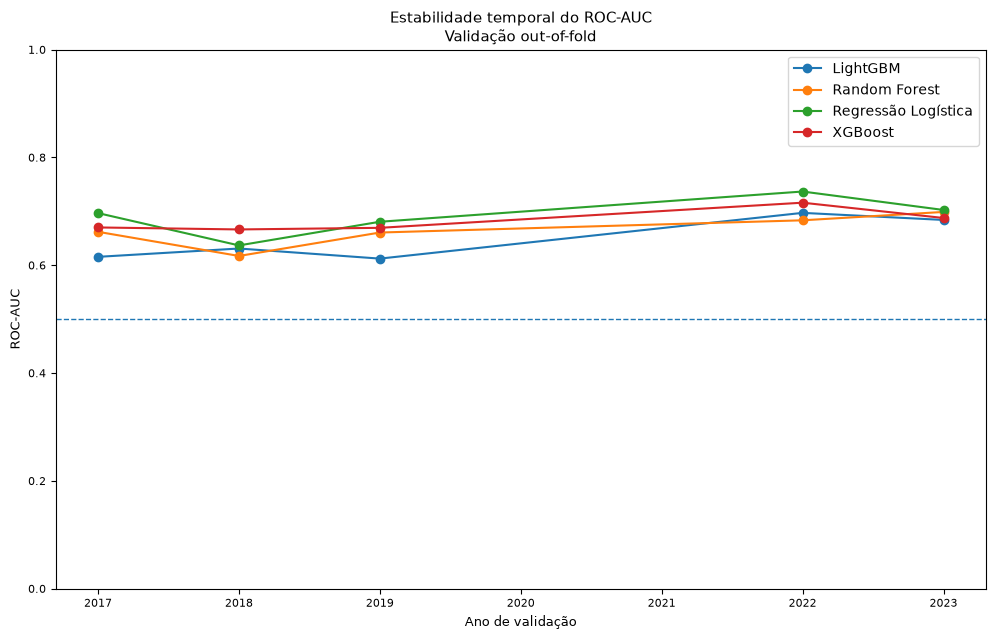

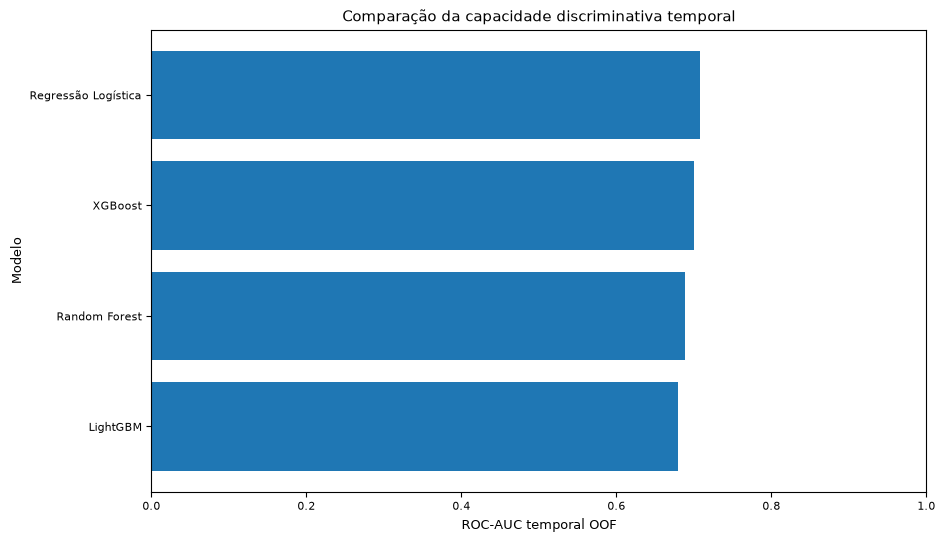


MATRIZES DE CONFUSÃO — CONTAGENS GLOBAIS OOF — THRESHOLD 0.50


MODELO,TN_050,FP_050,FN_050,TP_050
Regressão Logística,70,"1,097",44,"5,580"
XGBoost,117,"1,050",77,"5,547"
Random Forest,127,"1,040",91,"5,533"
LightGBM,138,"1,029",117,"5,507"



VALIDAÇÃO METODOLÓGICA
✓ Os quatro modelos utilizaram os mesmos folds temporais.
✓ Todo o pipeline foi reajustado dentro de cada fold.
✓ Nenhuma observação de validação participou do treinamento do respectivo fold.
✓ As probabilidades OOF foram geradas apenas para períodos posteriores ao treinamento.
✓ 2024 não foi utilizado nesta comparação.
✓ 2025 não foi utilizado nesta comparação.
✓ Nenhum balanceamento artificial foi aplicado.
✓ Nenhum threshold foi otimizado nesta etapa.
✓ ROC-AUC e PR-AUC foram usadas como métricas principais de discriminação.

Bloco 29 concluído com sucesso.


In [36]:
# ============================================================
# BLOCO 29 — COMPARAÇÃO TEMPORAL OOF DOS QUATRO MODELOS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


print('=' * 82)
print('COMPARAÇÃO TEMPORAL OUT-OF-FOLD DOS QUATRO MODELOS')
print('=' * 82)


# ============================================================
# 1. Recuperação dos quatro modelos
# ============================================================

# O dicionário modelos_treinados foi criado no Bloco 25.
# Ele contém exatamente os quatro modelos já definidos.

if 'modelos_treinados' not in globals():
    raise NameError(
        "O objeto 'modelos_treinados' não foi encontrado. "
        "Execute novamente o Bloco 25 antes deste bloco."
    )


modelos_oof = modelos_treinados.copy()


print('\nModelos incluídos:')

for nome in modelos_oof:
    print(f'✓ {nome}')


# Validação dos nomes esperados

modelos_esperados = {
    'Regressão Logística',
    'Random Forest',
    'XGBoost',
    'LightGBM'
}


if set(modelos_oof.keys()) != modelos_esperados:
    raise ValueError(
        'Os modelos disponíveis não correspondem '
        'aos quatro modelos esperados.'
    )


print('\n✓ Os quatro modelos foram recuperados com sucesso.')


# ============================================================
# 2. Recuperação dos anos do conjunto de desenvolvimento
# ============================================================

anos_dev_29 = (
    df_modelagem_final
    .loc[X_dev.index, 'NU_ANO']
    .astype(int)
)


# Verificações de alinhamento

assert X_dev.index.equals(y_dev.index)

assert X_dev.index.equals(
    anos_dev_29.index
)


anos_disponiveis_29 = sorted(
    anos_dev_29
    .unique()
    .tolist()
)


print('\nAnos disponíveis no desenvolvimento:')

print(
    anos_disponiveis_29
)


# ============================================================
# 3. Definição dos folds temporais
# ============================================================

# Mantemos a mesma lógica do Bloco 28:
#
# primeiros três anos -> janela inicial
#
# 2014–2016 -> 2017
# 2014–2017 -> 2018
# 2014–2018 -> 2019
# 2014–2019 -> 2022
# 2014–2022 -> 2023


if len(anos_disponiveis_29) < 4:

    raise ValueError(
        'Número insuficiente de anos para '
        'validação temporal.'
    )


anos_validacao_29 = (
    anos_disponiveis_29[3:]
)


print('\nFolds temporais utilizados:')


for ano_val in anos_validacao_29:

    anos_treino_fold = [
        ano
        for ano in anos_disponiveis_29
        if ano < ano_val
    ]

    print(
        f'✓ Treino: {anos_treino_fold} '
        f'-> validação: {ano_val}'
    )


# ============================================================
# 4. Estruturas de armazenamento
# ============================================================

resultados_globais = []

resultados_por_fold = []

probabilidades_oof_modelos = {}


# ============================================================
# 5. Loop pelos quatro modelos
# ============================================================

for nome_modelo, pipeline_original in modelos_oof.items():

    print('\n' + '=' * 82)

    print(
        f'MODELO: {nome_modelo.upper()}'
    )

    print('=' * 82)


    # --------------------------------------------------------
    # Série para armazenar probabilidades OOF
    # --------------------------------------------------------

    prob_oof_modelo = pd.Series(
        data=np.nan,
        index=X_dev.index,
        dtype=float,
        name=f'PROB_OOF_{nome_modelo}'
    )


    # --------------------------------------------------------
    # Loop pelos folds temporais
    # --------------------------------------------------------

    for numero_fold, ano_val in enumerate(
        anos_validacao_29,
        start=1
    ):

        # ----------------------------------------------------
        # Máscaras de treino e validação
        # ----------------------------------------------------

        mask_treino = (
            anos_dev_29 < ano_val
        )

        mask_validacao = (
            anos_dev_29 == ano_val
        )


        # ----------------------------------------------------
        # Dados do fold
        # ----------------------------------------------------

        X_train_fold = X_dev.loc[
            mask_treino
        ]

        y_train_fold = y_dev.loc[
            mask_treino
        ]

        X_val_fold = X_dev.loc[
            mask_validacao
        ]

        y_val_fold = y_dev.loc[
            mask_validacao
        ]


        # ----------------------------------------------------
        # Verificações temporais
        # ----------------------------------------------------

        ano_max_treino = int(
            anos_dev_29
            .loc[mask_treino]
            .max()
        )

        ano_validacao = int(
            anos_dev_29
            .loc[mask_validacao]
            .min()
        )


        assert (
            ano_max_treino
            <
            ano_validacao
        )


        assert len(
            X_train_fold
            .index
            .intersection(
                X_val_fold.index
            )
        ) == 0


        if y_train_fold.nunique() < 2:

            raise ValueError(
                f'{nome_modelo} — fold {numero_fold}: '
                'treinamento contém apenas uma classe.'
            )


        # ----------------------------------------------------
        # Clone completo do pipeline
        # ----------------------------------------------------

        modelo_fold = clone(
            pipeline_original
        )


        # ----------------------------------------------------
        # Ajuste apenas no passado
        # ----------------------------------------------------

        modelo_fold.fit(
            X_train_fold,
            y_train_fold
        )


        # ----------------------------------------------------
        # Probabilidades no período futuro
        # ----------------------------------------------------

        prob_val = (
            modelo_fold
            .predict_proba(
                X_val_fold
            )[:, 1]
        )


        # ----------------------------------------------------
        # Armazenamento OOF
        # ----------------------------------------------------

        prob_oof_modelo.loc[
            X_val_fold.index
        ] = prob_val


        # ----------------------------------------------------
        # Métricas probabilísticas por fold
        # ----------------------------------------------------

        if y_val_fold.nunique() == 2:

            roc_fold = roc_auc_score(
                y_val_fold,
                prob_val
            )

            pr_fold = average_precision_score(
                y_val_fold,
                prob_val
            )

        else:

            roc_fold = np.nan
            pr_fold = np.nan


        # ----------------------------------------------------
        # Threshold convencional 0.50
        # ----------------------------------------------------

        pred_val_050 = (
            prob_val >= 0.50
        ).astype(int)


        cm_fold = confusion_matrix(
            y_val_fold,
            pred_val_050,
            labels=[0, 1]
        )


        tn, fp, fn, tp = (
            cm_fold.ravel()
        )


        sens_fold = recall_score(
            y_val_fold,
            pred_val_050,
            pos_label=1,
            zero_division=0
        )


        especificidade_fold = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        )


        precisao_fold = precision_score(
            y_val_fold,
            pred_val_050,
            pos_label=1,
            zero_division=0
        )


        f1_fold = f1_score(
            y_val_fold,
            pred_val_050,
            pos_label=1,
            zero_division=0
        )


        acuracia_fold = accuracy_score(
            y_val_fold,
            pred_val_050
        )


        ba_fold = balanced_accuracy_score(
            y_val_fold,
            pred_val_050
        )


        # ----------------------------------------------------
        # Registro do fold
        # ----------------------------------------------------

        resultados_por_fold.append(
            {
                'MODELO': nome_modelo,
                'FOLD': numero_fold,
                'TREINO_ATE': ano_max_treino,
                'ANO_VALIDACAO': ano_validacao,
                'N_VALIDACAO':
                    len(y_val_fold),
                'PREVALENCIA_DESFAVORAVEL':
                    y_val_fold.mean(),
                'ROC_AUC':
                    roc_fold,
                'PR_AUC':
                    pr_fold,
                'SENSIBILIDADE_050':
                    sens_fold,
                'ESPECIFICIDADE_050':
                    especificidade_fold,
                'PRECISAO_050':
                    precisao_fold,
                'F1_050':
                    f1_fold,
                'ACURACIA_050':
                    acuracia_fold,
                'BALANCED_ACCURACY_050':
                    ba_fold
            }
        )


        print(
            f'✓ Fold {numero_fold}: '
            f'treino até {ano_max_treino} '
            f'-> validação {ano_validacao} | '
            f'N validação = {len(y_val_fold):,} | '
            f'ROC-AUC = {roc_fold:.3f} | '
            f'PR-AUC = {pr_fold:.3f}'
        )


    # ========================================================
    # 6. Probabilidades OOF válidas
    # ========================================================

    mask_oof_modelo = (
        prob_oof_modelo.notna()
    )


    y_oof_modelo = (
        y_dev
        .loc[mask_oof_modelo]
        .astype(int)
    )


    prob_validas = (
        prob_oof_modelo
        .loc[mask_oof_modelo]
        .astype(float)
    )


    probabilidades_oof_modelos[
        nome_modelo
    ] = prob_oof_modelo


    # ========================================================
    # 7. Métricas probabilísticas globais OOF
    # ========================================================

    roc_global = roc_auc_score(
        y_oof_modelo,
        prob_validas
    )


    pr_global = average_precision_score(
        y_oof_modelo,
        prob_validas
    )


    # ========================================================
    # 8. Métricas globais no threshold 0.50
    # ========================================================

    pred_oof_050 = (
        prob_validas >= 0.50
    ).astype(int)


    cm_global = confusion_matrix(
        y_oof_modelo,
        pred_oof_050,
        labels=[0, 1]
    )


    tn, fp, fn, tp = (
        cm_global.ravel()
    )


    sens_global = recall_score(
        y_oof_modelo,
        pred_oof_050,
        pos_label=1,
        zero_division=0
    )


    especificidade_global = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


    precisao_global = precision_score(
        y_oof_modelo,
        pred_oof_050,
        pos_label=1,
        zero_division=0
    )


    f1_global = f1_score(
        y_oof_modelo,
        pred_oof_050,
        pos_label=1,
        zero_division=0
    )


    acuracia_global = accuracy_score(
        y_oof_modelo,
        pred_oof_050
    )


    ba_global = balanced_accuracy_score(
        y_oof_modelo,
        pred_oof_050
    )


    # ========================================================
    # 9. Registro global
    # ========================================================

    resultados_globais.append(
        {
            'MODELO':
                nome_modelo,

            'N_OOF':
                len(y_oof_modelo),

            'PREVALENCIA_DESFAVORAVEL':
                y_oof_modelo.mean(),

            'ROC_AUC_OOF':
                roc_global,

            'PR_AUC_OOF':
                pr_global,

            'SENSIBILIDADE_050':
                sens_global,

            'ESPECIFICIDADE_050':
                especificidade_global,

            'PRECISAO_050':
                precisao_global,

            'F1_050':
                f1_global,

            'ACURACIA_050':
                acuracia_global,

            'BALANCED_ACCURACY_050':
                ba_global,

            'TN_050':
                tn,

            'FP_050':
                fp,

            'FN_050':
                fn,

            'TP_050':
                tp
        }
    )


    print('\nResultado OOF global:')

    print(
        f'ROC-AUC .................. '
        f'{roc_global:.3f}'
    )

    print(
        f'PR-AUC ................... '
        f'{pr_global:.3f}'
    )

    print(
        f'Sensibilidade (0.50) ..... '
        f'{sens_global:.3f}'
    )

    print(
        f'Especificidade (0.50) .... '
        f'{especificidade_global:.3f}'
    )

    print(
        f'Balanced Accuracy (0.50) . '
        f'{ba_global:.3f}'
    )


# ============================================================
# 10. DataFrames finais
# ============================================================

df_comparacao_oof_modelos = pd.DataFrame(
    resultados_globais
)


df_desempenho_folds = pd.DataFrame(
    resultados_por_fold
)


# ============================================================
# 11. Ordenação principal por ROC-AUC OOF
# ============================================================

df_comparacao_oof_modelos = (
    df_comparacao_oof_modelos
    .sort_values(
        by='ROC_AUC_OOF',
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 12. Tabela principal
# ============================================================

print('\n' + '=' * 82)
print('COMPARAÇÃO GLOBAL — VALIDAÇÃO TEMPORAL OOF')
print('=' * 82)


display(
    df_comparacao_oof_modelos[
        [
            'MODELO',
            'ROC_AUC_OOF',
            'PR_AUC_OOF',
            'SENSIBILIDADE_050',
            'ESPECIFICIDADE_050',
            'PRECISAO_050',
            'F1_050',
            'ACURACIA_050',
            'BALANCED_ACCURACY_050'
        ]
    ]
    .style
    .format({
        'ROC_AUC_OOF':
            '{:.3f}',

        'PR_AUC_OOF':
            '{:.3f}',

        'SENSIBILIDADE_050':
            '{:.3f}',

        'ESPECIFICIDADE_050':
            '{:.3f}',

        'PRECISAO_050':
            '{:.3f}',

        'F1_050':
            '{:.3f}',

        'ACURACIA_050':
            '{:.3f}',

        'BALANCED_ACCURACY_050':
            '{:.3f}'
    })
    .hide(axis='index')
)


# ============================================================
# 13. Melhor modelo por ROC-AUC OOF
# ============================================================

melhor_modelo_roc = (
    df_comparacao_oof_modelos
    .iloc[0]['MODELO']
)


melhor_roc = float(
    df_comparacao_oof_modelos
    .iloc[0]['ROC_AUC_OOF']
)


print('\n' + '=' * 82)
print('MAIOR ROC-AUC TEMPORAL OOF')
print('=' * 82)

print(
    f'Modelo .............. '
    f'{melhor_modelo_roc}'
)

print(
    f'ROC-AUC OOF ......... '
    f'{melhor_roc:.3f}'
)


# ============================================================
# 14. Melhor modelo por PR-AUC OOF
# ============================================================

idx_pr = (
    df_comparacao_oof_modelos[
        'PR_AUC_OOF'
    ]
    .idxmax()
)


melhor_modelo_pr = (
    df_comparacao_oof_modelos
    .loc[
        idx_pr,
        'MODELO'
    ]
)


melhor_pr = float(
    df_comparacao_oof_modelos
    .loc[
        idx_pr,
        'PR_AUC_OOF'
    ]
)


print('\n' + '=' * 82)
print('MAIOR PR-AUC TEMPORAL OOF')
print('=' * 82)

print(
    f'Modelo .............. '
    f'{melhor_modelo_pr}'
)

print(
    f'PR-AUC OOF .......... '
    f'{melhor_pr:.3f}'
)


# ============================================================
# 15. ROC-AUC por ano de validação
# ============================================================

tabela_roc_anos = (
    df_desempenho_folds
    .pivot(
        index='ANO_VALIDACAO',
        columns='MODELO',
        values='ROC_AUC'
    )
)


print('\n' + '=' * 82)
print('ROC-AUC POR ANO DE VALIDAÇÃO')
print('=' * 82)


display(
    tabela_roc_anos
    .style
    .format('{:.3f}')
)


# ============================================================
# 16. PR-AUC por ano de validação
# ============================================================

tabela_pr_anos = (
    df_desempenho_folds
    .pivot(
        index='ANO_VALIDACAO',
        columns='MODELO',
        values='PR_AUC'
    )
)


print('\n' + '=' * 82)
print('PR-AUC POR ANO DE VALIDAÇÃO')
print('=' * 82)


display(
    tabela_pr_anos
    .style
    .format('{:.3f}')
)


# ============================================================
# 17. Gráfico — ROC-AUC por ano
# ============================================================

plt.figure(
    figsize=(12, 7)
)


for modelo in tabela_roc_anos.columns:

    plt.plot(
        tabela_roc_anos.index,
        tabela_roc_anos[modelo],
        marker='o',
        label=modelo
    )


plt.axhline(
    0.50,
    linestyle='--',
    linewidth=1
)


plt.xlabel(
    'Ano de validação'
)

plt.ylabel(
    'ROC-AUC'
)

plt.title(
    'Estabilidade temporal do ROC-AUC\n'
    'Validação out-of-fold'
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.show()


# ============================================================
# 18. Gráfico — comparação ROC-AUC global
# ============================================================

dados_plot = (
    df_comparacao_oof_modelos
    .sort_values(
        'ROC_AUC_OOF',
        ascending=True
    )
)


plt.figure(
    figsize=(10, 6)
)


plt.barh(
    dados_plot['MODELO'],
    dados_plot['ROC_AUC_OOF']
)


plt.xlabel(
    'ROC-AUC temporal OOF'
)

plt.ylabel(
    'Modelo'
)

plt.title(
    'Comparação da capacidade discriminativa temporal'
)


plt.xlim(
    0,
    1
)


plt.show()


# ============================================================
# 19. Matriz de contagens globais no threshold 0.50
# ============================================================

print('\n' + '=' * 82)
print('MATRIZES DE CONFUSÃO — CONTAGENS GLOBAIS OOF — THRESHOLD 0.50')
print('=' * 82)


display(
    df_comparacao_oof_modelos[
        [
            'MODELO',
            'TN_050',
            'FP_050',
            'FN_050',
            'TP_050'
        ]
    ]
    .style
    .format({
        'TN_050':
            '{:,.0f}',

        'FP_050':
            '{:,.0f}',

        'FN_050':
            '{:,.0f}',

        'TP_050':
            '{:,.0f}'
    })
    .hide(axis='index')
)


# ============================================================
# 20. Validações metodológicas
# ============================================================

n_oof_por_modelo = (
    df_comparacao_oof_modelos[
        'N_OOF'
    ]
    .unique()
)


assert len(
    n_oof_por_modelo
) == 1


for nome_modelo, serie_prob in (
    probabilidades_oof_modelos.items()
):

    # --------------------------------------------------------
    # Primeiros três anos não possuem previsão OOF
    # --------------------------------------------------------

    mask_inicial = (
        anos_dev_29
        .isin(
            anos_disponiveis_29[:3]
        )
    )

    assert (
        serie_prob
        .loc[mask_inicial]
        .isna()
        .all()
    )


    # --------------------------------------------------------
    # Todos os anos de validação devem possuir previsão OOF
    # --------------------------------------------------------

    mask_validacao_total = (
        anos_dev_29
        .isin(
            anos_validacao_29
        )
    )

    assert (
        serie_prob
        .loc[mask_validacao_total]
        .notna()
        .all()
    )


print('\n' + '=' * 82)
print('VALIDAÇÃO METODOLÓGICA')
print('=' * 82)

print(
    '✓ Os quatro modelos utilizaram '
    'os mesmos folds temporais.'
)

print(
    '✓ Todo o pipeline foi reajustado '
    'dentro de cada fold.'
)

print(
    '✓ Nenhuma observação de validação '
    'participou do treinamento do respectivo fold.'
)

print(
    '✓ As probabilidades OOF foram geradas '
    'apenas para períodos posteriores ao treinamento.'
)

print(
    '✓ 2024 não foi utilizado nesta comparação.'
)

print(
    '✓ 2025 não foi utilizado nesta comparação.'
)

print(
    '✓ Nenhum balanceamento artificial foi aplicado.'
)

print(
    '✓ Nenhum threshold foi otimizado nesta etapa.'
)

print(
    '✓ ROC-AUC e PR-AUC foram usadas como '
    'métricas principais de discriminação.'
)

print('\nBloco 29 concluído com sucesso.')

### Interpretação da comparação temporal out-of-fold dos modelos

A comparação temporal out-of-fold modificou a ordenação inicialmente observada
entre os algoritmos.

Quando os quatro modelos foram submetidos exatamente aos mesmos folds
temporais, utilizando apenas períodos anteriores para prever períodos
posteriores, a Regressão Logística apresentou o maior desempenho global nas
duas principais métricas probabilísticas de discriminação.

Foram obtidos:

$$
ROC\text{-}AUC_{OOF}=0{,}707
$$

e:

$$
PR\text{-}AUC_{OOF}=0{,}913
$$

para a Regressão Logística.

Esse resultado é particularmente relevante porque a comparação inicial em
2024 havia apontado o XGBoost como algoritmo de melhor desempenho global em
diversas métricas.

A mudança de ordenação demonstra que o desempenho relativo dos modelos é
sensível à estratégia de validação utilizada.

Em outras palavras:

$$
\boxed{
\text{melhor desempenho em um período específico}
\neq
\text{melhor generalização temporal interna}
}
$$

A validação out-of-fold exige que cada período seja previsto somente a partir
de informações temporalmente anteriores, aproximando-se mais do cenário de
generalização para novos períodos.

---

### Comportamento no threshold convencional

Apesar da superioridade da Regressão Logística nas métricas probabilísticas,
o threshold convencional de 0,50 apresentou comportamento fortemente
assimétrico entre as duas classes.

Para a Regressão Logística, a matriz de confusão OOF foi:

| Classe real | Previsto favorável | Previsto desfavorável |
|---|---:|---:|
| Favorável | 70 | 1.097 |
| Desfavorável | 44 | 5.580 |

Assim:

$$
TN=70
$$

$$
FP=1097
$$

$$
FN=44
$$

e:

$$
TP=5580
$$

A sensibilidade é:

$$
Sens=
\frac{TP}{TP+FN}
$$

portanto:

$$
Sens=
\frac{5580}{5580+44}
\approx0{,}992
$$

Isso indica que aproximadamente 99% dos registros com evolução desfavorável
foram corretamente identificados.

Entretanto, a especificidade foi:

$$
Esp=
\frac{TN}{TN+FP}
$$

logo:

$$
Esp=
\frac{70}{70+1097}
\approx0{,}060
$$

Portanto, apenas cerca de 6% dos registros realmente favoráveis foram
corretamente reconhecidos no threshold convencional.

Esse comportamento confirma que:

$$
\boxed{
t=0{,}50
}
$$

não constitui necessariamente uma regra de decisão adequada para este problema.

---

### Discriminação não é equivalente à classificação em threshold 0,50

A coexistência de ROC-AUC OOF de 0,707 com baixa especificidade no threshold
de 0,50 não representa uma inconsistência.

A ROC-AUC avalia a capacidade discriminativa do modelo considerando a ordenação
das probabilidades ao longo dos possíveis thresholds.

Já a matriz de confusão corresponde ao desempenho obtido em um único ponto de
corte.

Assim:

$$
\boxed{
ROC\text{-}AUC
\rightarrow
\text{qualidade da ordenação probabilística}
}
$$

enquanto:

$$
\boxed{
Sensibilidade(t),\ Esp(t)
\rightarrow
\text{desempenho em um ponto de decisão específico}
}
$$

Um modelo pode, portanto, apresentar capacidade discriminativa útil e,
simultaneamente, um threshold convencional inadequado.

---

### Comparação das matrizes de confusão

No threshold de 0,50, as contagens globais OOF foram:

| Modelo | TN | FP | FN | TP |
|---|---:|---:|---:|---:|
| Regressão Logística | 70 | 1.097 | 44 | 5.580 |
| XGBoost | 117 | 1.050 | 77 | 5.547 |
| Random Forest | 127 | 1.040 | 91 | 5.533 |
| LightGBM | 138 | 1.029 | 117 | 5.507 |

Observa-se um padrão consistente.

À medida que alguns modelos reconhecem maior quantidade de registros
favoráveis, aumentando $TN$, também ocorre aumento do número de registros
desfavoráveis classificados incorretamente como favoráveis, aumentando $FN$.

Esse comportamento representa novamente o trade-off entre sensibilidade e
especificidade.

Portanto, a comparação dos modelos não deve ser baseada exclusivamente nas
classificações obtidas com:

$$
t=0{,}50
$$

---

### Implicações para a escolha do modelo

Os resultados desta etapa impedem uma seleção precipitada do XGBoost como
modelo definitivo.

Na comparação temporal interna, a Regressão Logística apresentou a maior
ROC-AUC OOF e a maior PR-AUC OOF.

Consequentemente, neste momento a Regressão Logística passa a ser um candidato
particularmente relevante para o modelo principal.

Essa constatação possui ainda uma vantagem metodológica adicional.

A pergunta científica do estudo busca investigar características associadas à
ocorrência de evolução desfavorável.

Nesse contexto, a Regressão Logística permite posteriormente estimar
coeficientes e razões de chances ajustadas:

$$
OR_j=e^{\beta_j}
$$

possibilitando avaliar a direção e a magnitude das associações entre os
preditores e o desfecho.

Assim, caso seu desempenho temporal permaneça competitivo e estável entre os
folds, a Regressão Logística poderá cumprir simultaneamente duas funções:

$$
\boxed{
\text{predição temporal}
}
$$

e:

$$
\boxed{
\text{interpretação das associações}
}
$$

Os modelos baseados em árvores permanecem relevantes como comparadores
preditivos e para investigação de relações não lineares.

A seleção final, entretanto, ainda deve considerar a estabilidade das métricas
ao longo dos diferentes anos de validação, e não apenas seus valores globais
agregados.

ESTABILIDADE TEMPORAL DOS MODELOS — VALIDAÇÃO OOF

ROC-AUC POR ANO DE VALIDAÇÃO


MODELO,LightGBM,Random Forest,Regressão Logística,XGBoost
ANO_VALIDACAO,,,,
2017,0.616,0.662,0.697,0.670
2018,0.631,0.617,0.637,0.666
2019,0.612,0.661,0.681,0.669
2022,0.697,0.683,0.737,0.716
2023,0.684,0.699,0.702,0.688



PR-AUC POR ANO DE VALIDAÇÃO


MODELO,LightGBM,Random Forest,Regressão Logística,XGBoost
ANO_VALIDACAO,,,,
2017,0.936,0.941,0.952,0.946
2018,0.930,0.923,0.922,0.930
2019,0.895,0.915,0.917,0.919
2022,0.891,0.885,0.914,0.898
2023,0.872,0.879,0.873,0.873



RESUMO DA ESTABILIDADE TEMPORAL


MODELO,ROC_AUC_OOF,ROC_MEDIA,ROC_DESVIO,ROC_MIN,ROC_MAX,ROC_AMPLITUDE,PR_AUC_OOF,PR_MEDIA,PR_DESVIO,VITORIAS_ROC
Regressão Logística,0.707,0.691,0.036,0.637,0.737,0.100,0.913,0.916,0.028,4
XGBoost,0.700,0.682,0.021,0.666,0.716,0.050,0.912,0.913,0.029,1
Random Forest,0.688,0.664,0.031,0.617,0.699,0.082,0.907,0.908,0.026,0
LightGBM,0.680,0.648,0.040,0.612,0.697,0.085,0.906,0.905,0.027,0



MAIOR ROC-AUC EM CADA ANO DE VALIDAÇÃO


ANO_VALIDACAO,MODELO,ROC_AUC
2017,Regressão Logística,0.697
2018,XGBoost,0.666
2019,Regressão Logística,0.681
2022,Regressão Logística,0.737
2023,Regressão Logística,0.702


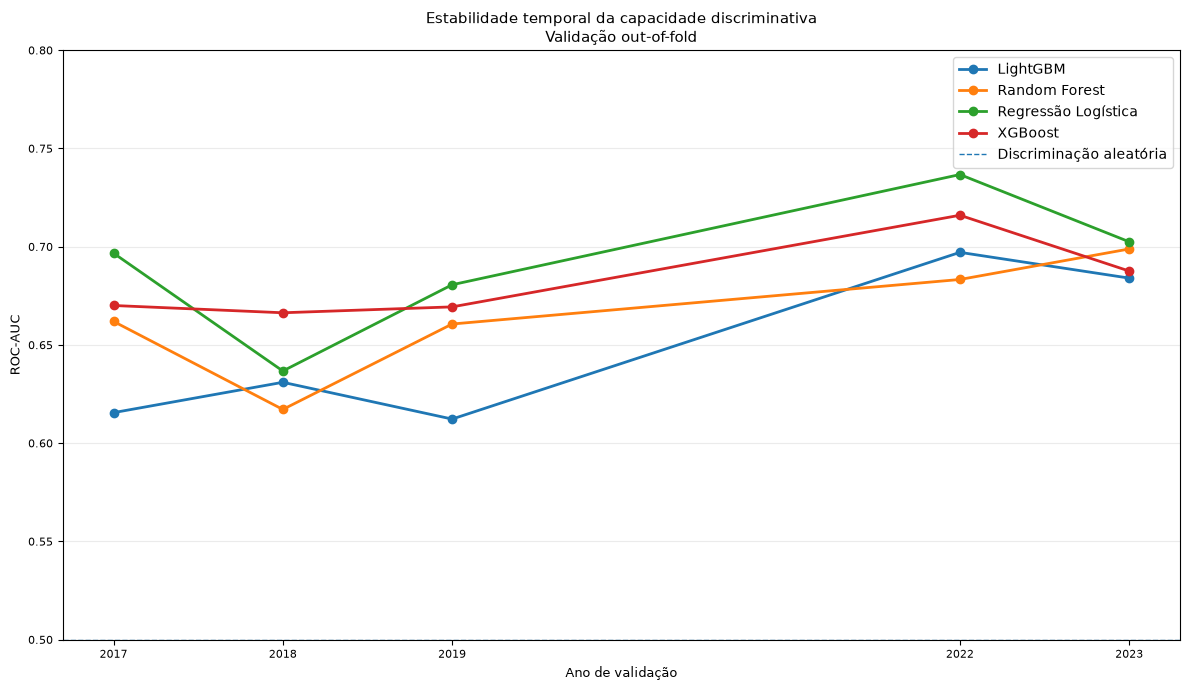

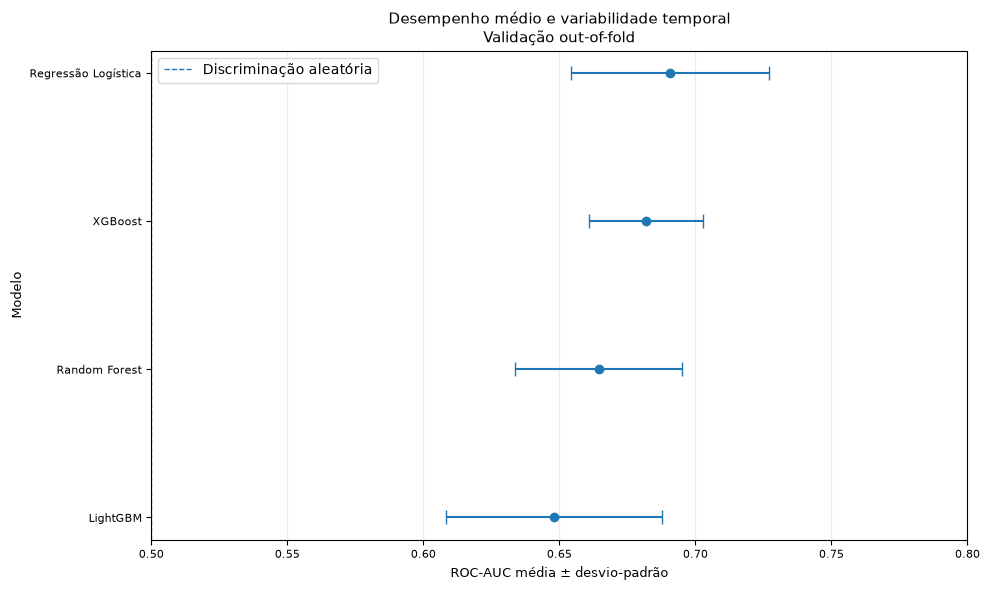


LÍDER SEGUNDO ROC-AUC OOF GLOBAL
Modelo .................... Regressão Logística
ROC-AUC OOF global ........ 0.707
ROC-AUC média temporal .... 0.691
Desvio-padrão temporal .... 0.036
Menor ROC-AUC anual ....... 0.637
Maior ROC-AUC anual ....... 0.737
Amplitude temporal ........ 0.100
Vitórias anuais ........... 4

COMPARAÇÃO DIRETA — REGRESSÃO LOGÍSTICA × XGBOOST


MODELO,ROC_AUC_OOF,ROC_MEDIA,ROC_DESVIO,ROC_MIN,ROC_MAX,ROC_AMPLITUDE,PR_AUC_OOF,VITORIAS_ROC
Regressão Logística,0.707,0.691,0.036,0.637,0.737,0.100,0.913,4
XGBoost,0.700,0.682,0.021,0.666,0.716,0.050,0.912,1



VALIDAÇÃO METODOLÓGICA
✓ Quatro modelos avaliados.
✓ Cinco períodos de validação temporal avaliados.
✓ Anos avaliados: 2017, 2018, 2019, 2022 e 2023.
✓ 2020 e 2021 não foram introduzidos artificialmente na análise.
✓ O eixo temporal apresenta somente os anos efetivamente avaliados.
✓ Não houve novo treinamento de modelos.
✓ Não houve otimização de threshold.
✓ 2024 não foi utilizado nesta análise.
✓ 2025 não foi utilizado nesta análise.
✓ A estabilidade foi calculada a partir das previsões temporais OOF do Bloco 29.

Bloco 30 concluído com sucesso.


In [37]:
# ============================================================
# BLOCO 30 — ESTABILIDADE TEMPORAL DOS QUATRO MODELOS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


print('=' * 82)
print('ESTABILIDADE TEMPORAL DOS MODELOS — VALIDAÇÃO OOF')
print('=' * 82)


# ============================================================
# 1. VERIFICAÇÃO DOS OBJETOS NECESSÁRIOS
# ============================================================

if 'df_desempenho_folds' not in globals():
    raise NameError(
        "O objeto 'df_desempenho_folds' não foi encontrado. "
        "Execute o Bloco 29 antes deste bloco."
    )

if 'df_comparacao_oof_modelos' not in globals():
    raise NameError(
        "O objeto 'df_comparacao_oof_modelos' não foi encontrado. "
        "Execute o Bloco 29 antes deste bloco."
    )


colunas_necessarias = {
    'MODELO',
    'ANO_VALIDACAO',
    'ROC_AUC',
    'PR_AUC'
}


if not colunas_necessarias.issubset(
    df_desempenho_folds.columns
):
    raise ValueError(
        'df_desempenho_folds não contém todas as '
        'colunas necessárias.'
    )


# ============================================================
# 2. ROC-AUC POR ANO
# ============================================================

roc_por_ano = (
    df_desempenho_folds
    .pivot(
        index='ANO_VALIDACAO',
        columns='MODELO',
        values='ROC_AUC'
    )
    .sort_index()
)


print('\n' + '=' * 82)
print('ROC-AUC POR ANO DE VALIDAÇÃO')
print('=' * 82)


display(
    roc_por_ano
    .style
    .format('{:.3f}')
)


# ============================================================
# 3. PR-AUC POR ANO
# ============================================================

pr_por_ano = (
    df_desempenho_folds
    .pivot(
        index='ANO_VALIDACAO',
        columns='MODELO',
        values='PR_AUC'
    )
    .sort_index()
)


print('\n' + '=' * 82)
print('PR-AUC POR ANO DE VALIDAÇÃO')
print('=' * 82)


display(
    pr_por_ano
    .style
    .format('{:.3f}')
)


# ============================================================
# 4. ESTATÍSTICAS DE ESTABILIDADE TEMPORAL
# ============================================================

estabilidade = (
    df_desempenho_folds
    .groupby('MODELO')
    .agg(
        ROC_MEDIA=('ROC_AUC', 'mean'),
        ROC_DESVIO=('ROC_AUC', 'std'),
        ROC_MIN=('ROC_AUC', 'min'),
        ROC_MAX=('ROC_AUC', 'max'),

        PR_MEDIA=('PR_AUC', 'mean'),
        PR_DESVIO=('PR_AUC', 'std'),
        PR_MIN=('PR_AUC', 'min'),
        PR_MAX=('PR_AUC', 'max'),

        N_PERIODOS=('ANO_VALIDACAO', 'nunique')
    )
    .reset_index()
)


# ============================================================
# 5. AMPLITUDES TEMPORAIS
# ============================================================

estabilidade['ROC_AMPLITUDE'] = (
    estabilidade['ROC_MAX']
    -
    estabilidade['ROC_MIN']
)


estabilidade['PR_AMPLITUDE'] = (
    estabilidade['PR_MAX']
    -
    estabilidade['PR_MIN']
)


# ============================================================
# 6. MODELO COM MAIOR ROC-AUC EM CADA ANO
# ============================================================

vencedores_roc = []


for ano in roc_por_ano.index:

    valores_ano = (
        roc_por_ano
        .loc[ano]
        .dropna()
    )

    maior_valor = (
        valores_ano.max()
    )

    vencedores = (
        valores_ano[
            np.isclose(
                valores_ano,
                maior_valor
            )
        ]
        .index
        .tolist()
    )

    for modelo in vencedores:

        vencedores_roc.append(
            {
                'ANO_VALIDACAO': ano,
                'MODELO': modelo,
                'ROC_AUC': maior_valor
            }
        )


df_vencedores_roc = pd.DataFrame(
    vencedores_roc
)


# ============================================================
# 7. CONTAGEM DE VITÓRIAS TEMPORAIS
# ============================================================

contagem_vitorias = (
    df_vencedores_roc
    .groupby('MODELO')
    .size()
    .rename('VITORIAS_ROC')
    .reset_index()
)


estabilidade = (
    estabilidade
    .merge(
        contagem_vitorias,
        on='MODELO',
        how='left'
    )
)


estabilidade['VITORIAS_ROC'] = (
    estabilidade['VITORIAS_ROC']
    .fillna(0)
    .astype(int)
)


# ============================================================
# 8. MÉTRICAS OOF GLOBAIS DO BLOCO 29
# ============================================================

metricas_globais = (
    df_comparacao_oof_modelos[
        [
            'MODELO',
            'ROC_AUC_OOF',
            'PR_AUC_OOF'
        ]
    ]
    .copy()
)


estabilidade = (
    estabilidade
    .merge(
        metricas_globais,
        on='MODELO',
        how='left'
    )
)


# ============================================================
# 9. ORDENAÇÃO DOS MODELOS
# ============================================================

estabilidade = (
    estabilidade
    .sort_values(
        [
            'ROC_AUC_OOF',
            'ROC_MEDIA'
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# 10. RESUMO DA ESTABILIDADE TEMPORAL
# ============================================================

print('\n' + '=' * 82)
print('RESUMO DA ESTABILIDADE TEMPORAL')
print('=' * 82)


display(
    estabilidade[
        [
            'MODELO',
            'ROC_AUC_OOF',
            'ROC_MEDIA',
            'ROC_DESVIO',
            'ROC_MIN',
            'ROC_MAX',
            'ROC_AMPLITUDE',
            'PR_AUC_OOF',
            'PR_MEDIA',
            'PR_DESVIO',
            'VITORIAS_ROC'
        ]
    ]
    .style
    .format({
        'ROC_AUC_OOF': '{:.3f}',
        'ROC_MEDIA': '{:.3f}',
        'ROC_DESVIO': '{:.3f}',
        'ROC_MIN': '{:.3f}',
        'ROC_MAX': '{:.3f}',
        'ROC_AMPLITUDE': '{:.3f}',
        'PR_AUC_OOF': '{:.3f}',
        'PR_MEDIA': '{:.3f}',
        'PR_DESVIO': '{:.3f}'
    })
    .hide(axis='index')
)


# ============================================================
# 11. MAIOR ROC-AUC EM CADA ANO
# ============================================================

print('\n' + '=' * 82)
print('MAIOR ROC-AUC EM CADA ANO DE VALIDAÇÃO')
print('=' * 82)


display(
    df_vencedores_roc
    .sort_values(
        'ANO_VALIDACAO'
    )
    .style
    .format({
        'ROC_AUC': '{:.3f}'
    })
    .hide(axis='index')
)


# ============================================================
# 12. GRÁFICO — ESTABILIDADE TEMPORAL DO ROC-AUC
# ============================================================

plt.figure(figsize=(12, 7))


for modelo in roc_por_ano.columns:

    plt.plot(
        roc_por_ano.index,
        roc_por_ano[modelo],
        marker='o',
        linewidth=2,
        label=modelo
    )


# Linha de referência:
# ROC-AUC = 0.50 corresponde à discriminação aleatória

plt.axhline(
    y=0.50,
    linestyle='--',
    linewidth=1,
    label='Discriminação aleatória'
)


# IMPORTANTE:
# mostrar somente os anos efetivamente disponíveis.
#
# 2020 e 2021 não aparecem porque não existem
# observações disponíveis desses anos na base.

plt.xticks(
    roc_por_ano.index
)


plt.xlabel(
    'Ano de validação'
)

plt.ylabel(
    'ROC-AUC'
)

plt.title(
    'Estabilidade temporal da capacidade discriminativa\n'
    'Validação out-of-fold'
)


# Como todos os valores estão acima de 0.60,
# utilizamos uma escala mais informativa para visualizar
# as diferenças entre os modelos.

plt.ylim(
    0.50,
    0.80
)


plt.legend()


plt.grid(
    axis='y',
    alpha=0.25
)


plt.tight_layout()

plt.show()


# ============================================================
# 13. GRÁFICO — ROC-AUC MÉDIA E VARIABILIDADE
# ============================================================

dados_estabilidade_plot = (
    estabilidade
    .sort_values(
        'ROC_MEDIA',
        ascending=True
    )
)


plt.figure(
    figsize=(10, 6)
)


plt.errorbar(
    dados_estabilidade_plot[
        'ROC_MEDIA'
    ],
    dados_estabilidade_plot[
        'MODELO'
    ],
    xerr=dados_estabilidade_plot[
        'ROC_DESVIO'
    ],
    fmt='o',
    capsize=5
)


plt.axvline(
    x=0.50,
    linestyle='--',
    linewidth=1,
    label='Discriminação aleatória'
)


plt.xlabel(
    'ROC-AUC média ± desvio-padrão'
)

plt.ylabel(
    'Modelo'
)

plt.title(
    'Desempenho médio e variabilidade temporal\n'
    'Validação out-of-fold'
)


plt.xlim(
    0.50,
    0.80
)


plt.grid(
    axis='x',
    alpha=0.25
)


plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 14. IDENTIFICAÇÃO DO LÍDER GLOBAL
# ============================================================

lider_global = (
    estabilidade
    .iloc[0]
)


print('\n' + '=' * 82)
print('LÍDER SEGUNDO ROC-AUC OOF GLOBAL')
print('=' * 82)


print(
    f'Modelo .................... '
    f'{lider_global["MODELO"]}'
)


print(
    f'ROC-AUC OOF global ........ '
    f'{lider_global["ROC_AUC_OOF"]:.3f}'
)


print(
    f'ROC-AUC média temporal .... '
    f'{lider_global["ROC_MEDIA"]:.3f}'
)


print(
    f'Desvio-padrão temporal .... '
    f'{lider_global["ROC_DESVIO"]:.3f}'
)


print(
    f'Menor ROC-AUC anual ....... '
    f'{lider_global["ROC_MIN"]:.3f}'
)


print(
    f'Maior ROC-AUC anual ....... '
    f'{lider_global["ROC_MAX"]:.3f}'
)


print(
    f'Amplitude temporal ........ '
    f'{lider_global["ROC_AMPLITUDE"]:.3f}'
)


print(
    f'Vitórias anuais ........... '
    f'{lider_global["VITORIAS_ROC"]}'
)


# ============================================================
# 15. COMPARAÇÃO DIRETA: LOGÍSTICA × XGBOOST
# ============================================================

comparacao_lr_xgb = (
    estabilidade[
        estabilidade['MODELO'].isin(
            [
                'Regressão Logística',
                'XGBoost'
            ]
        )
    ][
        [
            'MODELO',
            'ROC_AUC_OOF',
            'ROC_MEDIA',
            'ROC_DESVIO',
            'ROC_MIN',
            'ROC_MAX',
            'ROC_AMPLITUDE',
            'PR_AUC_OOF',
            'VITORIAS_ROC'
        ]
    ]
    .copy()
)


print('\n' + '=' * 82)
print('COMPARAÇÃO DIRETA — REGRESSÃO LOGÍSTICA × XGBOOST')
print('=' * 82)


display(
    comparacao_lr_xgb
    .style
    .format({
        'ROC_AUC_OOF': '{:.3f}',
        'ROC_MEDIA': '{:.3f}',
        'ROC_DESVIO': '{:.3f}',
        'ROC_MIN': '{:.3f}',
        'ROC_MAX': '{:.3f}',
        'ROC_AMPLITUDE': '{:.3f}',
        'PR_AUC_OOF': '{:.3f}'
    })
    .hide(axis='index')
)


# ============================================================
# 16. VALIDAÇÕES FINAIS
# ============================================================

n_modelos = (
    estabilidade[
        'MODELO'
    ]
    .nunique()
)


n_periodos = (
    df_desempenho_folds[
        'ANO_VALIDACAO'
    ]
    .nunique()
)


assert n_modelos == 4

assert n_periodos == 5


# Os únicos anos de validação esperados são:
# 2017, 2018, 2019, 2022 e 2023.

assert set(
    roc_por_ano.index.tolist()
) == {
    2017,
    2018,
    2019,
    2022,
    2023
}


# Garantia explícita de que 2020 e 2021
# não foram introduzidos artificialmente.

assert 2020 not in roc_por_ano.index

assert 2021 not in roc_por_ano.index


print('\n' + '=' * 82)
print('VALIDAÇÃO METODOLÓGICA')
print('=' * 82)


print(
    '✓ Quatro modelos avaliados.'
)

print(
    '✓ Cinco períodos de validação temporal avaliados.'
)

print(
    '✓ Anos avaliados: 2017, 2018, 2019, 2022 e 2023.'
)

print(
    '✓ 2020 e 2021 não foram introduzidos '
    'artificialmente na análise.'
)

print(
    '✓ O eixo temporal apresenta somente '
    'os anos efetivamente avaliados.'
)

print(
    '✓ Não houve novo treinamento de modelos.'
)

print(
    '✓ Não houve otimização de threshold.'
)

print(
    '✓ 2024 não foi utilizado nesta análise.'
)

print(
    '✓ 2025 não foi utilizado nesta análise.'
)

print(
    '✓ A estabilidade foi calculada a partir '
    'das previsões temporais OOF do Bloco 29.'
)


print(
    '\nBloco 30 concluído com sucesso.'
)

## BLOCO 31 — Seleção temporal do threshold da Regressão Logística

Após a comparação dos quatro algoritmos por validação temporal out-of-fold,
a Regressão Logística foi selecionada como modelo principal.

A escolha foi baseada no conjunto das evidências obtidas durante a validação
temporal interna. A Regressão Logística apresentou:

$$
ROC\text{-}AUC_{OOF}=0{,}707
$$

$$
PR\text{-}AUC_{OOF}=0{,}913
$$

e a maior ROC-AUC em quatro dos cinco anos utilizados como validação temporal.

A ROC-AUC média entre os períodos foi:

$$
\overline{ROC\text{-}AUC}=0{,}691
$$

com desvio-padrão:

$$
DP=0{,}036
$$

O XGBoost apresentou desempenho próximo e menor variabilidade temporal, mas a
Regressão Logística apresentou maior desempenho discriminativo agregado e
predominância na comparação entre os anos.

Além disso, sua interpretabilidade é particularmente adequada à pergunta
científica deste estudo, que busca investigar características associadas à
evolução desfavorável.

---

### Por que selecionar um threshold?

A Regressão Logística não produz originalmente uma classificação binária.

Para cada observação $i$, o modelo estima:

$$
\hat p_i=P(Y_i=1\mid X_i)
$$

onde:

$$
Y=1
$$

representa evolução desfavorável e:

$$
Y=0
$$

representa evolução favorável.

Para converter essa probabilidade em uma classificação é necessário definir um
threshold $t$:

$$
\hat Y_i(t)=
\begin{cases}
1, & \hat p_i\geq t\\
0, & \hat p_i<t
\end{cases}
$$

O valor:

$$
t=0{,}50
$$

é frequentemente utilizado como padrão, mas não existe garantia de que ele
seja adequado para todos os problemas.

---

### Problema observado com o threshold 0,50

Na validação temporal OOF da Regressão Logística, o threshold convencional
produziu:

$$
TN=70
$$

$$
FP=1097
$$

$$
FN=44
$$

$$
TP=5580
$$

A sensibilidade correspondente foi aproximadamente:

$$
Sensibilidade=
\frac{5580}{5580+44}
\approx0{,}992
$$

enquanto a especificidade foi:

$$
Especificidade=
\frac{70}{70+1097}
\approx0{,}060
$$

Portanto, o threshold de 0,50 classificou corretamente quase todos os registros
com evolução desfavorável, mas apresentou capacidade muito baixa de reconhecer
os registros com evolução favorável.

Esse comportamento é compatível com a elevada prevalência da classe positiva
no conjunto OOF.

---

### Threshold é diferente de capacidade discriminativa

A baixa especificidade observada em $t=0{,}50$ não contradiz a ROC-AUC OOF de
0,707.

Essas métricas avaliam propriedades diferentes.

A ROC-AUC considera a ordenação das probabilidades ao longo dos possíveis
thresholds:

$$
ROC\text{-}AUC
\rightarrow
\text{capacidade discriminativa}
$$

enquanto sensibilidade e especificidade dependem de uma regra de decisão
específica:

$$
Sensibilidade(t),\ Especificidade(t)
\rightarrow
\text{classificação no threshold }t
$$

Consequentemente, um modelo pode apresentar capacidade discriminativa útil e,
simultaneamente, comportamento inadequado no threshold convencional.

---

### Critério para seleção do threshold

Neste estudo será utilizado como critério principal o máximo da
Balanced Accuracy:

$$
BA(t)=
\frac{
Sensibilidade(t)+Especificidade(t)
}{2}
$$

A Balanced Accuracy atribui igual importância ao desempenho nas duas classes,
independentemente da diferença de prevalência entre elas.

Também será calculado o índice de Youden:

$$
J(t)=
Sensibilidade(t)+Especificidade(t)-1
$$

Como:

$$
J(t)=2BA(t)-1
$$

os dois critérios devem selecionar o mesmo threshold quando calculados sobre
as mesmas previsões.

O threshold selecionado será denominado:

$$
\boxed{
t^*_{LR,OOF}
}
$$

---

### O threshold do XGBoost não será reutilizado

Anteriormente foi identificado um threshold temporal para o XGBoost próximo
de:

$$
t^*_{XGB,OOF}=0{,}91
$$

Esse valor não pode ser transferido para a Regressão Logística.

Os algoritmos produzem distribuições de probabilidades diferentes e,
consequentemente:

$$
t^*_{XGB}
\neq
t^*_{LR}
$$

necessariamente.

O novo threshold será estimado exclusivamente a partir das probabilidades OOF
da Regressão Logística.

---

### Preservação temporal

As probabilidades utilizadas neste bloco foram produzidas nos folds:

$$
2014\text{--}2016\rightarrow2017
$$

$$
2014\text{--}2017\rightarrow2018
$$

$$
2014\text{--}2018\rightarrow2019
$$

$$
2014\text{--}2019\rightarrow2022
$$

$$
2014\text{--}2022\rightarrow2023
$$

Os anos de 2020 e 2021 não possuem observações disponíveis na base e não foram
artificialmente imputados ou tratados como anos com zero registros.

Nenhuma observação de 2024 ou 2025 será utilizada para determinar o threshold.

Assim:

$$
2014\text{--}2023
\rightarrow
\text{seleção interna}
$$

enquanto:

$$
2024
\rightarrow
\text{validação temporal posterior}
$$

e:

$$
2025
\rightarrow
\text{avaliação temporal complementar}
$$

---

### Limitação da seleção do threshold

Embora cada probabilidade OOF tenha sido produzida por um modelo que não
utilizou a própria observação em seu treinamento, o threshold será escolhido
pela maximização da Balanced Accuracy sobre o conjunto agregado dessas
previsões OOF.

Portanto, o desempenho observado no próprio threshold selecionado constitui
uma estimativa interna utilizada para seleção da regra de decisão.

Ele não será interpretado como desempenho final completamente independente.

O objetivo deste bloco é definir uma regra de classificação que possa ser
posteriormente aplicada, sem nova otimização, aos períodos temporais
subsequentes.

SELEÇÃO DO THRESHOLD OOF — REGRESSÃO LOGÍSTICA

Observações com previsão OOF: 6,791
Favoráveis ................: 1,167
Desfavoráveis .............: 5,624
Prevalência desfavorável ..: 82.82%

THRESHOLD OOF SELECIONADO
Threshold ................. 0.88
Sensibilidade ............. 0.682
Especificidade ............ 0.621
Precisão .................. 0.897
F1 ........................ 0.775
Acurácia .................. 0.672
Balanced Accuracy ......... 0.652
Youden J .................. 0.304
TN ........................ 725
FP ........................ 442
FN ........................ 1,786
TP ........................ 3,838

COMPARAÇÃO — THRESHOLD 0.50 × THRESHOLD OOF


REGRA,THRESHOLD,SENSIBILIDADE,ESPECIFICIDADE,PRECISAO,F1,ACURACIA,BALANCED_ACCURACY,YOUDEN_J,TN,FP,FN,TP
Threshold 0.50,0.50,0.992,0.060,0.836,0.907,0.832,0.526,0.052,70,"1,097",44,"5,580"
Threshold OOF selecionado,0.88,0.682,0.621,0.897,0.775,0.672,0.652,0.304,725,442,"1,786","3,838"


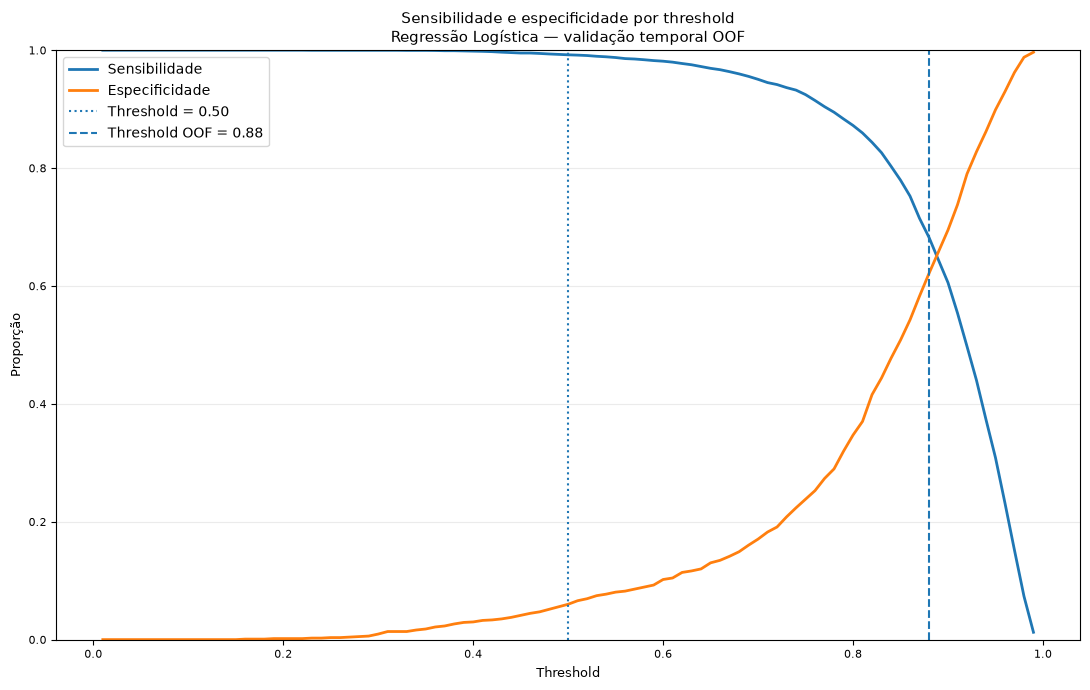

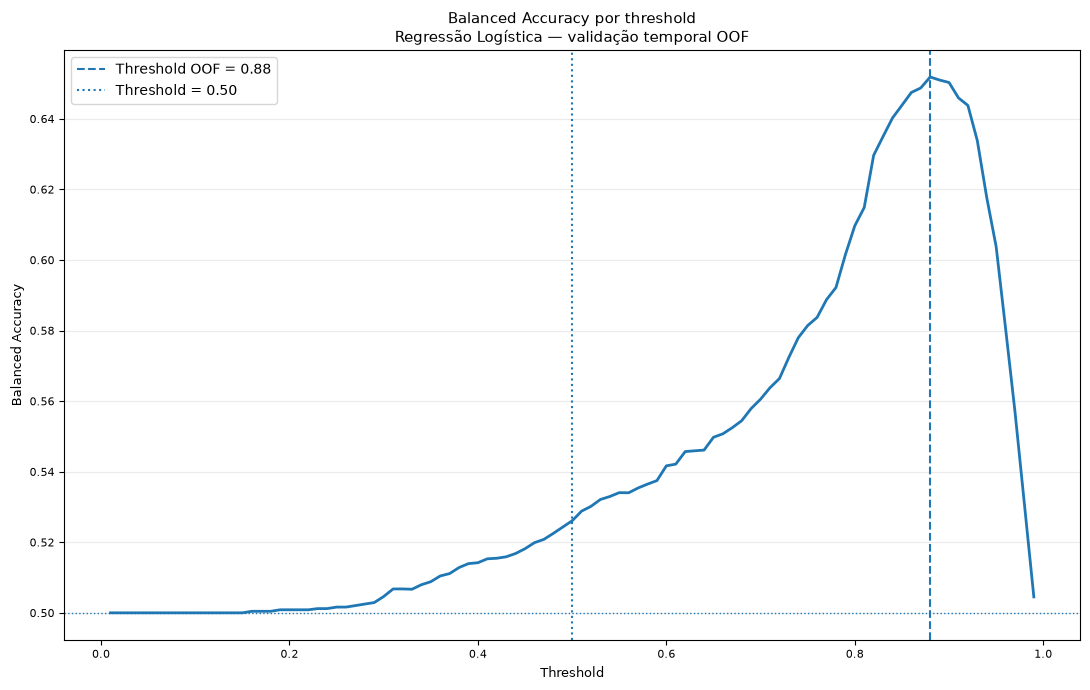

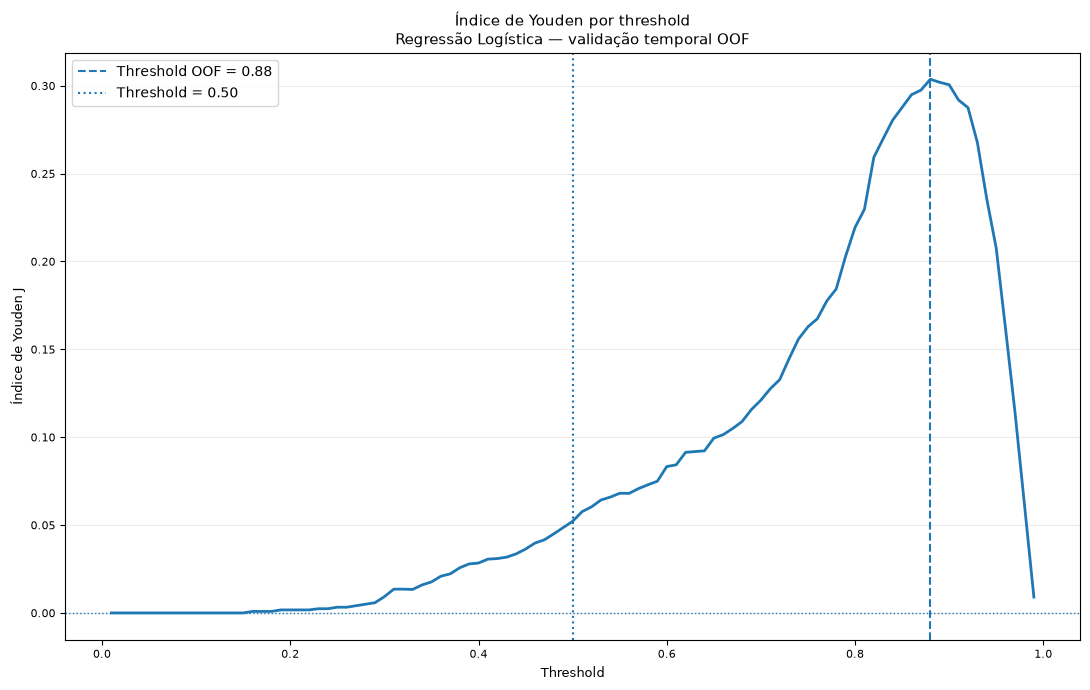


VALIDAÇÃO METODOLÓGICA
✓ Threshold máximo da Balanced Accuracy: 0.88
✓ Threshold máximo do Youden J: 0.88
✓ Balanced Accuracy e Youden J selecionaram o mesmo threshold.
✓ O threshold foi estimado exclusivamente com previsões temporais OOF.
✓ O threshold 0.91 do XGBoost não foi reutilizado.
✓ 2020 e 2021 não foram artificialmente introduzidos.
✓ 2024 não participou da seleção do threshold.
✓ 2025 não participou da seleção do threshold.
✓ Nenhum balanceamento artificial foi utilizado.

Bloco 31 concluído com sucesso.


In [38]:
# ============================================================
# BLOCO 31 — SELEÇÃO TEMPORAL DO THRESHOLD
# REGRESSÃO LOGÍSTICA — PREVISÕES OOF
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


print('=' * 82)
print('SELEÇÃO DO THRESHOLD OOF — REGRESSÃO LOGÍSTICA')
print('=' * 82)


# ============================================================
# 1. RECUPERAÇÃO DAS PROBABILIDADES OOF
# ============================================================

if 'probabilidades_oof_modelos' not in globals():

    raise NameError(
        "O objeto 'probabilidades_oof_modelos' "
        "não foi encontrado. Execute o Bloco 29."
    )


if (
    'Regressão Logística'
    not in probabilidades_oof_modelos
):

    raise KeyError(
        'As probabilidades OOF da Regressão '
        'Logística não foram encontradas.'
    )


prob_oof_lr = (
    probabilidades_oof_modelos[
        'Regressão Logística'
    ]
    .copy()
)


# ============================================================
# 2. OBSERVAÇÕES COM PREVISÃO OOF
# ============================================================

mask_oof_lr = (
    prob_oof_lr.notna()
)


y_oof_lr = (
    y_dev
    .loc[mask_oof_lr]
    .astype(int)
)


prob_oof_lr_validas = (
    prob_oof_lr
    .loc[mask_oof_lr]
    .astype(float)
)


# Verificação do alinhamento

assert (
    y_oof_lr.index
    .equals(
        prob_oof_lr_validas.index
    )
)


n_oof = len(
    y_oof_lr
)


n_favoravel = int(
    (y_oof_lr == 0).sum()
)


n_desfavoravel = int(
    (y_oof_lr == 1).sum()
)


prevalencia_oof = (
    y_oof_lr.mean()
)


print(
    f'\nObservações com previsão OOF: '
    f'{n_oof:,}'
)


print(
    f'Favoráveis ................: '
    f'{n_favoravel:,}'
)


print(
    f'Desfavoráveis .............: '
    f'{n_desfavoravel:,}'
)


print(
    f'Prevalência desfavorável ..: '
    f'{prevalencia_oof:.2%}'
)


# ============================================================
# 3. GRADE DE THRESHOLDS
# ============================================================

thresholds = np.arange(
    0.01,
    1.00,
    0.01
)


resultados_threshold_lr = []


# ============================================================
# 4. AVALIAÇÃO DOS THRESHOLDS
# ============================================================

for threshold in thresholds:

    # --------------------------------------------------------
    # Classificação
    # --------------------------------------------------------

    pred = (
        prob_oof_lr_validas
        >= threshold
    ).astype(int)


    # --------------------------------------------------------
    # Matriz de confusão
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_oof_lr,
        pred,
        labels=[0, 1]
    )


    tn, fp, fn, tp = (
        cm.ravel()
    )


    # --------------------------------------------------------
    # Sensibilidade
    # --------------------------------------------------------

    sensibilidade = recall_score(
        y_oof_lr,
        pred,
        pos_label=1,
        zero_division=0
    )


    # --------------------------------------------------------
    # Especificidade
    # --------------------------------------------------------

    especificidade = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


    # --------------------------------------------------------
    # Precisão
    # --------------------------------------------------------

    precisao = precision_score(
        y_oof_lr,
        pred,
        pos_label=1,
        zero_division=0
    )


    # --------------------------------------------------------
    # F1
    # --------------------------------------------------------

    f1 = f1_score(
        y_oof_lr,
        pred,
        pos_label=1,
        zero_division=0
    )


    # --------------------------------------------------------
    # Acurácia
    # --------------------------------------------------------

    acuracia = accuracy_score(
        y_oof_lr,
        pred
    )


    # --------------------------------------------------------
    # Balanced Accuracy
    # --------------------------------------------------------

    balanced_accuracy = (
        balanced_accuracy_score(
            y_oof_lr,
            pred
        )
    )


    # --------------------------------------------------------
    # Índice de Youden
    # --------------------------------------------------------

    youden_j = (
        sensibilidade
        +
        especificidade
        -
        1
    )


    # --------------------------------------------------------
    # Armazenamento
    # --------------------------------------------------------

    resultados_threshold_lr.append(
        {
            'THRESHOLD':
                threshold,

            'SENSIBILIDADE':
                sensibilidade,

            'ESPECIFICIDADE':
                especificidade,

            'PRECISAO':
                precisao,

            'F1':
                f1,

            'ACURACIA':
                acuracia,

            'BALANCED_ACCURACY':
                balanced_accuracy,

            'YOUDEN_J':
                youden_j,

            'TN':
                tn,

            'FP':
                fp,

            'FN':
                fn,

            'TP':
                tp
        }
    )


# ============================================================
# 5. DATAFRAME DOS THRESHOLDS
# ============================================================

df_threshold_lr = pd.DataFrame(
    resultados_threshold_lr
)


# ============================================================
# 6. THRESHOLD QUE MAXIMIZA BALANCED ACCURACY
# ============================================================

idx_otimo_ba = (
    df_threshold_lr[
        'BALANCED_ACCURACY'
    ]
    .idxmax()
)


resultado_otimo_lr = (
    df_threshold_lr
    .loc[idx_otimo_ba]
)


threshold_otimo_lr = float(
    resultado_otimo_lr[
        'THRESHOLD'
    ]
)


# ============================================================
# 7. THRESHOLD QUE MAXIMIZA YOUDEN J
# ============================================================

idx_otimo_youden = (
    df_threshold_lr[
        'YOUDEN_J'
    ]
    .idxmax()
)


threshold_youden_lr = float(
    df_threshold_lr
    .loc[
        idx_otimo_youden,
        'THRESHOLD'
    ]
)


# ============================================================
# 8. RESULTADO DO THRESHOLD OOF
# ============================================================

print('\n' + '=' * 82)
print('THRESHOLD OOF SELECIONADO')
print('=' * 82)


print(
    f'Threshold ................. '
    f'{threshold_otimo_lr:.2f}'
)


print(
    f'Sensibilidade ............. '
    f'{resultado_otimo_lr["SENSIBILIDADE"]:.3f}'
)


print(
    f'Especificidade ............ '
    f'{resultado_otimo_lr["ESPECIFICIDADE"]:.3f}'
)


print(
    f'Precisão .................. '
    f'{resultado_otimo_lr["PRECISAO"]:.3f}'
)


print(
    f'F1 ........................ '
    f'{resultado_otimo_lr["F1"]:.3f}'
)


print(
    f'Acurácia .................. '
    f'{resultado_otimo_lr["ACURACIA"]:.3f}'
)


print(
    f'Balanced Accuracy ......... '
    f'{resultado_otimo_lr["BALANCED_ACCURACY"]:.3f}'
)


print(
    f'Youden J .................. '
    f'{resultado_otimo_lr["YOUDEN_J"]:.3f}'
)


print(
    f'TN ........................ '
    f'{int(resultado_otimo_lr["TN"]):,}'
)


print(
    f'FP ........................ '
    f'{int(resultado_otimo_lr["FP"]):,}'
)


print(
    f'FN ........................ '
    f'{int(resultado_otimo_lr["FN"]):,}'
)


print(
    f'TP ........................ '
    f'{int(resultado_otimo_lr["TP"]):,}'
)


# ============================================================
# 9. RESULTADO NO THRESHOLD 0.50
# ============================================================

resultado_050 = (
    df_threshold_lr
    .loc[
        np.isclose(
            df_threshold_lr[
                'THRESHOLD'
            ],
            0.50
        )
    ]
    .iloc[0]
)


# ============================================================
# 10. COMPARAÇÃO 0.50 × THRESHOLD OOF
# ============================================================

comparacao_thresholds_lr = pd.DataFrame(
    [
        {
            'REGRA':
                'Threshold 0.50',

            **resultado_050.to_dict()
        },

        {
            'REGRA':
                'Threshold OOF selecionado',

            **resultado_otimo_lr.to_dict()
        }
    ]
)


print('\n' + '=' * 82)
print('COMPARAÇÃO — THRESHOLD 0.50 × THRESHOLD OOF')
print('=' * 82)


display(
    comparacao_thresholds_lr[
        [
            'REGRA',
            'THRESHOLD',
            'SENSIBILIDADE',
            'ESPECIFICIDADE',
            'PRECISAO',
            'F1',
            'ACURACIA',
            'BALANCED_ACCURACY',
            'YOUDEN_J',
            'TN',
            'FP',
            'FN',
            'TP'
        ]
    ]
    .style
    .format({
        'THRESHOLD':
            '{:.2f}',

        'SENSIBILIDADE':
            '{:.3f}',

        'ESPECIFICIDADE':
            '{:.3f}',

        'PRECISAO':
            '{:.3f}',

        'F1':
            '{:.3f}',

        'ACURACIA':
            '{:.3f}',

        'BALANCED_ACCURACY':
            '{:.3f}',

        'YOUDEN_J':
            '{:.3f}',

        'TN':
            '{:,.0f}',

        'FP':
            '{:,.0f}',

        'FN':
            '{:,.0f}',

        'TP':
            '{:,.0f}'
    })
    .hide(axis='index')
)


# ============================================================
# 11. GRÁFICO — SENSIBILIDADE × ESPECIFICIDADE
# ============================================================

plt.figure(
    figsize=(11, 7)
)


plt.plot(
    df_threshold_lr[
        'THRESHOLD'
    ],
    df_threshold_lr[
        'SENSIBILIDADE'
    ],
    linewidth=2,
    label='Sensibilidade'
)


plt.plot(
    df_threshold_lr[
        'THRESHOLD'
    ],
    df_threshold_lr[
        'ESPECIFICIDADE'
    ],
    linewidth=2,
    label='Especificidade'
)


plt.axvline(
    x=0.50,
    linestyle=':',
    linewidth=1.5,
    label='Threshold = 0.50'
)


plt.axvline(
    x=threshold_otimo_lr,
    linestyle='--',
    linewidth=1.5,
    label=(
        f'Threshold OOF = '
        f'{threshold_otimo_lr:.2f}'
    )
)


plt.xlabel(
    'Threshold'
)

plt.ylabel(
    'Proporção'
)

plt.title(
    'Sensibilidade e especificidade por threshold\n'
    'Regressão Logística — validação temporal OOF'
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.grid(
    axis='y',
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ============================================================
# 12. GRÁFICO — BALANCED ACCURACY
# ============================================================

plt.figure(
    figsize=(11, 7)
)


plt.plot(
    df_threshold_lr[
        'THRESHOLD'
    ],
    df_threshold_lr[
        'BALANCED_ACCURACY'
    ],
    linewidth=2
)


plt.axvline(
    x=threshold_otimo_lr,
    linestyle='--',
    linewidth=1.5,
    label=(
        f'Threshold OOF = '
        f'{threshold_otimo_lr:.2f}'
    )
)


plt.axvline(
    x=0.50,
    linestyle=':',
    linewidth=1.5,
    label='Threshold = 0.50'
)


plt.axhline(
    y=0.50,
    linestyle=':',
    linewidth=1
)


plt.xlabel(
    'Threshold'
)

plt.ylabel(
    'Balanced Accuracy'
)

plt.title(
    'Balanced Accuracy por threshold\n'
    'Regressão Logística — validação temporal OOF'
)

plt.legend()

plt.grid(
    axis='y',
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ============================================================
# 13. GRÁFICO — ÍNDICE DE YOUDEN
# ============================================================

plt.figure(
    figsize=(11, 7)
)


plt.plot(
    df_threshold_lr[
        'THRESHOLD'
    ],
    df_threshold_lr[
        'YOUDEN_J'
    ],
    linewidth=2
)


plt.axvline(
    x=threshold_otimo_lr,
    linestyle='--',
    linewidth=1.5,
    label=(
        f'Threshold OOF = '
        f'{threshold_otimo_lr:.2f}'
    )
)


plt.axvline(
    x=0.50,
    linestyle=':',
    linewidth=1.5,
    label='Threshold = 0.50'
)


plt.axhline(
    y=0,
    linestyle=':',
    linewidth=1
)


plt.xlabel(
    'Threshold'
)

plt.ylabel(
    'Índice de Youden J'
)

plt.title(
    'Índice de Youden por threshold\n'
    'Regressão Logística — validação temporal OOF'
)

plt.legend()

plt.grid(
    axis='y',
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ============================================================
# 14. VALIDAÇÕES METODOLÓGICAS
# ============================================================

assert np.isclose(
    threshold_otimo_lr,
    threshold_youden_lr
)


assert (
    prob_oof_lr_validas
    .between(
        0,
        1
    )
    .all()
)


print('\n' + '=' * 82)
print('VALIDAÇÃO METODOLÓGICA')
print('=' * 82)


print(
    f'✓ Threshold máximo da Balanced Accuracy: '
    f'{threshold_otimo_lr:.2f}'
)


print(
    f'✓ Threshold máximo do Youden J: '
    f'{threshold_youden_lr:.2f}'
)


print(
    '✓ Balanced Accuracy e Youden J '
    'selecionaram o mesmo threshold.'
)


print(
    '✓ O threshold foi estimado exclusivamente '
    'com previsões temporais OOF.'
)


print(
    '✓ O threshold 0.91 do XGBoost '
    'não foi reutilizado.'
)


print(
    '✓ 2020 e 2021 não foram '
    'artificialmente introduzidos.'
)


print(
    '✓ 2024 não participou da seleção '
    'do threshold.'
)


print(
    '✓ 2025 não participou da seleção '
    'do threshold.'
)


print(
    '✓ Nenhum balanceamento artificial '
    'foi utilizado.'
)


print(
    '\nBloco 31 concluído com sucesso.'
)

### Interpretação da seleção temporal do threshold

A otimização realizada exclusivamente sobre as probabilidades temporais
out-of-fold da Regressão Logística selecionou:

$$
\boxed{
t^*_{LR,OOF}=0{,}88
}
$$

como ponto de corte que maximiza a Balanced Accuracy e, de forma equivalente,
o índice de Youden.

No threshold convencional de 0,50, foram obtidos:

$$
Sensibilidade=0{,}992
$$

$$
Especificidade=0{,}060
$$

e:

$$
Balanced\ Accuracy=0{,}526
$$

Esse resultado mostra que o modelo classificava quase todos os registros com
evolução desfavorável corretamente, porém apresentava capacidade muito baixa
de reconhecer os registros com evolução favorável.

A matriz de confusão correspondente foi:

$$
TN=70,\quad FP=1097,\quad FN=44,\quad TP=5580
$$

Ao utilizar o threshold selecionado de 0,88, foram obtidos:

$$
Sensibilidade=0{,}682
$$

$$
Especificidade=0{,}621
$$

$$
Precisão=0{,}897
$$

$$
F1=0{,}775
$$

$$
Acurácia=0{,}672
$$

e:

$$
\boxed{
Balanced\ Accuracy=0{,}652
}
$$

O índice de Youden aumentou de:

$$
J_{0,50}=0{,}052
$$

para:

$$
J_{0,88}=0{,}304
$$

A matriz de confusão passou para:

$$
TN=725,\quad FP=442,\quad FN=1786,\quad TP=3838
$$

---

### Efeito da mudança do threshold

A elevação do threshold de 0,50 para 0,88 aumentou substancialmente a
capacidade de reconhecimento dos registros favoráveis.

O número de verdadeiros negativos aumentou de:

$$
70\rightarrow725
$$

enquanto os falsos positivos diminuíram de:

$$
1097\rightarrow442
$$

Entretanto, esse ganho ocorreu acompanhado de redução da sensibilidade.

Os falsos negativos aumentaram de:

$$
44\rightarrow1786
$$

enquanto os verdadeiros positivos diminuíram de:

$$
5580\rightarrow3838
$$

Portanto, a alteração do threshold não produz ganho simultâneo em todas as
métricas.

Ela modifica o compromisso entre:

$$
\boxed{
Sensibilidade
\longleftrightarrow
Especificidade
}
$$

---

### Por que a acurácia diminuiu?

A acurácia convencional diminuiu de:

$$
0{,}832
$$

para:

$$
0{,}672
$$

apesar do aumento da Balanced Accuracy.

Esse comportamento decorre da distribuição assimétrica do desfecho no
conjunto OOF.

Quando a classe desfavorável é predominante, classificar grande parte das
observações como desfavoráveis pode produzir acurácia elevada mesmo quando a
capacidade de reconhecer a classe favorável é muito baixa.

Por isso:

$$
Accuracy_{0,50}=0{,}832
$$

coexistiu com:

$$
Especificidade_{0,50}=0{,}060
$$

A Balanced Accuracy atribui igual peso à sensibilidade e à especificidade:

$$
BA=
\frac{
Sensibilidade+Especificidade
}{2}
$$

e, por essa razão, aumentou de:

$$
0{,}526
\rightarrow
0{,}652
$$

quando o threshold foi elevado para 0,88.

---

### Interpretação do threshold 0,88

O valor:

$$
t=0{,}88
$$

não deve ser interpretado como um ponto de corte clínico ou epidemiológico
universal.

Também não implica, neste estágio, que uma probabilidade prevista de 0,88
corresponda necessariamente a uma probabilidade real perfeitamente calibrada
de 88% de evolução desfavorável.

O threshold foi selecionado como uma **regra de classificação interna** que
maximiza a Balanced Accuracy nas previsões temporais OOF.

Assim:

$$
\boxed{
t^*_{LR,OOF}=0{,}88
}
$$

deve ser interpretado como um ponto de decisão derivado empiricamente para
este modelo e esta população de estudo.

A calibração das probabilidades será avaliada separadamente.

---

### Escolha do critério e implicações epidemiológicas

O threshold de 0,88 é ótimo segundo o critério definido neste estudo:

$$
\max_t Balanced\ Accuracy(t)
$$

equivalentemente:

$$
\max_t J(t)
$$

Isso não significa que ele seja necessariamente ótimo para todas as possíveis
aplicações.

Se o custo de não identificar um registro com evolução desfavorável fosse
considerado substancialmente maior que o custo de classificar incorretamente
um registro favorável como desfavorável, poderia ser justificável selecionar
um threshold menor, privilegiando maior sensibilidade.

Portanto, a seleção do ponto de corte depende do objetivo da regra de decisão.

Neste estudo, a Balanced Accuracy foi utilizada para evitar que a elevada
frequência da classe positiva determinasse isoladamente a escolha do
threshold.

---

### Natureza interna do resultado

Embora cada probabilidade OOF tenha sido produzida por um modelo que não
utilizou a própria observação prevista durante o treinamento, o threshold de
0,88 foi selecionado utilizando o conjunto agregado dessas previsões.

Consequentemente, o desempenho:

$$
Balanced\ Accuracy=0{,}652
$$

constitui uma medida de seleção interna e não deve ser apresentado como
estimativa final completamente independente de desempenho.

O threshold será mantido fixo nas avaliações temporais posteriores, sem nova
otimização específica para cada período.

Dessa forma, as etapas seguintes poderão investigar se a regra de decisão
selecionada internamente mantém desempenho adequado quando aplicada a períodos
posteriores.

AVALIAÇÃO TEMPORAL — REGRESSÃO LOGÍSTICA
2024 E 2025

Threshold fixo utilizado: 0.88

DESEMPENHO TEMPORAL — 2024 × 2025


PERIODO,N,PREVALENCIA_DESFAVORAVEL,ROC_AUC,PR_AUC,THRESHOLD,SENSIBILIDADE,ESPECIFICIDADE,PRECISAO,F1,ACURACIA,BALANCED_ACCURACY,BRIER_SCORE
2024,"2,710",73.32%,0.778,0.882,0.88,0.458,0.855,0.897,0.606,0.564,0.656,0.151
2025,"1,758",73.44%,0.720,0.860,0.88,0.433,0.814,0.865,0.577,0.534,0.623,0.168



MATRIZES DE CONFUSÃO


PERIODO,TN,FP,FN,TP
2024,618,105,"1,077",910
2025,380,87,732,559


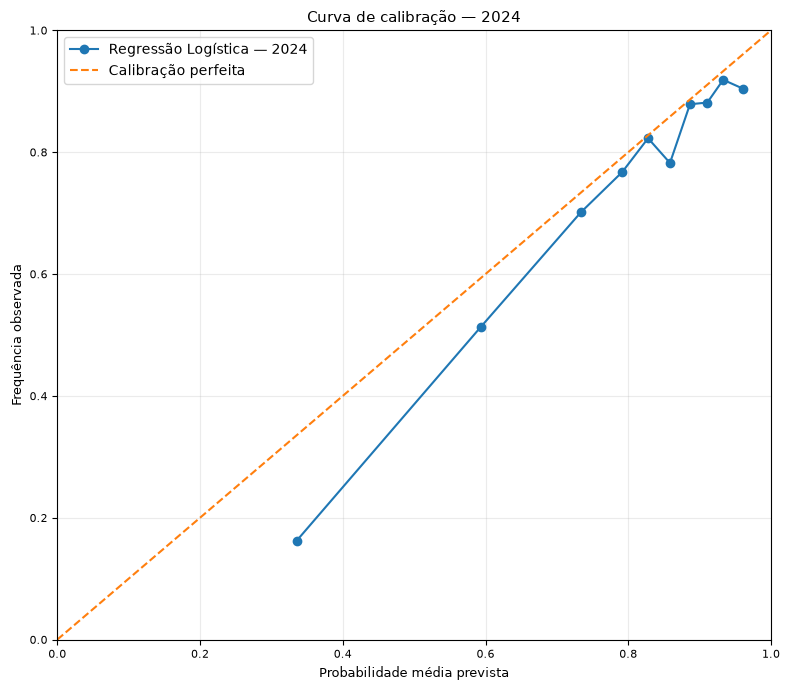

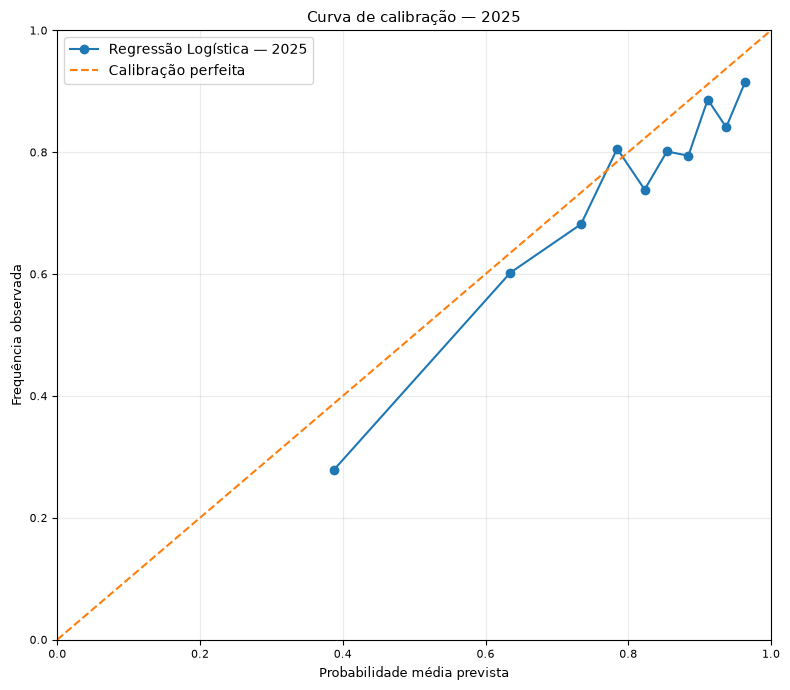

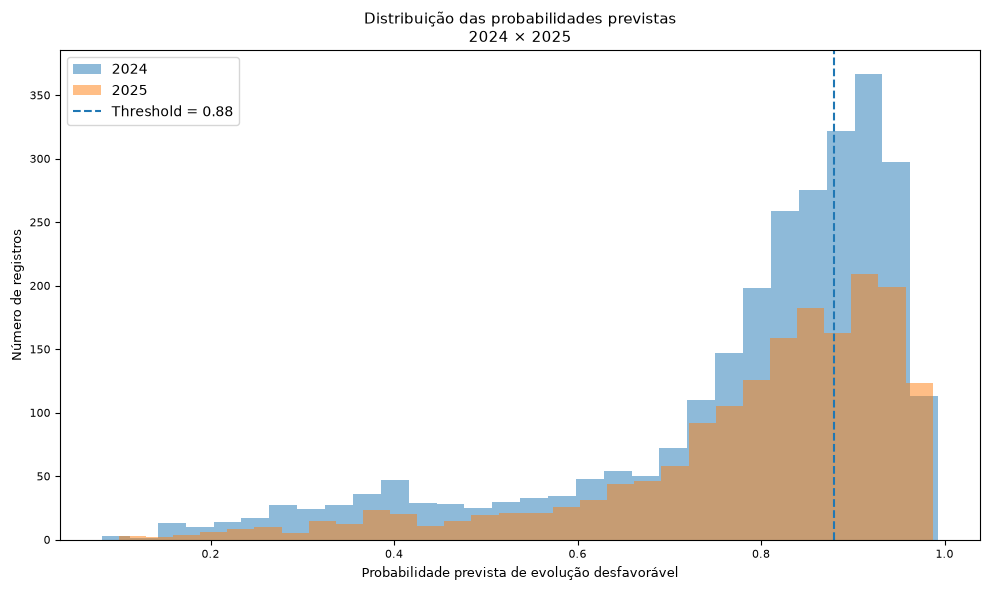


VALIDAÇÃO METODOLÓGICA
✓ Regressão Logística mantida como modelo principal.
✓ Threshold mantido fixo em 0.88.
✓ Nenhuma otimização foi realizada em 2024.
✓ Nenhuma otimização foi realizada em 2025.
✓ 2024 foi avaliado como período temporal posterior.
✓ 2025 foi avaliado separadamente como período temporal complementar.
✓ Foram calculadas métricas de discriminação, classificação e calibração.

Bloco 32 concluído com sucesso.


In [39]:
# ============================================================
# BLOCO 32 — AVALIAÇÃO TEMPORAL DA REGRESSÃO LOGÍSTICA
# 2024 E 2025
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss
)

from sklearn.calibration import calibration_curve


print('=' * 82)
print('AVALIAÇÃO TEMPORAL — REGRESSÃO LOGÍSTICA')
print('2024 E 2025')
print('=' * 82)


# ============================================================
# 1. VERIFICAÇÕES
# ============================================================

if 'modelo_logistico' not in globals():
    raise NameError(
        "O objeto 'modelo_logistico' não foi encontrado."
    )

if 'threshold_otimo_lr' not in globals():
    raise NameError(
        "O objeto 'threshold_otimo_lr' não foi encontrado. "
        "Execute o Bloco 31."
    )


threshold_final_lr = float(
    threshold_otimo_lr
)


print(
    f'\nThreshold fixo utilizado: '
    f'{threshold_final_lr:.2f}'
)


# ============================================================
# 2. FUNÇÃO DE AVALIAÇÃO
# ============================================================

def avaliar_periodo(
    nome_periodo,
    modelo,
    X,
    y,
    threshold
):

    y = y.astype(int)

    # Probabilidades
    prob = (
        modelo
        .predict_proba(X)[:, 1]
    )

    # Classificação
    pred = (
        prob >= threshold
    ).astype(int)

    # Matriz de confusão
    cm = confusion_matrix(
        y,
        pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = (
        cm.ravel()
    )

    # Métricas
    roc_auc = roc_auc_score(
        y,
        prob
    )

    pr_auc = average_precision_score(
        y,
        prob
    )

    sensibilidade = recall_score(
        y,
        pred,
        pos_label=1,
        zero_division=0
    )

    especificidade = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    precisao = precision_score(
        y,
        pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y,
        pred,
        pos_label=1,
        zero_division=0
    )

    acuracia = accuracy_score(
        y,
        pred
    )

    balanced_accuracy = (
        balanced_accuracy_score(
            y,
            pred
        )
    )

    brier = brier_score_loss(
        y,
        prob
    )

    prevalencia = (
        y.mean()
    )

    resultado = {
        'PERIODO': nome_periodo,
        'N': len(y),
        'PREVALENCIA_DESFAVORAVEL':
            prevalencia,
        'ROC_AUC':
            roc_auc,
        'PR_AUC':
            pr_auc,
        'THRESHOLD':
            threshold,
        'SENSIBILIDADE':
            sensibilidade,
        'ESPECIFICIDADE':
            especificidade,
        'PRECISAO':
            precisao,
        'F1':
            f1,
        'ACURACIA':
            acuracia,
        'BALANCED_ACCURACY':
            balanced_accuracy,
        'BRIER_SCORE':
            brier,
        'TN':
            tn,
        'FP':
            fp,
        'FN':
            fn,
        'TP':
            tp
    }

    return resultado, prob, pred


# ============================================================
# 3. AVALIAÇÃO DE 2024
# ============================================================

resultado_2024, prob_2024_lr, pred_2024_lr = (
    avaliar_periodo(
        nome_periodo='2024',
        modelo=modelo_logistico,
        X=X_test,
        y=y_test,
        threshold=threshold_final_lr
    )
)


# ============================================================
# 4. AVALIAÇÃO DE 2025
# ============================================================

resultado_2025, prob_2025_lr, pred_2025_lr = (
    avaliar_periodo(
        nome_periodo='2025',
        modelo=modelo_logistico,
        X=X_2025,
        y=y_2025,
        threshold=threshold_final_lr
    )
)


# ============================================================
# 5. TABELA COMPARATIVA
# ============================================================

df_avaliacao_temporal_lr = pd.DataFrame(
    [
        resultado_2024,
        resultado_2025
    ]
)


print('\n' + '=' * 82)
print('DESEMPENHO TEMPORAL — 2024 × 2025')
print('=' * 82)


display(
    df_avaliacao_temporal_lr[
        [
            'PERIODO',
            'N',
            'PREVALENCIA_DESFAVORAVEL',
            'ROC_AUC',
            'PR_AUC',
            'THRESHOLD',
            'SENSIBILIDADE',
            'ESPECIFICIDADE',
            'PRECISAO',
            'F1',
            'ACURACIA',
            'BALANCED_ACCURACY',
            'BRIER_SCORE'
        ]
    ]
    .style
    .format({
        'N': '{:,.0f}',
        'PREVALENCIA_DESFAVORAVEL': '{:.2%}',
        'ROC_AUC': '{:.3f}',
        'PR_AUC': '{:.3f}',
        'THRESHOLD': '{:.2f}',
        'SENSIBILIDADE': '{:.3f}',
        'ESPECIFICIDADE': '{:.3f}',
        'PRECISAO': '{:.3f}',
        'F1': '{:.3f}',
        'ACURACIA': '{:.3f}',
        'BALANCED_ACCURACY': '{:.3f}',
        'BRIER_SCORE': '{:.3f}'
    })
    .hide(axis='index')
)


# ============================================================
# 6. MATRIZES DE CONFUSÃO
# ============================================================

print('\n' + '=' * 82)
print('MATRIZES DE CONFUSÃO')
print('=' * 82)


display(
    df_avaliacao_temporal_lr[
        [
            'PERIODO',
            'TN',
            'FP',
            'FN',
            'TP'
        ]
    ]
    .style
    .format({
        'TN': '{:,.0f}',
        'FP': '{:,.0f}',
        'FN': '{:,.0f}',
        'TP': '{:,.0f}'
    })
    .hide(axis='index')
)


# ============================================================
# 7. CURVA DE CALIBRAÇÃO — 2024
# ============================================================

frac_pos_2024, prob_pred_2024 = (
    calibration_curve(
        y_test,
        prob_2024_lr,
        n_bins=10,
        strategy='quantile'
    )
)


plt.figure(
    figsize=(8, 7)
)


plt.plot(
    prob_pred_2024,
    frac_pos_2024,
    marker='o',
    label='Regressão Logística — 2024'
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Calibração perfeita'
)


plt.xlabel(
    'Probabilidade média prevista'
)

plt.ylabel(
    'Frequência observada'
)

plt.title(
    'Curva de calibração — 2024'
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ============================================================
# 8. CURVA DE CALIBRAÇÃO — 2025
# ============================================================

frac_pos_2025, prob_pred_2025 = (
    calibration_curve(
        y_2025,
        prob_2025_lr,
        n_bins=10,
        strategy='quantile'
    )
)


plt.figure(
    figsize=(8, 7)
)


plt.plot(
    prob_pred_2025,
    frac_pos_2025,
    marker='o',
    label='Regressão Logística — 2025'
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Calibração perfeita'
)


plt.xlabel(
    'Probabilidade média prevista'
)

plt.ylabel(
    'Frequência observada'
)

plt.title(
    'Curva de calibração — 2025'
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ============================================================
# 9. DISTRIBUIÇÃO DAS PROBABILIDADES
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.hist(
    prob_2024_lr,
    bins=30,
    alpha=0.5,
    label='2024'
)


plt.hist(
    prob_2025_lr,
    bins=30,
    alpha=0.5,
    label='2025'
)


plt.axvline(
    threshold_final_lr,
    linestyle='--',
    linewidth=1.5,
    label=(
        f'Threshold = '
        f'{threshold_final_lr:.2f}'
    )
)


plt.xlabel(
    'Probabilidade prevista de evolução desfavorável'
)

plt.ylabel(
    'Número de registros'
)

plt.title(
    'Distribuição das probabilidades previstas\n'
    '2024 × 2025'
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 10. VALIDAÇÕES METODOLÓGICAS
# ============================================================

assert np.isclose(
    resultado_2024[
        'THRESHOLD'
    ],
    threshold_final_lr
)

assert np.isclose(
    resultado_2025[
        'THRESHOLD'
    ],
    threshold_final_lr
)


assert len(
    prob_2024_lr
) == len(
    y_test
)


assert len(
    prob_2025_lr
) == len(
    y_2025
)


print('\n' + '=' * 82)
print('VALIDAÇÃO METODOLÓGICA')
print('=' * 82)


print(
    '✓ Regressão Logística mantida como '
    'modelo principal.'
)


print(
    f'✓ Threshold mantido fixo em '
    f'{threshold_final_lr:.2f}.'
)


print(
    '✓ Nenhuma otimização foi realizada '
    'em 2024.'
)


print(
    '✓ Nenhuma otimização foi realizada '
    'em 2025.'
)


print(
    '✓ 2024 foi avaliado como período '
    'temporal posterior.'
)


print(
    '✓ 2025 foi avaliado separadamente '
    'como período temporal complementar.'
)


print(
    '✓ Foram calculadas métricas de '
    'discriminação, classificação e calibração.'
)


print(
    '\nBloco 32 concluído com sucesso.'
)

### Interpretação da avaliação temporal em 2024 e 2025

A Regressão Logística, utilizando o threshold fixo selecionado internamente:

$$
t=0{,}88
$$

foi aplicada aos períodos de 2024 e 2025 sem nova otimização.

Em 2024, a matriz de confusão foi:

$$
TN=618,\quad FP=105,\quad FN=1077,\quad TP=910
$$

resultando aproximadamente em:

$$
Sensibilidade=0{,}458
$$

$$
Especificidade=0{,}855
$$

e:

$$
Balanced\ Accuracy\approx0{,}657
$$

Em 2025, foram observados:

$$
TN=380,\quad FP=87,\quad FN=732,\quad TP=559
$$

com:

$$
Sensibilidade\approx0{,}433
$$

$$
Especificidade\approx0{,}814
$$

e:

$$
Balanced\ Accuracy\approx0{,}624
$$

Os dois períodos apresentaram comportamento semelhante.

O threshold selecionado apresentou maior especificidade do que sensibilidade,
indicando maior capacidade de reconhecer corretamente os registros com
evolução favorável do que de identificar todos os registros com evolução
desfavorável.

Esse comportamento representa um deslocamento em relação à avaliação OOF,
na qual o threshold de 0,88 havia produzido maior equilíbrio entre as duas
métricas.

Assim, a avaliação temporal posterior demonstra que:

$$
\boxed{
\text{o threshold permanece operacionalmente estável,}
}
$$

mas:

$$
\boxed{
\text{sua sensibilidade diminui em períodos posteriores.}
}
$$

Esse resultado reforça a importância de distinguir capacidade discriminativa
do modelo e desempenho de uma regra específica de classificação.

A avaliação do threshold não deve, portanto, substituir as métricas
probabilísticas, como ROC-AUC e PR-AUC.

---

### Calibração

A curva de calibração de 2024 permaneceu relativamente próxima da diagonal
em parte da faixa de probabilidades mais elevadas.

Entretanto, vários pontos ficaram abaixo da linha de calibração perfeita.

Quando:

$$
Frequência\ observada
<
Probabilidade\ prevista
$$

o modelo está atribuindo probabilidades superiores à frequência efetivamente
observada do desfecho.

Esse padrão sugere possível superestimação do risco em parte da distribuição.

Portanto, o valor previsto pelo modelo não deve ser interpretado diretamente
como uma probabilidade absoluta perfeitamente calibrada sem avaliação
adicional.

Em particular:

$$
\hat p=0{,}88
$$

não deve ser interpretado como evidência de que o registro possui exatamente
88% de probabilidade real de evolução desfavorável.

O threshold de 0,88 deve ser entendido como uma regra de decisão derivada
empiricamente a partir da validação temporal interna.

--------------------------------------

## BLOCO 33 — Preparação da análise inferencial

Após a etapa preditiva, a análise passa a responder diretamente à pergunta
epidemiológica do estudo:

> Entre os registros de transtornos mentais relacionados ao trabalho com
> evolução classificável, quais características estão associadas à ocorrência
> de evolução desfavorável, em comparação com evolução favorável?

Até aqui, os modelos de Machine Learning foram avaliados com finalidade
preditiva. A Regressão Logística, Random Forest, XGBoost e LightGBM foram
comparados por meio de validação temporal, com análise de discriminação,
estabilidade e escolha de limiar de classificação.

A análise inferencial possui objetivo diferente.

Nesta etapa, o interesse é estimar a associação ajustada entre as
características dos registros e o desfecho observado.

---

### Definição do desfecho

O desfecho binário permanece exatamente o mesmo definido anteriormente:

$$
Y =
\begin{cases}
0, & \text{evolução favorável}\\
1, & \text{evolução desfavorável}
\end{cases}
$$

A categoria favorável compreende:

- cura;
- cura não confirmada.

A categoria desfavorável compreende:

- incapacidade temporária;
- incapacidade permanente parcial;
- incapacidade permanente total;
- óbito por doença relacionada ao trabalho.

O threshold de classificação utilizado na etapa preditiva não participa desta
análise.

A regressão inferencial utiliza diretamente o desfecho observado.

---

### Modelo logístico

Para uma observação $i$, define-se:

$$
p_i=P(Y_i=1 \mid X_i)
$$

A Regressão Logística modela o logaritmo das chances do desfecho:

$$
\log
\left(
\frac{p_i}{1-p_i}
\right)
=
\beta_0+
\beta_1X_{i1}+
\beta_2X_{i2}+
\cdots+
\beta_kX_{ik}
$$

Para cada variável $X_j$, o coeficiente pode ser exponenciado:

$$
OR_j=e^{\beta_j}
$$

produzindo a razão de chances, ou odds ratio.

De forma geral:

$$
OR>1
$$

indica maior chance de evolução desfavorável em comparação à categoria de
referência;

$$
OR<1
$$

indica menor chance;

e:

$$
OR=1
$$

indica ausência de diferença nas chances segundo o modelo.

---

### Intervalo de confiança

O intervalo de confiança de 95% será calculado por:

$$
IC95\%=
\left[
e^{\beta_j-1{,}96SE(\beta_j)},
e^{\beta_j+1{,}96SE(\beta_j)}
\right]
$$

A interpretação dos odds ratios será realizada conjuntamente com os
intervalos de confiança e os p-valores.

---

### Associação não implica causalidade

Os odds ratios estimados serão interpretados como medidas de associação
ajustada.

Portanto, não será afirmado que determinada característica causa o desfecho.

A interpretação apropriada será, por exemplo:

> "A categoria apresentou maiores chances de evolução desfavorável em relação
> à categoria de referência, após ajuste pelas demais covariáveis incluídas no
> modelo."

Como os dados possuem natureza observacional, as estimativas não permitem
inferência causal.

---

### Por que auditar as categorias antes do modelo?

Variáveis categóricas são representadas na regressão por indicadores em
relação a uma categoria de referência.

Para uma variável com $K$ categorias, o modelo estima:

$$
K-1
$$

coeficientes.

A categoria utilizada como referência influencia diretamente a interpretação
dos odds ratios.

Além disso, categorias muito raras podem gerar instabilidade.

Por exemplo:

| Categoria | Favorável | Desfavorável |
|---|---:|---:|
| A | 500 | 1500 |
| B | 2 | 30 |
| C | 0 | 7 |

A categoria C apresenta ausência completa de uma das classes.

Situações desse tipo podem produzir separação completa ou quase completa na
Regressão Logística, levando a coeficientes extremamente elevados, erros-padrão
grandes e intervalos de confiança pouco informativos.

Por isso, antes da estimação dos odds ratios, serão verificadas:

1. frequência das categorias;
2. quantidade de desfechos favoráveis;
3. quantidade de desfechos desfavoráveis;
4. proporção de evolução desfavorável;
5. células vazias;
6. células com frequência muito pequena;
7. possíveis sinais de separação;
8. categorias candidatas a referência.

Nenhuma categoria será agrupada automaticamente.

Qualquer agrupamento eventual deverá possuir justificativa substantiva e ser
definido antes da estimação final.

---

### Variáveis candidatas

A análise considera as variáveis selecionadas anteriormente para o modelo
principal:

- idade;
- sexo;
- raça/cor;
- escolaridade;
- unidade federativa;
- situação de trabalho;
- terceirização;
- grande grupo ocupacional;
- grupo diagnóstico CID-10;
- álcool;
- drogas;
- tabagismo.

A idade será inicialmente tratada como variável numérica contínua.

As demais serão analisadas como variáveis categóricas.

---

### Objetivo deste bloco

Este bloco ainda não estima os odds ratios finais.

Seu objetivo é preparar e auditar a base inferencial antes da construção do
modelo ajustado.

Essa etapa reduz o risco de interpretar coeficientes instáveis produzidos por
categorias extremamente raras ou por separação dos dados.

In [40]:
# ============================================================
# BLOCO 33 — PREPARAÇÃO DA ANÁLISE INFERENCIAL
# ============================================================

import numpy as np
import pandas as pd


print('=' * 82)
print('AUDITORIA — REGRESSÃO LOGÍSTICA INFERENCIAL')
print('=' * 82)


# ============================================================
# 1. BASE INFERENCIAL
# ============================================================
#
# A análise inferencial utiliza toda a população elegível
# definida anteriormente em df_modelo.
#
# Esta etapa é independente do threshold escolhido para
# classificação preditiva.
# ============================================================

df_inferencia = df_modelo.copy()


print(
    f'\nRegistros na base inferencial: '
    f'{len(df_inferencia):,}'
)


# ============================================================
# 2. RECONSTRUÇÃO EXPLÍCITA DO DESFECHO
# ============================================================
#
# 0 = Favorável
#     1 = Cura
#     2 = Cura não confirmada
#
# 1 = Desfavorável
#     3 = Incapacidade temporária
#     4 = Incapacidade permanente parcial
#     5 = Incapacidade permanente total
#     6 = Óbito por doença relacionada ao trabalho
# ============================================================

if 'EVOLUCAO' not in df_inferencia.columns:

    raise KeyError(
        "A coluna 'EVOLUCAO' não foi encontrada em df_modelo."
    )


evolucao_num = pd.to_numeric(
    df_inferencia['EVOLUCAO'],
    errors='coerce'
)


df_inferencia[
    'DESFECHO_DESFAVORAVEL'
] = evolucao_num.map(
    {
        1: 0,
        2: 0,
        3: 1,
        4: 1,
        5: 1,
        6: 1
    }
)


coluna_target = 'DESFECHO_DESFAVORAVEL'


# ============================================================
# 3. VALIDAÇÃO DO DESFECHO
# ============================================================

if (
    df_inferencia[
        coluna_target
    ]
    .isna()
    .any()
):

    valores_problematicos = (
        df_inferencia
        .loc[
            df_inferencia[
                coluna_target
            ]
            .isna(),
            'EVOLUCAO'
        ]
        .value_counts(
            dropna=False
        )
    )

    print(
        '\nValores de EVOLUCAO não classificados:'
    )

    print(
        valores_problematicos
    )

    raise ValueError(
        'Foram encontrados registros fora '
        'dos códigos elegíveis 1–6.'
    )


df_inferencia[
    coluna_target
] = (
    df_inferencia[
        coluna_target
    ]
    .astype(int)
)


valores_target = set(
    df_inferencia[
        coluna_target
    ]
    .unique()
)


assert valores_target == {0, 1}


n_favoravel = int(
    (
        df_inferencia[
            coluna_target
        ]
        == 0
    )
    .sum()
)


n_desfavoravel = int(
    (
        df_inferencia[
            coluna_target
        ]
        == 1
    )
    .sum()
)


print('\nDesfecho reconstruído com sucesso.')

print(
    f'Favorável (0) ............: '
    f'{n_favoravel:,}'
)

print(
    f'Desfavorável (1) .........: '
    f'{n_desfavoravel:,}'
)

print(
    f'Total .....................: '
    f'{len(df_inferencia):,}'
)

print(
    f'% desfavorável ............: '
    f'{df_inferencia[coluna_target].mean():.2%}'
)


# ============================================================
# 4. CONTROLE DE CONSISTÊNCIA
# ============================================================

assert len(df_inferencia) == 13598
assert n_favoravel == 2571
assert n_desfavoravel == 11027


print(
    '\n✓ Distribuição reproduz exatamente '
    'o desfecho definido no Bloco 16.'
)

print(
    '✓ O target inferencial foi reconstruído '
    'diretamente a partir de EVOLUCAO.'
)

print(
    '✓ O threshold 0.88 não participa '
    'desta definição.'
)


# ============================================================
# 5. GARANTIA DAS VARIÁVEIS AGRUPADAS
# ============================================================
#
# CID_GRUPO_MODELO e CBO_GRUPO_MODELO podem ter sido criadas
# em uma base posterior a df_modelo.
#
# Caso não existam em df_modelo, reconstruímos aqui utilizando
# as mesmas regras adotadas anteriormente.
# ============================================================


# ------------------------------------------------------------
# 5.1 CID — grande grupo F0 a F9
# ------------------------------------------------------------

if 'CID_GRUPO_MODELO' not in df_inferencia.columns:

    if 'GRUPO_CID' in df_inferencia.columns:

        df_inferencia[
            'CID_GRUPO_MODELO'
        ] = (
            df_inferencia[
                'GRUPO_CID'
            ]
            .astype('string')
            .str.strip()
            .str.upper()
        )

    elif 'DIAG_ESP' in df_inferencia.columns:

        cid_aux = (
            df_inferencia[
                'DIAG_ESP'
            ]
            .astype('string')
            .str.strip()
            .str.upper()
            .str.replace(
                '.',
                '',
                regex=False
            )
            .str.replace(
                ' ',
                '',
                regex=False
            )
        )

        df_inferencia[
            'CID_GRUPO_MODELO'
        ] = (
            cid_aux
            .str[:2]
        )

    else:

        raise KeyError(
            'Não foi possível construir '
            'CID_GRUPO_MODELO.'
        )


# ------------------------------------------------------------
# 5.2 CBO — primeiro dígito
# ------------------------------------------------------------

if 'CBO_GRUPO_MODELO' not in df_inferencia.columns:

    if 'ID_OCUPA_N' not in df_inferencia.columns:

        raise KeyError(
            'ID_OCUPA_N não encontrada para '
            'construção do grande grupo CBO.'
        )


    cbo_aux = (
        df_inferencia[
            'ID_OCUPA_N'
        ]
        .astype('string')
        .str.strip()
    )


    primeiro_digito_cbo = (
        cbo_aux
        .str.extract(
            r'(\d)',
            expand=False
        )
    )


    mapa_cbo = {
        '0':
            '0 - Forças Armadas, policiais e bombeiros',

        '1':
            '1 - Dirigentes e gerentes',

        '2':
            '2 - Profissionais das ciências e artes',

        '3':
            '3 - Técnicos de nível médio',

        '4':
            '4 - Trabalhadores administrativos',

        '5':
            '5 - Serviços, vendedores e comércio',

        '6':
            '6 - Agropecuária, florestais e pesca',

        '7':
            '7 - Produção de bens e serviços industriais',

        '8':
            '8 - Produção industrial e operadores',

        '9':
            '9 - Reparação e manutenção'
    }


    df_inferencia[
        'CBO_GRUPO_MODELO'
    ] = (
        primeiro_digito_cbo
        .map(
            mapa_cbo
        )
        .fillna(
            'Não informado'
        )
    )


# ============================================================
# 6. VARIÁVEIS CANDIDATAS
# ============================================================

variaveis_inferencia = [
    'IDADE_ANOS',
    'CS_SEXO',
    'CS_RACA',
    'CS_ESCOL_N',
    'SG_UF',
    'SIT_TRAB',
    'TERCEIRIZA',
    'CBO_GRUPO_MODELO',
    'CID_GRUPO_MODELO',
    'ALCOOL',
    'DROGAS',
    'FUMA'
]


variaveis_existentes = [
    coluna
    for coluna in variaveis_inferencia
    if coluna in df_inferencia.columns
]


variaveis_ausentes = [
    coluna
    for coluna in variaveis_inferencia
    if coluna not in df_inferencia.columns
]


print('\n' + '=' * 82)
print('VARIÁVEIS DA ANÁLISE')
print('=' * 82)


for coluna in variaveis_existentes:

    print(
        f'✓ {coluna}'
    )


if variaveis_ausentes:

    print(
        '\nATENÇÃO — variáveis ausentes:'
    )

    for coluna in variaveis_ausentes:

        print(
            f'⚠ {coluna}'
        )


if variaveis_ausentes:

    raise KeyError(
        'Existem variáveis da análise '
        'que não foram encontradas.'
    )


# ============================================================
# 7. AUDITORIA DA IDADE
# ============================================================

print('\n' + '=' * 82)
print('VARIÁVEL NUMÉRICA — IDADE')
print('=' * 82)


idade = pd.to_numeric(
    df_inferencia[
        'IDADE_ANOS'
    ],
    errors='coerce'
)


resumo_idade = pd.DataFrame(
    {
        'ESTATISTICA': [
            'N válido',
            'Ausentes',
            'Média',
            'Desvio-padrão',
            'Mínimo',
            'Q1',
            'Mediana',
            'Q3',
            'Máximo'
        ],

        'VALOR': [
            idade.notna().sum(),
            idade.isna().sum(),
            idade.mean(),
            idade.std(),
            idade.min(),
            idade.quantile(0.25),
            idade.median(),
            idade.quantile(0.75),
            idade.max()
        ]
    }
)


display(
    resumo_idade
)


# ============================================================
# 8. VARIÁVEIS CATEGÓRICAS
# ============================================================

variaveis_categoricas_inferencia = [
    coluna
    for coluna in variaveis_inferencia
    if coluna != 'IDADE_ANOS'
]


# ============================================================
# 9. PADRONIZAÇÃO DE AUSENTES CATEGÓRICOS
# ============================================================
#
# Importante:
# não fazemos conversão global de códigos como 9, 99 ou 00.
#
# Apenas valores efetivamente ausentes são representados como
# "Não informado".
# ============================================================

for coluna in variaveis_categoricas_inferencia:

    df_inferencia[
        coluna
    ] = (
        df_inferencia[
            coluna
        ]
        .astype('string')
        .fillna(
            'Não informado'
        )
        .str.strip()
    )


# ============================================================
# 10. FUNÇÃO DE AUDITORIA CATEGÓRICA
# ============================================================

def auditar_variavel_categorica(
    dataframe,
    variavel,
    target
):

    tabela = pd.crosstab(
        dataframe[
            variavel
        ],
        dataframe[
            target
        ]
    )


    tabela = tabela.reindex(
        columns=[0, 1],
        fill_value=0
    )


    tabela.columns = [
        'FAVORAVEL',
        'DESFAVORAVEL'
    ]


    tabela[
        'TOTAL'
    ] = (
        tabela[
            'FAVORAVEL'
        ]
        +
        tabela[
            'DESFAVORAVEL'
        ]
    )


    tabela[
        'PCT_DESFAVORAVEL'
    ] = np.where(
        tabela[
            'TOTAL'
        ] > 0,

        tabela[
            'DESFAVORAVEL'
        ]
        /
        tabela[
            'TOTAL'
        ],

        np.nan
    )


    tabela[
        'MENOR_CELULA'
    ] = tabela[
        [
            'FAVORAVEL',
            'DESFAVORAVEL'
        ]
    ].min(
        axis=1
    )


    tabela[
        'CELULA_ZERO'
    ] = (
        tabela[
            'MENOR_CELULA'
        ]
        == 0
    )


    tabela[
        'CELULA_MENOR_5'
    ] = (
        tabela[
            'MENOR_CELULA'
        ]
        < 5
    )


    tabela[
        'CELULA_MENOR_10'
    ] = (
        tabela[
            'MENOR_CELULA'
        ]
        < 10
    )


    referencia_candidata = (
        tabela[
            'TOTAL'
        ]
        .idxmax()
    )


    tabela = (
        tabela
        .sort_values(
            'TOTAL',
            ascending=False
        )
    )


    return (
        tabela,
        referencia_candidata
    )


# ============================================================
# 11. EXECUÇÃO DA AUDITORIA
# ============================================================

auditoria_categorias = {}

referencias_candidatas = {}


for variavel in variaveis_categoricas_inferencia:

    tabela, referencia = (
        auditar_variavel_categorica(
            dataframe=df_inferencia,
            variavel=variavel,
            target=coluna_target
        )
    )


    auditoria_categorias[
        variavel
    ] = tabela


    referencias_candidatas[
        variavel
    ] = referencia


    print('\n' + '=' * 82)

    print(
        f'VARIÁVEL: {variavel}'
    )

    print('=' * 82)


    print(
        f'Categoria candidata a referência '
        f'(maior frequência): {referencia}'
    )


    display(
        tabela
        .style
        .format({
            'PCT_DESFAVORAVEL':
                '{:.2%}'
        })
    )


# ============================================================
# 12. RESUMO POR VARIÁVEL
# ============================================================

resumo_variaveis = []


for variavel, tabela in auditoria_categorias.items():

    resumo_variaveis.append(
        {
            'VARIAVEL':
                variavel,

            'N_CATEGORIAS':
                len(
                    tabela
                ),

            'MENOR_TOTAL_CATEGORIA':
                int(
                    tabela[
                        'TOTAL'
                    ]
                    .min()
                ),

            'MENOR_CELULA':
                int(
                    tabela[
                        'MENOR_CELULA'
                    ]
                    .min()
                ),

            'N_CELULAS_ZERO':
                int(
                    tabela[
                        'CELULA_ZERO'
                    ]
                    .sum()
                ),

            'N_CATEGORIAS_MENOR_5':
                int(
                    tabela[
                        'CELULA_MENOR_5'
                    ]
                    .sum()
                ),

            'N_CATEGORIAS_MENOR_10':
                int(
                    tabela[
                        'CELULA_MENOR_10'
                    ]
                    .sum()
                )
        }
    )


df_resumo_variaveis = pd.DataFrame(
    resumo_variaveis
)


print('\n' + '=' * 82)
print('RESUMO DA AUDITORIA POR VARIÁVEL')
print('=' * 82)


display(
    df_resumo_variaveis
    .sort_values(
        [
            'N_CELULAS_ZERO',
            'N_CATEGORIAS_MENOR_5',
            'MENOR_CELULA'
        ],
        ascending=[
            False,
            False,
            True
        ]
    )
    .style
    .hide(
        axis='index'
    )
)


# ============================================================
# 13. CATEGORIAS COM POSSÍVEL INSTABILIDADE
# ============================================================

categorias_problematicas = []


for variavel, tabela in auditoria_categorias.items():

    for categoria, linha in tabela.iterrows():

        if (
            linha[
                'CELULA_MENOR_10'
            ]
        ):

            categorias_problematicas.append(
                {
                    'VARIAVEL':
                        variavel,

                    'CATEGORIA':
                        categoria,

                    'FAVORAVEL':
                        int(
                            linha[
                                'FAVORAVEL'
                            ]
                        ),

                    'DESFAVORAVEL':
                        int(
                            linha[
                                'DESFAVORAVEL'
                            ]
                        ),

                    'TOTAL':
                        int(
                            linha[
                                'TOTAL'
                            ]
                        ),

                    'PCT_DESFAVORAVEL':
                        linha[
                            'PCT_DESFAVORAVEL'
                        ],

                    'MENOR_CELULA':
                        int(
                            linha[
                                'MENOR_CELULA'
                            ]
                        ),

                    'CELULA_ZERO':
                        bool(
                            linha[
                                'CELULA_ZERO'
                            ]
                        ),

                    'MENOR_5':
                        bool(
                            linha[
                                'CELULA_MENOR_5'
                            ]
                        ),

                    'MENOR_10':
                        bool(
                            linha[
                                'CELULA_MENOR_10'
                            ]
                        )
                }
            )


df_categorias_problematicas = pd.DataFrame(
    categorias_problematicas
)


print('\n' + '=' * 82)
print('CATEGORIAS COM POSSÍVEL INSTABILIDADE')
print('=' * 82)


if len(
    df_categorias_problematicas
) == 0:

    print(
        '✓ Nenhuma categoria apresentou '
        'célula com menos de 10 observações.'
    )

else:

    display(
        df_categorias_problematicas
        .sort_values(
            [
                'CELULA_ZERO',
                'MENOR_5',
                'MENOR_CELULA',
                'TOTAL'
            ],
            ascending=[
                False,
                False,
                True,
                True
            ]
        )
        .style
        .format({
            'PCT_DESFAVORAVEL':
                '{:.2%}'
        })
        .hide(
            axis='index'
        )
    )


# ============================================================
# 14. CATEGORIAS CANDIDATAS A REFERÊNCIA
# ============================================================
#
# A categoria mais frequente é mostrada apenas como sugestão
# estatisticamente estável.
#
# Ela NÃO será automaticamente utilizada no modelo final.
# ============================================================

referencias_resultado = []


for variavel, referencia in referencias_candidatas.items():

    tabela = auditoria_categorias[
        variavel
    ]


    referencias_resultado.append(
        {
            'VARIAVEL':
                variavel,

            'REFERENCIA_CANDIDATA':
                referencia,

            'N_REFERENCIA':
                int(
                    tabela
                    .loc[
                        referencia,
                        'TOTAL'
                    ]
                ),

            'PCT_BASE':
                (
                    tabela
                    .loc[
                        referencia,
                        'TOTAL'
                    ]
                    /
                    len(
                        df_inferencia
                    )
                ),

            'PCT_DESFAVORAVEL_REFERENCIA':
                tabela
                .loc[
                    referencia,
                    'PCT_DESFAVORAVEL'
                ]
        }
    )


df_referencias_candidatas = pd.DataFrame(
    referencias_resultado
)


print('\n' + '=' * 82)
print('CATEGORIAS CANDIDATAS A REFERÊNCIA')
print('=' * 82)


display(
    df_referencias_candidatas
    .style
    .format({
        'PCT_BASE':
            '{:.2%}',

        'PCT_DESFAVORAVEL_REFERENCIA':
            '{:.2%}'
    })
    .hide(
        axis='index'
    )
)


# ============================================================
# 15. QUANTIFICAÇÃO DOS ALERTAS
# ============================================================

if len(
    df_categorias_problematicas
) > 0:

    n_zero = int(
        df_categorias_problematicas[
            'CELULA_ZERO'
        ]
        .sum()
    )


    n_menor_5 = int(
        df_categorias_problematicas[
            'MENOR_5'
        ]
        .sum()
    )


    n_menor_10 = int(
        df_categorias_problematicas[
            'MENOR_10'
        ]
        .sum()
    )


else:

    n_zero = 0
    n_menor_5 = 0
    n_menor_10 = 0


print('\n' + '=' * 82)
print('RESUMO FINAL DA AUDITORIA')
print('=' * 82)


print(
    f'Categorias com célula zero ........: '
    f'{n_zero}'
)


print(
    f'Categorias com alguma célula < 5 ..: '
    f'{n_menor_5}'
)


print(
    f'Categorias com alguma célula < 10 .: '
    f'{n_menor_10}'
)


# ============================================================
# 16. PREPARAÇÃO PARA COMPLETE CASE DA IDADE
# ============================================================
#
# Nesta etapa apenas quantificamos quantos registros seriam
# removidos caso utilizemos análise completa para idade.
#
# A decisão definitiva será tomada antes da regressão final.
# ============================================================

n_idade_ausente = int(
    idade
    .isna()
    .sum()
)


pct_idade_ausente = (
    n_idade_ausente
    /
    len(
        df_inferencia
    )
)


print('\n' + '=' * 82)
print('IMPACTO POTENCIAL DA IDADE AUSENTE')
print('=' * 82)


print(
    f'Idades ausentes ...........: '
    f'{n_idade_ausente:,}'
)


print(
    f'% da base .................: '
    f'{pct_idade_ausente:.2%}'
)


print(
    f'N após exclusão da idade ..: '
    f'{len(df_inferencia) - n_idade_ausente:,}'
)


# ============================================================
# 17. VALIDAÇÕES METODOLÓGICAS
# ============================================================

assert set(
    df_inferencia[
        coluna_target
    ]
    .unique()
) == {
    0,
    1
}


assert len(
    df_inferencia
) == 13598


assert (
    df_inferencia[
        coluna_target
    ]
    == 0
).sum() == 2571


assert (
    df_inferencia[
        coluna_target
    ]
    == 1
).sum() == 11027


assert set(
    variaveis_inferencia
).issubset(
    df_inferencia.columns
)


print('\n' + '=' * 82)
print('VALIDAÇÃO METODOLÓGICA')
print('=' * 82)


print(
    '✓ O desfecho observado original foi utilizado.'
)


print(
    '✓ O threshold preditivo não participa '
    'da regressão inferencial.'
)


print(
    '✓ A população elegível foi preservada.'
)


print(
    '✓ Frequências foram avaliadas '
    'antes da estimação dos odds ratios.'
)


print(
    '✓ Células raras e células zero foram identificadas.'
)


print(
    '✓ Nenhuma categoria foi agrupada automaticamente.'
)


print(
    '✓ As referências ainda não foram definidas '
    'de forma automática.'
)


print(
    '\nBloco 33 concluído com sucesso.'
)

AUDITORIA — REGRESSÃO LOGÍSTICA INFERENCIAL

Registros na base inferencial: 13,598

Desfecho reconstruído com sucesso.
Favorável (0) ............: 2,571
Desfavorável (1) .........: 11,027
Total .....................: 13,598
% desfavorável ............: 81.09%

✓ Distribuição reproduz exatamente o desfecho definido no Bloco 16.
✓ O target inferencial foi reconstruído diretamente a partir de EVOLUCAO.
✓ O threshold 0.88 não participa desta definição.

VARIÁVEIS DA ANÁLISE
✓ IDADE_ANOS
✓ CS_SEXO
✓ CS_RACA
✓ CS_ESCOL_N
✓ SG_UF
✓ SIT_TRAB
✓ TERCEIRIZA
✓ CBO_GRUPO_MODELO
✓ CID_GRUPO_MODELO
✓ ALCOOL
✓ DROGAS
✓ FUMA

VARIÁVEL NUMÉRICA — IDADE


,ESTATISTICA,VALOR
0,N válido,13534.000000
1,Ausentes,64.000000
2,Média,39.287424
3,Desvio-padrão,10.052974
4,Mínimo,14.000000
5,Q1,32.000000
6,Mediana,39.000000
7,Q3,46.000000
8,Máximo,95.000000



VARIÁVEL: CS_SEXO
Categoria candidata a referência (maior frequência): F


,FAVORAVEL,DESFAVORAVEL,TOTAL,PCT_DESFAVORAVEL,MENOR_CELULA,CELULA_ZERO,CELULA_MENOR_5,CELULA_MENOR_10
CS_SEXO,,,,,,,,
F,1866,7184,9050,79.38%,1866,False,False,False
M,705,3842,4547,84.50%,705,False,False,False
I,0,1,1,100.00%,0,True,True,True



VARIÁVEL: CS_RACA
Categoria candidata a referência (maior frequência): 1


...


CATEGORIAS COM POSSÍVEL INSTABILIDADE


VARIAVEL,CATEGORIA,FAVORAVEL,DESFAVORAVEL,TOTAL,PCT_DESFAVORAVEL,MENOR_CELULA,CELULA_ZERO,MENOR_5,MENOR_10
CS_SEXO,I,0,1,1,100.00%,0,True,True,True
SG_UF,22,1,11,12,91.67%,1,False,True,True
SG_UF,32,2,4,6,66.67%,2,False,True,True
CID_GRUPO_MODELO,F7 — Deficiência intelectual,2,5,7,71.43%,2,False,True,True
CS_ESCOL_N,00,2,33,35,94.29%,2,False,True,True
CID_GRUPO_MODELO,F8 — Transtornos do desenvolvimento psicológico,3,3,6,50.00%,3,False,True,True
SG_UF,12,3,9,12,75.00%,3,False,True,True
CID_GRUPO_MODELO,F5 — Síndromes comportamentais associadas a fatores físicos,3,17,20,85.00%,3,False,True,True
SG_UF,21,5,61,66,92.42%,5,False,False,True
SIT_TRAB,11,6,6,12,50.00%,6,False,False,True



CATEGORIAS CANDIDATAS A REFERÊNCIA


VARIAVEL,REFERENCIA_CANDIDATA,N_REFERENCIA,PCT_BASE,PCT_DESFAVORAVEL_REFERENCIA
CS_SEXO,F,9050,66.55%,79.38%
CS_RACA,1,5936,43.65%,77.32%
CS_ESCOL_N,06,4340,31.92%,80.00%
SG_UF,35,2934,21.58%,84.53%
SIT_TRAB,01,8686,63.88%,84.26%
TERCEIRIZA,2,10987,80.80%,81.29%
CBO_GRUPO_MODELO,"5 — Trabalhadores dos serviços, comércio e mercados",3055,22.47%,78.95%
CID_GRUPO_MODELO,"F4 — Transtornos neuróticos, estresse e somatoformes",9145,67.25%,78.05%
ALCOOL,2,8889,65.37%,79.40%
DROGAS,2,8442,62.08%,77.42%



RESUMO FINAL DA AUDITORIA
Categorias com célula zero ........: 1
Categorias com alguma célula < 5 ..: 8
Categorias com alguma célula < 10 .: 19

IMPACTO POTENCIAL DA IDADE AUSENTE
Idades ausentes ...........: 64
% da base .................: 0.47%
N após exclusão da idade ..: 13,534

VALIDAÇÃO METODOLÓGICA
✓ O desfecho observado original foi utilizado.
✓ O threshold preditivo não participa da regressão inferencial.
✓ A população elegível foi preservada.
✓ Frequências foram avaliadas antes da estimação dos odds ratios.
✓ Células raras e células zero foram identificadas.
✓ Nenhuma categoria foi agrupada automaticamente.
✓ As referências ainda não foram definidas de forma automática.

Bloco 33 concluído com sucesso.


In [41]:
# ============================================================
# 18. EXPORTAÇÃO DAS TABELAS DE AUDITORIA
# ============================================================

df_resumo_variaveis.to_csv(
    'bloco33_resumo_variaveis.csv',
    index=False,
    encoding='utf-8-sig'
)

df_categorias_problematicas.to_csv(
    'bloco33_categorias_problematicas.csv',
    index=False,
    encoding='utf-8-sig'
)

df_referencias_candidatas.to_csv(
    'bloco33_referencias_candidatas.csv',
    index=False,
    encoding='utf-8-sig'
)

print('\nArquivos exportados com sucesso:')
print('✓ bloco33_resumo_variaveis.csv')
print('✓ bloco33_categorias_problematicas.csv')
print('✓ bloco33_referencias_candidatas.csv')


Arquivos exportados com sucesso:
✓ bloco33_resumo_variaveis.csv
✓ bloco33_categorias_problematicas.csv
✓ bloco33_referencias_candidatas.csv


# BLOCO 34 — Preparação definitiva da análise inferencial

## Objetivo

Este bloco prepara a base final para a Regressão Logística inferencial, cuja
finalidade é estimar associações ajustadas entre as características dos
registros e a ocorrência de evolução desfavorável.

A etapa inferencial é distinta da etapa preditiva. Os modelos de Machine
Learning desenvolvidos anteriormente foram utilizados para avaliar capacidade
de discriminação temporal. Nesta etapa, o interesse principal é a estimação de
**odds ratios ajustados, intervalos de confiança de 95% e p-valores**.

O desfecho permanece definido como:

- **0 — Favorável:** cura ou cura não confirmada;
- **1 — Desfavorável:** incapacidade temporária, incapacidade permanente
  parcial, incapacidade permanente total ou óbito por doença relacionada ao
  trabalho.

A análise utiliza diretamente o desfecho observado. O threshold de
classificação utilizado na etapa preditiva não participa da Regressão
Logística inferencial.

---

## Odds ratio

Para cada coeficiente $\beta_j$ estimado pelo modelo logístico, o odds ratio
correspondente será obtido por:

$$
OR_j=e^{\beta_j}
$$

Assim:

- $OR>1$ indica maiores odds de evolução desfavorável em relação à categoria
  de referência;
- $OR<1$ indica menores odds;
- $OR=1$ indica ausência de diferença nas odds segundo o modelo.

Como o desfecho desfavorável é frequente na população estudada, os odds ratios
não serão interpretados como riscos relativos.

---

## Tratamento das categorias

A auditoria realizada anteriormente mostrou que algumas categorias apresentam
frequências muito pequenas em pelo menos uma das classes do desfecho. Essas
situações podem causar instabilidade dos coeficientes e problemas de separação
ou quase separação.

Por isso, serão aplicadas regras explícitas antes da estimação do modelo.

### Sexo

Serão mantidos apenas os registros classificados como:

- Feminino;
- Masculino.

A categoria residual extremamente rara será excluída da análise inferencial.

### Idade

A idade será mantida como variável numérica contínua. Como a proporção de
registros sem idade é pequena, será utilizada análise de casos completos para
essa variável.

### Diagnóstico CID-10

Os grupos diagnósticos serão consolidados em:

- **F3 — Transtornos do humor**;
- **F4 — Transtornos neuróticos, relacionados ao estresse e somatoformes**;
- **Outros grupos F**.

Essa consolidação reduz a fragmentação produzida pelos grupos diagnósticos
raros sem eliminar sua informação da análise.

### Unidade da Federação

`SG_UF` não será incluída no modelo inferencial principal devido ao elevado
número de categorias e à presença de células com baixa frequência.

A variável permanece disponível para análises descritivas ou análises de
sensibilidade posteriores.

---

## Categorias de referência

As categorias de referência serão definidas explicitamente com base em
interpretação substantiva e frequência adequada.

As referências propostas para o modelo principal são:

- Sexo: **Feminino**;
- Raça/cor: **Branca**;
- Escolaridade: **Ensino médio completo**;
- Situação no mercado de trabalho: **Empregado registrado**;
- Terceirização: **Não**;
- CBO: **2 - Profissionais das ciências e artes**;
- CID: **F4 — Transtornos neuróticos/estresse/somatoformes**;
- Álcool: **Não**;
- Drogas: **Não**;
- Tabagismo: **Não**.

Essas referências serão verificadas automaticamente antes da estimação do
modelo.

No bloco seguinte, elas serão especificadas diretamente na fórmula da
Regressão Logística utilizando tratamento de referência explícito.

---

## Objetivo operacional deste bloco

Ao final deste bloco serão produzidos:

1. a base `df_inferencia_final`;
2. a lista definitiva de variáveis do modelo;
3. o dicionário `REFERENCIAS`;
4. a auditoria final das células;
5. a verificação das categorias de referência;
6. a distribuição final do desfecho.

Nenhum odds ratio será estimado neste bloco.

In [56]:
# =============================================================================
# BLOCO 34 — PREPARAÇÃO DEFINITIVA DA BASE INFERENCIAL
# =============================================================================

import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime


print("=" * 100)
print("BLOCO 34 — PREPARAÇÃO DEFINITIVA DA BASE INFERENCIAL")
print("=" * 100)


# =============================================================================
# 1. BASE DE PARTIDA
# =============================================================================

if "df_inferencia" not in globals():
    raise NameError(
        "df_inferencia não foi encontrada. Execute primeiro o Bloco 33."
    )

df_inferencia_final = df_inferencia.copy()

TARGET = "DESFECHO_DESFAVORAVEL"

if TARGET not in df_inferencia_final.columns:
    raise KeyError(
        f"{TARGET} não foi encontrada em df_inferencia."
    )

print(f"\nBase recebida do Bloco 33: {len(df_inferencia_final):,}")


# =============================================================================
# 2. GARANTIR RÓTULOS NECESSÁRIOS
# =============================================================================

rotulos_necessarios = [
    "SEXO_LABEL",
    "RACA_LABEL",
    "ESCOLARIDADE_LABEL",
    "SIT_TRAB_LABEL",
    "TERCEIRIZA_LABEL",
    "ALCOOL_LABEL",
    "DROGAS_LABEL",
    "FUMA_LABEL",
]

for coluna in rotulos_necessarios:

    if coluna not in df_inferencia_final.columns:

        if "df_epi" not in globals():
            raise NameError(
                f"{coluna} não existe em df_inferencia e df_epi não está disponível."
            )

        if coluna not in df_epi.columns:
            raise KeyError(
                f"{coluna} não foi encontrada em df_epi."
            )

        df_inferencia_final[coluna] = df_epi.loc[
            df_inferencia_final.index,
            coluna
        ]

print("✓ Rótulos necessários disponíveis.")


# =============================================================================
# 3. IDADE — CASOS COMPLETOS
# =============================================================================

if "IDADE_ANOS" not in df_inferencia_final.columns:
    raise KeyError("IDADE_ANOS não foi encontrada.")

df_inferencia_final["IDADE_ANOS"] = pd.to_numeric(
    df_inferencia_final["IDADE_ANOS"],
    errors="coerce"
)

n_inicial = len(df_inferencia_final)

n_sem_idade = int(
    df_inferencia_final["IDADE_ANOS"]
    .isna()
    .sum()
)

df_inferencia_final = (
    df_inferencia_final
    .dropna(subset=["IDADE_ANOS"])
    .copy()
)

print("\nIDADE")
print("-" * 70)
print(f"Base inicial .................: {n_inicial:,}")
print(f"Sem idade ....................: {n_sem_idade:,}")
print(f"Após exclusão ................: {len(df_inferencia_final):,}")


# =============================================================================
# 4. SEXO — MANTER FEMININO E MASCULINO
# =============================================================================

df_inferencia_final["SEXO_LABEL"] = (
    df_inferencia_final["SEXO_LABEL"]
    .astype("string")
    .str.strip()
)

n_antes_sexo = len(df_inferencia_final)

df_inferencia_final = (
    df_inferencia_final
    .loc[
        df_inferencia_final["SEXO_LABEL"]
        .isin(["Feminino", "Masculino"])
    ]
    .copy()
)

n_excluidos_sexo = (
    n_antes_sexo
    -
    len(df_inferencia_final)
)

print("\nSEXO")
print("-" * 70)
print(f"Registros residuais excluídos: {n_excluidos_sexo:,}")
print(df_inferencia_final["SEXO_LABEL"].value_counts())


# =============================================================================
# 5. ESCOLARIDADE — CRIAR VARIÁVEL PARA INFERÊNCIA
# =============================================================================

df_inferencia_final["ESCOLARIDADE_INFERENCIA"] = (
    df_inferencia_final["ESCOLARIDADE_LABEL"]
    .astype("string")
    .str.strip()
)

df_inferencia_final["ESCOLARIDADE_INFERENCIA"] = (
    df_inferencia_final["ESCOLARIDADE_INFERENCIA"]
    .replace(
        {
            "Analfabeto":
                "Baixa escolaridade / sem escolarização formal",

            "Não se aplica":
                "Baixa escolaridade / sem escolarização formal",
        }
    )
)

print("\nESCOLARIDADE_INFERENCIA")
print("-" * 70)
print(
    df_inferencia_final["ESCOLARIDADE_INFERENCIA"]
    .value_counts(dropna=False)
)


# =============================================================================
# 6. CID — AGRUPAMENTO INFERENCIAL
# =============================================================================

if "CID_GRUPO_MODELO" in df_inferencia_final.columns:

    cid_original = (
        df_inferencia_final["CID_GRUPO_MODELO"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

elif "GRUPO_CID" in df_inferencia_final.columns:

    cid_original = (
        df_inferencia_final["GRUPO_CID"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

else:
    raise KeyError(
        "Não foi encontrada CID_GRUPO_MODELO nem GRUPO_CID."
    )

df_inferencia_final["CID_INFERENCIA"] = np.select(
    [
        cid_original.str.startswith("F3", na=False),
        cid_original.str.startswith("F4", na=False),
    ],
    [
        "F3 — Transtornos do humor",
        "F4 — Transtornos neuróticos, estresse e somatoformes",
    ],
    default="Outros grupos F"
)

print("\nCID_INFERENCIA")
print("-" * 70)
print(
    df_inferencia_final["CID_INFERENCIA"]
    .value_counts(dropna=False)
)


# =============================================================================
# 7. CBO
# =============================================================================

if "CBO_GRUPO_MODELO" not in df_inferencia_final.columns:
    raise KeyError(
        "CBO_GRUPO_MODELO não foi encontrada."
    )

df_inferencia_final["CBO_GRUPO_MODELO"] = (
    df_inferencia_final["CBO_GRUPO_MODELO"]
    .astype("string")
    .fillna("Não informado")
    .str.strip()
)


# =============================================================================
# 8. VARIÁVEIS CATEGÓRICAS FINAIS
# =============================================================================

variaveis_categoricas_modelo = [
    "SEXO_LABEL",
    "RACA_LABEL",
    "ESCOLARIDADE_INFERENCIA",
    "SIT_TRAB_LABEL",
    "TERCEIRIZA_LABEL",
    "CBO_GRUPO_MODELO",
    "CID_INFERENCIA",
    "ALCOOL_LABEL",
    "DROGAS_LABEL",
    "FUMA_LABEL",
]

for coluna in variaveis_categoricas_modelo:

    df_inferencia_final[coluna] = (
        df_inferencia_final[coluna]
        .astype("string")
        .fillna("Não informado")
        .str.strip()
        .replace("", "Não informado")
    )


# =============================================================================
# 9. VARIÁVEIS DO MODELO INFERENCIAL
# =============================================================================

variaveis_inferencia = [
    "IDADE_ANOS",
    "SEXO_LABEL",
    "RACA_LABEL",
    "ESCOLARIDADE_INFERENCIA",
    "SIT_TRAB_LABEL",
    "TERCEIRIZA_LABEL",
    "CBO_GRUPO_MODELO",
    "CID_INFERENCIA",
    "ALCOOL_LABEL",
    "DROGAS_LABEL",
    "FUMA_LABEL",
]

print("\nVARIÁVEIS DO MODELO INFERENCIAL")
print("-" * 70)

for i, variavel in enumerate(
    variaveis_inferencia,
    start=1
):
    print(f"{i:02d}. {variavel}")


# =============================================================================
# 10. CATEGORIAS DE REFERÊNCIA
# =============================================================================

REFERENCIAS = {
    "SEXO_LABEL":
        "Feminino",

    "RACA_LABEL":
        "Branca",

    "ESCOLARIDADE_INFERENCIA":
        "Ensino médio completo",

    "SIT_TRAB_LABEL":
        "Empregado registrado",

    "TERCEIRIZA_LABEL":
        "Não",

    "CBO_GRUPO_MODELO":
        "2 — Profissionais das ciências e das artes",

    "CID_INFERENCIA":
        "F4 — Transtornos neuróticos, estresse e somatoformes",

    "ALCOOL_LABEL":
        "Não",

    "DROGAS_LABEL":
        "Não",

    "FUMA_LABEL":
        "Não",
}


# =============================================================================
# 11. VALIDAR REFERÊNCIAS
# =============================================================================

resultado_referencias = []

for variavel, referencia in REFERENCIAS.items():

    existe = referencia in set(
        df_inferencia_final[variavel]
        .dropna()
        .astype("string")
        .unique()
    )

    n_referencia = int(
        (
            df_inferencia_final[variavel]
            ==
            referencia
        )
        .sum()
    )

    resultado_referencias.append(
        {
            "VARIAVEL": variavel,
            "REFERENCIA": referencia,
            "EXISTE": existe,
            "N": n_referencia,
        }
    )

df_referencias_final = pd.DataFrame(
    resultado_referencias
)

print("\nVALIDAÇÃO DAS CATEGORIAS DE REFERÊNCIA")
print("-" * 70)
print(
    df_referencias_final
    .to_string(index=False)
)


# =============================================================================
# 12. AUDITORIA CATEGORIA × DESFECHO
# =============================================================================

auditoria = []

for variavel in variaveis_categoricas_modelo:

    tabela = pd.crosstab(
        df_inferencia_final[variavel],
        df_inferencia_final[TARGET]
    )

    tabela = tabela.reindex(
        columns=[0, 1],
        fill_value=0
    )

    for categoria, linha in tabela.iterrows():

        favoravel = int(linha[0])
        desfavoravel = int(linha[1])

        total = (
            favoravel
            +
            desfavoravel
        )

        menor = min(
            favoravel,
            desfavoravel
        )

        auditoria.append(
            {
                "VARIAVEL": variavel,
                "CATEGORIA": categoria,
                "FAVORAVEL": favoravel,
                "DESFAVORAVEL": desfavoravel,
                "TOTAL": total,
                "PCT_DESFAVORAVEL":
                    desfavoravel / total if total > 0 else np.nan,
                "MENOR_CELULA": menor,
                "CELULA_ZERO":
                    favoravel == 0 or desfavoravel == 0,
                "MENOR_5":
                    menor < 5,
                "MENOR_10":
                    menor < 10,
            }
        )

df_auditoria_final = pd.DataFrame(
    auditoria
)

categorias_zero = (
    df_auditoria_final
    .loc[
        df_auditoria_final["CELULA_ZERO"]
    ]
    .copy()
)

categorias_esparsas = (
    df_auditoria_final
    .loc[
        df_auditoria_final["MENOR_5"]
    ]
    .copy()
)


print("\nCÉLULAS ZERO")
print("-" * 70)

if categorias_zero.empty:
    print("✓ Nenhuma célula zero.")
else:
    print(
        categorias_zero
        .to_string(index=False)
    )


print("\nCÉLULAS < 5")
print("-" * 70)

if categorias_esparsas.empty:
    print("✓ Nenhuma célula com frequência < 5.")
else:
    print(
        categorias_esparsas
        .to_string(index=False)
    )


# =============================================================================
# 13. BASE FINAL
# =============================================================================

n_final = len(df_inferencia_final)

n_favoravel_final = int(
    (
        df_inferencia_final[TARGET]
        ==
        0
    )
    .sum()
)

n_desfavoravel_final = int(
    (
        df_inferencia_final[TARGET]
        ==
        1
    )
    .sum()
)

pct_desfavoravel = (
    100
    *
    n_desfavoravel_final
    /
    n_final
)

print("\nBASE INFERENCIAL FINAL")
print("-" * 70)

print(f"N final ...............: {n_final:,}")
print(f"Favorável .............: {n_favoravel_final:,}")
print(f"Desfavorável ..........: {n_desfavoravel_final:,}")
print(f"% desfavorável ........: {pct_desfavoravel:.2f}%")


# =============================================================================
# 14. TESTES DE CONSISTÊNCIA
# =============================================================================

assert "ESCOLARIDADE_INFERENCIA" in df_inferencia_final.columns

assert "ESCOLARIDADE_INFERENCIA" in variaveis_inferencia

assert "ESCOLARIDADE_LABEL" not in variaveis_inferencia

assert "ESCOLARIDADE_INFERENCIA" in REFERENCIAS

assert df_referencias_final["EXISTE"].all()

assert df_inferencia_final["IDADE_ANOS"].isna().sum() == 0

assert set(
    df_inferencia_final[TARGET]
    .unique()
) == {0, 1}


todas_referencias_validas = bool(
    df_referencias_final["EXISTE"]
    .all()
)

nenhuma_celula_zero = bool(
    categorias_zero.empty
)


# =============================================================================
# 15. STATUS FINAL
# =============================================================================

print("\n" + "=" * 100)
print("STATUS DO BLOCO 34")
print("=" * 100)

print(
    "ESCOLARIDADE_INFERENCIA criada .........:",
    "ESCOLARIDADE_INFERENCIA"
    in
    df_inferencia_final.columns
)

print(
    "Todas as referências válidas ...........:",
    todas_referencias_validas
)

print(
    "Ausência de células zero ...............:",
    nenhuma_celula_zero
)

if todas_referencias_validas and nenhuma_celula_zero:

    print(
        "\n✓ BLOCO 34 APROVADO PARA A REGRESSÃO LOGÍSTICA INFERENCIAL."
    )

else:

    print(
        "\n⚠ BLOCO 34 AINDA REQUER REVISÃO."
    )


# =============================================================================
# 16. EXPORTAÇÃO DOS RESULTADOS
# =============================================================================

arquivo_saida = Path(
    "resultados_bloco34_NOVO.txt"
)

with open(
    arquivo_saida,
    "w",
    encoding="utf-8"
) as f:

    f.write("=" * 100 + "\n")
    f.write("RESULTADOS — BLOCO 34 DEFINITIVO\n")
    f.write("=" * 100 + "\n")

    f.write(
        f"Gerado em: "
        f"{datetime.now().strftime('%d/%m/%Y %H:%M:%S')}\n\n"
    )

    f.write("BASE FINAL\n")
    f.write("-" * 100 + "\n")
    f.write(f"N final: {n_final:,}\n")
    f.write(f"Favorável: {n_favoravel_final:,}\n")
    f.write(f"Desfavorável: {n_desfavoravel_final:,}\n")
    f.write(f"% desfavorável: {pct_desfavoravel:.2f}%\n\n")

    f.write("VARIÁVEIS DO MODELO\n")
    f.write("-" * 100 + "\n")

    for variavel in variaveis_inferencia:
        f.write(f"{variavel}\n")

    f.write("\n")

    f.write("ESCOLARIDADE_INFERENCIA\n")
    f.write("-" * 100 + "\n")

    f.write(
        df_inferencia_final[
            "ESCOLARIDADE_INFERENCIA"
        ]
        .value_counts(dropna=False)
        .to_string()
    )

    f.write("\n\n")

    f.write("ESCOLARIDADE × DESFECHO\n")
    f.write("-" * 100 + "\n")

    f.write(
        pd.crosstab(
            df_inferencia_final[
                "ESCOLARIDADE_INFERENCIA"
            ],
            df_inferencia_final[TARGET]
        )
        .to_string()
    )

    f.write("\n\n")

    f.write("REFERÊNCIAS\n")
    f.write("-" * 100 + "\n")

    f.write(
        df_referencias_final
        .to_string(index=False)
    )

    f.write("\n\n")

    f.write("AUDITORIA COMPLETA\n")
    f.write("-" * 100 + "\n")

    f.write(
        df_auditoria_final
        .to_string(index=False)
    )

    f.write("\n\n")

    f.write("CÉLULAS ZERO\n")
    f.write("-" * 100 + "\n")

    if categorias_zero.empty:
        f.write("Nenhuma célula zero.\n")
    else:
        f.write(
            categorias_zero
            .to_string(index=False)
        )

    f.write("\n\n")

    f.write("CÉLULAS < 5\n")
    f.write("-" * 100 + "\n")

    if categorias_esparsas.empty:
        f.write("Nenhuma célula < 5.\n")
    else:
        f.write(
            categorias_esparsas
            .to_string(index=False)
        )

    f.write("\n\n")

    f.write("STATUS FINAL\n")
    f.write("-" * 100 + "\n")

    f.write(
        f"ESCOLARIDADE_INFERENCIA criada: "
        f"{'ESCOLARIDADE_INFERENCIA' in df_inferencia_final.columns}\n"
    )

    f.write(
        f"Todas as referências válidas: "
        f"{todas_referencias_validas}\n"
    )

    f.write(
        f"Ausência de células zero: "
        f"{nenhuma_celula_zero}\n"
    )


print("\nArquivo criado:")
print(arquivo_saida.resolve())

BLOCO 34 — PREPARAÇÃO DEFINITIVA DA BASE INFERENCIAL

Base recebida do Bloco 33: 13,598
✓ Rótulos necessários disponíveis.

IDADE
----------------------------------------------------------------------
Base inicial .................: 13,598
Sem idade ....................: 64
Após exclusão ................: 13,534

SEXO
----------------------------------------------------------------------
Registros residuais excluídos: 1
SEXO_LABEL
Feminino     9012
Masculino    4521
Name: count, dtype: int64[pyarrow]

ESCOLARIDADE_INFERENCIA
----------------------------------------------------------------------
ESCOLARIDADE_INFERENCIA
Ensino médio completo                            4340
Educação superior completa                       4281
Ignorado                                         1561
Educação superior incompleta                      896
Ensino médio incompleto                           625
Não informado                                     561
Ensino fundamental completo                       

In [57]:
# =============================================================================
# BLOCO 35 — REGRESSÃO LOGÍSTICA MULTIVARIÁVEL INFERENCIAL
# =============================================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf


print("=" * 100)
print("BLOCO 35 — REGRESSÃO LOGÍSTICA MULTIVARIÁVEL INFERENCIAL")
print("=" * 100)


# =============================================================================
# 1. VARIÁVEL DE IDADE
# =============================================================================
# A idade será expressa em décadas.
# Assim, o OR representa a mudança nas odds de desfecho desfavorável
# associada a um aumento de 10 anos de idade.

df_inferencia_final["IDADE_10_ANOS"] = (
    df_inferencia_final["IDADE_ANOS"] / 10
)


# =============================================================================
# 2. FÓRMULA DO MODELO
# =============================================================================

formula_inferencial = """
DESFECHO_DESFAVORAVEL ~
    IDADE_10_ANOS +
    C(SEXO_LABEL, Treatment(reference="Feminino")) +
    C(RACA_LABEL, Treatment(reference="Branca")) +
    C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo")) +
    C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado")) +
    C(TERCEIRIZA_LABEL, Treatment(reference="Não")) +
    C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes")) +
    C(CID_INFERENCIA, Treatment(reference="F4 — Transtornos neuróticos, estresse e somatoformes")) +
    C(ALCOOL_LABEL, Treatment(reference="Não")) +
    C(DROGAS_LABEL, Treatment(reference="Não")) +
    C(FUMA_LABEL, Treatment(reference="Não"))
"""


# =============================================================================
# 3. AJUSTE DO MODELO
# =============================================================================
# GLM com família Binomial e função de ligação logit.
# Erros-padrão robustos HC3 serão utilizados para a inferência.

modelo_inferencial = smf.glm(
    formula=formula_inferencial,
    data=df_inferencia_final,
    family=sm.families.Binomial()
).fit(
    cov_type="HC3"
)


# =============================================================================
# 4. RESUMO DO MODELO
# =============================================================================

print("\n" + "=" * 100)
print("RESUMO DO MODELO")
print("=" * 100)

print(modelo_inferencial.summary())


# =============================================================================
# 5. ODDS RATIOS, IC95% E P-VALORES
# =============================================================================

coeficientes = modelo_inferencial.params
intervalos = modelo_inferencial.conf_int()

resultado_or = pd.DataFrame({
    "BETA": coeficientes,
    "OR_AJUSTADO": np.exp(coeficientes),
    "IC95_INF": np.exp(intervalos[0]),
    "IC95_SUP": np.exp(intervalos[1]),
    "P_VALOR": modelo_inferencial.pvalues
})


# Retirar intercepto da tabela interpretativa
resultado_or = (
    resultado_or
    .drop(index="Intercept", errors="ignore")
    .reset_index()
    .rename(columns={"index": "VARIAVEL"})
)


# =============================================================================
# 6. FORMATAÇÃO
# =============================================================================

resultado_or["BETA"] = resultado_or["BETA"].round(4)
resultado_or["OR_AJUSTADO"] = resultado_or["OR_AJUSTADO"].round(3)
resultado_or["IC95_INF"] = resultado_or["IC95_INF"].round(3)
resultado_or["IC95_SUP"] = resultado_or["IC95_SUP"].round(3)
resultado_or["P_VALOR"] = resultado_or["P_VALOR"].round(4)


print("\n" + "=" * 100)
print("ODDS RATIOS AJUSTADOS — IC95% — P-VALORES")
print("=" * 100)

print(
    resultado_or.to_string(
        index=False
    )
)


# =============================================================================
# 7. INFORMAÇÕES GERAIS
# =============================================================================

print("\n" + "=" * 100)
print("INFORMAÇÕES DO MODELO")
print("=" * 100)

print(f"N utilizado .................: {int(modelo_inferencial.nobs):,}")
print(f"Log-Likelihood ..............: {modelo_inferencial.llf:.3f}")
print(f"AIC .........................: {modelo_inferencial.aic:.3f}")
print(f"Deviance ....................: {modelo_inferencial.deviance:.3f}")

print("\n✓ BLOCO 35 CONCLUÍDO.")

BLOCO 35 — REGRESSÃO LOGÍSTICA MULTIVARIÁVEL INFERENCIAL

RESUMO DO MODELO
                   Generalized Linear Model Regression Results                   
Dep. Variable:     DESFECHO_DESFAVORAVEL   No. Observations:                13533
Model:                               GLM   Df Residuals:                    13475
Model Family:                   Binomial   Df Model:                           57
Link Function:                     Logit   Scale:                          1.0000
Method:                             IRLS   Log-Likelihood:                -5946.1
Date:                   Sun, 06 Sep 2026   Deviance:                       11892.
Time:                           16:41:50   Pearson chi2:                 1.41e+04
No. Iterations:                        6   Pseudo R-squ. (CS):            0.08664
Covariance Type:                     HC3                                         
                                                                                                         

## Interpretação dos resultados — Regressão logística multivariável inferencial

A regressão logística multivariável foi utilizada para investigar quais características sociodemográficas, ocupacionais e clínicas estavam associadas à ocorrência de **desfecho desfavorável** entre os registros elegíveis de transtornos mentais relacionados ao trabalho. O desfecho foi definido como incapacidade temporária, incapacidade permanente parcial ou total ou óbito relacionado ao trabalho, em comparação aos registros classificados como cura ou cura não confirmada.

O modelo foi ajustado sobre **13.533 registros**, utilizando um modelo linear generalizado (GLM) com distribuição binomial e função de ligação logit. Para a inferência estatística, foram empregados **erros-padrão robustos HC3**. Os resultados são apresentados como **odds ratios ajustados (ORa)**, acompanhados de intervalos de confiança de 95% (IC95%) e valores de *p*. Dessa forma, cada OR representa a associação de determinada característica com o desfecho, mantendo constantes as demais variáveis incluídas no modelo.

### Idade e sexo

A idade apresentou associação positiva com o desfecho desfavorável. A cada incremento de **10 anos de idade**, observaram-se odds 16,3% maiores de desfecho desfavorável (**ORa = 1,163; IC95%: 1,107–1,222; p < 0,001**), após ajuste pelas demais covariáveis.

Em relação ao sexo, tomando-se o sexo feminino como categoria de referência, os registros do sexo masculino apresentaram **odds 22,2% maiores** de desfecho desfavorável (**ORa = 1,222; IC95%: 1,097–1,362; p < 0,001**).

### Grupo diagnóstico

O grupo diagnóstico apresentou uma das associações mais expressivas do modelo. Em comparação aos transtornos do grupo **F4 — transtornos neuróticos, relacionados ao estresse e somatoformes**, os registros pertencentes ao grupo **F3 — transtornos do humor** apresentaram aproximadamente **2,27 vezes as odds de desfecho desfavorável** (**ORa = 2,269; IC95%: 2,011–2,560; p < 0,001**).

Os demais grupos de transtornos mentais, agregados na categoria "Outros grupos F", também apresentaram associação positiva, embora de menor magnitude (**ORa = 1,229; IC95%: 1,013–1,490; p = 0,036**).

### Características ocupacionais

Diferenças também foram observadas entre os grandes grupos ocupacionais. Utilizando **profissionais das ciências e das artes** como categoria de referência, os **dirigentes e gerentes** apresentaram odds aproximadamente 97,2% maiores de desfecho desfavorável (**ORa = 1,972; IC95%: 1,532–2,538; p < 0,001**).

Os **trabalhadores da produção de bens e serviços industriais** também apresentaram maiores odds de desfecho desfavorável (**ORa = 1,567; IC95%: 1,262–1,946; p < 0,001**).

Em relação à situação no mercado de trabalho, tomando-se os **empregados registrados** como referência, diversas categorias apresentaram menores odds ajustadas de desfecho desfavorável. Entre elas destacaram-se os trabalhadores autônomos/por conta própria (**ORa = 0,264; IC95%: 0,191–0,366; p < 0,001**), servidores públicos celetistas (**ORa = 0,449; IC95%: 0,373–0,540; p < 0,001**) e servidores públicos estatutários (**ORa = 0,523; IC95%: 0,461–0,594; p < 0,001**).

Essas associações devem ser interpretadas em relação à categoria de referência e **não constituem evidência de efeito protetor ou causalidade**.

### Terceirização

Não foi observada evidência estatisticamente significativa de associação entre terceirização e o desfecho analisado. Em comparação aos trabalhadores classificados como não terceirizados, a categoria "Sim" apresentou **ORa = 1,095 (IC95%: 0,893–1,343; p = 0,384)**.

Assim, após o ajuste pelas demais características consideradas no modelo, os dados analisados não forneceram evidência suficiente para afirmar que a condição de terceirização estivesse associada ao desfecho desfavorável.

### Uso de drogas, álcool e tabagismo

Entre as variáveis relacionadas ao uso de substâncias, destacou-se a variável referente ao **uso de drogas**. Os registros classificados como "Sim" apresentaram aproximadamente **3,72 vezes as odds de desfecho desfavorável** em comparação à categoria "Não" (**ORa = 3,715; IC95%: 2,933–4,706; p < 0,001**), constituindo uma das associações de maior magnitude observadas no modelo.

Para consumo de álcool, a categoria "Sim" não apresentou associação estatisticamente significativa com o desfecho (**ORa = 0,899; IC95%: 0,741–1,090; p = 0,279**). De forma semelhante, não foi observada associação para tabagismo na comparação entre "Sim" e "Não" (**ORa = 0,993; IC95%: 0,808–1,219; p = 0,946**).

### Escolaridade

A escolaridade apresentou resultados heterogêneos entre suas categorias. Em comparação ao ensino médio completo, a categoria **educação superior completa** apresentou maiores odds de desfecho desfavorável (**ORa = 1,464; IC95%: 1,276–1,679; p < 0,001**), enquanto o **ensino fundamental completo** apresentou menores odds (**ORa = 0,400; IC95%: 0,328–0,489; p < 0,001**).

A categoria agrupada de **baixa escolaridade/sem escolarização formal** apresentou OR pontualmente elevado (**ORa = 2,590**), porém com intervalo de confiança bastante amplo (**IC95%: 0,536–12,501; p = 0,236**). Esse resultado deve ser interpretado com cautela, uma vez que a categoria possui pequeno número de observações e, consequentemente, elevada imprecisão da estimativa. O intervalo de confiança inclui o valor nulo (OR = 1), não havendo evidência estatística suficiente de associação para essa categoria.

### Raça/cor e categorias de informação ausente

Foram observadas diferenças em algumas categorias de raça/cor em comparação à categoria branca. Por exemplo, registros classificados como pardos apresentaram **ORa = 1,325 (IC95%: 1,195–1,470; p < 0,001)** e registros classificados como pretos apresentaram **ORa = 1,499 (IC95%: 1,241–1,811; p < 0,001)**.

Entretanto, esses resultados representam **associações ajustadas observacionais** e não permitem atribuição causal, devendo ser discutidos considerando possíveis diferenças sociais, ocupacionais, assistenciais e de registro presentes na base.

Adicionalmente, categorias como "Ignorado" e "Não informado" apresentaram associações estatisticamente significativas em algumas variáveis. Esses resultados não foram interpretados como fatores epidemiológicos propriamente ditos, pois podem refletir padrões de preenchimento, qualidade da informação ou características dos serviços responsáveis pela notificação.

### Síntese dos achados

Em conjunto, o modelo multivariável identificou associações independentes entre o desfecho desfavorável e características relacionadas à **idade, sexo, grupo diagnóstico, grupo ocupacional, situação de trabalho, escolaridade, raça/cor e uso de drogas**.

Entre os resultados de maior magnitude destacaram-se o **uso de drogas (ORa = 3,715)**, os **transtornos do humor — grupo F3 (ORa = 2,269)** e o grupo ocupacional de **dirigentes e gerentes (ORa = 1,972)**, sempre em relação às respectivas categorias de referência e após ajuste simultâneo pelas demais variáveis do modelo.

Os resultados devem ser compreendidos como **associações estatísticas condicionais às variáveis incluídas no modelo**, e não como relações causais. Além disso, como o desfecho desfavorável apresentou elevada prevalência na população analisada, os odds ratios não devem ser interpretados como riscos relativos ou aumentos equivalentes de probabilidade.

Assim, a análise inferencial complementa a etapa preditiva realizada anteriormente: enquanto os modelos de aprendizado de máquina avaliaram a capacidade de discriminar temporalmente os registros segundo o desfecho, a regressão logística multivariável permitiu estimar a direção, magnitude e incerteza das associações entre as características analisadas e as odds de evolução desfavorável.

## Bloco 36 — Diagnóstico do modelo de regressão logística inferencial

Após a estimação da regressão logística multivariável e a obtenção dos **odds ratios ajustados (ORa), intervalos de confiança de 95% (IC95%) e valores de p**, é necessário avaliar alguns aspectos relacionados à adequação da especificação do modelo antes da interpretação final dos resultados.

Diferentemente da etapa preditiva, na qual o interesse principal esteve concentrado na capacidade de discriminação dos modelos em períodos futuros, nesta etapa o objetivo é **inferencial**. Portanto, além da estimação dos coeficientes, é importante verificar se determinadas características dos dados podem comprometer a estabilidade ou a interpretação das associações estimadas.

Neste bloco serão avaliados dois aspectos principais: **multicolinearidade entre os preditores** e **linearidade da idade no logit**.

### 1. Multicolinearidade

A regressão logística multivariável estima a associação de cada variável com o desfecho **condicionalmente às demais covariáveis incluídas no modelo**. Quando dois ou mais preditores apresentam forte dependência entre si, pode ocorrer multicolinearidade, aumentando a variabilidade dos coeficientes e tornando as estimativas menos estáveis.

A avaliação será realizada por meio do **Variance Inflation Factor (VIF)**, calculado sobre a matriz de desenho utilizada pelo modelo.

O VIF pode ser representado por:

$$
VIF_j = \frac{1}{1-R_j^2}
$$

em que $R_j^2$ corresponde ao coeficiente de determinação obtido ao representar o preditor $j$ em função dos demais preditores.

De forma geral, valores próximos de 1 indicam baixa dependência linear em relação aos demais termos. Valores progressivamente maiores indicam aumento da redundância entre os preditores. Entretanto, os pontos de corte para o VIF não serão utilizados como regras absolutas, especialmente porque o modelo contém diversas variáveis categóricas representadas por múltiplas variáveis indicadoras (*dummies*).

Assim, a análise será utilizada principalmente como **diagnóstico de estabilidade da especificação**, buscando identificar níveis excessivos de dependência entre os termos do modelo.

### 2. Linearidade da idade no logit

A regressão logística não pressupõe uma relação linear entre a idade e a probabilidade do desfecho. Entretanto, ao incluir a idade como uma variável contínua, o modelo pressupõe que sua relação seja aproximadamente linear na escala do **logit**.

No modelo estimado anteriormente, a idade foi representada em intervalos de dez anos (`IDADE_10_ANOS`), permitindo interpretar seu odds ratio como a mudança nas odds de desfecho desfavorável associada a um incremento de uma década.

A relação considerada pelo modelo pode ser expressa como:

$$
\operatorname{logit}(p)
=
\log\left(\frac{p}{1-p}\right)
=
\beta_0 + \beta_1X_1 + \cdots + \beta_kX_k
$$

Assim, para a idade, o modelo principal assume que incrementos sucessivos de dez anos produzem uma alteração constante no **log das odds** do desfecho, mantendo constantes as demais covariáveis.

Essa suposição será examinada comparando-se a especificação linear da idade com uma representação mais flexível de sua relação com o desfecho. O objetivo não é procurar automaticamente uma nova forma funcional, mas verificar se existe evidência relevante de que a representação linear adotada no modelo principal seja inadequada.

### Critério de interpretação

Os diagnósticos deste bloco serão utilizados como verificações complementares do modelo inferencial. Caso não sejam identificados problemas relevantes de multicolinearidade ou de especificação da idade, será mantido o modelo apresentado no Bloco 35.

Caso algum diagnóstico indique possível instabilidade ou não linearidade importante, o resultado será examinado antes de qualquer alteração da especificação, evitando modificações orientadas exclusivamente pelos resultados estatísticos.

Dessa forma, este bloco tem como finalidade verificar a **robustez e a adequação da especificação inferencial**, preservando a distinção entre a análise de associação realizada nesta etapa e a avaliação de desempenho preditivo desenvolvida anteriormente.

In [58]:
# =============================================================================
# BLOCO 36 — DIAGNÓSTICOS DO MODELO INFERENCIAL
# Multicolinearidade e linearidade da idade no logit
# =============================================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import chi2


print("=" * 100)
print("BLOCO 36 — DIAGNÓSTICOS DO MODELO INFERENCIAL")
print("=" * 100)


# =============================================================================
# 1. MULTICOLINEARIDADE — VIF
# =============================================================================

print("\n" + "=" * 100)
print("1. MULTICOLINEARIDADE — VARIANCE INFLATION FACTOR (VIF)")
print("=" * 100)

# Utiliza exatamente a matriz de desenho do modelo do Bloco 35
X_design = pd.DataFrame(
    modelo_inferencial.model.exog,
    columns=modelo_inferencial.model.exog_names
)

# Remover intercepto da análise do VIF
X_vif = X_design.drop(columns=["Intercept"], errors="ignore")

resultado_vif = pd.DataFrame({
    "TERMO": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

resultado_vif = (
    resultado_vif
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

resultado_vif["VIF"] = resultado_vif["VIF"].round(3)


print("\nMaiores valores de VIF:\n")

print(
    resultado_vif
    .head(20)
    .to_string(index=False)
)


# Resumo do VIF
vif_max = resultado_vif["VIF"].max()

print("\nResumo:")

print(f"Maior VIF observado ..............: {vif_max:.3f}")
print(f"Termos com VIF >= 5 ..............: {(resultado_vif['VIF'] >= 5).sum()}")
print(f"Termos com VIF >= 10 .............: {(resultado_vif['VIF'] >= 10).sum()}")


# =============================================================================
# 2. LINEARIDADE DA IDADE NO LOGIT
# =============================================================================
#
# Modelo do Bloco 35:
# idade representada linearmente por IDADE_10_ANOS
#
# Modelo alternativo:
# acrescenta um termo quadrático da idade.
#
# Se o termo quadrático melhorar significativamente o ajuste,
# haverá evidência de que a relação linear pode ser insuficiente.
# =============================================================================

print("\n" + "=" * 100)
print("2. LINEARIDADE DA IDADE NO LOGIT")
print("=" * 100)


# Criar termo quadrático apenas para o diagnóstico
df_inferencia_final["IDADE_10_ANOS_QUAD"] = (
    df_inferencia_final["IDADE_10_ANOS"] ** 2
)


# Mesma especificação do Bloco 35,
# acrescentando somente o termo quadrático da idade
formula_idade_quadratica = """
DESFECHO_DESFAVORAVEL ~
    IDADE_10_ANOS +
    IDADE_10_ANOS_QUAD +
    C(SEXO_LABEL, Treatment(reference="Feminino")) +
    C(RACA_LABEL, Treatment(reference="Branca")) +
    C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo")) +
    C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado")) +
    C(TERCEIRIZA_LABEL, Treatment(reference="Não")) +
    C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes")) +
    C(CID_INFERENCIA, Treatment(reference="F4 — Transtornos neuróticos, estresse e somatoformes")) +
    C(ALCOOL_LABEL, Treatment(reference="Não")) +
    C(DROGAS_LABEL, Treatment(reference="Não")) +
    C(FUMA_LABEL, Treatment(reference="Não"))
"""


modelo_idade_quadratica = smf.glm(
    formula=formula_idade_quadratica,
    data=df_inferencia_final,
    family=sm.families.Binomial()
).fit(
    cov_type="HC3"
)


# =============================================================================
# 3. RESULTADO DO TERMO QUADRÁTICO
# =============================================================================

beta_quad = modelo_idade_quadratica.params["IDADE_10_ANOS_QUAD"]
se_quad = modelo_idade_quadratica.bse["IDADE_10_ANOS_QUAD"]
p_quad = modelo_idade_quadratica.pvalues["IDADE_10_ANOS_QUAD"]

ic_quad = modelo_idade_quadratica.conf_int().loc[
    "IDADE_10_ANOS_QUAD"
]


print("\nTermo quadrático da idade:")

print(f"Beta .........................: {beta_quad:.6f}")
print(f"Erro-padrão robusto HC3 ......: {se_quad:.6f}")
print(
    f"IC95% do beta ................: "
    f"[{ic_quad.iloc[0]:.6f}, {ic_quad.iloc[1]:.6f}]"
)
print(f"p-valor ......................: {p_quad:.6f}")


# =============================================================================
# 4. COMPARAÇÃO DO AJUSTE DOS MODELOS
# =============================================================================
#
# O teste da razão de verossimilhanças compara:
#
# H0: idade linear é suficiente
# H1: inclusão do termo quadrático melhora o modelo
#
# O LR é calculado a partir das log-verossimilhanças convencionais.
# Os erros-padrão HC3 continuam sendo utilizados para a inferência
# dos coeficientes.
# =============================================================================

LR = 2 * (
    modelo_idade_quadratica.llf -
    modelo_inferencial.llf
)

df_diff = (
    modelo_idade_quadratica.df_model -
    modelo_inferencial.df_model
)

p_lr = chi2.sf(LR, df_diff)


print("\nComparação dos modelos:")

print(
    f"Log-Likelihood — idade linear .........: "
    f"{modelo_inferencial.llf:.3f}"
)

print(
    f"Log-Likelihood — idade quadrática .....: "
    f"{modelo_idade_quadratica.llf:.3f}"
)

print(
    f"AIC — idade linear .....................: "
    f"{modelo_inferencial.aic:.3f}"
)

print(
    f"AIC — idade quadrática ................: "
    f"{modelo_idade_quadratica.aic:.3f}"
)

print(f"Teste LR ...............................: {LR:.3f}")
print(f"Graus de liberdade .....................: {int(df_diff)}")
print(f"p-valor do teste LR ....................: {p_lr:.6f}")


# =============================================================================
# 5. INTERPRETAÇÃO AUTOMÁTICA
# =============================================================================

print("\n" + "=" * 100)
print("INTERPRETAÇÃO DOS DIAGNÓSTICOS")
print("=" * 100)


# ---- VIF --------------------------------------------------------------------

if vif_max < 5:

    print(
        "\n✓ VIF: não foram observados valores >= 5."
    )

    print(
        "  Não há indicação importante de multicolinearidade "
        "pelos critérios utilizados."
    )

elif vif_max < 10:

    print(
        "\n⚠ VIF: foram encontrados valores entre 5 e 10."
    )

    print(
        "  Esses termos devem ser examinados, considerando também "
        "a estrutura de variáveis categóricas do modelo."
    )

else:

    print(
        "\n⚠ VIF: pelo menos um termo apresentou VIF >= 10."
    )

    print(
        "  É necessário examinar possível multicolinearidade "
        "antes da interpretação final."
    )


# ---- Idade ------------------------------------------------------------------

if p_quad >= 0.05 and p_lr >= 0.05:

    print(
        "\n✓ IDADE: não foi observada evidência estatística relevante "
        "de ganho com o termo quadrático."
    )

    print(
        "  A especificação linear da idade no logit pode ser mantida."
    )

else:

    print(
        "\n⚠ IDADE: foi observada evidência de não linearidade "
        "ou melhora do ajuste com o termo quadrático."
    )

    print(
        "  A forma funcional da idade deverá ser examinada antes "
        "de manter o modelo inferencial definitivo."
    )


print("\n" + "=" * 100)
print("✓ BLOCO 36 CONCLUÍDO.")
print("=" * 100)

BLOCO 36 — DIAGNÓSTICOS DO MODELO INFERENCIAL

1. MULTICOLINEARIDADE — VARIANCE INFLATION FACTOR (VIF)

Maiores valores de VIF:

                                                                                                                                                 TERMO   VIF
                                                                                          C(ALCOOL_LABEL, Treatment(reference="Não"))[T.Não informado] 8.180
                                                                                          C(DROGAS_LABEL, Treatment(reference="Não"))[T.Não informado] 7.678
                                                                                               C(ALCOOL_LABEL, Treatment(reference="Não"))[T.Ignorado] 7.159
                                                                                               C(DROGAS_LABEL, Treatment(reference="Não"))[T.Ignorado] 6.401
                                                                                      

### Interpretação dos diagnósticos do modelo inferencial

Após a estimação inicial da regressão logística multivariável, foram avaliadas a multicolinearidade entre os termos do modelo e a adequação da representação linear da idade no logit. Esses procedimentos constituem etapas de diagnóstico da especificação do modelo e permitem identificar situações em que a forma inicialmente adotada para representar uma variável pode ser simplificada em excesso.

#### Multicolinearidade

A avaliação pelo *Variance Inflation Factor* (VIF) mostrou **VIF máximo de 8,180**, com quatro termos apresentando valores iguais ou superiores a 5 e nenhum termo com VIF igual ou superior a 10.

Os maiores valores foram observados especificamente nas categorias "Não informado" e "Ignorado" das variáveis referentes ao uso de álcool e drogas:

- álcool — não informado: VIF = 8,180;
- drogas — não informado: VIF = 7,678;
- álcool — ignorado: VIF = 7,159;
- drogas — ignorado: VIF = 6,401.

Os demais termos apresentaram valores consideravelmente menores. Esse padrão sugere dependência entre determinadas categorias relacionadas à ausência ou ao desconhecimento da informação, possivelmente decorrente de padrões semelhantes de preenchimento dessas variáveis.

Os valores encontrados indicam **multicolinearidade moderada e localizada**, mas não evidenciam, isoladamente, uma situação que justifique a exclusão automática das variáveis do modelo. Além disso, como a regressão inclui diversas variáveis categóricas representadas por múltiplas variáveis indicadoras (*dummies*), o VIF de termos individuais deve ser interpretado com cautela.

Dessa forma, as variáveis foram preservadas nesta etapa, registrando-se a presença de maior redundância especificamente entre algumas categorias de informação ignorada ou não informada.

#### Avaliação da linearidade da idade no logit

A regressão logística **não exige que a idade tenha relação linear com a probabilidade do desfecho**. A suposição relevante é mais específica: quando uma variável contínua é inserida como um único termo linear, assume-se que sua associação seja linear na escala do **logit**.

No modelo inicial, a idade foi representada por `IDADE_10_ANOS`, o que corresponde à seguinte estrutura:

$$
\operatorname{logit}(p)
=
\beta_0+\beta_1(\text{idade})+\cdots
$$

Essa especificação pressupõe que um incremento de dez anos produza a mesma alteração no log das odds independentemente do ponto da distribuição etária. Em outras palavras, pressupõe-se inicialmente um efeito constante da idade na escala do logit.

Para avaliar essa suposição, foi estimado um modelo alternativo contendo também um termo quadrático:

$$
\operatorname{logit}(p)
=
\beta_0+
\beta_1(\text{idade})+
\beta_2(\text{idade}^2)+\cdots
$$

O termo quadrático apresentou coeficiente negativo e estatisticamente significativo:

$$
\beta_2=-0{,}0976,\qquad p<0{,}001
$$

O modelo com o termo quadrático também apresentou melhor ajuste global. O AIC diminuiu de **12.008,135** no modelo linear para **11.979,676** no modelo quadrático.

A comparação pela razão de verossimilhanças apresentou:

$$
LR=30{,}459,\qquad p<0{,}001
$$

Portanto, tanto a significância do termo quadrático quanto a melhora do ajuste forneceram evidência de que a representação exclusivamente linear da idade é insuficiente para descrever sua associação com o desfecho.

#### Por que a não linearidade não representa um erro do modelo?

A identificação de não linearidade **não significa que a regressão logística esteja errada, que os dados estejam incorretos ou que a análise tenha falhado**. O diagnóstico indica apenas que uma hipótese inicialmente adotada — representar a idade por um único termo linear — não descreve adequadamente a relação observada nos dados.

Esse resultado é precisamente uma das razões pelas quais os diagnósticos são realizados após a estimação inicial do modelo.

A regressão logística modela o logaritmo das odds do desfecho:

$$
\log\left(\frac{p}{1-p}\right)
$$

e permite que uma variável contínua seja representada de diferentes maneiras. Portanto, detectar que a idade possui comportamento não linear não exige abandonar a regressão logística; exige apenas utilizar uma **forma funcional mais adequada para a idade**.

Consequentemente, o resultado do diagnóstico deve ser entendido como um refinamento da especificação:

**modelo inicial → diagnóstico → identificação da não linearidade → reespecificação da idade.**

Esse processo é metodologicamente preferível a manter uma relação linear apenas por simplicidade, mesmo após os dados fornecerem evidência de que essa representação é inadequada.

#### Consequência para a interpretação da idade

No modelo inicial, a idade apresentou **ORa = 1,163 por incremento de dez anos**. Entretanto, diante da evidência de não linearidade, esse valor não deve ser utilizado como estimativa definitiva de um efeito constante da idade.

Quando a idade é representada de maneira não linear, o efeito de uma diferença de dez anos pode variar conforme a idade considerada. Assim, não é adequado pressupor que a diferença entre 20 e 30 anos tenha necessariamente a mesma associação com as odds do desfecho que a diferença entre 50 e 60 ou entre 60 e 70 anos.

Por esse motivo, a interpretação definitiva da idade será realizada após sua reespecificação no modelo, preferencialmente considerando a forma da relação estimada ao longo da distribuição etária.

#### Implicações para o modelo inferencial

A não linearidade identificada está relacionada especificamente à **forma funcional da idade** e não implica, por si só, que as demais covariáveis ou toda a regressão sejam inválidas.

Entretanto, como os odds ratios das demais características são estimados de maneira ajustada simultaneamente pelas demais variáveis, o modelo deverá ser novamente estimado após a correção da forma funcional da idade. Os coeficientes e odds ratios obtidos nesse modelo reespecificado serão utilizados como estimativas inferenciais definitivas.

Assim, o modelo do Bloco 35 deve ser considerado a **especificação inferencial inicial**, enquanto o presente bloco documenta o diagnóstico que fundamenta seu refinamento.

### Síntese do diagnóstico

Os resultados indicaram **multicolinearidade moderada e localizada principalmente em categorias de informação ignorada ou não informada**, sem evidência de VIF igual ou superior a 10. Por outro lado, foi encontrada evidência consistente de **não linearidade da idade no logit**, demonstrada pela significância do termo quadrático, pela redução do AIC e pelo teste de razão de verossimilhanças.

Esses achados não invalidam a estratégia de regressão logística. Ao contrário, fornecem informação para melhorar sua especificação. A etapa seguinte consiste, portanto, em representar adequadamente a relação entre idade e desfecho e reestimar o modelo multivariável antes da apresentação dos odds ratios definitivos.

## Bloco 37 — Reespecificação da relação entre idade e desfecho

Os diagnósticos realizados no Bloco 36 demonstraram evidência de que a associação entre idade e desfecho desfavorável não é adequadamente representada por um único termo linear no logit. A inclusão de um termo quadrático melhorou significativamente o ajuste do modelo, indicando a presença de curvatura na relação.

Entretanto, a significância de um termo quadrático não implica necessariamente que uma função quadrática seja a melhor representação da associação. Uma parábola impõe uma forma funcional específica aos dados, enquanto relações epidemiológicas envolvendo idade podem apresentar padrões mais complexos.

Por esse motivo, antes da definição do modelo inferencial final, serão comparadas três formas de representação da idade:

1. **modelo linear**, correspondente à especificação inicial;
2. **modelo quadrático**, contendo idade e idade ao quadrado;
3. **spline cúbico natural**, permitindo maior flexibilidade na relação entre idade e o logit do desfecho.

### Splines naturais

Splines permitem representar uma variável contínua por funções polinomiais conectadas ao longo de sua distribuição, possibilitando que a relação estimada apresente curvaturas sem a necessidade de assumir previamente uma única forma global.

Neste estudo será utilizado um **spline cúbico natural**, cuja principal vantagem é permitir flexibilidade na região central dos dados e comportamento mais controlado nas extremidades da distribuição.

A comparação será realizada mantendo **todas as demais covariáveis exatamente iguais** entre os modelos. Dessa maneira, a única diferença entre as especificações será a forma funcional utilizada para representar a idade.

Serão examinados o **Akaike Information Criterion (AIC)** e a log-verossimilhança. Valores menores de AIC indicam melhor equilíbrio entre qualidade de ajuste e complexidade do modelo.

A comparação tem como objetivo selecionar uma representação suficientemente flexível para a idade sem acrescentar complexidade desnecessária.

### Consequência para a interpretação

Caso uma especificação não linear seja mantida, a idade deixará de ser interpretada por meio de um único odds ratio constante por década. Sua associação com o desfecho será apresentada por meio da **forma estimada da relação ao longo da idade**, posteriormente representada graficamente.

As demais variáveis permanecerão no modelo multivariável, possibilitando a obtenção dos odds ratios ajustados após a definição da forma funcional definitiva da idade.

In [59]:
# =============================================================================
# BLOCO 37 — REESPECIFICAÇÃO DA IDADE
# Linear × Quadrática × Spline natural
# =============================================================================

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

print("=" * 100)
print("BLOCO 37 — REESPECIFICAÇÃO DA RELAÇÃO ENTRE IDADE E DESFECHO")
print("=" * 100)


# =============================================================================
# 1. PARTE DA FÓRMULA COMUM AOS TRÊS MODELOS
# =============================================================================

covariaveis_ajuste = """
    C(SEXO_LABEL, Treatment(reference="Feminino")) +
    C(RACA_LABEL, Treatment(reference="Branca")) +
    C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo")) +
    C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado")) +
    C(TERCEIRIZA_LABEL, Treatment(reference="Não")) +
    C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes")) +
    C(CID_INFERENCIA, Treatment(reference="F4 — Transtornos neuróticos, estresse e somatoformes")) +
    C(ALCOOL_LABEL, Treatment(reference="Não")) +
    C(DROGAS_LABEL, Treatment(reference="Não")) +
    C(FUMA_LABEL, Treatment(reference="Não"))
"""


# =============================================================================
# 2. TRÊS ESPECIFICAÇÕES PARA IDADE
# =============================================================================

formula_linear = f"""
DESFECHO_DESFAVORAVEL ~
    IDADE_10_ANOS +
    {covariaveis_ajuste}
"""


formula_quadratica = f"""
DESFECHO_DESFAVORAVEL ~
    IDADE_10_ANOS +
    I(IDADE_10_ANOS ** 2) +
    {covariaveis_ajuste}
"""


# cr() = spline cúbico natural no Patsy
# df=4 fornece flexibilidade moderada sem exagerar a complexidade.
formula_spline = f"""
DESFECHO_DESFAVORAVEL ~
    cr(IDADE_10_ANOS, df=4) +
    {covariaveis_ajuste}
"""


# =============================================================================
# 3. AJUSTAR OS TRÊS MODELOS
# =============================================================================

modelo_linear_37 = smf.glm(
    formula=formula_linear,
    data=df_inferencia_final,
    family=sm.families.Binomial()
).fit(cov_type="HC3")


modelo_quadratico_37 = smf.glm(
    formula=formula_quadratica,
    data=df_inferencia_final,
    family=sm.families.Binomial()
).fit(cov_type="HC3")


modelo_spline_37 = smf.glm(
    formula=formula_spline,
    data=df_inferencia_final,
    family=sm.families.Binomial()
).fit(cov_type="HC3")


# =============================================================================
# 4. COMPARAÇÃO DOS MODELOS
# =============================================================================

comparacao_idade = pd.DataFrame({
    "MODELO": [
        "Linear",
        "Quadrático",
        "Spline natural (df=4)"
    ],
    "N": [
        int(modelo_linear_37.nobs),
        int(modelo_quadratico_37.nobs),
        int(modelo_spline_37.nobs)
    ],
    "DF_MODELO": [
        int(modelo_linear_37.df_model),
        int(modelo_quadratico_37.df_model),
        int(modelo_spline_37.df_model)
    ],
    "LOG_LIKELIHOOD": [
        modelo_linear_37.llf,
        modelo_quadratico_37.llf,
        modelo_spline_37.llf
    ],
    "AIC": [
        modelo_linear_37.aic,
        modelo_quadratico_37.aic,
        modelo_spline_37.aic
    ]
})


# Delta AIC em relação ao modelo de menor AIC
comparacao_idade["DELTA_AIC"] = (
    comparacao_idade["AIC"] -
    comparacao_idade["AIC"].min()
)


comparacao_idade = (
    comparacao_idade
    .sort_values("AIC")
    .reset_index(drop=True)
)


# Arredondamento apenas para apresentação
comparacao_exibicao = comparacao_idade.copy()

for coluna in ["LOG_LIKELIHOOD", "AIC", "DELTA_AIC"]:
    comparacao_exibicao[coluna] = (
        comparacao_exibicao[coluna].round(3)
    )


print("\n" + "=" * 100)
print("COMPARAÇÃO DAS FORMAS FUNCIONAIS DA IDADE")
print("=" * 100)

print(
    comparacao_exibicao.to_string(index=False)
)


# =============================================================================
# 5. INFORMAÇÕES COMPLEMENTARES
# =============================================================================

melhor_modelo = comparacao_idade.iloc[0]["MODELO"]
melhor_aic = comparacao_idade.iloc[0]["AIC"]

print("\n" + "=" * 100)
print("RESULTADO DA COMPARAÇÃO")
print("=" * 100)

print(f"Menor AIC .................: {melhor_aic:.3f}")
print(f"Especificação com menor AIC: {melhor_modelo}")


print("\nDelta AIC em relação à melhor especificação:")

for _, linha in comparacao_idade.iterrows():

    print(
        f"  {linha['MODELO']:<25} "
        f"ΔAIC = {linha['DELTA_AIC']:.3f}"
    )


# =============================================================================
# 6. COEFICIENTES DA IDADE — MODELO QUADRÁTICO
# =============================================================================

print("\n" + "=" * 100)
print("TERMOS DE IDADE — MODELO QUADRÁTICO")
print("=" * 100)

for termo in [
    "IDADE_10_ANOS",
    "I(IDADE_10_ANOS ** 2)"
]:

    print(
        f"{termo:<30} "
        f"beta = {modelo_quadratico_37.params[termo]:.6f} | "
        f"p = {modelo_quadratico_37.pvalues[termo]:.6f}"
    )


# =============================================================================
# 7. IMPORTANTE
# =============================================================================

print("\n" + "=" * 100)
print("OBSERVAÇÃO")
print("=" * 100)

print(
    "A seleção definitiva NÃO será feita automaticamente apenas "
    "pelo menor AIC."
)

print(
    "A magnitude da diferença entre os modelos e a forma da relação "
    "idade–desfecho também serão examinadas."
)

print("\n✓ BLOCO 37 CONCLUÍDO.")

BLOCO 37 — REESPECIFICAÇÃO DA RELAÇÃO ENTRE IDADE E DESFECHO


c:\Users\kymie\OneDrive\Desktop\projeto_TCC_Kymie_Saito\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)



COMPARAÇÃO DAS FORMAS FUNCIONAIS DA IDADE
               MODELO     N  DF_MODELO  LOG_LIKELIHOOD       AIC  DELTA_AIC
           Quadrático 13533         58       -5930.838 11979.676      0.000
Spline natural (df=4) 13533         59       -5930.804 11981.609      1.932
               Linear 13533         57       -5946.068 12008.135     28.459

RESULTADO DA COMPARAÇÃO
Menor AIC .................: 11979.676
Especificação com menor AIC: Quadrático

Delta AIC em relação à melhor especificação:
  Quadrático                ΔAIC = 0.000
  Spline natural (df=4)     ΔAIC = 1.932
  Linear                    ΔAIC = 28.459

TERMOS DE IDADE — MODELO QUADRÁTICO
IDADE_10_ANOS                  beta = 0.927711 | p = 0.000000
I(IDADE_10_ANOS ** 2)          beta = -0.097560 | p = 0.000000

OBSERVAÇÃO
A seleção definitiva NÃO será feita automaticamente apenas pelo menor AIC.
A magnitude da diferença entre os modelos e a forma da relação idade–desfecho também serão examinadas.

✓ BLOCO 37 CONCLUÍDO.


### Interpretação da reespecificação da idade

A comparação entre diferentes formas funcionais da idade confirmou que a representação exclusivamente linear utilizada no modelo inicial era insuficiente.

Foram comparadas três especificações mantendo-se constantes todas as demais covariáveis: idade linear, idade com termo quadrático e spline cúbico natural.

Os valores de AIC obtidos foram:

- modelo quadrático: **AIC = 11.979,676**;
- spline natural: **AIC = 11.981,609**;
- modelo linear: **AIC = 12.008,135**.

O modelo quadrático apresentou o menor AIC. A diferença em relação ao modelo com spline natural foi pequena (**ΔAIC = 1,932**), indicando desempenho de ajuste semelhante entre as duas representações não lineares. Por outro lado, ambos apresentaram melhora substancial em relação à especificação linear, para a qual o ΔAIC foi de aproximadamente **28,46 pontos**.

Além disso, no modelo quadrático, tanto o termo linear da idade quanto o termo quadrático apresentaram significância estatística:

$$
\beta_{\text{idade}} = 0{,}9277,\qquad p<0{,}001
$$

e

$$
\beta_{\text{idade}^2} = -0{,}0976,\qquad p<0{,}001.
$$

O coeficiente negativo do termo quadrático indica uma relação com concavidade para baixo na escala do logit. Isso significa que a associação da idade com as odds de desfecho desfavorável não permanece constante ao longo de toda a faixa etária.

Durante o ajuste do modelo com spline natural foi observado um aviso de deficiência de posto da matriz de desenho (*rank deficiency*), indicando que os parâmetros dessa especificação não foram todos estimados de forma independente. Por esse motivo, seus resultados devem ser considerados com cautela.

Considerando conjuntamente o menor AIC, a significância dos termos da idade, a parcimônia da especificação e a estabilidade numérica do ajuste, optou-se por representar a idade no modelo inferencial final por meio de um **termo linear e um termo quadrático**.

Essa decisão não significa que a idade tenha um único odds ratio constante. Quando uma variável contínua é representada por termos linear e quadrático, seu efeito depende do valor da própria idade. Assim, a associação da idade com o desfecho será posteriormente apresentada por meio da forma estimada da relação, em vez de um único OR por incremento de dez anos.

Dessa forma, o diagnóstico iniciado no Bloco 36 levou ao refinamento da especificação sem necessidade de abandonar a regressão logística. O modelo quadrático será utilizado na reestimação multivariável definitiva e na obtenção dos odds ratios ajustados das demais características.

## Bloco 38 — Modelo inferencial multivariável definitivo

Após os diagnósticos realizados nos blocos anteriores, a especificação do modelo inferencial foi refinada para representar adequadamente a associação entre idade e desfecho.

O modelo inicialmente estimado considerava a idade como um único termo linear. Entretanto, os diagnósticos demonstraram evidência significativa de não linearidade. A inclusão de um termo quadrático melhorou substancialmente o ajuste em comparação à especificação linear, apresentando menor AIC e melhor log-verossimilhança.

A comparação adicional com uma representação mais flexível por spline natural não demonstrou vantagem suficiente para justificar o aumento de complexidade, além de ter apresentado advertência relacionada à deficiência de posto da matriz de desenho. Dessa forma, foi selecionada a especificação quadrática por apresentar bom ajuste, maior parcimônia e interpretação mais direta.

O modelo inferencial definitivo será, portanto, representado por:

$$
\operatorname{logit}(p)
=
\beta_0
+
\beta_1(\text{idade})
+
\beta_2(\text{idade}^2)
+
\sum_{j=3}^{k}\beta_jX_j
$$

em que $p$ representa a probabilidade de ocorrência do desfecho desfavorável e $X_j$ representa as demais características sociodemográficas, ocupacionais e clínicas incluídas no modelo.

A idade permanece expressa em décadas (`IDADE_10_ANOS`), sendo incluídos simultaneamente seu termo linear e seu termo quadrático. Como consequência, **não será calculado um único odds ratio para a idade**, pois sua associação com o desfecho varia ao longo da distribuição etária.

Para as demais variáveis, serão estimados **odds ratios ajustados (ORa)**, intervalos de confiança de 95% (IC95%) e valores de *p*. O modelo será estimado por regressão logística utilizando GLM com distribuição binomial, função de ligação logit e erros-padrão robustos HC3.

As categorias de referência permanecerão exatamente as mesmas utilizadas no modelo inferencial inicial, permitindo a interpretação dos ORs em relação a grupos previamente definidos e evitando escolhas orientadas pelos resultados.

Este modelo será considerado a **especificação inferencial principal definitiva**, sobre a qual serão baseadas as interpretações das associações entre as características analisadas e as odds de evolução desfavorável.

In [60]:
# =============================================================================
# BLOCO 38 — MODELO INFERENCIAL MULTIVARIÁVEL DEFINITIVO
# Idade linear + quadrática | GLM Binomial | Erros-padrão robustos HC3
# =============================================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf


print("=" * 100)
print("BLOCO 38 — MODELO INFERENCIAL MULTIVARIÁVEL DEFINITIVO")
print("=" * 100)


# =============================================================================
# 1. GARANTIR VARIÁVEIS DE IDADE
# =============================================================================

df_inferencia_final["IDADE_10_ANOS"] = (
    df_inferencia_final["IDADE_ANOS"] / 10
)

df_inferencia_final["IDADE_10_ANOS_QUAD"] = (
    df_inferencia_final["IDADE_10_ANOS"] ** 2
)


# =============================================================================
# 2. FÓRMULA DEFINITIVA
# =============================================================================

formula_final = """
DESFECHO_DESFAVORAVEL ~
    IDADE_10_ANOS +
    IDADE_10_ANOS_QUAD +
    C(SEXO_LABEL, Treatment(reference="Feminino")) +
    C(RACA_LABEL, Treatment(reference="Branca")) +
    C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo")) +
    C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado")) +
    C(TERCEIRIZA_LABEL, Treatment(reference="Não")) +
    C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes")) +
    C(CID_INFERENCIA, Treatment(reference="F4 — Transtornos neuróticos, estresse e somatoformes")) +
    C(ALCOOL_LABEL, Treatment(reference="Não")) +
    C(DROGAS_LABEL, Treatment(reference="Não")) +
    C(FUMA_LABEL, Treatment(reference="Não"))
"""


# =============================================================================
# 3. AJUSTE DO MODELO DEFINITIVO
# =============================================================================

modelo_inferencial_final = smf.glm(
    formula=formula_final,
    data=df_inferencia_final,
    family=sm.families.Binomial()
).fit(
    cov_type="HC3"
)


# =============================================================================
# 4. RESUMO DO MODELO
# =============================================================================

print("\n" + "=" * 100)
print("RESUMO DO MODELO DEFINITIVO")
print("=" * 100)

print(modelo_inferencial_final.summary())


# =============================================================================
# 5. EXTRAÇÃO DOS COEFICIENTES
# =============================================================================

coeficientes = modelo_inferencial_final.params
intervalos = modelo_inferencial_final.conf_int()
p_valores = modelo_inferencial_final.pvalues


resultado_final = pd.DataFrame({
    "BETA": coeficientes,
    "OR_AJUSTADO": np.exp(coeficientes),
    "IC95_INF": np.exp(intervalos[0]),
    "IC95_SUP": np.exp(intervalos[1]),
    "P_VALOR": p_valores
})


resultado_final = (
    resultado_final
    .drop(index="Intercept", errors="ignore")
    .reset_index()
    .rename(columns={"index": "VARIAVEL"})
)


# =============================================================================
# 6. IDENTIFICAR OS TERMOS DA IDADE
# =============================================================================
#
# IMPORTANTE:
# Como idade possui termo linear + quadrático, os ORs individuais
# desses dois coeficientes NÃO representam um efeito constante da idade.
# Eles serão mantidos apenas para documentação do modelo.
# =============================================================================

resultado_final["TIPO"] = np.where(
    resultado_final["VARIAVEL"].isin(
        ["IDADE_10_ANOS", "IDADE_10_ANOS_QUAD"]
    ),
    "Termo da função de idade — não interpretar OR isoladamente",
    "OR ajustado interpretável em relação à referência"
)


# =============================================================================
# 7. TABELA DE ORs DAS DEMAIS COVARIÁVEIS
# =============================================================================

resultado_or_final = resultado_final.loc[
    ~resultado_final["VARIAVEL"].isin(
        ["IDADE_10_ANOS", "IDADE_10_ANOS_QUAD"]
    )
].copy()


# Formatação apenas para apresentação
resultado_or_exibicao = resultado_or_final.copy()

resultado_or_exibicao["BETA"] = (
    resultado_or_exibicao["BETA"].round(4)
)

resultado_or_exibicao["OR_AJUSTADO"] = (
    resultado_or_exibicao["OR_AJUSTADO"].round(3)
)

resultado_or_exibicao["IC95_INF"] = (
    resultado_or_exibicao["IC95_INF"].round(3)
)

resultado_or_exibicao["IC95_SUP"] = (
    resultado_or_exibicao["IC95_SUP"].round(3)
)

resultado_or_exibicao["P_VALOR"] = (
    resultado_or_exibicao["P_VALOR"].round(4)
)


print("\n" + "=" * 100)
print("ODDS RATIOS AJUSTADOS — MODELO DEFINITIVO")
print("=" * 100)

print(
    resultado_or_exibicao[
        [
            "VARIAVEL",
            "OR_AJUSTADO",
            "IC95_INF",
            "IC95_SUP",
            "P_VALOR"
        ]
    ].to_string(index=False)
)


# =============================================================================
# 8. TERMOS DA IDADE
# =============================================================================

print("\n" + "=" * 100)
print("TERMOS DA IDADE — MODELO DEFINITIVO")
print("=" * 100)

for termo in [
    "IDADE_10_ANOS",
    "IDADE_10_ANOS_QUAD"
]:

    beta = modelo_inferencial_final.params[termo]
    se = modelo_inferencial_final.bse[termo]
    p = modelo_inferencial_final.pvalues[termo]

    print(
        f"{termo:<25} "
        f"beta = {beta:.6f} | "
        f"EP robusto = {se:.6f} | "
        f"p = {p:.6f}"
    )


print(
    "\nATENÇÃO: os coeficientes linear e quadrático da idade "
    "devem ser interpretados conjuntamente."
)

print(
    "Não interpretar exp(beta) de cada termo como um OR constante "
    "por década."
)


# =============================================================================
# 9. INFORMAÇÕES GERAIS DO MODELO
# =============================================================================

print("\n" + "=" * 100)
print("INFORMAÇÕES DO MODELO DEFINITIVO")
print("=" * 100)

print(
    f"N utilizado .................: "
    f"{int(modelo_inferencial_final.nobs):,}"
)

print(
    f"Log-Likelihood ..............: "
    f"{modelo_inferencial_final.llf:.3f}"
)

print(
    f"AIC .........................: "
    f"{modelo_inferencial_final.aic:.3f}"
)

print(
    f"Deviance ....................: "
    f"{modelo_inferencial_final.deviance:.3f}"
)

print(
    f"Covariância ................: "
    f"{modelo_inferencial_final.cov_type}"
)


# =============================================================================
# 10. VERIFICAÇÕES FINAIS
# =============================================================================

assert int(modelo_inferencial_final.nobs) == len(df_inferencia_final)

assert np.isfinite(
    modelo_inferencial_final.params
).all()

assert np.isfinite(
    modelo_inferencial_final.bse
).all()


print("\nVerificações:")
print("✓ Número de observações consistente.")
print("✓ Coeficientes finitos.")
print("✓ Erros-padrão finitos.")


print("\n" + "=" * 100)
print("✓ BLOCO 38 CONCLUÍDO.")
print("=" * 100)

BLOCO 38 — MODELO INFERENCIAL MULTIVARIÁVEL DEFINITIVO

RESUMO DO MODELO DEFINITIVO
                   Generalized Linear Model Regression Results                   
Dep. Variable:     DESFECHO_DESFAVORAVEL   No. Observations:                13533
Model:                               GLM   Df Residuals:                    13474
Model Family:                   Binomial   Df Model:                           58
Link Function:                     Logit   Scale:                          1.0000
Method:                             IRLS   Log-Likelihood:                -5930.8
Date:                   Sun, 06 Sep 2026   Deviance:                       11862.
Time:                           17:42:20   Pearson chi2:                 1.38e+04
No. Iterations:                        6   Pseudo R-squ. (CS):            0.08870
Covariance Type:                     HC3                                         
                                                                                                

### Interpretação do modelo inferencial multivariável definitivo

Após a identificação de não linearidade da idade nos diagnósticos do modelo, a regressão logística multivariável foi reestimada utilizando simultaneamente os termos linear e quadrático da idade. Essa especificação foi selecionada por apresentar melhor equilíbrio entre ajuste, parcimônia e estabilidade numérica.

O modelo definitivo incluiu **13.533 registros com evolução classificável**, considerando como desfecho a ocorrência de evolução desfavorável. A estimação foi realizada por modelo linear generalizado (GLM), com distribuição binomial, função de ligação logit e erros-padrão robustos HC3.

O modelo apresentou:

$$
AIC = 11.979{,}676
$$

e

$$
\text{log-verossimilhança} = -5.930{,}838.
$$

Os termos linear e quadrático da idade permaneceram estatisticamente significativos ($p<0,001$), confirmando que sua associação com o desfecho não pode ser adequadamente resumida por um único efeito constante por década.

Por esse motivo, os coeficientes correspondentes à idade devem ser interpretados conjuntamente, e não como odds ratios isolados. A forma dessa associação será posteriormente representada ao longo da distribuição etária.

#### Sexo

Após ajuste simultâneo pelas demais características, os registros do sexo masculino apresentaram **ORa = 1,216 (IC95%: 1,091–1,356; p<0,001)** em comparação ao sexo feminino.

Isso corresponde a odds aproximadamente **21,6% maiores de desfecho desfavorável** entre os registros do sexo masculino, mantidas constantes as demais variáveis incluídas no modelo.

#### Grupo diagnóstico

O grupo diagnóstico apresentou uma das associações mais expressivas do modelo.

Em comparação aos transtornos neuróticos, relacionados ao estresse e somatoformes (F4), os transtornos do humor (F3) apresentaram:

$$
OR_a = 2{,}257
$$

com IC95% de **2,000 a 2,546** e $p<0,001$.

Assim, os registros classificados no grupo F3 apresentaram aproximadamente **2,26 vezes as odds de evolução desfavorável** observadas no grupo F4, após ajuste pelas demais características.

Os demais grupos F, analisados conjuntamente, também apresentaram associação positiva, embora de menor magnitude:

$$
OR_a = 1{,}225
$$

(IC95%: 1,009–1,486; $p=0,040$).

#### Grupo ocupacional

Tomando como referência os **profissionais das ciências e das artes**, duas categorias ocupacionais apresentaram associação positiva estatisticamente significativa.

Para **dirigentes e gerentes**, observou-se:

$$
OR_a = 1{,}941
$$

(IC95%: 1,507–2,500; $p<0,001$).

Para **trabalhadores da produção de bens e serviços industriais**, o resultado foi:

$$
OR_a = 1{,}590
$$

(IC95%: 1,279–1,975; $p<0,001$).

As demais categorias ocupacionais não apresentaram evidência estatística consistente de diferença em relação ao grupo de referência após o ajuste multivariável.

#### Uso de drogas

Entre as características comportamentais avaliadas, o resultado de maior magnitude foi observado para o registro de **uso de drogas**.

Em comparação aos registros classificados como “Não”, a categoria “Sim” apresentou:

$$
OR_a = 3{,}699
$$

(IC95%: 2,919–4,688; $p<0,001$).

Portanto, o registro de uso de drogas esteve associado a aproximadamente **3,7 vezes as odds de evolução desfavorável**, após ajuste pelas demais variáveis do modelo.

Esse resultado representa uma associação observacional e não permite estabelecer que o uso de drogas seja causa do desfecho.

#### Álcool e tabagismo

Para o uso de álcool, a comparação substantiva entre “Sim” e “Não” não apresentou associação estatisticamente significativa:

$$
OR_a = 0{,}895
$$

(IC95%: 0,738–1,085; $p=0,259$).

Da mesma forma, o registro de tabagismo “Sim” não apresentou evidência de associação independente com o desfecho:

$$
OR_a = 0{,}989
$$

(IC95%: 0,806–1,214; $p=0,915$).

Assim, após o ajuste simultâneo pelas demais características, não foi encontrada evidência estatística de associação independente para essas duas exposições na especificação utilizada.

#### Terceirização

A condição de trabalhador terceirizado também não apresentou associação estatisticamente significativa quando a categoria “Sim” foi comparada à categoria “Não”:

$$
OR_a = 1{,}095
$$

(IC95%: 0,892–1,345; $p=0,385$).

Portanto, os dados analisados não fornecem evidência suficiente para afirmar que a condição de terceirização esteja independentemente associada às odds de evolução desfavorável após o ajuste pelas demais características incluídas no modelo.

#### Situação no mercado de trabalho

Diversas categorias de situação de trabalho apresentaram ORa inferiores a 1 quando comparadas aos empregados registrados.

Entre elas estavam trabalhadores autônomos/por conta própria, empregados não registrados, servidores públicos celetistas, servidores públicos estatutários e trabalhadores avulsos.

Esses resultados devem ser interpretados como **associações condicionais observadas nos registros**, e não como evidência de que determinadas situações de trabalho exerçam efeito protetor.

Diferenças na composição dos trabalhadores notificados, no processo de notificação, no acesso aos serviços e em outras características não mensuradas podem contribuir para os padrões encontrados.

#### Escolaridade

A escolaridade apresentou associações heterogêneas em relação ao ensino médio completo, utilizado como referência.

A educação superior completa apresentou **ORa = 1,431 (IC95%: 1,246–1,643; p<0,001)**, enquanto a educação superior incompleta apresentou **ORa = 1,350 (IC95%: 1,104–1,652; p=0,004)**.

Por outro lado, ensino fundamental completo e ensino médio incompleto apresentaram ORa inferiores a 1.

A categoria “baixa escolaridade/sem escolarização formal” apresentou ORa elevado, porém com intervalo de confiança extremamente amplo:

$$
OR_a = 2{,}653
$$

(IC95%: 0,545–12,925; $p=0,227$).

Esse resultado é compatível com a pequena frequência previamente identificada nessa categoria e demonstra elevada imprecisão. Portanto, **não deve ser interpretado como evidência de associação**.

#### Raça/cor

Em comparação aos registros classificados como raça/cor branca, foram observadas odds superiores nas categorias amarela, parda e preta.

Entretanto, os resultados referentes às categorias “Ignorado” e “Não informado” não devem ser interpretados como características epidemiológicas de risco. Essas categorias representam qualidade ou disponibilidade da informação e podem refletir diferenças no processo de preenchimento e notificação.

Da mesma maneira, associações estatísticas observadas para categorias ignoradas ou não informadas de outras variáveis não devem receber interpretação etiológica.

### Síntese dos principais achados

Após ajuste multivariável e correção da forma funcional da idade, destacaram-se associações positivas com o desfecho desfavorável para:

- sexo masculino;
- transtornos do humor (F3);
- dirigentes e gerentes;
- trabalhadores da produção de bens e serviços industriais;
- uso de drogas.

Entre essas características, o registro de uso de drogas apresentou a maior magnitude de associação, seguido pelo grupo diagnóstico F3 e pelo grupo ocupacional de dirigentes e gerentes.

A terceirização, o uso de álcool e o tabagismo não apresentaram associação estatisticamente significativa nas comparações substantivas “Sim” versus “Não”.

### Considerações sobre interpretação

Os resultados apresentados correspondem a **odds ratios ajustados**, e não a riscos relativos ou razões de prevalência. Essa distinção é particularmente importante porque o desfecho desfavorável foi frequente na população analisada.

Consequentemente, um ORa de 2 não deve ser interpretado como “duas vezes maior probabilidade” de desfecho. A interpretação apropriada refere-se a **duas vezes as odds**, condicionadas às demais variáveis do modelo.

Além disso, por se tratar de estudo observacional baseado em registros de vigilância, as associações encontradas não estabelecem relações causais.

O modelo inferencial tem finalidade distinta dos modelos preditivos avaliados anteriormente: enquanto a etapa preditiva investigou a capacidade de discriminar temporalmente os desfechos em dados futuros, a presente análise busca identificar **características independentemente associadas ao desfecho dentro da população de registros elegíveis**.

A estabilidade dos principais resultados após a reespecificação da idade também indica que a correção da não linearidade refinou o modelo sem alterar substancialmente as principais associações anteriormente observadas.

Assim, esta especificação constitui o **modelo inferencial multivariável principal para apresentação dos odds ratios ajustados do estudo**.

## Bloco 39 — Curva ajustada da associação entre idade e desfecho

O modelo inferencial definitivo demonstrou que a associação entre idade e desfecho desfavorável não é linear na escala do logit. Por esse motivo, a idade foi representada simultaneamente por um termo linear e um termo quadrático.

Nessa especificação:

$$
\operatorname{logit}(p)
=
\beta_0+
\beta_1(\text{idade})+
\beta_2(\text{idade}^2)
+
\sum_{j=3}^{k}\beta_jX_j
$$

o efeito da idade depende do próprio valor da idade. Consequentemente, não existe um único odds ratio por incremento de dez anos que possa representar adequadamente toda a faixa etária.

Para facilitar a interpretação, será construída uma **curva de probabilidade ajustada** do desfecho desfavorável ao longo da idade.

As probabilidades serão obtidas a partir do modelo multivariável definitivo, mantendo as demais covariáveis em categorias de referência previamente definidas. Assim, a figura não representa a prevalência bruta do desfecho em cada idade, mas uma **predição ajustada para um perfil de referência constante**, permitindo isolar visualmente a forma funcional estimada para a idade.

O perfil de referência utilizado corresponde às mesmas categorias adotadas como referência na regressão:

- sexo feminino;
- raça/cor branca;
- ensino médio completo;
- empregado registrado;
- não terceirizado;
- profissionais das ciências e das artes;
- transtornos neuróticos, relacionados ao estresse e somatoformes (F4);
- ausência registrada de uso de álcool;
- ausência registrada de uso de drogas;
- ausência registrada de tabagismo.

Além da estimativa pontual, será apresentado o intervalo de confiança de 95% da probabilidade ajustada.

Essa representação permite observar em quais faixas etárias a probabilidade estimada aumenta ou diminui, evitando a interpretação inadequada de um efeito constante da idade.

BLOCO 39 — CURVA AJUSTADA DA ASSOCIAÇÃO ENTRE IDADE E DESFECHO

Idade mínima observada: 14 anos
Idade máxima observada: 95 anos

RESUMO DA CURVA
Maior probabilidade ajustada na grade: 0.7494
Idade correspondente .................: 47.6 anos

Probabilidades ajustadas em idades selecionadas:

 IDADE  PROB_AJUSTADA  IC95_INF  IC95_SUP
    20         0.5873    0.5347    0.6380
    30         0.6888    0.6500    0.7251
    40         0.7388    0.7028    0.7719
    50         0.7482    0.7119    0.7814
    60         0.7196    0.6710    0.7636
    70         0.6456    0.5575    0.7249
    80         0.5153    0.3681    0.6599


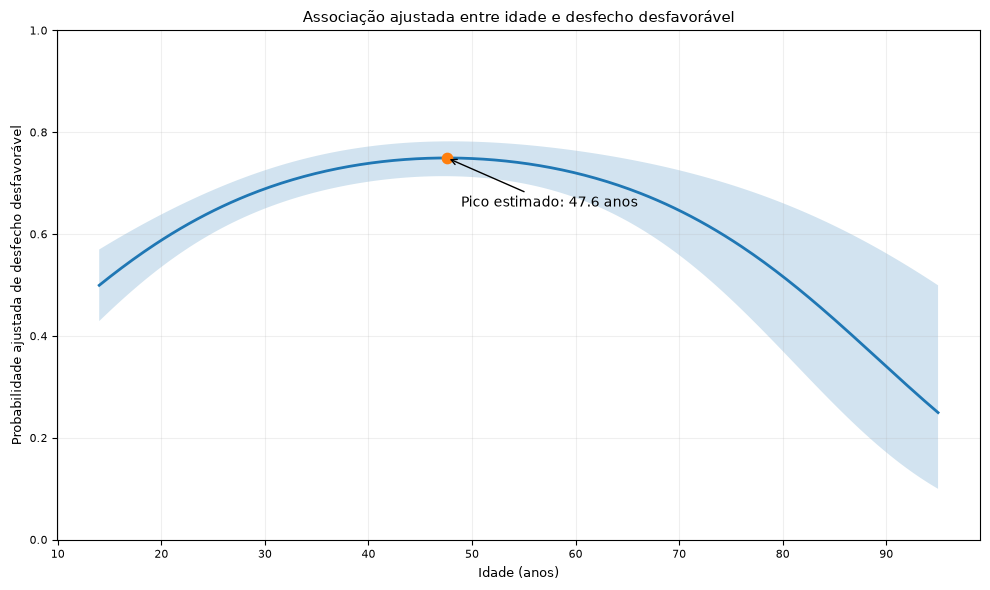


Arquivos gerados:
✓ bloco39_curva_ajustada_idade.png
✓ bloco39_probabilidades_idades_selecionadas.csv

✓ BLOCO 39 CONCLUÍDO.


In [61]:
# =============================================================================
# BLOCO 39 — CURVA AJUSTADA DA IDADE
# Probabilidade ajustada de desfecho desfavorável + IC95%
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


print("=" * 100)
print("BLOCO 39 — CURVA AJUSTADA DA ASSOCIAÇÃO ENTRE IDADE E DESFECHO")
print("=" * 100)


# =============================================================================
# 1. FAIXA ETÁRIA OBSERVADA
# =============================================================================

idade_min = int(df_inferencia_final["IDADE_ANOS"].min())
idade_max = int(df_inferencia_final["IDADE_ANOS"].max())

print(f"\nIdade mínima observada: {idade_min} anos")
print(f"Idade máxima observada: {idade_max} anos")


# Grade contínua para construção da curva
idades_grade = np.linspace(
    idade_min,
    idade_max,
    300
)


# =============================================================================
# 2. PERFIL DE REFERÊNCIA
# =============================================================================
#
# As demais covariáveis são mantidas nas mesmas categorias de referência
# utilizadas no modelo inferencial definitivo.
# =============================================================================

df_pred_idade = pd.DataFrame({
    "IDADE_ANOS": idades_grade,

    "SEXO_LABEL":
        "Feminino",

    "RACA_LABEL":
        "Branca",

    "ESCOLARIDADE_INFERENCIA":
        "Ensino médio completo",

    "SIT_TRAB_LABEL":
        "Empregado registrado",

    "TERCEIRIZA_LABEL":
        "Não",

    "CBO_GRUPO_MODELO":
        "2 — Profissionais das ciências e das artes",

    "CID_INFERENCIA":
        "F4 — Transtornos neuróticos, estresse e somatoformes",

    "ALCOOL_LABEL":
        "Não",

    "DROGAS_LABEL":
        "Não",

    "FUMA_LABEL":
        "Não"
})


# Termos utilizados no modelo definitivo
df_pred_idade["IDADE_10_ANOS"] = (
    df_pred_idade["IDADE_ANOS"] / 10
)

df_pred_idade["IDADE_10_ANOS_QUAD"] = (
    df_pred_idade["IDADE_10_ANOS"] ** 2
)


# =============================================================================
# 3. PREDIÇÕES AJUSTADAS E IC95%
# =============================================================================

predicao_idade = modelo_inferencial_final.get_prediction(
    df_pred_idade
)

predicao_resumo = predicao_idade.summary_frame(
    alpha=0.05
)


# Acrescentar resultados ao DataFrame
df_pred_idade["PROB_AJUSTADA"] = (
    predicao_resumo["mean"].to_numpy()
)

df_pred_idade["IC95_INF"] = (
    predicao_resumo["mean_ci_lower"].to_numpy()
)

df_pred_idade["IC95_SUP"] = (
    predicao_resumo["mean_ci_upper"].to_numpy()
)


# =============================================================================
# 4. IDENTIFICAR O PONTO MÁXIMO DA CURVA
# =============================================================================

indice_max = df_pred_idade["PROB_AJUSTADA"].idxmax()

idade_pico = df_pred_idade.loc[
    indice_max,
    "IDADE_ANOS"
]

prob_pico = df_pred_idade.loc[
    indice_max,
    "PROB_AJUSTADA"
]


print("\n" + "=" * 100)
print("RESUMO DA CURVA")
print("=" * 100)

print(
    f"Maior probabilidade ajustada na grade: "
    f"{prob_pico:.4f}"
)

print(
    f"Idade correspondente .................: "
    f"{idade_pico:.1f} anos"
)


# =============================================================================
# 5. VALORES EM IDADES SELECIONADAS
# =============================================================================

idades_selecionadas = [
    idade
    for idade in [20, 30, 40, 50, 60, 70, 80]
    if idade_min <= idade <= idade_max
]


linhas_resumo = []

for idade in idades_selecionadas:

    indice = (
        df_pred_idade["IDADE_ANOS"] - idade
    ).abs().idxmin()

    linha = df_pred_idade.loc[indice]

    linhas_resumo.append({
        "IDADE": idade,
        "PROB_AJUSTADA": linha["PROB_AJUSTADA"],
        "IC95_INF": linha["IC95_INF"],
        "IC95_SUP": linha["IC95_SUP"]
    })


tabela_idades = pd.DataFrame(linhas_resumo)

print("\nProbabilidades ajustadas em idades selecionadas:\n")

print(
    tabela_idades
    .round(4)
    .to_string(index=False)
)


# =============================================================================
# 6. FIGURA
# =============================================================================

fig, ax = plt.subplots(figsize=(10, 6))


# Curva estimada
ax.plot(
    df_pred_idade["IDADE_ANOS"],
    df_pred_idade["PROB_AJUSTADA"],
    linewidth=2
)


# Intervalo de confiança
ax.fill_between(
    df_pred_idade["IDADE_ANOS"],
    df_pred_idade["IC95_INF"],
    df_pred_idade["IC95_SUP"],
    alpha=0.20
)


# Marcar ponto máximo
ax.scatter(
    idade_pico,
    prob_pico,
    s=55,
    zorder=3
)


ax.annotate(
    f"Pico estimado: {idade_pico:.1f} anos",
    xy=(idade_pico, prob_pico),
    xytext=(10, -35),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"}
)


ax.set_xlabel("Idade (anos)")
ax.set_ylabel(
    "Probabilidade ajustada de desfecho desfavorável"
)

ax.set_title(
    "Associação ajustada entre idade e desfecho desfavorável"
)

ax.set_ylim(0, 1)

ax.grid(
    alpha=0.20
)

plt.tight_layout()


# =============================================================================
# 7. SALVAR FIGURA E DADOS
# =============================================================================

plt.savefig(
    "bloco39_curva_ajustada_idade.png",
    dpi=300,
    bbox_inches="tight"
)

tabela_idades.to_csv(
    "bloco39_probabilidades_idades_selecionadas.csv",
    index=False,
    encoding="utf-8-sig"
)


plt.show()


print("\nArquivos gerados:")
print("✓ bloco39_curva_ajustada_idade.png")
print("✓ bloco39_probabilidades_idades_selecionadas.csv")

print("\n" + "=" * 100)
print("✓ BLOCO 39 CONCLUÍDO.")
print("=" * 100)

### Interpretação da curva ajustada da idade

A representação gráfica da idade confirmou a relação não linear identificada nos diagnósticos do modelo inferencial.

Mantidas as demais covariáveis nas categorias de referência, a probabilidade ajustada de desfecho desfavorável apresentou inicialmente trajetória crescente com o avanço da idade, atingindo seu valor máximo estimado em aproximadamente **47,6 anos**, quando a probabilidade ajustada foi de **74,94%**.

As probabilidades ajustadas estimadas foram de **58,73% aos 20 anos**, **68,88% aos 30 anos**, **73,88% aos 40 anos** e **74,82% aos 50 anos**. Posteriormente, observou-se redução para **71,96% aos 60 anos**, **64,56% aos 70 anos** e **51,53% aos 80 anos**.

A forma estimada é, portanto, compatível com uma curva de **concavidade para baixo**, coerente com o coeficiente negativo encontrado para o termo quadrático da idade no modelo multivariável.

Esse resultado demonstra por que a idade não deve ser resumida por um único odds ratio por incremento de dez anos. A magnitude e a direção da associação variam conforme o ponto da distribuição etária considerado.

O máximo estimado em aproximadamente 47,6 anos deve ser interpretado como o **vértice da função quadrática ajustada**, e não como um ponto de corte clínico ou epidemiológico. O modelo não estabelece a existência de uma idade biologicamente crítica para a ocorrência do desfecho.

Além disso, observa-se maior amplitude dos intervalos de confiança nas idades mais elevadas. Aos 80 anos, por exemplo, a probabilidade ajustada foi estimada em 51,53%, com IC95% de 36,81% a 65,99%. Essa maior incerteza recomenda cautela na interpretação da forma da curva nas extremidades da distribuição etária.

É importante ressaltar que as probabilidades apresentadas são **probabilidades ajustadas para um perfil de referência específico**, mantendo constantes sexo, raça/cor, escolaridade, situação de trabalho, terceirização, grupo ocupacional, grupo diagnóstico e registros de álcool, drogas e tabagismo.

Consequentemente, os valores não representam a prevalência bruta do desfecho em cada idade nem devem ser generalizados como a probabilidade individual de qualquer trabalhador apresentar evolução desfavorável. Sua finalidade é representar visualmente a forma da associação estimada entre idade e desfecho dentro do modelo multivariável.

Assim, a curva ajustada complementa os resultados da regressão logística e permite representar adequadamente a associação não linear da idade, substituindo a interpretação simplificada anteriormente baseada em um único OR por década.

-------

## Bloco 40 — Forest plot do modelo inferencial multivariável final

Após a estimação do modelo inferencial definitivo, os odds ratios ajustados (ORa) e respectivos intervalos de confiança de 95% serão apresentados graficamente por meio de um **forest plot**.

O objetivo da figura é facilitar a visualização da magnitude e da direção das principais associações identificadas no modelo, sem substituir a tabela completa de resultados.

Para preservar a clareza visual, serão excluídas do gráfico categorias administrativas ou relacionadas à qualidade do preenchimento, como:

- `Ignorado`;
- `Não informado`.

Essas categorias permanecem no modelo estatístico, mas não serão destacadas na figura porque sua interpretação não é epidemiológica.

A idade também não será incluída no forest plot, pois foi representada por termos linear e quadrático e, portanto, não possui um único odds ratio constante. Sua associação já foi apresentada separadamente por meio da curva ajustada no Bloco 39.

No gráfico:

- valores de **ORa > 1** indicam maiores odds de desfecho desfavorável em relação à categoria de referência;
- valores de **ORa < 1** indicam menores odds;
- a linha vertical em **OR = 1** representa ausência de diferença;
- intervalos de confiança que cruzam 1 indicam ausência de evidência estatística de associação ao nível de 5%.

Os resultados devem ser interpretados como associações ajustadas e não como relações causais.

BLOCO 40 — FOREST PLOT DO MODELO INFERENCIAL FINAL


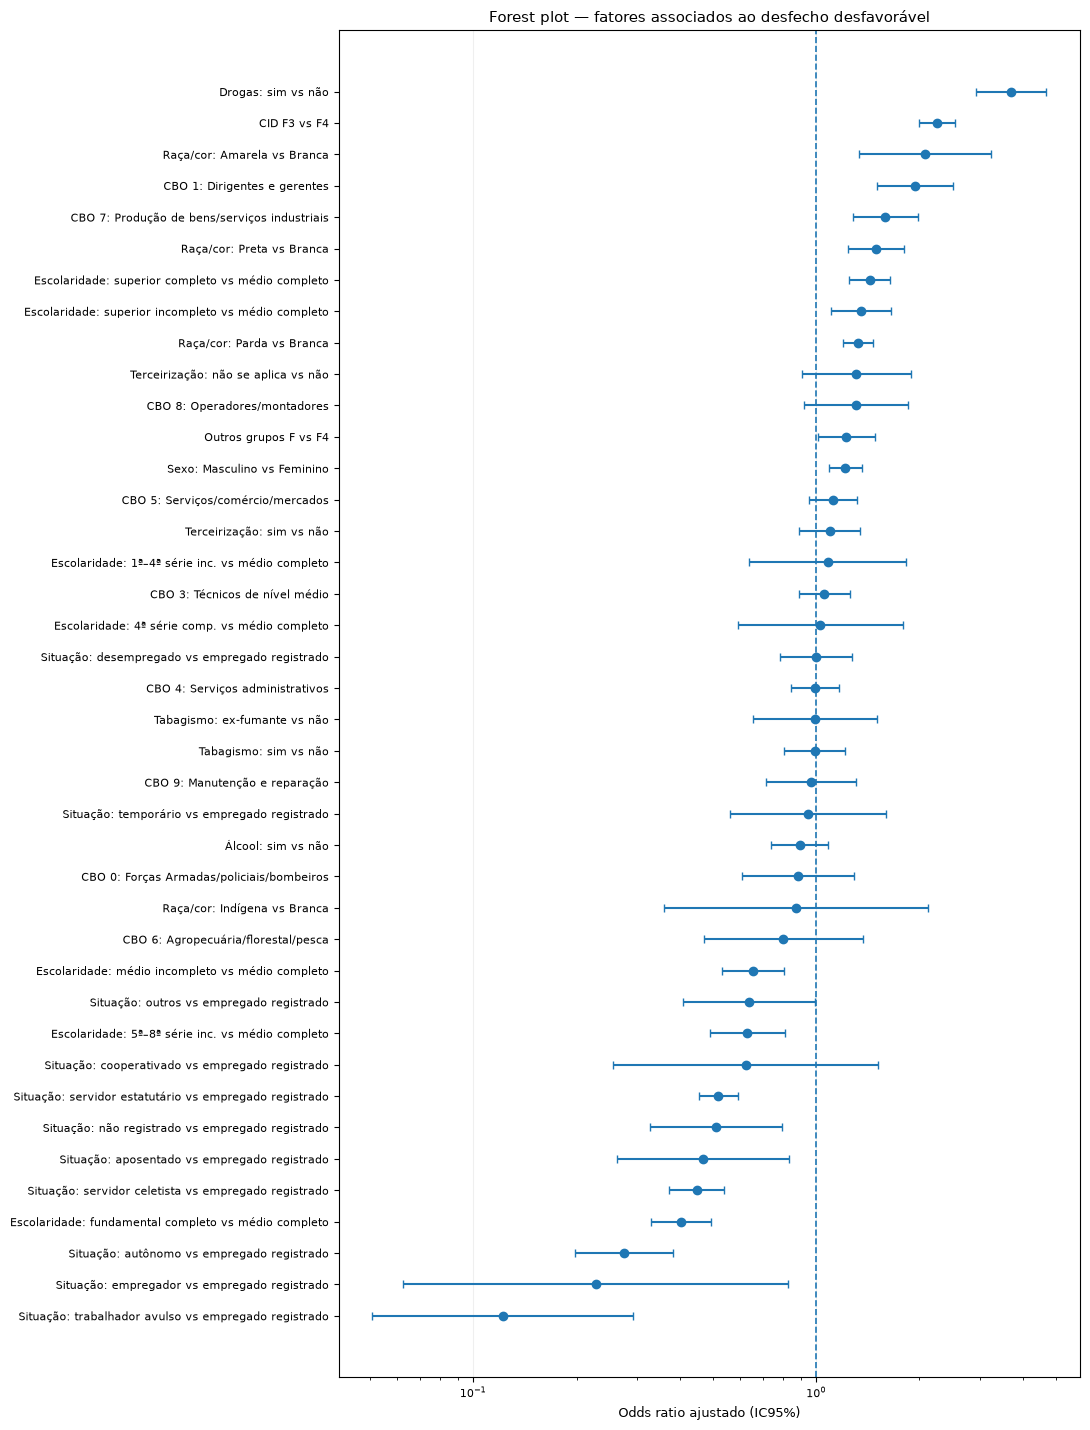


RESUMO DO FOREST PLOT
                                                ROTULO  OR_AJUSTADO  IC95_INF  IC95_SUP  P_VALOR
  Situação: trabalhador avulso vs empregado registrado        0.122     0.051     0.292   0.0000
          Situação: empregador vs empregado registrado        0.227     0.062     0.828   0.0247
            Situação: autônomo vs empregado registrado        0.275     0.198     0.382   0.0000
  Escolaridade: fundamental completo vs médio completo        0.403     0.330     0.492   0.0000
  Situação: servidor celetista vs empregado registrado        0.448     0.372     0.540   0.0000
          Situação: aposentado vs empregado registrado        0.467     0.263     0.832   0.0097
      Situação: não registrado vs empregado registrado        0.511     0.327     0.797   0.0031
Situação: servidor estatutário vs empregado registrado        0.519     0.456     0.589   0.0000
       Situação: cooperativado vs empregado registrado        0.622     0.255     1.516   0.2964
      E

In [62]:
# =============================================================================
# BLOCO 40 — FOREST PLOT DO MODELO INFERENCIAL FINAL
# OR ajustado + IC95%
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


print("=" * 100)
print("BLOCO 40 — FOREST PLOT DO MODELO INFERENCIAL FINAL")
print("=" * 100)


# =============================================================================
# 1. PARTIR DA TABELA FINAL DE ORs DO BLOCO 38
# =============================================================================

df_forest = resultado_or_final.copy()


# =============================================================================
# 2. REMOVER CATEGORIAS NÃO SUBSTANTIVAS PARA A FIGURA
# =============================================================================

padroes_excluir = [
    "Ignorado",
    "Não informado"
]

mascara_excluir = pd.Series(
    False,
    index=df_forest.index
)

for padrao in padroes_excluir:
    mascara_excluir = (
        mascara_excluir |
        df_forest["VARIAVEL"].str.contains(
            padrao,
            case=False,
            na=False,
            regex=False
        )
    )

df_forest = df_forest.loc[
    ~mascara_excluir
].copy()


# =============================================================================
# 3. CRIAR RÓTULOS MAIS CURTOS E LEGÍVEIS
# =============================================================================

rotulos = {
    'C(SEXO_LABEL, Treatment(reference="Feminino"))[T.Masculino]':
        "Sexo: Masculino vs Feminino",

    'C(RACA_LABEL, Treatment(reference="Branca"))[T.Amarela]':
        "Raça/cor: Amarela vs Branca",

    'C(RACA_LABEL, Treatment(reference="Branca"))[T.Indígena]':
        "Raça/cor: Indígena vs Branca",

    'C(RACA_LABEL, Treatment(reference="Branca"))[T.Parda]':
        "Raça/cor: Parda vs Branca",

    'C(RACA_LABEL, Treatment(reference="Branca"))[T.Preta]':
        "Raça/cor: Preta vs Branca",

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.1ª a 4ª série incompleta do EF]':
        "Escolaridade: 1ª–4ª série inc. vs médio completo",

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.4ª série completa do EF]':
        "Escolaridade: 4ª série comp. vs médio completo",

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.5ª a 8ª série incompleta do EF]':
        "Escolaridade: 5ª–8ª série inc. vs médio completo",

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.Baixa escolaridade / sem escolarização formal]':
        "Escolaridade: baixa/sem escolarização vs médio completo",

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.Educação superior completa]':
        "Escolaridade: superior completo vs médio completo",

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.Educação superior incompleta]':
        "Escolaridade: superior incompleto vs médio completo",

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.Ensino fundamental completo]':
        "Escolaridade: fundamental completo vs médio completo",

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.Ensino médio incompleto]':
        "Escolaridade: médio incompleto vs médio completo",

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Aposentado]':
        "Situação: aposentado vs empregado registrado",

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Autônomo/conta própria]':
        "Situação: autônomo vs empregado registrado",

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Cooperativado]':
        "Situação: cooperativado vs empregado registrado",

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Desempregado]':
        "Situação: desempregado vs empregado registrado",

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Empregado não registrado]':
        "Situação: não registrado vs empregado registrado",

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Empregador]':
        "Situação: empregador vs empregado registrado",

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Outros]':
        "Situação: outros vs empregado registrado",

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Servidor público celetista]':
        "Situação: servidor celetista vs empregado registrado",

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Servidor público estatutário]':
        "Situação: servidor estatutário vs empregado registrado",

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Trabalhador avulso]':
        "Situação: trabalhador avulso vs empregado registrado",

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Trabalho temporário]':
        "Situação: temporário vs empregado registrado",

    'C(TERCEIRIZA_LABEL, Treatment(reference="Não"))[T.Não se aplica]':
        "Terceirização: não se aplica vs não",

    'C(TERCEIRIZA_LABEL, Treatment(reference="Não"))[T.Sim]':
        "Terceirização: sim vs não",

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.0 — Forças Armadas, policiais e bombeiros militares]':
        "CBO 0: Forças Armadas/policiais/bombeiros",

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.1 — Dirigentes e gerentes]':
        "CBO 1: Dirigentes e gerentes",

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.3 — Técnicos de nível médio]':
        "CBO 3: Técnicos de nível médio",

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.4 — Trabalhadores de serviços administrativos]':
        "CBO 4: Serviços administrativos",

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.5 — Trabalhadores dos serviços, comércio e mercados]':
        "CBO 5: Serviços/comércio/mercados",

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.6 — Trabalhadores agropecuários, florestais e da pesca]':
        "CBO 6: Agropecuária/florestal/pesca",

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.7 — Trabalhadores da produção de bens e serviços industriais]':
        "CBO 7: Produção de bens/serviços industriais",

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.8 — Trabalhadores da produção industrial, operadores e montadores]':
        "CBO 8: Operadores/montadores",

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.9 — Trabalhadores de manutenção e reparação]':
        "CBO 9: Manutenção e reparação",

    'C(CID_INFERENCIA, Treatment(reference="F4 — Transtornos neuróticos, estresse e somatoformes"))[T.F3 — Transtornos do humor]':
        "CID F3 vs F4",

    'C(CID_INFERENCIA, Treatment(reference="F4 — Transtornos neuróticos, estresse e somatoformes"))[T.Outros grupos F]':
        "Outros grupos F vs F4",

    'C(ALCOOL_LABEL, Treatment(reference="Não"))[T.Sim]':
        "Álcool: sim vs não",

    'C(DROGAS_LABEL, Treatment(reference="Não"))[T.Sim]':
        "Drogas: sim vs não",

    'C(FUMA_LABEL, Treatment(reference="Não"))[T.Ex-fumante]':
        "Tabagismo: ex-fumante vs não",

    'C(FUMA_LABEL, Treatment(reference="Não"))[T.Sim]':
        "Tabagismo: sim vs não"
}


df_forest["ROTULO"] = (
    df_forest["VARIAVEL"]
    .map(rotulos)
    .fillna(df_forest["VARIAVEL"])
)


# =============================================================================
# 4. REMOVER CATEGORIA "BAIXA ESCOLARIDADE" DA FIGURA PRINCIPAL
# =============================================================================
#
# Essa categoria apresentou IC extremamente amplo por baixa frequência.
# O resultado permanece disponível na tabela completa.
# =============================================================================

df_forest = df_forest.loc[
    ~df_forest["ROTULO"].str.contains(
        "baixa/sem escolarização",
        case=False,
        na=False
    )
].copy()


# =============================================================================
# 5. ORDENAR POR OR AJUSTADO
# =============================================================================

df_forest = (
    df_forest
    .sort_values("OR_AJUSTADO")
    .reset_index(drop=True)
)


# =============================================================================
# 6. FOREST PLOT
# =============================================================================

y = np.arange(len(df_forest))

fig, ax = plt.subplots(
    figsize=(11, max(10, len(df_forest) * 0.36))
)


# Intervalos de confiança
xerr = np.vstack([
    df_forest["OR_AJUSTADO"] - df_forest["IC95_INF"],
    df_forest["IC95_SUP"] - df_forest["OR_AJUSTADO"]
])


ax.errorbar(
    df_forest["OR_AJUSTADO"],
    y,
    xerr=xerr,
    fmt="o",
    capsize=3
)


# Linha de nulidade
ax.axvline(
    1,
    linestyle="--",
    linewidth=1.2
)


ax.set_yticks(y)
ax.set_yticklabels(df_forest["ROTULO"])

ax.set_xlabel("Odds ratio ajustado (IC95%)")
ax.set_ylabel("")

ax.set_title(
    "Forest plot — fatores associados ao desfecho desfavorável"
)


# Escala logarítmica
ax.set_xscale("log")


# Grade leve
ax.grid(
    axis="x",
    alpha=0.20
)


plt.tight_layout()


# =============================================================================
# 7. SALVAR FIGURA
# =============================================================================

plt.savefig(
    "bloco40_forest_plot_modelo_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =============================================================================
# 8. TABELA RESUMIDA DO FOREST
# =============================================================================

tabela_forest = df_forest[
    [
        "ROTULO",
        "OR_AJUSTADO",
        "IC95_INF",
        "IC95_SUP",
        "P_VALOR"
    ]
].copy()


tabela_forest.to_csv(
    "bloco40_dados_forest_plot.csv",
    index=False,
    encoding="utf-8-sig"
)


print("\n" + "=" * 100)
print("RESUMO DO FOREST PLOT")
print("=" * 100)

print(
    tabela_forest
    .round({
        "OR_AJUSTADO": 3,
        "IC95_INF": 3,
        "IC95_SUP": 3,
        "P_VALOR": 4
    })
    .to_string(index=False)
)


print("\nArquivos gerados:")
print("✓ bloco40_forest_plot_modelo_final.png")
print("✓ bloco40_dados_forest_plot.csv")

print("\n" + "=" * 100)
print("✓ BLOCO 40 CONCLUÍDO.")
print("=" * 100)

### Interpretação do forest plot

O forest plot apresenta graficamente os odds ratios ajustados e respectivos intervalos de confiança de 95% das comparações substantivas do modelo inferencial multivariável definitivo.

A linha vertical em OR = 1 representa ausência de diferença em relação à categoria de referência. Estimativas posicionadas à direita dessa linha correspondem a maiores odds de desfecho desfavorável, enquanto estimativas à esquerda correspondem a menores odds. Quando o intervalo de confiança inclui o valor 1, não há evidência estatística de diferença ao nível de significância de 5%.

Entre as associações positivas de maior magnitude, destacou-se o registro de **uso de drogas**, com ORa = 3,699 (IC95%: 2,919–4,688), indicando odds de desfecho desfavorável aproximadamente 3,7 vezes aquelas observadas entre os registros sem indicação de uso de drogas, após ajuste pelas demais características.

Os **transtornos do humor (F3)** também apresentaram associação expressiva quando comparados aos transtornos neuróticos, relacionados ao estresse e somatoformes (F4), com ORa = 2,257 (IC95%: 2,000–2,546).

No componente ocupacional, **dirigentes e gerentes** apresentaram ORa = 1,941 (IC95%: 1,507–2,500), enquanto **trabalhadores da produção de bens e serviços industriais** apresentaram ORa = 1,590 (IC95%: 1,279–1,975), ambos em comparação aos profissionais das ciências e das artes.

O sexo masculino apresentou associação positiva de menor magnitude, porém estatisticamente significativa, com ORa = 1,216 (IC95%: 1,091–1,356), tendo o sexo feminino como referência.

Por outro lado, diversas comparações apresentaram intervalos de confiança que cruzaram a linha de nulidade, como terceirização “Sim” versus “Não”, uso de álcool “Sim” versus “Não” e tabagismo “Sim” versus “Não”. Esses resultados indicam ausência de evidência estatística de associação independente para essas comparações na especificação multivariável utilizada.

Algumas categorias de situação de trabalho apresentaram ORa inferiores a 1 em relação aos empregados registrados. Esses resultados representam associações condicionais observadas entre os registros e **não devem ser interpretados automaticamente como efeitos protetores**, considerando o caráter observacional dos dados e possíveis diferenças no processo de notificação e composição dos grupos.

Categorias correspondentes a informações ignoradas ou não informadas foram mantidas no ajuste estatístico, mas omitidas do forest plot por não possuírem interpretação epidemiológica substantiva.

A idade também não foi incluída nesta figura, pois sua associação foi modelada por termos linear e quadrático e não pode ser representada adequadamente por um único odds ratio. Sua forma funcional foi apresentada separadamente por meio da curva de probabilidade ajustada.

Assim, o forest plot complementa a tabela completa do modelo ao permitir a identificação visual das associações de maior magnitude, da precisão das estimativas e das comparações compatíveis com ausência de associação estatisticamente significativa.

-----------------

## Bloco 41 — Tabela final do modelo inferencial para apresentação no TCC

Após a definição da especificação multivariável final, os resultados do modelo foram organizados em uma tabela destinada à apresentação no TCC.

A tabela apresenta, para cada comparação substantiva:

- variável analisada;
- categoria comparada;
- categoria de referência;
- odds ratio ajustado (ORa);
- intervalo de confiança de 95% (IC95%);
- valor de $p$.

Os odds ratios correspondem ao modelo de regressão logística multivariável definitivo, estimado por GLM binomial com função de ligação logit e erros-padrão robustos HC3.

Categorias classificadas como `Ignorado` ou `Não informado` permaneceram no ajuste estatístico, de modo a preservar a especificação do modelo, mas foram omitidas da tabela principal destinada à interpretação epidemiológica. Os resultados completos dessas categorias permanecem disponíveis na saída integral do modelo.

A idade também não é apresentada como um odds ratio isolado, uma vez que sua associação foi representada simultaneamente pelos termos linear e quadrático. A relação ajustada da idade com o desfecho foi apresentada graficamente no Bloco 39.

Para as variáveis categóricas, cada ORa deve ser interpretado em relação à categoria de referência explicitamente indicada na tabela.

Valores de:

$$
OR_a > 1
$$

indicam maiores odds de desfecho desfavorável em relação à categoria de referência, enquanto:

$$
OR_a < 1
$$

indicam menores odds.

Os resultados representam associações ajustadas e não devem ser interpretados como estimativas causais ou como riscos relativos.

In [64]:
%pip install openpyxl -q

Note: you may need to restart the kernel to use updated packages.


In [65]:
# =============================================================================
# BLOCO 41 — TABELA FINAL DO MODELO INFERENCIAL PARA O TCC
# =============================================================================

import numpy as np
import pandas as pd


print("=" * 100)
print("BLOCO 41 — TABELA FINAL DO MODELO INFERENCIAL PARA O TCC")
print("=" * 100)


# =============================================================================
# 1. PARTIR DOS ORs DEFINITIVOS DO BLOCO 38
# =============================================================================

tabela_tcc = resultado_or_final.copy()


# =============================================================================
# 2. DICIONÁRIO PARA TRADUZIR OS TERMOS DO STATSMODELS
# =============================================================================

mapa_tabela = {

    # -------------------------------------------------------------------------
    # SEXO
    # -------------------------------------------------------------------------
    'C(SEXO_LABEL, Treatment(reference="Feminino"))[T.Masculino]':
        ("Sexo", "Masculino", "Feminino"),

    # -------------------------------------------------------------------------
    # RAÇA/COR
    # -------------------------------------------------------------------------
    'C(RACA_LABEL, Treatment(reference="Branca"))[T.Amarela]':
        ("Raça/cor", "Amarela", "Branca"),

    'C(RACA_LABEL, Treatment(reference="Branca"))[T.Indígena]':
        ("Raça/cor", "Indígena", "Branca"),

    'C(RACA_LABEL, Treatment(reference="Branca"))[T.Parda]':
        ("Raça/cor", "Parda", "Branca"),

    'C(RACA_LABEL, Treatment(reference="Branca"))[T.Preta]':
        ("Raça/cor", "Preta", "Branca"),

    # -------------------------------------------------------------------------
    # ESCOLARIDADE
    # -------------------------------------------------------------------------
    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.1ª a 4ª série incompleta do EF]':
        ("Escolaridade", "1ª a 4ª série incompleta do EF", "Ensino médio completo"),

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.4ª série completa do EF]':
        ("Escolaridade", "4ª série completa do EF", "Ensino médio completo"),

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.5ª a 8ª série incompleta do EF]':
        ("Escolaridade", "5ª a 8ª série incompleta do EF", "Ensino médio completo"),

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.Baixa escolaridade / sem escolarização formal]':
        ("Escolaridade", "Baixa escolaridade / sem escolarização formal", "Ensino médio completo"),

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.Educação superior completa]':
        ("Escolaridade", "Educação superior completa", "Ensino médio completo"),

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.Educação superior incompleta]':
        ("Escolaridade", "Educação superior incompleta", "Ensino médio completo"),

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.Ensino fundamental completo]':
        ("Escolaridade", "Ensino fundamental completo", "Ensino médio completo"),

    'C(ESCOLARIDADE_INFERENCIA, Treatment(reference="Ensino médio completo"))[T.Ensino médio incompleto]':
        ("Escolaridade", "Ensino médio incompleto", "Ensino médio completo"),

    # -------------------------------------------------------------------------
    # SITUAÇÃO DE TRABALHO
    # -------------------------------------------------------------------------
    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Aposentado]':
        ("Situação de trabalho", "Aposentado", "Empregado registrado"),

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Autônomo/conta própria]':
        ("Situação de trabalho", "Autônomo/conta própria", "Empregado registrado"),

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Cooperativado]':
        ("Situação de trabalho", "Cooperativado", "Empregado registrado"),

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Desempregado]':
        ("Situação de trabalho", "Desempregado", "Empregado registrado"),

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Empregado não registrado]':
        ("Situação de trabalho", "Empregado não registrado", "Empregado registrado"),

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Empregador]':
        ("Situação de trabalho", "Empregador", "Empregado registrado"),

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Outros]':
        ("Situação de trabalho", "Outros", "Empregado registrado"),

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Servidor público celetista]':
        ("Situação de trabalho", "Servidor público celetista", "Empregado registrado"),

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Servidor público estatutário]':
        ("Situação de trabalho", "Servidor público estatutário", "Empregado registrado"),

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Trabalhador avulso]':
        ("Situação de trabalho", "Trabalhador avulso", "Empregado registrado"),

    'C(SIT_TRAB_LABEL, Treatment(reference="Empregado registrado"))[T.Trabalho temporário]':
        ("Situação de trabalho", "Trabalho temporário", "Empregado registrado"),

    # -------------------------------------------------------------------------
    # TERCEIRIZAÇÃO
    # -------------------------------------------------------------------------
    'C(TERCEIRIZA_LABEL, Treatment(reference="Não"))[T.Não se aplica]':
        ("Terceirização", "Não se aplica", "Não"),

    'C(TERCEIRIZA_LABEL, Treatment(reference="Não"))[T.Sim]':
        ("Terceirização", "Sim", "Não"),

    # -------------------------------------------------------------------------
    # CBO
    # -------------------------------------------------------------------------
    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.0 — Forças Armadas, policiais e bombeiros militares]':
        ("Grupo ocupacional", "Forças Armadas, policiais e bombeiros militares",
         "Profissionais das ciências e das artes"),

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.1 — Dirigentes e gerentes]':
        ("Grupo ocupacional", "Dirigentes e gerentes",
         "Profissionais das ciências e das artes"),

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.3 — Técnicos de nível médio]':
        ("Grupo ocupacional", "Técnicos de nível médio",
         "Profissionais das ciências e das artes"),

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.4 — Trabalhadores de serviços administrativos]':
        ("Grupo ocupacional", "Trabalhadores de serviços administrativos",
         "Profissionais das ciências e das artes"),

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.5 — Trabalhadores dos serviços, comércio e mercados]':
        ("Grupo ocupacional", "Trabalhadores dos serviços, comércio e mercados",
         "Profissionais das ciências e das artes"),

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.6 — Trabalhadores agropecuários, florestais e da pesca]':
        ("Grupo ocupacional", "Trabalhadores agropecuários, florestais e da pesca",
         "Profissionais das ciências e das artes"),

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.7 — Trabalhadores da produção de bens e serviços industriais]':
        ("Grupo ocupacional", "Trabalhadores da produção de bens e serviços industriais",
         "Profissionais das ciências e das artes"),

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.8 — Trabalhadores da produção industrial, operadores e montadores]':
        ("Grupo ocupacional", "Operadores e montadores",
         "Profissionais das ciências e das artes"),

    'C(CBO_GRUPO_MODELO, Treatment(reference="2 — Profissionais das ciências e das artes"))[T.9 — Trabalhadores de manutenção e reparação]':
        ("Grupo ocupacional", "Trabalhadores de manutenção e reparação",
         "Profissionais das ciências e das artes"),

    # -------------------------------------------------------------------------
    # CID
    # -------------------------------------------------------------------------
    'C(CID_INFERENCIA, Treatment(reference="F4 — Transtornos neuróticos, estresse e somatoformes"))[T.F3 — Transtornos do humor]':
        ("Grupo diagnóstico", "F3 — Transtornos do humor",
         "F4 — Transtornos neuróticos, estresse e somatoformes"),

    'C(CID_INFERENCIA, Treatment(reference="F4 — Transtornos neuróticos, estresse e somatoformes"))[T.Outros grupos F]':
        ("Grupo diagnóstico", "Outros grupos F",
         "F4 — Transtornos neuróticos, estresse e somatoformes"),

    # -------------------------------------------------------------------------
    # ÁLCOOL
    # -------------------------------------------------------------------------
    'C(ALCOOL_LABEL, Treatment(reference="Não"))[T.Sim]':
        ("Uso de álcool", "Sim", "Não"),

    # -------------------------------------------------------------------------
    # DROGAS
    # -------------------------------------------------------------------------
    'C(DROGAS_LABEL, Treatment(reference="Não"))[T.Sim]':
        ("Uso de drogas", "Sim", "Não"),

    # -------------------------------------------------------------------------
    # TABAGISMO
    # -------------------------------------------------------------------------
    'C(FUMA_LABEL, Treatment(reference="Não"))[T.Ex-fumante]':
        ("Tabagismo", "Ex-fumante", "Não"),

    'C(FUMA_LABEL, Treatment(reference="Não"))[T.Sim]':
        ("Tabagismo", "Sim", "Não")
}


# =============================================================================
# 3. MANTER APENAS COMPARAÇÕES SUBSTANTIVAS MAPEADAS
# =============================================================================

tabela_tcc = tabela_tcc.loc[
    tabela_tcc["VARIAVEL"].isin(mapa_tabela.keys())
].copy()


# Traduzir os termos
tabela_tcc["VARIAVEL_TCC"] = tabela_tcc["VARIAVEL"].map(
    lambda x: mapa_tabela[x][0]
)

tabela_tcc["CATEGORIA"] = tabela_tcc["VARIAVEL"].map(
    lambda x: mapa_tabela[x][1]
)

tabela_tcc["REFERENCIA"] = tabela_tcc["VARIAVEL"].map(
    lambda x: mapa_tabela[x][2]
)


# =============================================================================
# 4. FORMATAR OR E IC95%
# =============================================================================

tabela_tcc["ORa (IC95%)"] = tabela_tcc.apply(
    lambda linha:
        f'{linha["OR_AJUSTADO"]:.3f} '
        f'({linha["IC95_INF"]:.3f}–{linha["IC95_SUP"]:.3f})',
    axis=1
)


# =============================================================================
# 5. FORMATAR P-VALOR
# =============================================================================

def formatar_p(p):

    if p < 0.001:
        return "<0,001"

    return f"{p:.3f}".replace(".", ",")


tabela_tcc["p-valor"] = tabela_tcc["P_VALOR"].apply(
    formatar_p
)


# =============================================================================
# 6. TABELA FINAL
# =============================================================================

tabela_tcc_final = tabela_tcc[
    [
        "VARIAVEL_TCC",
        "CATEGORIA",
        "REFERENCIA",
        "ORa (IC95%)",
        "p-valor"
    ]
].copy()


tabela_tcc_final.columns = [
    "Variável",
    "Categoria",
    "Referência",
    "ORa (IC95%)",
    "p-valor"
]


# =============================================================================
# 7. VERIFICAÇÕES
# =============================================================================

assert len(tabela_tcc_final) > 0

assert tabela_tcc_final[
    ["Variável", "Categoria", "Referência"]
].notna().all().all()


print("\nNúmero de comparações apresentadas:",
      len(tabela_tcc_final))


print("\n" + "=" * 100)
print("TABELA FINAL — MODELO INFERENCIAL")
print("=" * 100)

print(
    tabela_tcc_final.to_string(
        index=False
    )
)


# =============================================================================
# 8. EXPORTAÇÃO
# =============================================================================

tabela_tcc_final.to_csv(
    "bloco41_tabela_modelo_inferencial_TCC.csv",
    index=False,
    encoding="utf-8-sig"
)

tabela_tcc_final.to_excel(
    "bloco41_tabela_modelo_inferencial_TCC.xlsx",
    index=False
)


print("\nArquivos gerados:")
print("✓ bloco41_tabela_modelo_inferencial_TCC.csv")
print("✓ bloco41_tabela_modelo_inferencial_TCC.xlsx")


print("\nNota para a tabela:")
print(
    "ORa = odds ratio ajustado; IC95% = intervalo de confiança de 95%. "
    "Modelo GLM binomial com ligação logit e erros-padrão robustos HC3. "
    "A idade foi modelada por termos linear e quadrático e, portanto, "
    "não é apresentada como OR isolado."
)


print("\n" + "=" * 100)
print("✓ BLOCO 41 CONCLUÍDO.")
print("=" * 100)

BLOCO 41 — TABELA FINAL DO MODELO INFERENCIAL PARA O TCC

Número de comparações apresentadas: 41

TABELA FINAL — MODELO INFERENCIAL
            Variável                                                Categoria                                           Referência          ORa (IC95%) p-valor
                Sexo                                                Masculino                                             Feminino  1.216 (1.091–1.356)  <0,001
            Raça/cor                                                  Amarela                                               Branca  2.078 (1.337–3.232)   0,001
            Raça/cor                                                 Indígena                                               Branca  0.873 (0.360–2.117)   0,764
            Raça/cor                                                    Parda                                               Branca  1.324 (1.193–1.469)  <0,001
            Raça/cor                                                

### Interpretação da tabela final do modelo inferencial

A tabela final sintetiza as associações estimadas pelo modelo de regressão logística multivariável definitivo, apresentando os **odds ratios ajustados (ORa)**, os respectivos **intervalos de confiança de 95% (IC95%)** e os valores de $p$ para as comparações de interesse epidemiológico.

As estimativas foram obtidas simultaneamente no mesmo modelo, de modo que cada associação apresentada está ajustada pelas demais características incluídas na análise. As categorias classificadas como `Ignorado` ou `Não informado` foram mantidas durante a estimação do modelo, mas omitidas desta tabela de apresentação por não constituírem categorias de interesse epidemiológico substantivo.

A idade também não é apresentada por meio de um ORa único, pois os diagnósticos demonstraram associação não linear com o desfecho. Sua relação foi representada por termos linear e quadrático no modelo definitivo e apresentada separadamente por meio da curva de probabilidade ajustada.

#### Principais associações com maiores odds de desfecho desfavorável

Entre as características avaliadas, o **registro de uso de drogas** apresentou a associação positiva de maior magnitude:

$$
OR_a = 3{,}699
$$

com IC95% de **2,919 a 4,688** e $p<0,001$.

Assim, mantidas constantes as demais características incluídas no modelo, os registros com indicação de uso de drogas apresentaram aproximadamente **3,7 vezes as odds de desfecho desfavorável** em comparação aos registros sem indicação de uso.

O **grupo diagnóstico F3 — transtornos do humor** também apresentou associação expressiva. Em comparação ao grupo F4 — transtornos neuróticos, relacionados ao estresse e somatoformes —, foi observado:

$$
OR_a = 2{,}257
$$

com IC95% de **2,000 a 2,546** e $p<0,001$.

No componente ocupacional, os **dirigentes e gerentes** apresentaram ORa = **1,941** (IC95%: 1,507–2,500; $p<0,001$), enquanto os **trabalhadores da produção de bens e serviços industriais** apresentaram ORa = **1,590** (IC95%: 1,279–1,975; $p<0,001$), tendo como referência os profissionais das ciências e das artes.

O sexo masculino também permaneceu associado a maiores odds do desfecho:

$$
OR_a = 1{,}216
$$

(IC95%: 1,091–1,356; $p<0,001$),

em comparação ao sexo feminino.

#### Raça/cor

Tomando os registros de raça/cor branca como referência, foram observadas maiores odds de desfecho desfavorável para as categorias:

- amarela: ORa = **2,078** (IC95%: 1,337–3,232; $p=0,001$);
- preta: ORa = **1,493** (IC95%: 1,236–1,804; $p<0,001$);
- parda: ORa = **1,324** (IC95%: 1,193–1,469; $p<0,001$).

Para a categoria indígena, o intervalo de confiança incluiu a unidade (ORa = 0,873; IC95%: 0,360–2,117; $p=0,764$), não havendo evidência estatística de diferença em relação à categoria branca após o ajuste.

Essas associações devem ser interpretadas no contexto dos registros analisados e não como evidência de efeitos biológicos atribuíveis à raça/cor.

#### Escolaridade

A escolaridade apresentou padrão heterogêneo.

Em comparação ao ensino médio completo, a **educação superior completa** apresentou ORa = **1,431** (IC95%: 1,246–1,643; $p<0,001$), e a **educação superior incompleta**, ORa = **1,350** (IC95%: 1,104–1,652; $p=0,004$).

Em sentido oposto, foram observadas menores odds para:

- 5ª a 8ª série incompleta do ensino fundamental: ORa = **0,629** (IC95%: 0,489–0,809; $p<0,001$);
- ensino fundamental completo: ORa = **0,403** (IC95%: 0,330–0,492; $p<0,001$);
- ensino médio incompleto: ORa = **0,654** (IC95%: 0,532–0,804; $p<0,001$).

A categoria de baixa escolaridade/sem escolarização formal apresentou ORa = **2,653**, porém com intervalo de confiança muito amplo (IC95%: 0,545–12,925; $p=0,227$). A elevada amplitude do intervalo é consistente com a baixa frequência dessa categoria identificada na auditoria anterior e indica grande imprecisão da estimativa. Portanto, esse resultado não constitui evidência estatística de associação.

#### Situação de trabalho

Diversas categorias de situação de trabalho apresentaram ORa inferiores a 1 quando comparadas aos empregados registrados.

Esses resultados indicam diferenças nas odds ajustadas entre as categorias presentes nos registros, mas **não devem ser interpretados como evidência de efeito protetor** das respectivas situações ocupacionais.

A natureza observacional da base, possíveis diferenças no perfil dos trabalhadores notificados, acesso aos serviços, características do vínculo e processo de notificação podem contribuir para essas associações.

#### Terceirização

A comparação de maior interesse para terceirização não apresentou associação estatisticamente significativa:

$$
OR_a = 1{,}095
$$

(IC95%: 0,892–1,345; $p=0,385$)

para trabalhadores classificados como terceirizados em comparação aos não terceirizados.

Assim, após o ajuste simultâneo pelas demais características do modelo, não foi encontrada evidência estatística suficiente de associação independente entre terceirização e o desfecho desfavorável na população de registros analisada.

#### Álcool, drogas e tabagismo

Os resultados das três variáveis comportamentais foram distintos.

O registro de **uso de drogas** apresentou forte associação positiva com o desfecho, com ORa = **3,699** (IC95%: 2,919–4,688; $p<0,001$).

Por outro lado, o registro de **uso de álcool** não apresentou associação estatisticamente significativa na comparação `Sim` versus `Não`:

$$
OR_a = 0{,}895
$$

(IC95%: 0,738–1,085; $p=0,258$).

Da mesma forma, o **tabagismo** não apresentou associação independente na comparação `Sim` versus `Não`:

$$
OR_a = 0{,}989
$$

(IC95%: 0,806–1,214; $p=0,915$).

A categoria ex-fumante também não apresentou evidência de diferença em relação aos não fumantes (ORa = 0,990; IC95%: 0,652–1,501; $p=0,961$).

### Considerações para interpretação da tabela

Os valores apresentados correspondem a **odds ratios ajustados**, e não a riscos relativos ou probabilidades diretamente comparáveis entre grupos.

Como o desfecho desfavorável é frequente na população analisada, a distinção é especialmente importante: um ORa de 2,0 significa duas vezes as **odds** do desfecho em relação à categoria de referência, e não necessariamente duas vezes a probabilidade do desfecho.

Além disso, os resultados representam **associações condicionais observadas nos registros do SINAN incluídos na análise**. O delineamento observacional não permite estabelecer relações de causalidade.

A interpretação substantiva deve priorizar simultaneamente a magnitude do ORa, a amplitude do intervalo de confiança, a significância estatística e a plausibilidade epidemiológica, evitando selecionar resultados apenas com base no valor de $p$.

Em conjunto, a tabela final evidencia como principais associações positivas com o desfecho desfavorável o **uso de drogas**, os **transtornos do humor (F3)**, determinados **grupos ocupacionais**, especialmente dirigentes e gerentes e trabalhadores da produção de bens e serviços industriais, e o **sexo masculino**, além de diferenças observadas segundo raça/cor e escolaridade.

Esses resultados constituem a síntese inferencial principal do estudo e serão integrados, na etapa final, aos resultados descritivos e à avaliação preditiva com validação temporal.

-----------------------

## Bloco 42 — Síntese final dos resultados

Este bloco consolida os principais resultados obtidos ao longo do fluxo analítico, sem realizar novas estimações ou modificar os modelos previamente definidos.

A análise foi estruturada em etapas complementares: construção da coorte epidemiológica, definição do desfecho, análise descritiva, modelagem preditiva com validação temporal e análise inferencial multivariável.

### População analisada

Após limpeza e remoção de duplicidades exatas, a base continha **24.351 registros**.

A coorte epidemiológica principal, restrita aos diagnósticos classificados nos capítulos **F00–F99**, compreendeu **18.292 registros**.

Para a análise do desfecho foram considerados apenas registros cuja evolução permitia classificação em dois grupos:

- **favorável:** cura ou cura não confirmada;
- **desfavorável:** incapacidade temporária, incapacidade permanente parcial, incapacidade permanente total ou óbito por doença relacionada ao trabalho.

Foram excluídas da definição do desfecho as categorias óbito por outra causa, outro, ignorado e registros sem informação classificável.

A população elegível para essa etapa foi de **13.598 registros**, dos quais:

$$
11.027\;(81,09\%)
$$

apresentaram desfecho desfavorável e:

$$
2.571\;(18,91\%)
$$

apresentaram desfecho favorável.

A incapacidade temporária representou a maior parcela dos desfechos classificados como desfavoráveis.

### Distribuição temporal

Os registros disponíveis abrangeram os anos de **2014 a 2019 e de 2022 a 2025**.

Não foram observados registros para 2020 e 2021 na fonte utilizada. Essa ausência foi tratada como **lacuna na série disponível**, e não como ocorrência igual a zero.

Embora tenham sido encontrados registros em todos os meses de 2025, a data mais recente de notificação identificada foi 8 de dezembro de 2025. Por esse motivo, os resultados referentes a esse ano foram tratados com cautela quanto à consolidação temporal.

### Perfil diagnóstico

Os grupos F4 e F3 concentraram a maior parte da coorte epidemiológica.

Os transtornos neuróticos, relacionados ao estresse e somatoformes (F4) constituíram o grupo predominante, seguidos pelos transtornos do humor (F3).

Essa concentração justificou a utilização de F4 como categoria de referência e a comparação específica entre F3, F4 e os demais grupos F na análise inferencial.

---

## Modelagem preditiva

A etapa preditiva teve como objetivo avaliar a capacidade de discriminar registros com evolução favorável e desfavorável em períodos posteriores.

Foram comparados:

- regressão logística;
- Random Forest;
- XGBoost;
- LightGBM.

O desenvolvimento foi realizado com os anos de **2014–2023**, respeitando a estrutura temporal dos dados.

Além da avaliação em 2024 e 2025, foi realizada validação temporal interna por esquema expansivo, no qual períodos anteriores foram utilizados para predizer períodos posteriores.

Na validação temporal interna agregada, a regressão logística apresentou:

$$
ROC\text{-}AUC = 0,707
$$

e:

$$
PR\text{-}AUC = 0,913.
$$

O XGBoost apresentou desempenho próximo:

$$
ROC\text{-}AUC = 0,700
$$

e:

$$
PR\text{-}AUC = 0,912.
$$

A regressão logística apresentou o maior ROC-AUC temporal agregado e o maior desempenho anual em quatro das cinco avaliações temporais realizadas, enquanto o XGBoost apresentou menor variabilidade do ROC-AUC entre os períodos.

Diante da proximidade entre os modelos, da interpretabilidade e do comportamento temporal observado, a **regressão logística foi mantida como modelo preditivo principal**, sem que isso implique superioridade ampla sobre os demais algoritmos.

### Limiar de classificação

O limiar convencional de 0,50 produziu elevada sensibilidade, mas baixa especificidade em razão, entre outros fatores, da elevada frequência do desfecho desfavorável.

Com base nas predições temporais internas, foi explorado um limiar de **0,88**, escolhido pelo critério de balanceamento entre sensibilidade e especificidade.

Na avaliação temporal interna agregada, esse limiar apresentou aproximadamente:

$$
Sensibilidade = 0,682
$$

$$
Especificidade = 0,621
$$

$$
Balanced\ Accuracy = 0,652.
$$

Quando aplicado posteriormente:

- em **2024**, a balanced accuracy foi aproximadamente **0,657**;
- em **2025**, aproximadamente **0,624**.

O limiar de 0,88 representa uma escolha operacional dependente do critério adotado e **não deve ser interpretado como um ponto de corte clínico ou como evidência de que probabilidades acima de 88% correspondam a uma classificação epidemiologicamente natural**.

---

## Modelagem inferencial

A análise inferencial teve objetivo distinto da etapa preditiva: estimar associações ajustadas entre as características disponíveis e a ocorrência de desfecho desfavorável.

O modelo inferencial definitivo utilizou **13.533 registros completos para as variáveis necessárias à especificação final**.

Foi empregado um modelo linear generalizado com:

- distribuição binomial;
- função de ligação logit;
- erros-padrão robustos HC3.

O modelo definitivo apresentou:

$$
AIC = 11.979,676
$$

e:

$$
\log L = -5.930,838.
$$

### Forma funcional da idade

Os diagnósticos indicaram que a associação entre idade e desfecho não era adequadamente representada por um único termo linear.

A especificação quadrática apresentou melhor ajuste que a especificação linear e foi selecionada para o modelo definitivo.

Os dois termos permaneceram estatisticamente significativos:

$$
\beta_{\text{idade}} = 0,9277
$$

e:

$$
\beta_{\text{idade}^2} = -0,0976,
$$

ambos com $p<0,001$.

Por essa razão, não foi apresentado um único OR constante por década.

A curva ajustada mostrou aumento da probabilidade estimada até aproximadamente **47,6 anos**, com máximo de aproximadamente **74,94%** para o perfil de referência utilizado, seguido por redução nas idades posteriores.

Esse valor corresponde ao vértice da função quadrática estimada e **não constitui ponto de corte clínico ou epidemiológico**.

### Principais associações ajustadas

Entre as associações positivas de maior relevância no modelo definitivo destacaram-se:

**Uso de drogas**

$$
OR_a = 3,699
$$

IC95%: 2,919–4,688; $p<0,001$.

**Transtornos do humor (F3) versus F4**

$$
OR_a = 2,257
$$

IC95%: 2,000–2,546; $p<0,001$.

**Dirigentes e gerentes versus profissionais das ciências e das artes**

$$
OR_a = 1,941
$$

IC95%: 1,507–2,500; $p<0,001$.

**Trabalhadores da produção de bens e serviços industriais versus profissionais das ciências e das artes**

$$
OR_a = 1,590
$$

IC95%: 1,279–1,975; $p<0,001$.

**Sexo masculino versus feminino**

$$
OR_a = 1,216
$$

IC95%: 1,091–1,356; $p<0,001$.

Também foram observadas diferenças segundo raça/cor, escolaridade e situação de trabalho, que devem ser interpretadas considerando as categorias de referência e as limitações inerentes aos registros disponíveis.

Em contraste, não foi encontrada evidência estatística de associação independente nas comparações substantivas:

- terceirização `Sim` versus `Não`: ORa = 1,095; IC95%: 0,892–1,345; $p=0,385$;
- uso de álcool `Sim` versus `Não`: ORa = 0,895; IC95%: 0,738–1,085; $p=0,258$;
- tabagismo `Sim` versus `Não`: ORa = 0,989; IC95%: 0,806–1,214; $p=0,915$.

### Síntese interpretativa

Os resultados mostram que a ocorrência de evolução desfavorável entre os registros elegíveis de transtornos mentais relacionados ao trabalho apresenta associação com características demográficas, diagnósticas, ocupacionais e comportamentais.

Entre os achados do modelo ajustado, destacaram-se a associação com transtornos do humor, determinados grupos ocupacionais, sexo masculino e, especialmente, o registro de uso de drogas.

A ausência de associação estatisticamente significativa para terceirização, álcool ou tabagismo nas comparações principais também constitui resultado relevante, evitando concluir a priori que todas as exposições disponíveis estejam independentemente relacionadas ao desfecho.

A elevada frequência do desfecho desfavorável exige cuidado adicional na interpretação dos odds ratios: **OR não corresponde a risco relativo**, especialmente quando o evento analisado é frequente.

Além disso, associações observadas para categorias ocupacionais, situação de trabalho, raça/cor ou outras características não devem ser interpretadas automaticamente como relações causais. O SINAN constitui sistema de vigilância, e os resultados podem refletir tanto características dos trabalhadores notificados quanto diferenças de acesso, reconhecimento, registro e notificação dos agravos.

### Conclusão da análise

A estratégia adotada permitiu combinar duas perspectivas complementares.

A **modelagem preditiva** avaliou a capacidade de discriminação temporal dos desfechos e demonstrou desempenho moderado, com vantagem pequena da regressão logística em relação aos demais algoritmos avaliados.

A **modelagem inferencial**, por sua vez, identificou associações ajustadas relevantes e demonstrou que algumas relações, como a associação da idade com o desfecho, não são adequadamente representadas por efeitos lineares simples.

Os resultados devem ser compreendidos como evidências produzidas a partir dos **registros elegíveis de transtornos mentais relacionados ao trabalho disponíveis na base analisada**, e não como estimativas causais ou como representação direta de todos os trabalhadores brasileiros.

Com este bloco, encerra-se o fluxo analítico principal do estudo.

In [67]:
# =============================================================================
# BLOCO 42 — SÍNTESE FINAL DOS RESULTADOS
# Encerramento do fluxo analítico principal
# =============================================================================

import pandas as pd


print("=" * 100)
print("BLOCO 42 — SÍNTESE FINAL DOS RESULTADOS")
print("=" * 100)


# =============================================================================
# 1. RESULTADOS CENTRAIS JÁ VALIDADOS
# =============================================================================
#
# Este bloco NÃO realiza novas estimações.
#
# Ele apenas consolida os principais resultados obtidos nos blocos anteriores:
#
#   • construção da base analítica;
#   • definição da coorte F00–F99;
#   • definição do desfecho;
#   • modelagem preditiva;
#   • validação temporal;
#   • modelagem inferencial;
#   • associação não linear da idade;
#   • principais odds ratios ajustados.
#
# =============================================================================


resultados_finais = pd.DataFrame({

    "DIMENSAO": [

        # Base e desfecho
        "Base após limpeza",
        "Coorte F00–F99",
        "Base elegível para o desfecho",
        "Desfecho desfavorável",
        "Desfecho favorável",

        # Modelagem preditiva
        "Predição — Regressão logística",
        "Predição — Regressão logística",
        "Predição — XGBoost",
        "Predição — XGBoost",

        # Limiar
        "Limiar temporal interno",
        "Limiar temporal interno",
        "Limiar temporal interno",

        # Avaliação temporal
        "Avaliação temporal 2024",
        "Avaliação temporal 2025",

        # Modelo inferencial
        "Modelo inferencial definitivo",
        "Modelo inferencial definitivo",

        # Idade
        "Idade — curva ajustada",
        "Idade — curva ajustada",

        # Principais associações positivas
        "Associação ajustada",
        "Associação ajustada",
        "Associação ajustada",
        "Associação ajustada",
        "Associação ajustada",

        # Comparações sem evidência estatística
        "Sem evidência independente",
        "Sem evidência independente",
        "Sem evidência independente"
    ],

    "INDICADOR": [

        # Base e desfecho
        "N",
        "N",
        "N",
        "N (%)",
        "N (%)",

        # Modelagem preditiva
        "ROC-AUC temporal OOF",
        "PR-AUC temporal OOF",
        "ROC-AUC temporal OOF",
        "PR-AUC temporal OOF",

        # Limiar
        "Sensibilidade — t=0,88",
        "Especificidade — t=0,88",
        "Balanced accuracy — t=0,88",

        # Avaliação temporal
        "Balanced accuracy — t=0,88",
        "Balanced accuracy — t=0,88",

        # Modelo inferencial
        "N",
        "AIC",

        # Idade
        "Pico estimado da curva",
        "Probabilidade ajustada no pico",

        # Principais associações
        "Drogas: Sim vs Não",
        "CID F3 vs F4",
        "CBO: dirigentes/gerentes vs grupo 2",
        "CBO: produção de bens/serviços industriais vs grupo 2",
        "Sexo: Masculino vs Feminino",

        # Sem evidência independente
        "Terceirização: Sim vs Não",
        "Álcool: Sim vs Não",
        "Tabagismo: Sim vs Não"
    ],

    "RESULTADO": [

        # Base e desfecho
        "24.351",
        "18.292",
        "13.598",
        "11.027 (81,09%)",
        "2.571 (18,91%)",

        # Modelagem preditiva
        "0,707",
        "0,913",
        "0,700",
        "0,912",

        # Limiar
        "0,682",
        "0,621",
        "0,652",

        # Avaliação temporal
        "0,657",
        "0,624",

        # Modelo inferencial
        "13.533",
        "11.979,676",

        # Idade
        "47,6 anos",
        "74,94%",

        # Principais associações
        "ORa 3,699 (IC95% 2,919–4,688)",
        "ORa 2,257 (IC95% 2,000–2,546)",
        "ORa 1,941 (IC95% 1,507–2,500)",
        "ORa 1,590 (IC95% 1,279–1,975)",
        "ORa 1,216 (IC95% 1,091–1,356)",

        # Sem evidência independente
        "ORa 1,095 (IC95% 0,892–1,345); p=0,385",
        "ORa 0,895 (IC95% 0,738–1,085); p=0,258",
        "ORa 0,989 (IC95% 0,806–1,214); p=0,915"
    ]
})


# =============================================================================
# 2. EXIBIR A SÍNTESE FINAL
# =============================================================================

print("\n" + "=" * 100)
print("RESULTADOS CENTRAIS DO ESTUDO")
print("=" * 100)

print(
    resultados_finais.to_string(
        index=False
    )
)


# =============================================================================
# 3. VERIFICAÇÃO DOS TAMANHOS DAS BASES
# =============================================================================

print("\n" + "=" * 100)
print("VERIFICAÇÕES DE CONSISTÊNCIA")
print("=" * 100)


assert len(df) == 24351, (
    f"O N da base limpa é {len(df):,}, "
    "mas o valor esperado é 24.351."
)


assert len(df_epi) == 18292, (
    f"O N da coorte F00–F99 é {len(df_epi):,}, "
    "mas o valor esperado é 18.292."
)


assert len(df_modelo) == 13598, (
    f"O N da base elegível é {len(df_modelo):,}, "
    "mas o valor esperado é 13.598."
)


assert len(df_inferencia_final) == 13533, (
    f"O N da base inferencial final é {len(df_inferencia_final):,}, "
    "mas o valor esperado é 13.533."
)


print(
    "✓ Base limpa .........................: "
    f"{len(df):,}".replace(",", ".")
)

print(
    "✓ Coorte F00–F99 .....................: "
    f"{len(df_epi):,}".replace(",", ".")
)

print(
    "✓ Base elegível ......................: "
    f"{len(df_modelo):,}".replace(",", ".")
)

print(
    "✓ Base inferencial final .............: "
    f"{len(df_inferencia_final):,}".replace(",", ".")
)


# =============================================================================
# 4. VERIFICAÇÃO DO DESFECHO
# =============================================================================
#
# IMPORTANTE:
#
# A base df_modelo possui 13.598 registros elegíveis.
#
# Nesta etapa, a verificação é feita diretamente a partir da variável
# original EVOLUCAO, evitando depender da existência de uma coluna
# derivada específica.
#
# Favorável:
#   1 = Cura
#   2 = Cura não confirmada
#
# Desfavorável:
#   3 = Incapacidade temporária
#   4 = Incapacidade permanente parcial
#   5 = Incapacidade permanente total
#   6 = Óbito por doença relacionada ao trabalho
#
# =============================================================================


if "EVOLUCAO" not in df_modelo.columns:
    raise KeyError(
        "A coluna EVOLUCAO não foi encontrada em df_modelo."
    )


evolucao_check = (
    df_modelo["EVOLUCAO"]
    .astype("string")
    .str.strip()
)


n_favoravel = int(
    evolucao_check.isin(
        ["1", "2"]
    ).sum()
)


n_desfavoravel = int(
    evolucao_check.isin(
        ["3", "4", "5", "6"]
    ).sum()
)


n_classificado = (
    n_favoravel +
    n_desfavoravel
)


# Verificações
assert n_desfavoravel == 11027, (
    f"Número de desfechos desfavoráveis inconsistente: "
    f"{n_desfavoravel:,}. Esperado: 11.027."
)


assert n_favoravel == 2571, (
    f"Número de desfechos favoráveis inconsistente: "
    f"{n_favoravel:,}. Esperado: 2.571."
)


assert n_classificado == len(df_modelo), (
    "A soma dos desfechos favoráveis e desfavoráveis "
    "não corresponde ao tamanho de df_modelo."
)


# Percentuais
pct_desfavoravel = (
    n_desfavoravel /
    n_classificado *
    100
)


pct_favoravel = (
    n_favoravel /
    n_classificado *
    100
)


print(
    "✓ Desfechos desfavoráveis ............: "
    f"{n_desfavoravel:,}".replace(",", ".")
    + f" ({pct_desfavoravel:.2f}%)".replace(".", ",")
)


print(
    "✓ Desfechos favoráveis ...............: "
    f"{n_favoravel:,}".replace(",", ".")
    + f" ({pct_favoravel:.2f}%)".replace(".", ",")
)


print(
    "✓ Total de desfechos classificados ...: "
    f"{n_classificado:,}".replace(",", ".")
)


# =============================================================================
# 5. VERIFICAÇÃO DO MODELO INFERENCIAL DEFINITIVO
# =============================================================================

n_modelo_final = int(
    modelo_inferencial_final.nobs
)


aic_modelo_final = float(
    modelo_inferencial_final.aic
)


loglik_modelo_final = float(
    modelo_inferencial_final.llf
)


assert n_modelo_final == 13533, (
    f"O modelo inferencial utilizou {n_modelo_final} observações, "
    "mas o esperado é 13.533."
)


assert abs(
    aic_modelo_final - 11979.676
) < 0.01, (
    f"AIC inesperado: {aic_modelo_final:.3f}"
)


assert abs(
    loglik_modelo_final - (-5930.838)
) < 0.01, (
    f"Log-Likelihood inesperado: {loglik_modelo_final:.3f}"
)


print(
    "✓ N do modelo inferencial ............: "
    f"{n_modelo_final:,}".replace(",", ".")
)


print(
    "✓ AIC do modelo inferencial ..........: "
    f"{aic_modelo_final:.3f}"
)


print(
    "✓ Log-Likelihood .....................: "
    f"{loglik_modelo_final:.3f}"
)


# =============================================================================
# 6. VERIFICAÇÃO DA ESPECIFICAÇÃO QUADRÁTICA DA IDADE
# =============================================================================

coef_idade_linear = float(
    modelo_inferencial_final.params[
        "IDADE_10_ANOS"
    ]
)


coef_idade_quad = float(
    modelo_inferencial_final.params[
        "IDADE_10_ANOS_QUAD"
    ]
)


p_idade_linear = float(
    modelo_inferencial_final.pvalues[
        "IDADE_10_ANOS"
    ]
)


p_idade_quad = float(
    modelo_inferencial_final.pvalues[
        "IDADE_10_ANOS_QUAD"
    ]
)


assert coef_idade_linear > 0, (
    "O termo linear da idade deveria ser positivo."
)


assert coef_idade_quad < 0, (
    "O termo quadrático da idade deveria ser negativo."
)


assert p_idade_linear < 0.001, (
    "O termo linear da idade não apresentou o p-valor esperado."
)


assert p_idade_quad < 0.001, (
    "O termo quadrático da idade não apresentou o p-valor esperado."
)


# Vértice matemático da função quadrática
idade_pico_calculada = (
    -coef_idade_linear /
    (2 * coef_idade_quad)
) * 10


print(
    "✓ Beta idade linear ..................: "
    f"{coef_idade_linear:.6f}"
)


print(
    "✓ Beta idade quadrática ..............: "
    f"{coef_idade_quad:.6f}"
)


print(
    "✓ Vértice estimado da idade ..........: "
    f"{idade_pico_calculada:.1f} anos"
)


# =============================================================================
# 7. VERIFICAÇÃO DOS PRINCIPAIS ORs DO MODELO FINAL
# =============================================================================
#
# Utilizamos resultado_or_final, criado no Bloco 38.
# =============================================================================


def localizar_or(texto):
    """
    Localiza uma linha da tabela definitiva de ORs
    a partir de um trecho do nome da variável.
    """

    mascara = (
        resultado_or_final["VARIAVEL"]
        .astype(str)
        .str.contains(
            texto,
            regex=False,
            na=False
        )
    )

    resultado = resultado_or_final.loc[
        mascara
    ]

    if len(resultado) != 1:
        raise ValueError(
            f"Esperava encontrar exatamente uma linha para '{texto}', "
            f"mas encontrei {len(resultado)}."
        )

    return resultado.iloc[0]


# Uso de drogas
or_drogas = localizar_or(
    'C(DROGAS_LABEL, Treatment(reference="Não"))[T.Sim]'
)


# CID F3
or_f3 = localizar_or(
    '[T.F3 — Transtornos do humor]'
)


# Dirigentes e gerentes
or_dirigentes = localizar_or(
    '[T.1 — Dirigentes e gerentes]'
)


# Produção de bens e serviços industriais
or_producao = localizar_or(
    '[T.7 — Trabalhadores da produção de bens e serviços industriais]'
)


# Sexo masculino
or_masculino = localizar_or(
    '[T.Masculino]'
)


# Terceirização
or_terceirizacao = localizar_or(
    'C(TERCEIRIZA_LABEL, Treatment(reference="Não"))[T.Sim]'
)


# Álcool
or_alcool = localizar_or(
    'C(ALCOOL_LABEL, Treatment(reference="Não"))[T.Sim]'
)


# Tabagismo
or_tabagismo = localizar_or(
    'C(FUMA_LABEL, Treatment(reference="Não"))[T.Sim]'
)


# Verificações aproximadas
assert abs(
    float(or_drogas["OR_AJUSTADO"]) - 3.699
) < 0.01


assert abs(
    float(or_f3["OR_AJUSTADO"]) - 2.257
) < 0.01


assert abs(
    float(or_dirigentes["OR_AJUSTADO"]) - 1.941
) < 0.01


assert abs(
    float(or_producao["OR_AJUSTADO"]) - 1.590
) < 0.01


assert abs(
    float(or_masculino["OR_AJUSTADO"]) - 1.216
) < 0.01


print(
    "✓ Uso de drogas — ORa ...............: "
    f'{float(or_drogas["OR_AJUSTADO"]):.3f}'
)


print(
    "✓ CID F3 vs F4 — ORa ................: "
    f'{float(or_f3["OR_AJUSTADO"]):.3f}'
)


print(
    "✓ Dirigentes/gerentes — ORa .........: "
    f'{float(or_dirigentes["OR_AJUSTADO"]):.3f}'
)


print(
    "✓ Produção industrial — ORa .........: "
    f'{float(or_producao["OR_AJUSTADO"]):.3f}'
)


print(
    "✓ Sexo masculino — ORa ..............: "
    f'{float(or_masculino["OR_AJUSTADO"]):.3f}'
)


# =============================================================================
# 8. EXPORTAR SÍNTESE FINAL
# =============================================================================

resultados_finais.to_csv(
    "bloco42_sintese_final_resultados.csv",
    index=False,
    encoding="utf-8-sig"
)


with open(
    "bloco42_sintese_final_resultados.txt",
    "w",
    encoding="utf-8"
) as arquivo:

    arquivo.write(
        "SÍNTESE FINAL DOS RESULTADOS — TCC\n"
    )

    arquivo.write(
        "=" * 100 +
        "\n\n"
    )

    arquivo.write(
        resultados_finais.to_string(
            index=False
        )
    )

    arquivo.write(
        "\n\n"
    )

    arquivo.write(
        "=" * 100 +
        "\n"
    )

    arquivo.write(
        "NOTAS METODOLÓGICAS\n"
    )

    arquivo.write(
        "=" * 100 +
        "\n"
    )

    arquivo.write(
        "\n"
        "- ORa = odds ratio ajustado.\n"
        "- IC95% = intervalo de confiança de 95%.\n"
        "- OOF = out-of-fold temporal.\n"
        "- A idade foi modelada por termos linear e quadrático.\n"
        "- Os termos da idade devem ser interpretados conjuntamente.\n"
        "- Associação não implica causalidade.\n"
        "- OR não deve ser interpretado como risco relativo.\n"
        "- 2020 e 2021 representam lacunas na série disponível, "
        "não contagens iguais a zero.\n"
        "- Os resultados de 2025 devem ser interpretados com cautela "
        "quanto à consolidação temporal.\n"
    )


# =============================================================================
# 9. RESUMO FINAL PARA CONFERÊNCIA
# =============================================================================

print("\n" + "=" * 100)
print("RESUMO FINAL PARA CONFERÊNCIA")
print("=" * 100)


print(
    "✓ Base limpa .........................: "
    "24.351"
)

print(
    "✓ Coorte F00–F99 .....................: "
    "18.292"
)

print(
    "✓ Base elegível ......................: "
    "13.598"
)

print(
    "✓ Desfecho desfavorável ..............: "
    "11.027 (81,09%)"
)

print(
    "✓ Desfecho favorável .................: "
    "2.571 (18,91%)"
)

print(
    "✓ Modelo preditivo principal .........: "
    "Regressão logística"
)

print(
    "✓ ROC-AUC temporal OOF ...............: "
    "0,707"
)

print(
    "✓ PR-AUC temporal OOF ................: "
    "0,913"
)

print(
    "✓ Limiar temporal explorado ..........: "
    "0,88"
)

print(
    "✓ Balanced accuracy OOF — t=0,88 ....: "
    "0,652"
)

print(
    "✓ Balanced accuracy 2024 — t=0,88 ...: "
    "0,657"
)

print(
    "✓ Balanced accuracy 2025 — t=0,88 ...: "
    "0,624"
)

print(
    "✓ Modelo inferencial .................: "
    "GLM Binomial + HC3"
)

print(
    "✓ N inferencial ......................: "
    "13.533"
)

print(
    "✓ Idade ..............................: "
    "especificação quadrática"
)

print(
    "✓ Pico da curva ajustada .............: "
    "aprox. 47,6 anos"
)

print(
    "✓ Uso de drogas — ORa ...............: "
    "3,699"
)

print(
    "✓ CID F3 vs F4 — ORa ................: "
    "2,257"
)

print(
    "✓ Dirigentes/gerentes — ORa .........: "
    "1,941"
)

print(
    "✓ Produção bens/serviços industriais : "
    "ORa 1,590"
)

print(
    "✓ Sexo masculino — ORa ..............: "
    "1,216"
)

print(
    "✓ Terceirização Sim vs Não ...........: "
    "sem evidência estatística independente"
)

print(
    "✓ Álcool Sim vs Não ..................: "
    "sem evidência estatística independente"
)

print(
    "✓ Tabagismo Sim vs Não ...............: "
    "sem evidência estatística independente"
)


# =============================================================================
# 10. ARQUIVOS GERADOS
# =============================================================================

print("\n" + "=" * 100)
print("ARQUIVOS GERADOS")
print("=" * 100)

print(
    "✓ bloco42_sintese_final_resultados.csv"
)

print(
    "✓ bloco42_sintese_final_resultados.txt"
)


# =============================================================================
# 11. ENCERRAMENTO
# =============================================================================

print("\n" + "=" * 100)
print("✓ BLOCO 42 CONCLUÍDO.")
print("✓ FLUXO ANALÍTICO PRINCIPAL ENCERRADO.")
print("=" * 100)

BLOCO 42 — SÍNTESE FINAL DOS RESULTADOS

RESULTADOS CENTRAIS DO ESTUDO
                      DIMENSAO                                             INDICADOR                              RESULTADO
             Base após limpeza                                                     N                                 24.351
                Coorte F00–F99                                                     N                                 18.292
 Base elegível para o desfecho                                                     N                                 13.598
         Desfecho desfavorável                                                 N (%)                        11.027 (81,09%)
            Desfecho favorável                                                 N (%)                         2.571 (18,91%)
Predição — Regressão logística                                  ROC-AUC temporal OOF                                  0,707
Predição — Regressão logística                               

## Dashboard final — Síntese visual dos resultados

Este painel reúne, em uma única figura, os principais resultados produzidos ao longo do fluxo analítico.

O dashboard possui finalidade exclusivamente **descritiva e comunicacional**. Nenhum modelo é reestimado nesta etapa e nenhuma decisão metodológica é modificada.

A figura combina quatro dimensões centrais do estudo:

1. **Fluxo da população analítica**, desde a base após limpeza até a amostra utilizada no modelo inferencial definitivo;
2. **Distribuição do desfecho**, distinguindo evoluções favoráveis e desfavoráveis;
3. **Principais associações ajustadas**, expressas pelos odds ratios do modelo inferencial definitivo;
4. **Comportamento não linear da idade**, representado pelas probabilidades ajustadas estimadas pelo modelo quadrático.

Uma quinta informação complementar resume o desempenho temporal do modelo preditivo principal.

O painel deve ser interpretado como uma síntese dos resultados já apresentados individualmente nos blocos anteriores, e não como uma nova etapa analítica.

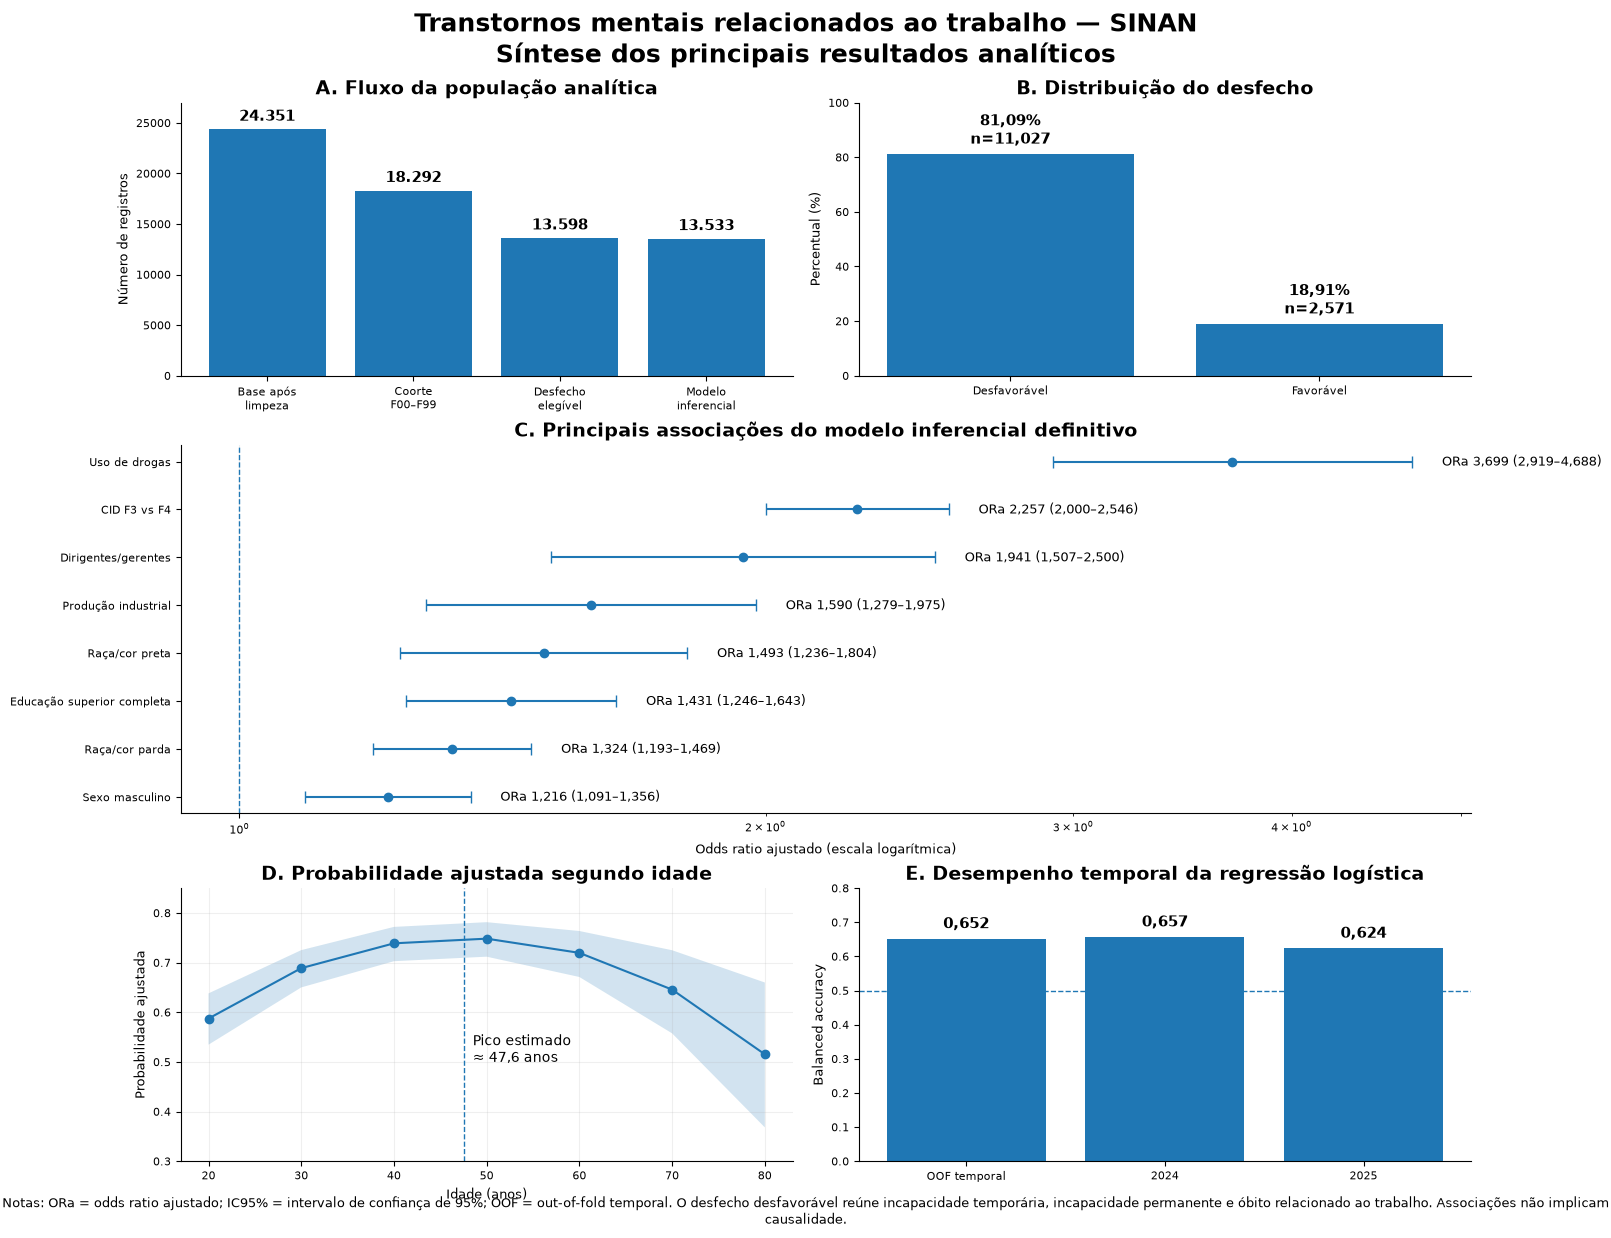

DASHBOARD FINAL
✓ dashboard_final_resultados_TCC.png
✓ dashboard_final_resultados_TCC.pdf
✓ Nenhum modelo foi recalculado.
✓ Dashboard construído exclusivamente a partir dos resultados finais validados.


In [68]:
# =============================================================================
# DASHBOARD FINAL — SÍNTESE VISUAL DOS RESULTADOS
# =============================================================================
#
# Este bloco NÃO recalcula modelos.
# Apenas organiza visualmente resultados já validados.
#
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec


# =============================================================================
# 1. DADOS FINAIS JÁ VALIDADOS
# =============================================================================

# Fluxo das bases
fluxo = pd.DataFrame({
    "Etapa": [
        "Base após\nlimpeza",
        "Coorte\nF00–F99",
        "Desfecho\nelegível",
        "Modelo\ninferencial"
    ],
    "N": [
        24351,
        18292,
        13598,
        13533
    ]
})


# Desfecho
desfecho = pd.DataFrame({
    "Categoria": [
        "Desfavorável",
        "Favorável"
    ],
    "N": [
        11027,
        2571
    ],
    "Percentual": [
        81.09,
        18.91
    ]
})


# Principais ORs do modelo inferencial definitivo
ors = pd.DataFrame({
    "Fator": [
        "Uso de drogas",
        "CID F3 vs F4",
        "Dirigentes/gerentes",
        "Produção industrial",
        "Raça/cor preta",
        "Educação superior completa",
        "Raça/cor parda",
        "Sexo masculino"
    ],
    "OR": [
        3.699,
        2.257,
        1.941,
        1.590,
        1.493,
        1.431,
        1.324,
        1.216
    ],
    "IC_inf": [
        2.919,
        2.000,
        1.507,
        1.279,
        1.236,
        1.246,
        1.193,
        1.091
    ],
    "IC_sup": [
        4.688,
        2.546,
        2.500,
        1.975,
        1.804,
        1.643,
        1.469,
        1.356
    ]
})


# Validação temporal
validacao = pd.DataFrame({
    "Período": [
        "OOF temporal",
        "2024",
        "2025"
    ],
    "Balanced Accuracy": [
        0.652,
        0.657,
        0.624
    ]
})


# Idades selecionadas — resultado do Bloco 39
idade = pd.DataFrame({
    "Idade": [
        20,
        30,
        40,
        50,
        60,
        70,
        80
    ],
    "Probabilidade": [
        0.5873,
        0.6888,
        0.7388,
        0.7482,
        0.7196,
        0.6456,
        0.5153
    ],
    "IC_inf": [
        0.5347,
        0.6500,
        0.7028,
        0.7119,
        0.6710,
        0.5575,
        0.3681
    ],
    "IC_sup": [
        0.6380,
        0.7251,
        0.7719,
        0.7814,
        0.7636,
        0.7249,
        0.6599
    ]
})


# =============================================================================
# 2. CRIAÇÃO DO PAINEL
# =============================================================================

fig = plt.figure(
    figsize=(16, 12),
    constrained_layout=True
)

gs = GridSpec(
    3,
    2,
    figure=fig,
    height_ratios=[
        1,
        1.35,
        1
    ]
)


# =============================================================================
# PAINEL A — FLUXO DA POPULAÇÃO ANALÍTICA
# =============================================================================

ax1 = fig.add_subplot(
    gs[0, 0]
)

barras_fluxo = ax1.bar(
    fluxo["Etapa"],
    fluxo["N"]
)

ax1.set_title(
    "A. Fluxo da população analítica",
    fontsize=14,
    fontweight="bold"
)

ax1.set_ylabel(
    "Número de registros"
)

ax1.set_ylim(
    0,
    27000
)

ax1.spines[
    ["top", "right"]
].set_visible(False)

for barra, valor in zip(
    barras_fluxo,
    fluxo["N"]
):
    ax1.text(
        barra.get_x()
        + barra.get_width() / 2,
        valor + 500,
        f"{valor:,}".replace(",", "."),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )


# =============================================================================
# PAINEL B — DISTRIBUIÇÃO DO DESFECHO
# =============================================================================

ax2 = fig.add_subplot(
    gs[0, 1]
)

barras_desfecho = ax2.bar(
    desfecho["Categoria"],
    desfecho["Percentual"]
)

ax2.set_title(
    "B. Distribuição do desfecho",
    fontsize=14,
    fontweight="bold"
)

ax2.set_ylabel(
    "Percentual (%)"
)

ax2.set_ylim(
    0,
    100
)

ax2.spines[
    ["top", "right"]
].set_visible(False)

for barra, pct, n in zip(
    barras_desfecho,
    desfecho["Percentual"],
    desfecho["N"]
):
    ax2.text(
        barra.get_x()
        + barra.get_width() / 2,
        pct + 2,
        (
            f"{pct:.2f}%\n"
            f"n={n:,}"
        ).replace(".", ","),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )


# =============================================================================
# PAINEL C — PRINCIPAIS ODDS RATIOS AJUSTADOS
# =============================================================================

ax3 = fig.add_subplot(
    gs[1, :]
)

ors_plot = (
    ors
    .sort_values(
        "OR",
        ascending=True
    )
    .reset_index(drop=True)
)

y = np.arange(
    len(ors_plot)
)

erro_inf = (
    ors_plot["OR"]
    - ors_plot["IC_inf"]
)

erro_sup = (
    ors_plot["IC_sup"]
    - ors_plot["OR"]
)

ax3.errorbar(
    ors_plot["OR"],
    y,
    xerr=[
        erro_inf,
        erro_sup
    ],
    fmt="o",
    capsize=4
)

ax3.axvline(
    1,
    linestyle="--",
    linewidth=1
)

ax3.set_yticks(
    y
)

ax3.set_yticklabels(
    ors_plot["Fator"]
)

ax3.set_xscale(
    "log"
)

ax3.set_xlabel(
    "Odds ratio ajustado (escala logarítmica)"
)

ax3.set_title(
    "C. Principais associações do modelo inferencial definitivo",
    fontsize=14,
    fontweight="bold"
)

ax3.spines[
    ["top", "right"]
].set_visible(False)

ax3.grid(
    axis="x",
    alpha=0.2
)

for i, linha in ors_plot.iterrows():

    ax3.text(
        linha["IC_sup"] * 1.04,
        i,
        (
            f'ORa {linha["OR"]:.3f} '
            f'({linha["IC_inf"]:.3f}–'
            f'{linha["IC_sup"]:.3f})'
        ).replace(".", ","),
        va="center",
        fontsize=9
    )


# =============================================================================
# PAINEL D — CURVA AJUSTADA DA IDADE
# =============================================================================

ax4 = fig.add_subplot(
    gs[2, 0]
)

ax4.plot(
    idade["Idade"],
    idade["Probabilidade"],
    marker="o"
)

ax4.fill_between(
    idade["Idade"],
    idade["IC_inf"],
    idade["IC_sup"],
    alpha=0.2
)

ax4.axvline(
    47.6,
    linestyle="--",
    linewidth=1
)

ax4.text(
    48.5,
    0.50,
    "Pico estimado\n≈ 47,6 anos",
    fontsize=10
)

ax4.set_title(
    "D. Probabilidade ajustada segundo idade",
    fontsize=14,
    fontweight="bold"
)

ax4.set_xlabel(
    "Idade (anos)"
)

ax4.set_ylabel(
    "Probabilidade ajustada"
)

ax4.set_ylim(
    0.30,
    0.85
)

ax4.spines[
    ["top", "right"]
].set_visible(False)

ax4.grid(
    alpha=0.2
)


# =============================================================================
# PAINEL E — VALIDAÇÃO TEMPORAL
# =============================================================================

ax5 = fig.add_subplot(
    gs[2, 1]
)

barras_validacao = ax5.bar(
    validacao["Período"],
    validacao["Balanced Accuracy"]
)

ax5.set_title(
    "E. Desempenho temporal da regressão logística",
    fontsize=14,
    fontweight="bold"
)

ax5.set_ylabel(
    "Balanced accuracy"
)

ax5.set_ylim(
    0,
    0.80
)

ax5.axhline(
    0.50,
    linestyle="--",
    linewidth=1
)

ax5.spines[
    ["top", "right"]
].set_visible(False)

for barra, valor in zip(
    barras_validacao,
    validacao["Balanced Accuracy"]
):

    ax5.text(
        barra.get_x()
        + barra.get_width() / 2,
        valor + 0.02,
        f"{valor:.3f}".replace(".", ","),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )


# =============================================================================
# 3. TÍTULO E NOTAS
# =============================================================================

fig.suptitle(
    (
        "Transtornos mentais relacionados ao trabalho — SINAN\n"
        "Síntese dos principais resultados analíticos"
    ),
    fontsize=18,
    fontweight="bold"
)


fig.text(
    0.5,
    -0.015,
    (
        "Notas: ORa = odds ratio ajustado; "
        "IC95% = intervalo de confiança de 95%; "
        "OOF = out-of-fold temporal. "
        "O desfecho desfavorável reúne incapacidade temporária, "
        "incapacidade permanente e óbito relacionado ao trabalho. "
        "Associações não implicam causalidade."
    ),
    ha="center",
    fontsize=9,
    wrap=True
)


# =============================================================================
# 4. EXPORTAÇÃO
# =============================================================================

plt.savefig(
    "dashboard_final_resultados_TCC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "dashboard_final_resultados_TCC.pdf",
    bbox_inches="tight"
)

plt.show()


print("=" * 100)
print("DASHBOARD FINAL")
print("=" * 100)

print(
    "✓ dashboard_final_resultados_TCC.png"
)

print(
    "✓ dashboard_final_resultados_TCC.pdf"
)

print(
    "✓ Nenhum modelo foi recalculado."
)

print(
    "✓ Dashboard construído exclusivamente "
    "a partir dos resultados finais validados."
)

print("=" * 100)

## Dashboard descritivo — Caracterização epidemiológica da coorte F00–F99

Este painel apresenta a caracterização descritiva dos registros de transtornos mentais
relacionados ao trabalho pertencentes ao capítulo F00–F99 da CID-10.

A população considerada corresponde à coorte epidemiológica principal do estudo
($N=18.292$), definida antes da construção do desfecho utilizado nas etapas preditiva
e inferencial.

O painel tem finalidade exclusivamente descritiva e reúne seis dimensões:

1. distribuição temporal dos registros;
2. distribuição segundo os grandes grupos diagnósticos da CID-10;
3. distribuição segundo sexo;
4. distribuição segundo faixa etária;
5. distribuição segundo raça/cor;
6. distribuição segundo situação de trabalho.

Os anos de 2020 e 2021 são apresentados como lacunas na série disponível, e não como
anos com ausência de ocorrência do agravo. Os resultados referentes a 2025 também
devem ser interpretados considerando a possibilidade de consolidação temporal da base.

As categorias `Ignorado` e `Não informado`, quando existentes, são mantidas nos
gráficos descritivos porque também expressam características da qualidade e da
completude dos registros do sistema de vigilância.

Este dashboard complementa o painel de resultados analíticos: enquanto o presente
painel descreve a população epidemiológica antes da modelagem, o dashboard final
apresenta o desfecho, a validação temporal e as associações estimadas pelos modelos.

DASHBOARD DESCRITIVO — COORTE F00–F99
N da coorte epidemiológica: 18.292


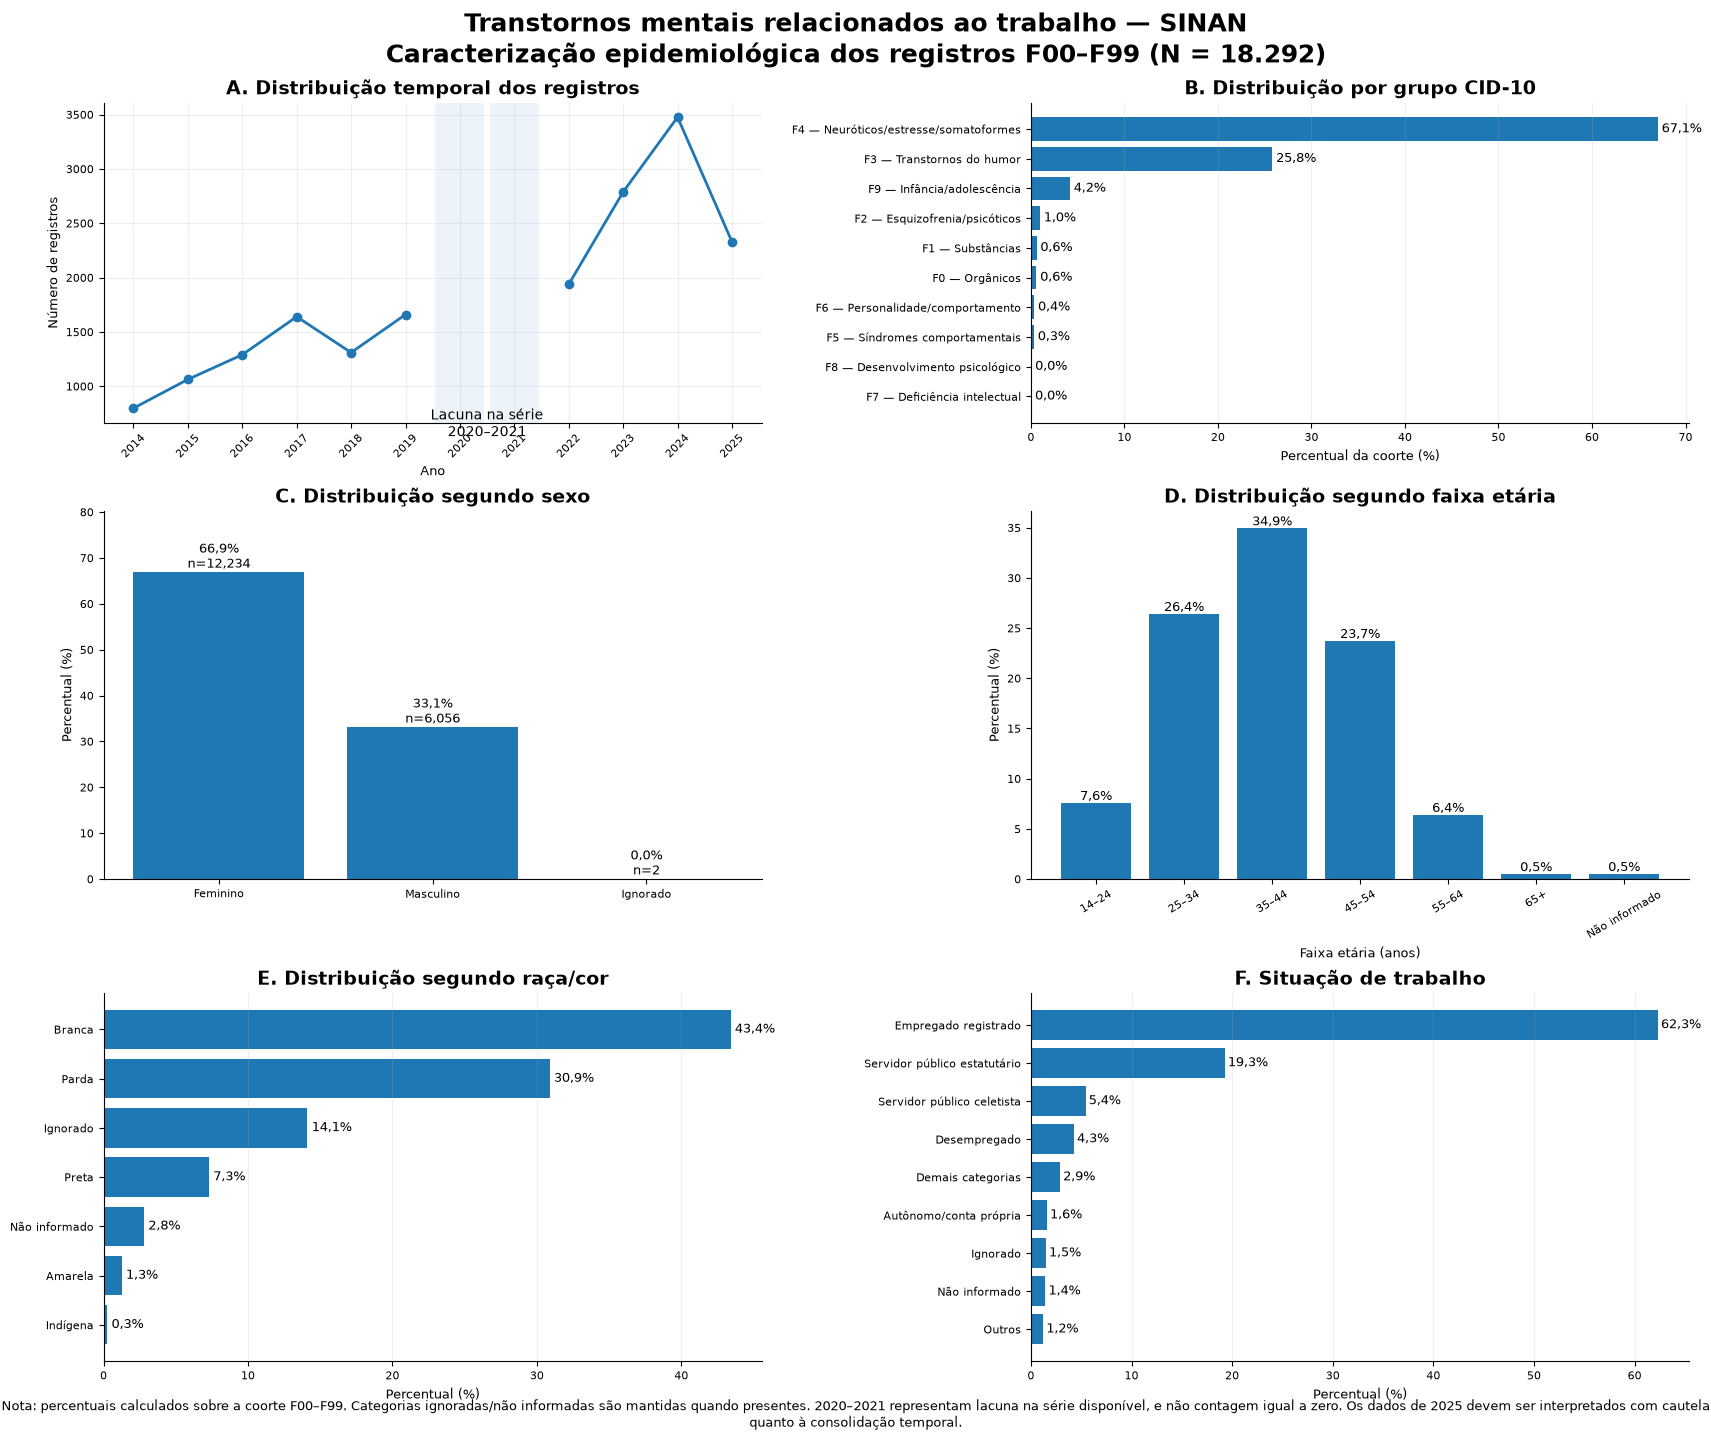


DASHBOARD 1 — CARACTERIZAÇÃO EPIDEMIOLÓGICA
✓ Coorte utilizada ...................: 18.292 registros
✓ dashboard_1_caracterizacao_epidemiologica.png
✓ dashboard_1_caracterizacao_epidemiologica.pdf
✓ Tabelas auxiliares exportadas em CSV.
✓ Nenhum modelo foi recalculado.


In [69]:
# =============================================================================
# DASHBOARD 1 — CARACTERIZAÇÃO EPIDEMIOLÓGICA DA COORTE F00–F99
# =============================================================================
#
# População: df_epi
# N esperado: 18.292 registros
#
# IMPORTANTE:
# - Este bloco é exclusivamente descritivo.
# - Nenhum modelo é recalculado.
# - Os percentuais são calculados diretamente a partir de df_epi.
# - 2020 e 2021 são lacunas na série disponível, não valores iguais a zero.
#
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec


# =============================================================================
# 1. VERIFICAÇÃO DA COORTE
# =============================================================================

N_EPI = len(df_epi)

assert N_EPI == 18292, (
    f"O tamanho atual de df_epi é {N_EPI:,}, "
    "mas o esperado é 18.292."
)

print("=" * 100)
print("DASHBOARD DESCRITIVO — COORTE F00–F99")
print("=" * 100)
print(f"N da coorte epidemiológica: {N_EPI:,}".replace(",", "."))


# =============================================================================
# 2. SÉRIE TEMPORAL
# =============================================================================

serie_temporal = (
    df_epi["NU_ANO"]
    .astype("string")
    .value_counts()
    .rename_axis("Ano")
    .reset_index(name="N")
)

serie_temporal["Ano"] = pd.to_numeric(
    serie_temporal["Ano"],
    errors="coerce"
)

serie_temporal = (
    serie_temporal
    .dropna(subset=["Ano"])
    .sort_values("Ano")
)

serie_temporal["Ano"] = (
    serie_temporal["Ano"]
    .astype(int)
)


# Criamos todos os anos apenas para controlar o eixo.
# 2020 e 2021 permanecerão como NaN, NÃO como zero.

anos_completos = pd.DataFrame({
    "Ano": np.arange(
        serie_temporal["Ano"].min(),
        serie_temporal["Ano"].max() + 1
    )
})

serie_plot = anos_completos.merge(
    serie_temporal,
    on="Ano",
    how="left"
)


# =============================================================================
# 3. GRANDES GRUPOS CID
# =============================================================================

mapa_cid = {
    "F0": "F0 — Orgânicos",
    "F1": "F1 — Substâncias",
    "F2": "F2 — Esquizofrenia/psicóticos",
    "F3": "F3 — Transtornos do humor",
    "F4": "F4 — Neuróticos/estresse/somatoformes",
    "F5": "F5 — Síndromes comportamentais",
    "F6": "F6 — Personalidade/comportamento",
    "F7": "F7 — Deficiência intelectual",
    "F8": "F8 — Desenvolvimento psicológico",
    "F9": "F9 — Infância/adolescência"
}

cid_dist = (
    df_epi["GRUPO_CID"]
    .astype("string")
    .value_counts()
    .rename_axis("Grupo")
    .reset_index(name="N")
)

cid_dist["Label"] = (
    cid_dist["Grupo"]
    .map(mapa_cid)
    .fillna(cid_dist["Grupo"])
)

cid_dist["Percentual"] = (
    cid_dist["N"] /
    N_EPI *
    100
)

cid_dist = (
    cid_dist
    .sort_values(
        "N",
        ascending=True
    )
)


# =============================================================================
# 4. SEXO
# =============================================================================

if "SEXO_LABEL" in df_epi.columns:
    sexo_serie = df_epi["SEXO_LABEL"].astype("string")
else:
    mapa_sexo = {
        "M": "Masculino",
        "F": "Feminino",
        "I": "Ignorado"
    }

    sexo_serie = (
        df_epi["CS_SEXO"]
        .astype("string")
        .str.strip()
        .map(mapa_sexo)
        .fillna("Não informado")
    )

sexo_serie = sexo_serie.fillna("Não informado")

sexo_dist = (
    sexo_serie
    .value_counts()
    .rename_axis("Sexo")
    .reset_index(name="N")
)

sexo_dist["Percentual"] = (
    sexo_dist["N"] /
    N_EPI *
    100
)


# =============================================================================
# 5. IDADE
# =============================================================================

# Se IDADE_ANOS já foi criada nos blocos anteriores, utilizamos a variável tratada.
# Caso contrário, fazemos a decodificação de NU_IDADE_N.

if "IDADE_ANOS" in df_epi.columns:

    idade_epi = pd.to_numeric(
        df_epi["IDADE_ANOS"],
        errors="coerce"
    )

else:

    idade_codigo = (
        df_epi["NU_IDADE_N"]
        .astype("string")
        .str.strip()
    )

    unidade = idade_codigo.str[0]

    valor = pd.to_numeric(
        idade_codigo.str[1:],
        errors="coerce"
    )

    # No SINAN, código iniciado por 4 representa idade em anos.
    idade_epi = valor.where(
        unidade.eq("4")
    )


# Faixa válida adotada anteriormente
idade_epi = idade_epi.where(
    idade_epi.between(
        14,
        100
    )
)


faixa_idade = pd.cut(
    idade_epi,
    bins=[
        14,
        24,
        34,
        44,
        54,
        64,
        100
    ],
    labels=[
        "14–24",
        "25–34",
        "35–44",
        "45–54",
        "55–64",
        "65+"
    ],
    include_lowest=True
)

faixa_idade = (
    faixa_idade
    .astype("string")
    .fillna("Não informado")
)

idade_dist = (
    faixa_idade
    .value_counts()
    .rename_axis("Faixa etária")
    .reset_index(name="N")
)

ordem_idade = [
    "14–24",
    "25–34",
    "35–44",
    "45–54",
    "55–64",
    "65+",
    "Não informado"
]

idade_dist["Faixa etária"] = pd.Categorical(
    idade_dist["Faixa etária"],
    categories=ordem_idade,
    ordered=True
)

idade_dist = idade_dist.sort_values(
    "Faixa etária"
)

idade_dist["Percentual"] = (
    idade_dist["N"] /
    N_EPI *
    100
)


# =============================================================================
# 6. RAÇA/COR
# =============================================================================

if "RACA_LABEL" in df_epi.columns:

    raca_serie = (
        df_epi["RACA_LABEL"]
        .astype("string")
        .fillna("Não informado")
    )

else:

    mapa_raca = {
        "1": "Branca",
        "2": "Preta",
        "3": "Amarela",
        "4": "Parda",
        "5": "Indígena",
        "9": "Ignorado"
    }

    raca_serie = (
        df_epi["CS_RACA"]
        .astype("string")
        .str.strip()
        .map(mapa_raca)
        .fillna("Não informado")
    )


raca_dist = (
    raca_serie
    .value_counts()
    .rename_axis("Raça/cor")
    .reset_index(name="N")
)

raca_dist["Percentual"] = (
    raca_dist["N"] /
    N_EPI *
    100
)

raca_dist = raca_dist.sort_values(
    "N",
    ascending=True
)


# =============================================================================
# 7. SITUAÇÃO DE TRABALHO
# =============================================================================

if "SIT_TRAB_LABEL" in df_epi.columns:

    trabalho_serie = (
        df_epi["SIT_TRAB_LABEL"]
        .astype("string")
        .fillna("Não informado")
    )

else:

    mapa_trabalho = {
        "01": "Empregado registrado",
        "1": "Empregado registrado",

        "02": "Empregado não registrado",
        "2": "Empregado não registrado",

        "03": "Autônomo/conta própria",
        "3": "Autônomo/conta própria",

        "04": "Servidor público estatutário",
        "4": "Servidor público estatutário",

        "05": "Servidor público celetista",
        "5": "Servidor público celetista",

        "06": "Aposentado",
        "6": "Aposentado",

        "07": "Desempregado",
        "7": "Desempregado",

        "08": "Trabalho temporário",
        "8": "Trabalho temporário",

        "09": "Cooperativado",
        "9": "Cooperativado",

        "10": "Trabalhador avulso",
        "11": "Empregador",
        "12": "Outros",
        "99": "Ignorado"
    }

    trabalho_serie = (
        df_epi["SIT_TRAB"]
        .astype("string")
        .str.strip()
        .map(mapa_trabalho)
        .fillna("Não informado")
    )


trabalho_dist = (
    trabalho_serie
    .value_counts()
    .rename_axis("Situação de trabalho")
    .reset_index(name="N")
)

trabalho_dist["Percentual"] = (
    trabalho_dist["N"] /
    N_EPI *
    100
)


# Para legibilidade do dashboard:
# exibimos as categorias mais frequentes e agregamos as restantes.

TOP_N_TRABALHO = 8

trabalho_top = (
    trabalho_dist
    .sort_values(
        "N",
        ascending=False
    )
    .reset_index(drop=True)
)

if len(trabalho_top) > TOP_N_TRABALHO:

    principais = trabalho_top.iloc[
        :TOP_N_TRABALHO
    ].copy()

    restantes_n = trabalho_top.iloc[
        TOP_N_TRABALHO:
    ]["N"].sum()

    restantes = pd.DataFrame({
        "Situação de trabalho": [
            "Demais categorias"
        ],
        "N": [
            restantes_n
        ],
        "Percentual": [
            restantes_n /
            N_EPI *
            100
        ]
    })

    trabalho_plot = pd.concat(
        [
            principais,
            restantes
        ],
        ignore_index=True
    )

else:

    trabalho_plot = trabalho_top.copy()


trabalho_plot = trabalho_plot.sort_values(
    "N",
    ascending=True
)


# =============================================================================
# 8. CRIAÇÃO DO DASHBOARD
# =============================================================================

fig = plt.figure(
    figsize=(17, 14),
    constrained_layout=True
)

gs = GridSpec(
    3,
    2,
    figure=fig,
    height_ratios=[
        1,
        1.15,
        1.15
    ]
)


# =============================================================================
# PAINEL A — SÉRIE TEMPORAL
# =============================================================================

ax1 = fig.add_subplot(
    gs[0, 0]
)

ax1.plot(
    serie_plot["Ano"],
    serie_plot["N"],
    marker="o",
    linewidth=2
)

ax1.set_title(
    "A. Distribuição temporal dos registros",
    fontsize=14,
    fontweight="bold"
)

ax1.set_xlabel(
    "Ano"
)

ax1.set_ylabel(
    "Número de registros"
)

ax1.set_xticks(
    serie_plot["Ano"]
)

ax1.tick_params(
    axis="x",
    rotation=45
)

ax1.spines[
    ["top", "right"]
].set_visible(False)

ax1.grid(
    alpha=0.2
)


# Destacar visualmente a lacuna
for ano in [2020, 2021]:

    ax1.axvspan(
        ano - 0.45,
        ano + 0.45,
        alpha=0.08
    )

ax1.text(
    2020.5,
    ax1.get_ylim()[1] * 0.15,
    "Lacuna na série\n2020–2021",
    ha="center",
    fontsize=10
)


# =============================================================================
# PAINEL B — GRUPOS CID
# =============================================================================

ax2 = fig.add_subplot(
    gs[0, 1]
)

barras_cid = ax2.barh(
    cid_dist["Label"],
    cid_dist["Percentual"]
)

ax2.set_title(
    "B. Distribuição por grupo CID-10",
    fontsize=14,
    fontweight="bold"
)

ax2.set_xlabel(
    "Percentual da coorte (%)"
)

ax2.spines[
    ["top", "right"]
].set_visible(False)

ax2.grid(
    axis="x",
    alpha=0.2
)

for barra, pct in zip(
    barras_cid,
    cid_dist["Percentual"]
):

    ax2.text(
        barra.get_width() + 0.4,
        barra.get_y()
        + barra.get_height() / 2,
        f"{pct:.1f}%".replace(".", ","),
        va="center",
        fontsize=9
    )


# =============================================================================
# PAINEL C — SEXO
# =============================================================================

ax3 = fig.add_subplot(
    gs[1, 0]
)

barras_sexo = ax3.bar(
    sexo_dist["Sexo"],
    sexo_dist["Percentual"]
)

ax3.set_title(
    "C. Distribuição segundo sexo",
    fontsize=14,
    fontweight="bold"
)

ax3.set_ylabel(
    "Percentual (%)"
)

ax3.set_ylim(
    0,
    max(
        sexo_dist["Percentual"].max() * 1.20,
        10
    )
)

ax3.spines[
    ["top", "right"]
].set_visible(False)

for barra, pct, n in zip(
    barras_sexo,
    sexo_dist["Percentual"],
    sexo_dist["N"]
):

    ax3.text(
        barra.get_x()
        + barra.get_width() / 2,
        barra.get_height() + 1,
        (
            f"{pct:.1f}%\n"
            f"n={n:,}"
        ).replace(".", ","),
        ha="center",
        fontsize=9
    )


# =============================================================================
# PAINEL D — FAIXA ETÁRIA
# =============================================================================

ax4 = fig.add_subplot(
    gs[1, 1]
)

barras_idade = ax4.bar(
    idade_dist["Faixa etária"].astype(str),
    idade_dist["Percentual"]
)

ax4.set_title(
    "D. Distribuição segundo faixa etária",
    fontsize=14,
    fontweight="bold"
)

ax4.set_xlabel(
    "Faixa etária (anos)"
)

ax4.set_ylabel(
    "Percentual (%)"
)

ax4.spines[
    ["top", "right"]
].set_visible(False)

ax4.tick_params(
    axis="x",
    rotation=30
)

for barra, pct in zip(
    barras_idade,
    idade_dist["Percentual"]
):

    ax4.text(
        barra.get_x()
        + barra.get_width() / 2,
        barra.get_height() + 0.3,
        f"{pct:.1f}%".replace(".", ","),
        ha="center",
        fontsize=9
    )


# =============================================================================
# PAINEL E — RAÇA/COR
# =============================================================================

ax5 = fig.add_subplot(
    gs[2, 0]
)

barras_raca = ax5.barh(
    raca_dist["Raça/cor"],
    raca_dist["Percentual"]
)

ax5.set_title(
    "E. Distribuição segundo raça/cor",
    fontsize=14,
    fontweight="bold"
)

ax5.set_xlabel(
    "Percentual (%)"
)

ax5.spines[
    ["top", "right"]
].set_visible(False)

ax5.grid(
    axis="x",
    alpha=0.2
)

for barra, pct in zip(
    barras_raca,
    raca_dist["Percentual"]
):

    ax5.text(
        barra.get_width() + 0.3,
        barra.get_y()
        + barra.get_height() / 2,
        f"{pct:.1f}%".replace(".", ","),
        va="center",
        fontsize=9
    )


# =============================================================================
# PAINEL F — SITUAÇÃO DE TRABALHO
# =============================================================================

ax6 = fig.add_subplot(
    gs[2, 1]
)

barras_trabalho = ax6.barh(
    trabalho_plot["Situação de trabalho"],
    trabalho_plot["Percentual"]
)

ax6.set_title(
    "F. Situação de trabalho",
    fontsize=14,
    fontweight="bold"
)

ax6.set_xlabel(
    "Percentual (%)"
)

ax6.spines[
    ["top", "right"]
].set_visible(False)

ax6.grid(
    axis="x",
    alpha=0.2
)

for barra, pct in zip(
    barras_trabalho,
    trabalho_plot["Percentual"]
):

    ax6.text(
        barra.get_width() + 0.3,
        barra.get_y()
        + barra.get_height() / 2,
        f"{pct:.1f}%".replace(".", ","),
        va="center",
        fontsize=9
    )


# =============================================================================
# 9. TÍTULO GERAL E NOTA
# =============================================================================

fig.suptitle(
    (
        "Transtornos mentais relacionados ao trabalho — SINAN\n"
        "Caracterização epidemiológica dos registros F00–F99 "
        f"(N = {N_EPI:,})".replace(",", ".")
    ),
    fontsize=18,
    fontweight="bold"
)


fig.text(
    0.5,
    -0.015,
    (
        "Nota: percentuais calculados sobre a coorte F00–F99. "
        "Categorias ignoradas/não informadas são mantidas quando presentes. "
        "2020–2021 representam lacuna na série disponível, e não contagem igual a zero. "
        "Os dados de 2025 devem ser interpretados com cautela quanto à consolidação temporal."
    ),
    ha="center",
    fontsize=9,
    wrap=True
)


# =============================================================================
# 10. EXPORTAÇÃO
# =============================================================================

plt.savefig(
    "dashboard_1_caracterizacao_epidemiologica.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "dashboard_1_caracterizacao_epidemiologica.pdf",
    bbox_inches="tight"
)

plt.show()


# =============================================================================
# 11. EXPORTAR TABELAS QUE ALIMENTARAM O DASHBOARD
# =============================================================================

serie_temporal.to_csv(
    "dashboard1_serie_temporal.csv",
    index=False,
    encoding="utf-8-sig"
)

cid_dist.to_csv(
    "dashboard1_grupos_cid.csv",
    index=False,
    encoding="utf-8-sig"
)

sexo_dist.to_csv(
    "dashboard1_sexo.csv",
    index=False,
    encoding="utf-8-sig"
)

idade_dist.to_csv(
    "dashboard1_faixa_etaria.csv",
    index=False,
    encoding="utf-8-sig"
)

raca_dist.to_csv(
    "dashboard1_raca_cor.csv",
    index=False,
    encoding="utf-8-sig"
)

trabalho_dist.to_csv(
    "dashboard1_situacao_trabalho.csv",
    index=False,
    encoding="utf-8-sig"
)


# =============================================================================
# 12. ENCERRAMENTO
# =============================================================================

print("\n" + "=" * 100)
print("DASHBOARD 1 — CARACTERIZAÇÃO EPIDEMIOLÓGICA")
print("=" * 100)

print(
    "✓ Coorte utilizada ...................: "
    f"{N_EPI:,} registros".replace(",", ".")
)

print(
    "✓ dashboard_1_caracterizacao_epidemiologica.png"
)

print(
    "✓ dashboard_1_caracterizacao_epidemiologica.pdf"
)

print(
    "✓ Tabelas auxiliares exportadas em CSV."
)

print(
    "✓ Nenhum modelo foi recalculado."
)

print("=" * 100)

## Dashboard — Caracterização da população utilizada na modelagem preditiva

Este painel apresenta a caracterização dos **13.598 registros efetivamente elegíveis para a etapa de modelagem preditiva**.

A população corresponde aos registros de transtornos mentais relacionados ao trabalho classificados no capítulo F00–F99 da CID-10 e com evolução passível de classificação no desfecho binário do estudo.

O desfecho foi definido como:

- **favorável:** cura ou cura não confirmada;
- **desfavorável:** incapacidade temporária, incapacidade permanente parcial, incapacidade permanente total ou óbito por doença relacionada ao trabalho.

A estratégia de validação preservou a dimensão temporal dos dados. Os registros foram organizados em três conjuntos:

- **2014–2023:** desenvolvimento e validação temporal interna — $N=9.130$;
- **2024:** avaliação temporal — $N=2.710$;
- **2025:** avaliação temporal complementar — $N=1.758$.

O painel apresenta a composição temporal da população, a distribuição do desfecho e características demográficas, diagnósticas e ocupacionais utilizadas na modelagem.

As categorias `Ignorado` e `Não informado` são mantidas quando presentes, pois também refletem características da informação disponível no sistema de vigilância.

Os resultados de 2025 devem ser interpretados com cautela quanto à consolidação temporal da base. Os anos de 2020 e 2021 não possuem observações disponíveis na fonte utilizada e não foram interpretados como contagens iguais a zero.

Este dashboard descreve **quem compôs a população utilizada na modelagem**. O dashboard analítico apresentado posteriormente sintetiza **o desempenho dos modelos e as associações estimadas**.

DASHBOARD PREMIUM — POPULAÇÃO DA MODELAGEM
População: 13.598 registros


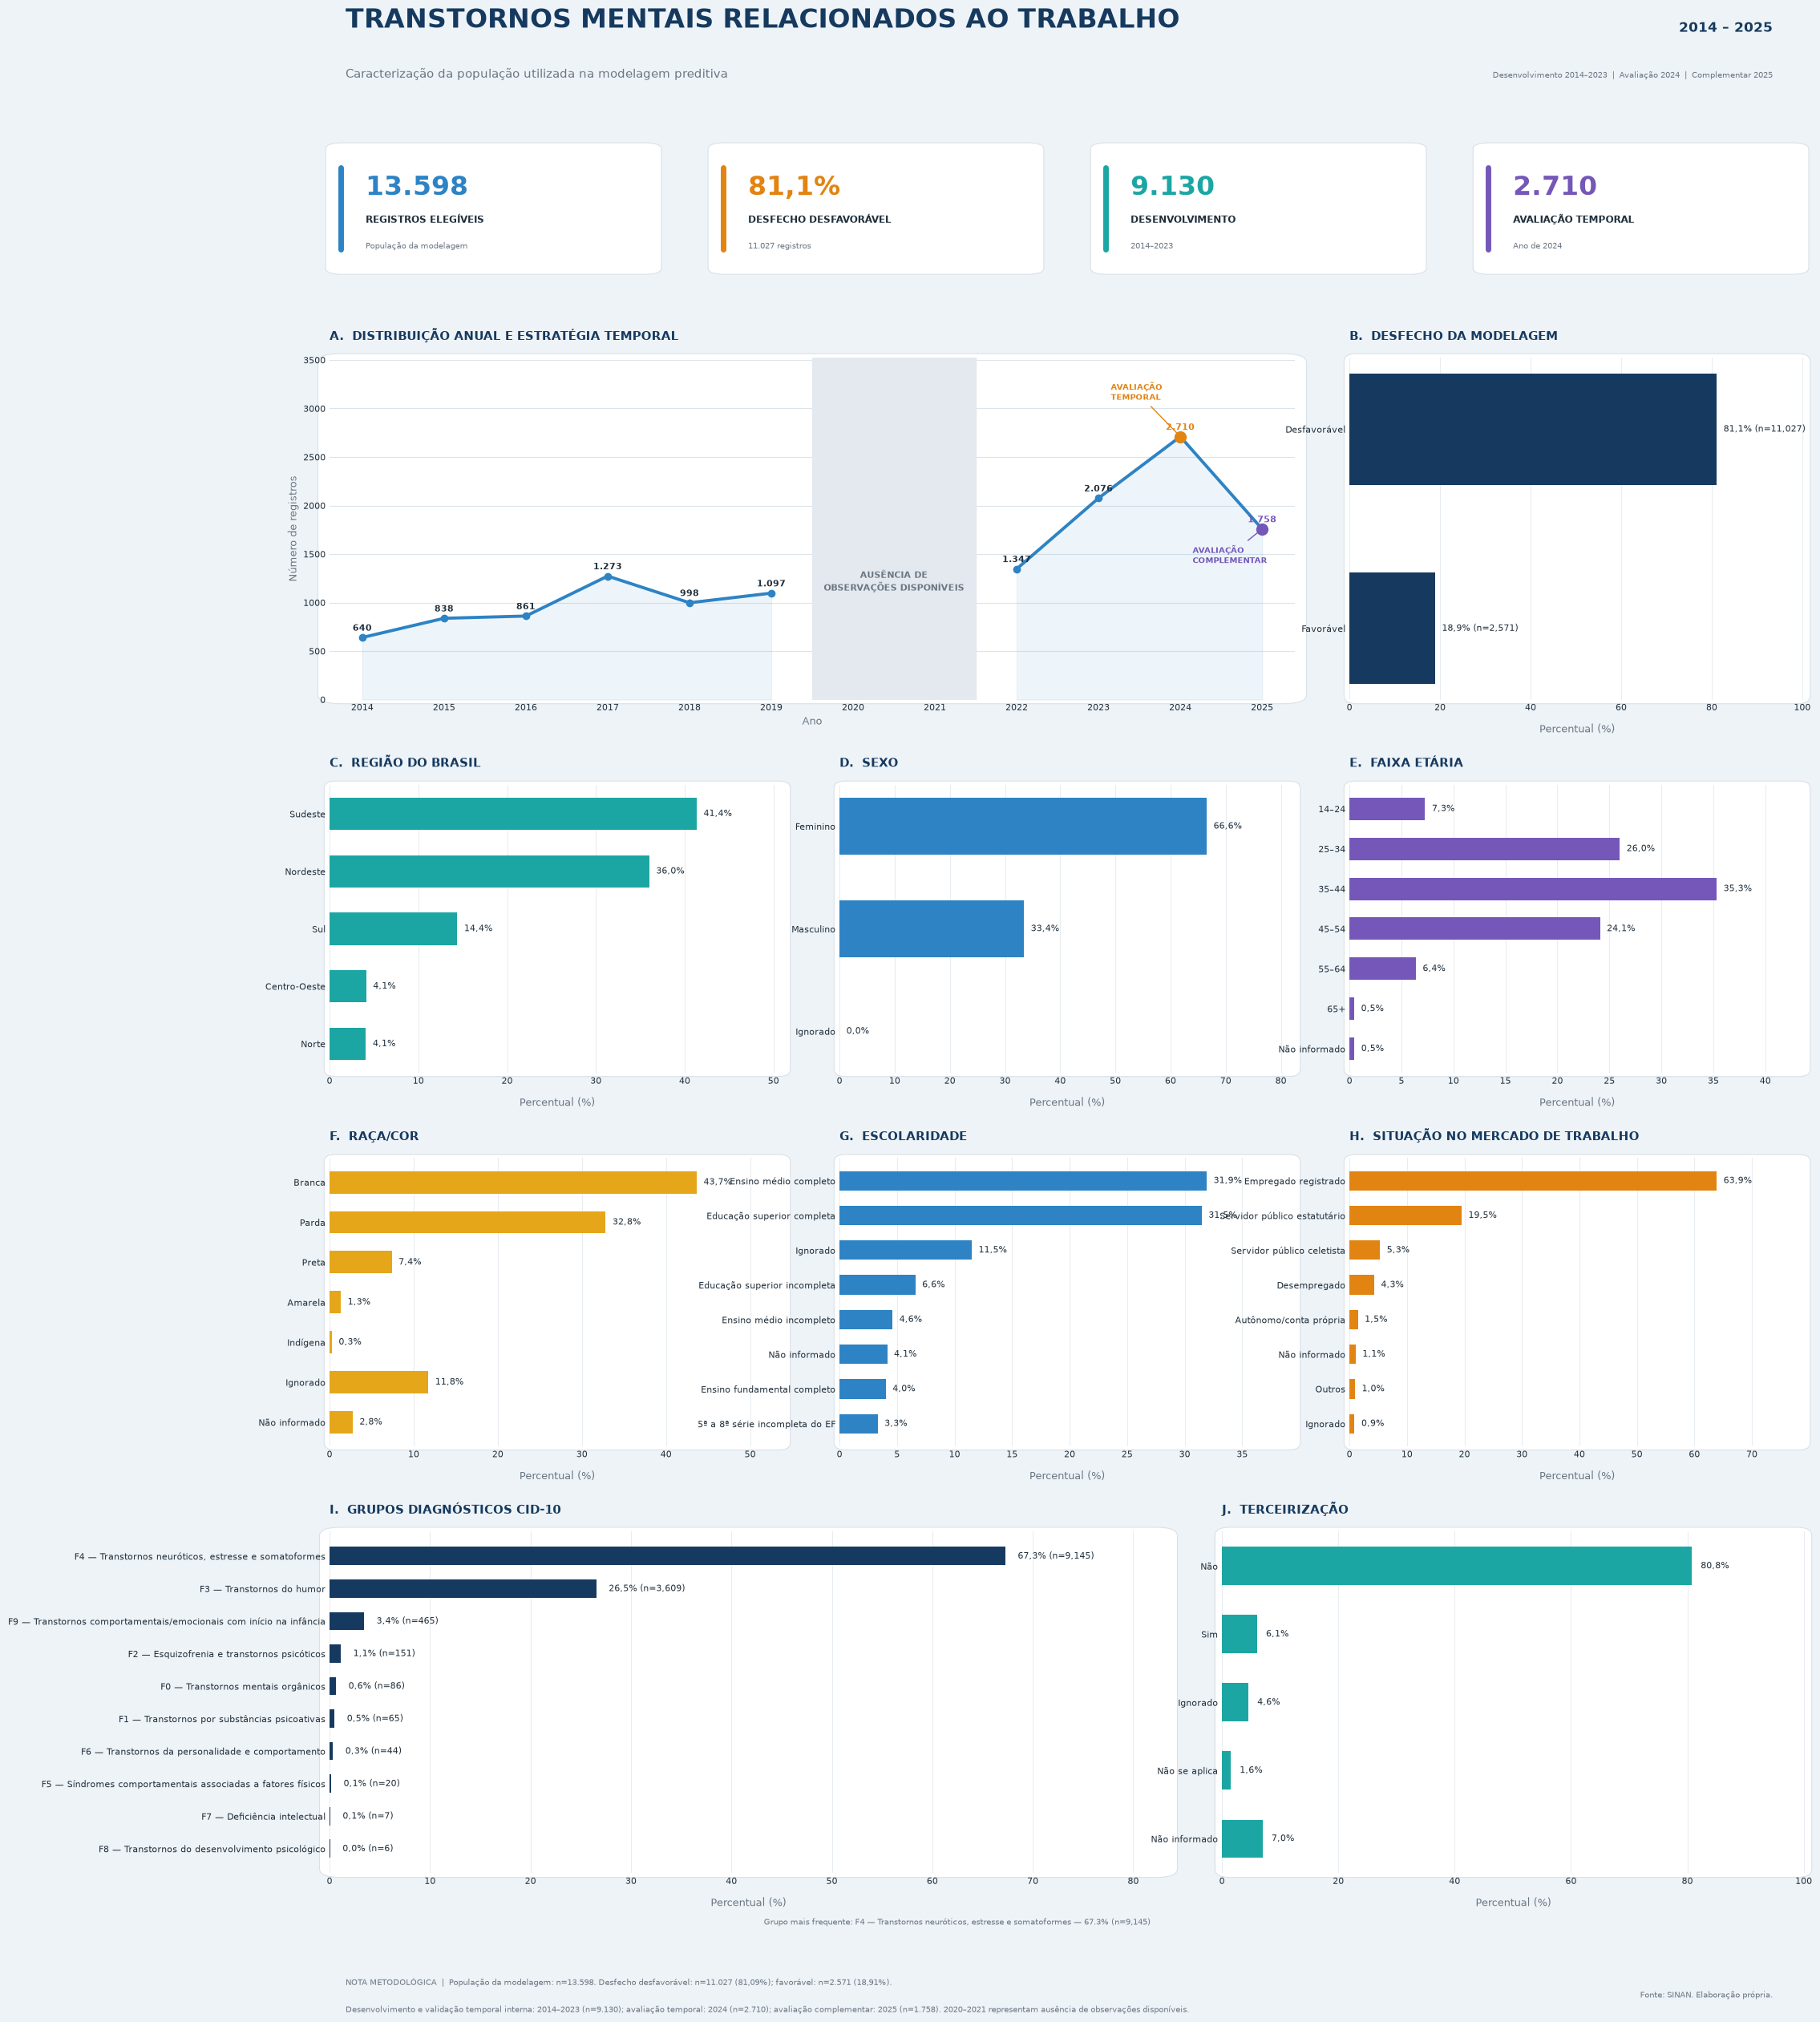


Dashboard salvo como:
dashboard_modelagem_preditiva_premium.png

✓ População total ...............: 13.598
✓ Desfavorável ..................: 11.027 (81,09%)
✓ Favorável .....................: 2.571 (18,91%)
✓ Desenvolvimento 2014–2023 ....: 9.130
✓ Avaliação temporal 2024 ......: 2.710
✓ Complementar 2025 ............: 1.758
✓ Nenhum modelo foi recalculado.


In [72]:
# ============================================================
# DASHBOARD PREMIUM — POPULAÇÃO DA MODELAGEM PREDITIVA
# ============================================================
#
# População:
#   df_modelo
#
# N = 13.598
#
# Desenvolvimento:
#   2014–2023 = 9.130
#
# Avaliação temporal:
#   2024 = 2.710
#
# Avaliação complementar:
#   2025 = 1.758
#
# Nenhum modelo é recalculado neste bloco.
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch


# ============================================================
# 0. BASE
# ============================================================

if "df_modelo" not in globals():
    raise NameError(
        "df_modelo não foi encontrado. "
        "Execute primeiro os blocos de construção da base de modelagem."
    )


base = df_modelo.copy()

N_TOTAL = len(base)


assert N_TOTAL == 13598, (
    f"N encontrado = {N_TOTAL:,}. "
    "O esperado para a população de modelagem é 13.598."
)


print("=" * 70)
print("DASHBOARD PREMIUM — POPULAÇÃO DA MODELAGEM")
print("=" * 70)
print(
    f"População: {N_TOTAL:,} registros".replace(",", ".")
)


# ============================================================
# 1. DESFECHO
# ============================================================

if "EVOLUCAO" not in base.columns:
    raise KeyError(
        "EVOLUCAO não foi encontrada em df_modelo."
    )


evolucao_codigo = (
    base["EVOLUCAO"]
    .astype("string")
    .str.strip()
)


desfecho = pd.Series(
    pd.NA,
    index=base.index,
    dtype="string"
)


desfecho.loc[
    evolucao_codigo.isin(["1", "2"])
] = "Favorável"


desfecho.loc[
    evolucao_codigo.isin(["3", "4", "5", "6"])
] = "Desfavorável"


n_fav = int(
    desfecho.eq("Favorável").sum()
)

n_desf = int(
    desfecho.eq("Desfavorável").sum()
)


assert n_fav == 2571
assert n_desf == 11027
assert n_fav + n_desf == N_TOTAL


pct_fav = (
    100 * n_fav / N_TOTAL
)

pct_desf = (
    100 * n_desf / N_TOTAL
)


# ============================================================
# 2. PALETA VISUAL
# ============================================================

NAVY = "#163A5F"
BLUE = "#2D83C4"
TEAL = "#1CA6A3"
ORANGE = "#E18412"
PURPLE = "#7457B8"
GOLD = "#E5A61A"

BACKGROUND = "#EEF3F7"
CARD = "#FFFFFF"

TEXT = "#21303D"
MUTED = "#6B7785"
GRID = "#DCE4EA"
BORDER = "#D9E1E7"


plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8
})


# ============================================================
# 3. FUNÇÕES VISUAIS
# ============================================================

def add_card_background(
    ax,
    radius=0.025
):

    ax.set_facecolor("none")

    box = FancyBboxPatch(
        (0, 0),
        1,
        1,
        transform=ax.transAxes,
        boxstyle=(
            f"round,pad=0.012,"
            f"rounding_size={radius}"
        ),
        linewidth=0.8,
        edgecolor=BORDER,
        facecolor=CARD,
        zorder=-10,
        clip_on=False
    )

    ax.add_patch(box)


def clean_axis(ax):

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(
        axis="both",
        length=0,
        colors=TEXT
    )

    ax.set_axisbelow(True)


def painel(
    ax,
    titulo,
    letra=None
):

    add_card_background(ax)
    clean_axis(ax)

    titulo_final = (
        f"{letra}.  {titulo}"
        if letra is not None
        else titulo
    )

    ax.set_title(
        titulo_final.upper(),
        loc="left",
        fontsize=11,
        fontweight="bold",
        color=NAVY,
        pad=16
    )


def tabela_pct(
    serie,
    ordem=None,
    top=None
):

    s = (
        serie.astype("string")
        .fillna("Não informado")
    )

    tab = (
        s.value_counts(dropna=False)
        .rename_axis("categoria")
        .reset_index(name="N")
    )

    tab["PCT"] = (
        100 * tab["N"] / N_TOTAL
    )

    if ordem is not None:

        ordem_dict = {
            categoria: i
            for i, categoria
            in enumerate(ordem)
        }

        tab["_ordem"] = (
            tab["categoria"]
            .map(ordem_dict)
            .fillna(999)
        )

        tab = (
            tab
            .sort_values("_ordem")
            .drop(columns="_ordem")
        )

    if top is not None:
        tab = tab.head(top)

    return tab.reset_index(drop=True)


def horizontal_bars(
    ax,
    tab,
    titulo,
    letra,
    cor,
    mostrar_n=False,
    xlabel="Percentual (%)"
):

    painel(
        ax,
        titulo,
        letra
    )

    dados = tab.copy()

    barras = ax.barh(
        dados["categoria"],
        dados["PCT"],
        color=cor,
        height=0.56
    )

    ax.invert_yaxis()

    ax.grid(
        axis="x",
        color=GRID,
        linewidth=0.8,
        alpha=0.65
    )

    ax.set_xlabel(
        xlabel,
        color=MUTED,
        labelpad=10
    )

    xmax = (
        max(
            dados["PCT"].max(),
            1
        )
        * 1.24
    )

    ax.set_xlim(
        0,
        xmax
    )

    for barra, (_, row) in zip(
        barras,
        dados.iterrows()
    ):

        if mostrar_n:

            label = (
                f"{row['PCT']:.1f}% "
                f"(n={int(row['N']):,})"
            )

        else:

            label = (
                f"{row['PCT']:.1f}%"
            )

        label = label.replace(
            ".",
            ","
        )

        ax.text(
            barra.get_width()
            + xmax * 0.015,
            barra.get_y()
            + barra.get_height() / 2,
            label,
            va="center",
            fontsize=8,
            color=TEXT
        )


def kpi_card(
    ax,
    valor,
    titulo,
    subtitulo,
    cor
):

    ax.axis("off")

    add_card_background(
        ax,
        radius=0.05
    )

    ax.plot(
        [0.035, 0.035],
        [0.18, 0.82],
        transform=ax.transAxes,
        color=cor,
        linewidth=5,
        solid_capstyle="round"
    )

    ax.text(
        0.11,
        0.66,
        valor,
        transform=ax.transAxes,
        fontsize=24,
        fontweight="bold",
        color=cor,
        va="center"
    )

    ax.text(
        0.11,
        0.39,
        titulo.upper(),
        transform=ax.transAxes,
        fontsize=8.5,
        fontweight="bold",
        color=TEXT
    )

    ax.text(
        0.11,
        0.19,
        subtitulo,
        transform=ax.transAxes,
        fontsize=7.3,
        color=MUTED
    )


# ============================================================
# 4. RÓTULOS — SEXO
# ============================================================

if "SEXO_LABEL" in base.columns:

    sexo_label = (
        base["SEXO_LABEL"]
        .astype("string")
        .fillna("Não informado")
    )

else:

    mapa_sexo = {
        "F": "Feminino",
        "M": "Masculino",
        "I": "Ignorado"
    }

    sexo_label = (
        base["CS_SEXO"]
        .astype("string")
        .str.strip()
        .map(mapa_sexo)
        .fillna("Não informado")
    )


tab_sexo = tabela_pct(
    sexo_label,
    ordem=[
        "Feminino",
        "Masculino",
        "Ignorado",
        "Não informado"
    ]
)


# ============================================================
# 5. RAÇA/COR
# ============================================================

if "RACA_LABEL" in base.columns:

    raca_label = (
        base["RACA_LABEL"]
        .astype("string")
        .fillna("Não informado")
    )

else:

    mapa_raca = {
        "1": "Branca",
        "2": "Preta",
        "3": "Amarela",
        "4": "Parda",
        "5": "Indígena",
        "9": "Ignorado"
    }

    raca_label = (
        base["CS_RACA"]
        .astype("string")
        .str.strip()
        .map(mapa_raca)
        .fillna("Não informado")
    )


tab_raca = tabela_pct(
    raca_label,
    ordem=[
        "Branca",
        "Parda",
        "Preta",
        "Amarela",
        "Indígena",
        "Ignorado",
        "Não informado"
    ]
)


# ============================================================
# 6. IDADE
# ============================================================

if "IDADE_ANOS" in base.columns:

    idade = pd.to_numeric(
        base["IDADE_ANOS"],
        errors="coerce"
    )

else:

    codigo_idade = (
        base["NU_IDADE_N"]
        .astype("string")
        .str.strip()
    )

    unidade = codigo_idade.str[0]

    valor = pd.to_numeric(
        codigo_idade.str[1:],
        errors="coerce"
    )

    idade = valor.where(
        unidade.eq("4")
    )


idade = idade.where(
    idade.between(
        14,
        100
    )
)


faixa_etaria = pd.cut(
    idade,
    bins=[
        14,
        24,
        34,
        44,
        54,
        64,
        100
    ],
    labels=[
        "14–24",
        "25–34",
        "35–44",
        "45–54",
        "55–64",
        "65+"
    ],
    include_lowest=True
)


tab_idade = tabela_pct(
    faixa_etaria
    .astype("string")
    .fillna("Não informado"),
    ordem=[
        "14–24",
        "25–34",
        "35–44",
        "45–54",
        "55–64",
        "65+",
        "Não informado"
    ]
)


# ============================================================
# 7. ESCOLARIDADE
# ============================================================

if "ESCOLARIDADE_LABEL" in base.columns:

    escolaridade_label = (
        base["ESCOLARIDADE_LABEL"]
        .astype("string")
        .fillna("Não informado")
    )

else:

    mapa_escolaridade = {
        "00": "Analfabeto",
        "0": "Analfabeto",

        "01": "1ª a 4ª série incompleta do EF",
        "1": "1ª a 4ª série incompleta do EF",

        "02": "4ª série completa do EF",
        "2": "4ª série completa do EF",

        "03": "5ª a 8ª série incompleta do EF",
        "3": "5ª a 8ª série incompleta do EF",

        "04": "Ensino fundamental completo",
        "4": "Ensino fundamental completo",

        "05": "Ensino médio incompleto",
        "5": "Ensino médio incompleto",

        "06": "Ensino médio completo",
        "6": "Ensino médio completo",

        "07": "Educação superior incompleta",
        "7": "Educação superior incompleta",

        "08": "Educação superior completa",
        "8": "Educação superior completa",

        "09": "Ignorado",
        "9": "Ignorado",

        "10": "Não se aplica"
    }

    escolaridade_label = (
        base["CS_ESCOL_N"]
        .astype("string")
        .str.strip()
        .map(mapa_escolaridade)
        .fillna("Não informado")
    )


tab_escolaridade = (
    tabela_pct(
        escolaridade_label
    )
    .sort_values(
        "N",
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)


# ============================================================
# 8. SITUAÇÃO DE TRABALHO
# ============================================================

if "SIT_TRAB_LABEL" in base.columns:

    sit_label = (
        base["SIT_TRAB_LABEL"]
        .astype("string")
        .fillna("Não informado")
    )

else:

    mapa_sit = {
        "01": "Empregado registrado",
        "1": "Empregado registrado",

        "02": "Empregado não registrado",
        "2": "Empregado não registrado",

        "03": "Autônomo/conta própria",
        "3": "Autônomo/conta própria",

        "04": "Servidor público estatutário",
        "4": "Servidor público estatutário",

        "05": "Servidor público celetista",
        "5": "Servidor público celetista",

        "06": "Aposentado",
        "6": "Aposentado",

        "07": "Desempregado",
        "7": "Desempregado",

        "08": "Trabalho temporário",
        "8": "Trabalho temporário",

        "09": "Cooperativado",
        "9": "Cooperativado",

        "10": "Trabalhador avulso",
        "11": "Empregador",
        "12": "Outros",
        "99": "Ignorado"
    }

    sit_label = (
        base["SIT_TRAB"]
        .astype("string")
        .str.strip()
        .map(mapa_sit)
        .fillna("Não informado")
    )


tab_sit = (
    tabela_pct(
        sit_label
    )
    .sort_values(
        "N",
        ascending=False
    )
    .head(8)
    .reset_index(drop=True)
)


# ============================================================
# 9. TERCEIRIZAÇÃO
# ============================================================

if "TERCEIRIZA_LABEL" in base.columns:

    terceiriza_label = (
        base["TERCEIRIZA_LABEL"]
        .astype("string")
        .fillna("Não informado")
    )

else:

    mapa_terc = {
        "1": "Sim",
        "01": "Sim",

        "2": "Não",
        "02": "Não",

        "3": "Não se aplica",
        "03": "Não se aplica",

        "9": "Ignorado",
        "09": "Ignorado"
    }

    terceiriza_label = (
        base["TERCEIRIZA"]
        .astype("string")
        .str.strip()
        .map(mapa_terc)
        .fillna("Não informado")
    )


tab_terc = tabela_pct(
    terceiriza_label,
    ordem=[
        "Não",
        "Sim",
        "Ignorado",
        "Não se aplica",
        "Não informado"
    ]
)


# ============================================================
# 10. DESFECHO — TABELA
# ============================================================

tab_desfecho = tabela_pct(
    desfecho,
    ordem=[
        "Desfavorável",
        "Favorável"
    ]
)


# ============================================================
# 11. REGIÃO
# ============================================================

uf_raw = (
    base["SG_UF"]
    .astype("string")
    .str.strip()
    .str.upper()
)


codigo_uf = {
    "11": "RO",
    "12": "AC",
    "13": "AM",
    "14": "RR",
    "15": "PA",
    "16": "AP",
    "17": "TO",

    "21": "MA",
    "22": "PI",
    "23": "CE",
    "24": "RN",
    "25": "PB",
    "26": "PE",
    "27": "AL",
    "28": "SE",
    "29": "BA",

    "31": "MG",
    "32": "ES",
    "33": "RJ",
    "35": "SP",

    "41": "PR",
    "42": "SC",
    "43": "RS",

    "50": "MS",
    "51": "MT",
    "52": "GO",
    "53": "DF"
}


uf = uf_raw.map(
    lambda x:
    codigo_uf.get(x, x)
    if pd.notna(x)
    else pd.NA
)


mapa_regiao = {
    "AC": "Norte",
    "AP": "Norte",
    "AM": "Norte",
    "PA": "Norte",
    "RO": "Norte",
    "RR": "Norte",
    "TO": "Norte",

    "AL": "Nordeste",
    "BA": "Nordeste",
    "CE": "Nordeste",
    "MA": "Nordeste",
    "PB": "Nordeste",
    "PE": "Nordeste",
    "PI": "Nordeste",
    "RN": "Nordeste",
    "SE": "Nordeste",

    "DF": "Centro-Oeste",
    "GO": "Centro-Oeste",
    "MT": "Centro-Oeste",
    "MS": "Centro-Oeste",

    "ES": "Sudeste",
    "MG": "Sudeste",
    "RJ": "Sudeste",
    "SP": "Sudeste",

    "PR": "Sul",
    "RS": "Sul",
    "SC": "Sul"
}


regiao = (
    uf
    .map(mapa_regiao)
    .fillna("Não informado")
)


tab_regiao = tabela_pct(
    regiao,
    ordem=[
        "Sudeste",
        "Nordeste",
        "Sul",
        "Centro-Oeste",
        "Norte",
        "Não informado"
    ]
)


# ============================================================
# 12. GRANDES GRUPOS CID
# ============================================================

if "CID_GRUPO_MODELO" in base.columns:

    grupo_cid = (
        base["CID_GRUPO_MODELO"]
        .astype("string")
        .fillna("Não informado")
    )

elif "GRUPO_CID" in base.columns:

    mapa_grupo_cid = {
        "F0": "F0 — Transtornos mentais orgânicos",
        "F1": "F1 — Uso de substâncias psicoativas",
        "F2": "F2 — Esquizofrenia e transtornos psicóticos",
        "F3": "F3 — Transtornos do humor",
        "F4": "F4 — Transtornos neuróticos/estresse/somatoformes",
        "F5": "F5 — Síndromes comportamentais",
        "F6": "F6 — Personalidade e comportamento",
        "F7": "F7 — Deficiência intelectual",
        "F8": "F8 — Desenvolvimento psicológico",
        "F9": "F9 — Infância/adolescência"
    }

    grupo_cid = (
        base["GRUPO_CID"]
        .astype("string")
        .map(mapa_grupo_cid)
        .fillna(
            base["GRUPO_CID"]
            .astype("string")
        )
    )

else:

    raise KeyError(
        "Não foi encontrada variável de grupo CID."
    )


tab_cid = (
    tabela_pct(
        grupo_cid
    )
    .sort_values(
        "N",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)


cid_principal = (
    tab_cid.loc[
        0,
        "categoria"
    ]
)

cid_principal_n = int(
    tab_cid.loc[
        0,
        "N"
    ]
)

cid_principal_pct = float(
    tab_cid.loc[
        0,
        "PCT"
    ]
)


# ============================================================
# 13. SÉRIE TEMPORAL
# ============================================================

ano_num = pd.to_numeric(
    base["NU_ANO"],
    errors="coerce"
)


anos = list(
    range(
        2014,
        2026
    )
)


serie = (
    base
    .assign(
        _ANO=ano_num
    )
    .groupby("_ANO")
    .size()
    .reindex(anos)
    .astype(float)
)


# Não transformar ausência de observações em zero.
serie.loc[2020] = np.nan
serie.loc[2021] = np.nan


serie_pre = (
    serie.loc[
        2014:2019
    ]
    .dropna()
)


serie_pos = (
    serie.loc[
        2022:2025
    ]
    .dropna()
)


# ============================================================
# 14. DIVISÃO TEMPORAL DA MODELAGEM
# ============================================================

n_dev = int(
    ano_num
    .between(
        2014,
        2023
    )
    .sum()
)


n_2024 = int(
    ano_num.eq(
        2024
    ).sum()
)


n_2025 = int(
    ano_num.eq(
        2025
    ).sum()
)


assert n_dev == 9130
assert n_2024 == 2710
assert n_2025 == 1758


# ============================================================
# 15. FIGURA
# ============================================================

fig = plt.figure(
    figsize=(20, 26),
    facecolor=BACKGROUND
)


gs = GridSpec(
    34,
    12,
    figure=fig,
    left=0.045,
    right=0.965,
    top=0.91,
    bottom=0.055,
    hspace=1.45,
    wspace=0.75
)


# ============================================================
# 16. CABEÇALHO
# ============================================================

fig.text(
    0.055,
    0.966,
    "TRANSTORNOS MENTAIS RELACIONADOS AO TRABALHO",
    fontsize=24,
    fontweight="bold",
    color=NAVY,
    ha="left"
)


fig.text(
    0.055,
    0.942,
    (
        "Caracterização da população utilizada "
        "na modelagem preditiva"
    ),
    fontsize=11,
    color=MUTED,
    ha="left"
)


fig.text(
    0.945,
    0.964,
    "2014 – 2025",
    fontsize=12,
    fontweight="bold",
    color=NAVY,
    ha="right"
)


fig.text(
    0.945,
    0.942,
    (
        "Desenvolvimento 2014–2023  |  "
        "Avaliação 2024  |  "
        "Complementar 2025"
    ),
    fontsize=7.5,
    color=MUTED,
    ha="right"
)


# ============================================================
# 17. KPI CARDS
# ============================================================

k1 = fig.add_subplot(
    gs[0:3, 0:3]
)

k2 = fig.add_subplot(
    gs[0:3, 3:6]
)

k3 = fig.add_subplot(
    gs[0:3, 6:9]
)

k4 = fig.add_subplot(
    gs[0:3, 9:12]
)


kpi_card(
    k1,
    f"{N_TOTAL:,}".replace(",", "."),
    "Registros elegíveis",
    "População da modelagem",
    BLUE
)


kpi_card(
    k2,
    f"{pct_desf:.1f}%".replace(".", ","),
    "Desfecho desfavorável",
    f"{n_desf:,} registros".replace(",", "."),
    ORANGE
)


kpi_card(
    k3,
    f"{n_dev:,}".replace(",", "."),
    "Desenvolvimento",
    "2014–2023",
    TEAL
)


kpi_card(
    k4,
    f"{n_2024:,}".replace(",", "."),
    "Avaliação temporal",
    "Ano de 2024",
    PURPLE
)


# ============================================================
# 18. PAINEL A — SÉRIE TEMPORAL
# ============================================================

ax1 = fig.add_subplot(
    gs[4:11, 0:8]
)


painel(
    ax1,
    "Distribuição anual e estratégia temporal",
    "A"
)


ax1.fill_between(
    serie_pre.index,
    serie_pre.values,
    0,
    color=BLUE,
    alpha=0.08
)


ax1.fill_between(
    serie_pos.index,
    serie_pos.values,
    0,
    color=BLUE,
    alpha=0.08
)


ax1.plot(
    serie_pre.index,
    serie_pre.values,
    color=BLUE,
    linewidth=2.8,
    marker="o",
    markersize=6
)


ax1.plot(
    serie_pos.index,
    serie_pos.values,
    color=BLUE,
    linewidth=2.8,
    marker="o",
    markersize=6
)


# Lacuna 2020–2021
ax1.axvspan(
    2019.5,
    2021.5,
    color="#E3E9EE",
    alpha=1
)


ax1.text(
    2020.5,
    np.nanmax(
        serie.values
    ) * 0.45,
    (
        "AUSÊNCIA DE\n"
        "OBSERVAÇÕES DISPONÍVEIS"
    ),
    ha="center",
    va="center",
    fontsize=8,
    color=MUTED,
    fontweight="bold"
)


# Destaque 2024
ax1.scatter(
    2024,
    serie.loc[2024],
    s=100,
    color=ORANGE,
    zorder=5
)


# Destaque 2025
ax1.scatter(
    2025,
    serie.loc[2025],
    s=100,
    color=PURPLE,
    zorder=5
)


for ano, valor in serie.items():

    if pd.isna(valor):
        continue

    cor_texto = TEXT

    if ano == 2024:
        cor_texto = ORANGE

    elif ano == 2025:
        cor_texto = PURPLE

    ax1.text(
        ano,
        valor + 70,
        f"{int(valor):,}".replace(",", "."),
        ha="center",
        fontsize=8,
        fontweight="bold",
        color=cor_texto
    )


ax1.annotate(
    "AVALIAÇÃO\nTEMPORAL",
    xy=(
        2024,
        serie.loc[2024]
    ),
    xytext=(
        2023.15,
        serie.loc[2024] + 380
    ),
    fontsize=7.5,
    fontweight="bold",
    color=ORANGE,
    arrowprops=dict(
        arrowstyle="-",
        linewidth=1,
        color=ORANGE
    )
)


ax1.annotate(
    "AVALIAÇÃO\nCOMPLEMENTAR",
    xy=(
        2025,
        serie.loc[2025]
    ),
    xytext=(
        2024.15,
        serie.loc[2025] - 350
    ),
    fontsize=7.5,
    fontweight="bold",
    color=PURPLE,
    arrowprops=dict(
        arrowstyle="-",
        linewidth=1,
        color=PURPLE
    )
)


ax1.set_xlim(
    2013.6,
    2025.4
)


ax1.set_ylim(
    0,
    np.nanmax(
        serie.values
    ) * 1.30
)


ax1.set_xticks(
    range(
        2014,
        2026
    )
)


ax1.set_xlabel(
    "Ano",
    color=MUTED
)


ax1.set_ylabel(
    "Número de registros",
    color=MUTED
)


ax1.grid(
    axis="y",
    color=GRID,
    linewidth=0.8
)


# ============================================================
# 19. PAINEL B — DESFECHO
# ============================================================

ax2 = fig.add_subplot(
    gs[4:11, 8:12]
)


horizontal_bars(
    ax2,
    tab_desfecho,
    "Desfecho da modelagem",
    "B",
    NAVY,
    mostrar_n=True
)


# ============================================================
# 20. LINHA 2 — REGIÃO / SEXO / IDADE
# ============================================================

ax3 = fig.add_subplot(
    gs[12:18, 0:4]
)


horizontal_bars(
    ax3,
    tab_regiao,
    "Região do Brasil",
    "C",
    TEAL
)


ax4 = fig.add_subplot(
    gs[12:18, 4:8]
)


horizontal_bars(
    ax4,
    tab_sexo,
    "Sexo",
    "D",
    BLUE
)


ax5 = fig.add_subplot(
    gs[12:18, 8:12]
)


horizontal_bars(
    ax5,
    tab_idade,
    "Faixa etária",
    "E",
    PURPLE
)


# ============================================================
# 21. LINHA 3 — RAÇA / ESCOLARIDADE / SITUAÇÃO
# ============================================================

ax6 = fig.add_subplot(
    gs[19:25, 0:4]
)


horizontal_bars(
    ax6,
    tab_raca,
    "Raça/cor",
    "F",
    GOLD
)


ax7 = fig.add_subplot(
    gs[19:25, 4:8]
)


horizontal_bars(
    ax7,
    tab_escolaridade,
    "Escolaridade",
    "G",
    BLUE
)


ax8 = fig.add_subplot(
    gs[19:25, 8:12]
)


horizontal_bars(
    ax8,
    tab_sit,
    "Situação no mercado de trabalho",
    "H",
    ORANGE
)


# ============================================================
# 22. LINHA 4 — CID / TERCEIRIZAÇÃO
# ============================================================

ax9 = fig.add_subplot(
    gs[26:33, 0:7]
)


horizontal_bars(
    ax9,
    tab_cid,
    "Grupos diagnósticos CID-10",
    "I",
    NAVY,
    mostrar_n=True
)


ax9.text(
    0.98,
    -0.15,
    (
        f"Grupo mais frequente: {cid_principal} — "
        f"{cid_principal_pct:.1f}% "
        f"(n={cid_principal_n:,})"
    ),
    transform=ax9.transAxes,
    ha="right",
    fontsize=7.5,
    color=MUTED
)


ax10 = fig.add_subplot(
    gs[26:33, 7:12]
)


horizontal_bars(
    ax10,
    tab_terc,
    "Terceirização",
    "J",
    TEAL
)


# ============================================================
# 23. RODAPÉ
# ============================================================

fig.text(
    0.055,
    0.027,
    (
        "NOTA METODOLÓGICA  |  "
        "População da modelagem: n=13.598. "
        "Desfecho desfavorável: n=11.027 (81,09%); "
        "favorável: n=2.571 (18,91%)."
    ),
    fontsize=7.5,
    color=MUTED,
    ha="left"
)


fig.text(
    0.055,
    0.014,
    (
        "Desenvolvimento e validação temporal interna: "
        "2014–2023 (n=9.130); avaliação temporal: "
        "2024 (n=2.710); avaliação complementar: "
        "2025 (n=1.758). 2020–2021 representam ausência "
        "de observações disponíveis."
    ),
    fontsize=7.1,
    color=MUTED,
    ha="left"
)


fig.text(
    0.945,
    0.021,
    "Fonte: SINAN. Elaboração própria.",
    fontsize=7.2,
    color=MUTED,
    ha="right"
)


# ============================================================
# 24. SALVAR
# ============================================================

nome_arquivo = (
    "dashboard_modelagem_preditiva_premium.png"
)


plt.savefig(
    nome_arquivo,
    dpi=350,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)


plt.show()


print(
    "\nDashboard salvo como:"
)

print(
    nome_arquivo
)


print("\n" + "=" * 70)

print(
    "✓ População total ...............: 13.598"
)

print(
    "✓ Desfavorável ..................: 11.027 (81,09%)"
)

print(
    "✓ Favorável .....................: 2.571 (18,91%)"
)

print(
    "✓ Desenvolvimento 2014–2023 ....: 9.130"
)

print(
    "✓ Avaliação temporal 2024 ......: 2.710"
)

print(
    "✓ Complementar 2025 ............: 1.758"
)

print(
    "✓ Nenhum modelo foi recalculado."
)

print("=" * 70)